In [22]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import pickle
import os
from lmfit.models import VoigtModel
import ast
from specutils import Spectrum1D
from specutils.analysis import equivalent_width
import astropy.units as u
from astropy.table import Table
from functools import reduce
from scipy.stats import gaussian_kde
import cmasher as cmr
import matplotlib.patches as patches
import matplotlib as mpl
from PyAstronomy import pyasl


In [2]:
0.08 * 2.5

0.2

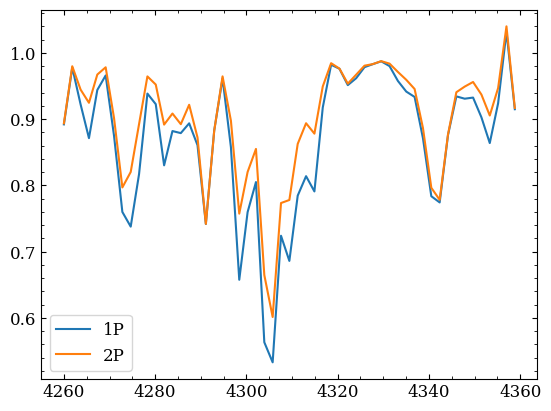

In [ ]:
p1 = pd.read_csv('/data/misfit/benlowe/1p2p_gcs/1P/rgb_base_teff5300_logg30_cfe-01.csv')
p2 = pd.read_csv('/data/misfit/benlowe/1p2p_gcs/2P/rgb_base_teff5300_logg30_cfe-04.csv')

plt.figure()
plt.plot(p1['wave'], p1['flux'], label='1P')
plt.plot(p2['wave'], p2['flux'], label='2P')
plt.legend()

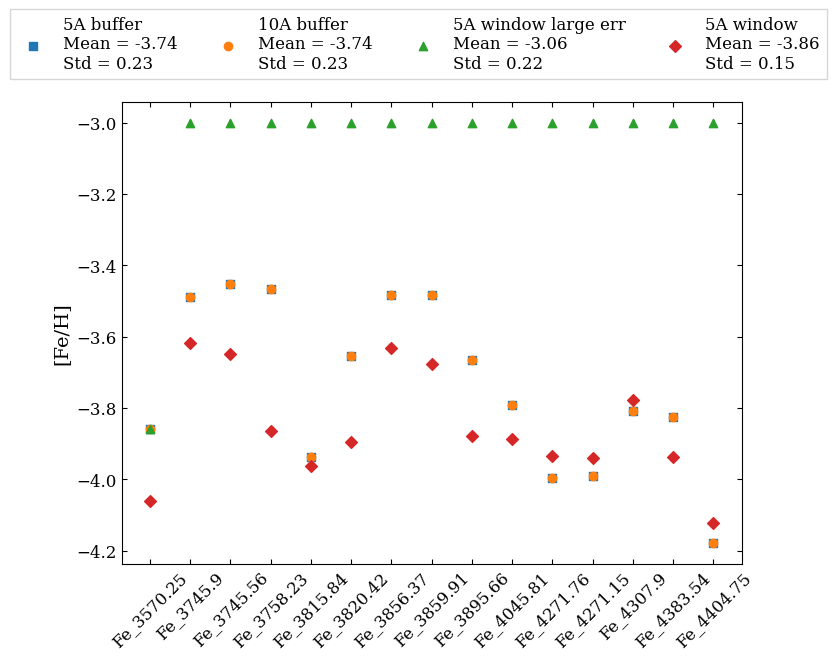

In [43]:
# Loading in the data
wl_buffer_5A = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/stars_v2/test_wider_wbuffer_5A/ra_1633-2814_s284/Fe/iter_1/Fe_results.csv')
wl_buffer_10A = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/stars_v2/test_wider_wbuffer_10A/ra_1633-2814_s284/Fe/iter_1/Fe_results.csv')
wl_widerwindow_5A_large_err = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/stars_v2/test_wider_wind_large_err/ra_1633-2814_s284/Fe/iter_1/Fe_results.csv')
wl_widerwindow_5A = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/stars_v2/test_wider_wind/ra_1633-2814_s284/Fe/iter_1/Fe_results.csv')

# Calculating means and standard deviations
wl_buffer_5A_mean = wl_buffer_5A['abund_xh'].mean()
wl_buffer_5A_std = wl_buffer_5A['abund_xh'].std()
wl_buffer_10A_mean = wl_buffer_10A['abund_xh'].mean()
wl_buffer_10A_std = wl_buffer_10A['abund_xh'].std()
wl_widerwindow_5A_large_err_mean = wl_widerwindow_5A_large_err['abund_xh'].mean()
wl_widerwindow_5A_large_err_std = wl_widerwindow_5A_large_err['abund_xh'].std()
wl_widerwindow_5A_mean = wl_widerwindow_5A['abund_xh'].mean()
wl_widerwindow_5A_std = wl_widerwindow_5A['abund_xh'].std()

# Plotting the data
plt.figure(figsize=[8,6])
plt.scatter(wl_buffer_5A['line'], wl_buffer_5A['abund_xh'], marker='s', label=f'5A buffer\nMean = {wl_buffer_5A_mean:.2f}\nStd = {wl_buffer_5A_std:.2f}')
plt.scatter(wl_buffer_10A['line'], wl_buffer_10A['abund_xh'], label=f'10A buffer\nMean = {wl_buffer_10A_mean:.2f}\nStd = {wl_buffer_10A_std:.2f}')
plt.scatter(wl_widerwindow_5A_large_err['line'], wl_widerwindow_5A_large_err['abund_xh'], marker='^', label=f'5A window large err\nMean = {wl_widerwindow_5A_large_err_mean:.2f}\nStd = {wl_widerwindow_5A_large_err_std:.2f}')
plt.scatter(wl_widerwindow_5A['line'], wl_widerwindow_5A['abund_xh'], marker='D', label=f'5A window\nMean = {wl_widerwindow_5A_mean:.2f}\nStd = {wl_widerwindow_5A_std:.2f}')
plt.legend(fancybox=False, loc=[-0.18,1.05], ncols=4)
plt.ylabel('[Fe/H]')
plt.xticks(rotation=45)  # Options: 'in', 'out', or 'inout'
plt.gca().minorticks_off()

## Comparing abundance results with literature

Loading in both our data and those from Yong+2013, Jacobson+2015, Marino+2019, Yong+2021

In [23]:
# Loading in Yong+2013 data
yong13_data = (Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/yong2013_data.fit')).to_pandas()


# Loading in Jacobson+2015 data
jacob_params = (Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/jacobson2015_params.fit')).to_pandas()
jacob_abunds = (Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/jacobson2015_abunds.fit')).to_pandas()
jacob_data = pd.merge(jacob_params[['ID', '__Fe_H_L']], jacob_abunds[['ID', 'Sp', '__X_Fe_']], on='ID', how='inner')

# Loading in Marino+2019 data
marino_params = (Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/marino2019_params.fit')).to_pandas()
marino_abunds1 = (Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/marino2019_abunds.fit', hdu=1)).to_pandas()
marino_abunds2 = (Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/marino2019_abunds.fit', hdu=2)).to_pandas()
marino_abunds3 = (Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/marino2019_abunds.fit', hdu=3)).to_pandas()
marino_abunds4 = (Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/marino2019_abunds.fit', hdu=4)).to_pandas()
marino_abunds = reduce(lambda left, right: pd.merge(left, right, on='Name'), [marino_abunds1, marino_abunds2, marino_abunds3, marino_abunds4])
marino_data = pd.merge(marino_params[['Name', '__Fe_H_LTE']], marino_abunds, on='Name', how='inner')
# marin_data = pd.merge(marin_params[['ID', '__Fe_H_L']], marin_abunds[['ID', 'Sp', '__X_Fe_']], on='ID', how='inner')

# Loading in Yong+2021 data
yong_params = (Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/yong2021_params.fit')).to_pandas()
yong_abunds1 = (Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/yong2021_abunds.fit')).to_pandas()
yong_abunds2 = (Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/yong2021_abunds2.fit')).to_pandas()
yong_data1 = pd.merge(yong_params[['SMSS', '__Fe_H_']], yong_abunds1[['SMSS', 'Species', '__X_Fe_']], on='SMSS', how='inner')
yong_data2 = pd.merge(yong_params[['SMSS', '__Fe_H_']], yong_abunds2[['SMSS', 'Species', '__X_Fe_']], on='SMSS', how='inner')
yong_data = pd.concat([yong_data1, yong_data2], ignore_index=True)

lit_dicts = {'Yong+2013': yong13_data, 'Jacobson+2015': jacob_data, 'Marino+2019': marino_data, 'Yong+2021': yong_data}

def combine_lit_abunds(abund_dicts, element):
    
    # Extracting abundances for each dataset, then combining into one dataframe
    fulldata = []
    for lit in lit_dicts:
        data = lit_dicts[lit]
        # display(data)
        
        # For Yong+2013, the elements are located along the columns. Entries are e.g. 'Ca' or 'Na'
        if lit == 'Yong+2013':
            
            # If e.g. element = 'AlI', then fix to make it 'Al'
            yong13_fixname_el = ['AlI', 'BaI', 'CI', 'CaI', 'CoI', 'CrI', 'MgI', 'MnI', 'NI', 'NaI', 'NiI', 
                                 'ScI', 'SiI', 'SrI']
            yong13_fixname_el2 = ['AlII', 'BaII', 'CII', 'CaII', 'CoII', 'CrII', 'MgII', 'MnII', 'NII', 'NaII', 'NiII', 
                                 'ScII', 'SiII', 'SrII']
            
            if element in yong13_fixname_el:
                lit_el_yong13 = element.split('I')[0]
            elif element in yong13_fixname_el2:
                lit_el_yong13 = element.split('II')[0]
            else:
                continue
            
            
            # Extracting the data
            lit_el_yong13_data = data[["Name", "Fe_H", lit_el_yong13]]
            
            # Renaming columns for consistency
            lit_el_yong13_data = lit_el_yong13_data.rename(columns={"Name": "star_id", "Fe_H": "feh", lit_el_yong13: "abund"})
            fulldata.append(lit_el_yong13_data)
         
         
        # For Jacobson+2015, the elements are located in column called 'Sp'. Entries are e.g. b'C   ' or b'Na  '.
        # There's a set amount of spaces after element name, which is filled up if the species name is longer. 
        if lit == 'Jacobson+2015':
            
            # If e.g. element = 'AlI', then fix to make it 'Al'
            jacob_fixname_el = ['AlI', 'BaI', 'CI', 'CaI', 'CoI', 'EuI', 'MgI', 'MnI', 'NaI', 'NiI', 'ScI', 'SiI', 'SrI', 
                                'YI', 'ZnI', 'ZrI']
            jacob_fixname_el2 = ['AlII', 'BaII', 'CII', 'CaII', 'CoII', 'EuII', 'MgII', 'MnII', 'NaII', 'NiII', 'ScII', 'SiII', 'SrII', 
                                'YII', 'ZnII', 'ZrII']
            if element in jacob_fixname_el:
                element_jacob15 = element.split('I')[0]
            if element in jacob_fixname_el2:
                element_jacob15 = element.split('II')[0]
            else:
                element_jacob15 = element
            
            # Extracting the data
            if len(element_jacob15) == 1:
                lit_el_jacob15 = '{}   '.format(element_jacob15).encode('utf-8')
                lit_el_jacob15_data = data[data['Sp'] == lit_el_jacob15][['ID', '__Fe_H_L', '__X_Fe_']]
                
            if len(element_jacob15) == 2:
                lit_el_jacob15 = '{}  '.format(element_jacob15).encode('utf-8')
                lit_el_jacob15_data = data[data['Sp'] == lit_el_jacob15][['ID', '__Fe_H_L', '__X_Fe_']]
                
            if len(element_jacob15) == 3:
                lit_el_jacob15 = '{} '.format(element_jacob15).encode('utf-8')
                lit_el_jacob15_data = data[data['Sp'] == lit_el_jacob15][['ID', '__Fe_H_L', '__X_Fe_']]
                
            if len(element_jacob15) == 4:
                lit_el_jacob15 = '{}'.format(element_jacob15).encode('utf-8')
                lit_el_jacob15_data = data[data['Sp'] == lit_el_jacob15][['ID', '__Fe_H_L', '__X_Fe_']]
                
            # Renaming columns for consistency
            lit_el_jacob15_data = lit_el_jacob15_data.rename(columns={"ID": "star_id", "__Fe_H_L": "feh", "__X_Fe_": "abund"})
            fulldata.append(lit_el_jacob15_data)
            
            
        # For Marino+2019, the elements are located along the columns. Entries are e.g. '__Ba_Fe_' or '__Co_Fe_'.
        # There's always two underscores at the beginning, one between the element and 'Fe', then one underscore at the end. 
        if lit == 'Marino+2019':

            # If e.g. element = 'AlI', then fix to make it 'Al'
            marino_fixname_el = ['AlI', 'BaI', 'CI', 'CaI', 'CoI', 'EuI', 'MgI', 'MnI', 'NI', 'NiI', 'ScI', 'SiI', 'SrI', 
                                 'ZnI']
            marino_fixname_el2 = ['AlII', 'BaII', 'CII', 'CaII', 'CoII', 'EuII', 'MgII', 'MnII', 'NII', 'NiII', 'ScII', 'SiII', 'SrII', 
                                 'ZnII']
            if element in marino_fixname_el:
                element_marino19 = element.split('I')[0]
            elif element in marino_fixname_el2:
                element_marino19 = element.split('II')[0]
            else:
                element_marino19 = element
                
            # For Na, use the LTE abundance
            if element_marino19 == 'NaI':
                lit_el_marino19 = '__Na_Fe_LTE'
            # Extracting the data
            elif element_marino19 == 'FeII':
                lit_el_marino19 = '__FeII_H_'
            else:
                lit_el_marino19 = '__{}_Fe_'.format(element_marino19)
            lit_el_marino19_data = data[['Name', '__Fe_H_LTE', lit_el_marino19]]
                
            # Renaming columns for consistency
            lit_el_marino19_data = lit_el_marino19_data.rename(columns={"Name": "star_id", "__Fe_H_LTE": "feh", lit_el_marino19: "abund"})
            fulldata.append(lit_el_marino19_data)
            
            
        # For Yong+2021, the elements are located in column called 'Species'. Entries are e.g. b'CaI ' or b'FeII'.
        # There is a total of 4 spaces after the element name, which is filled up if the species name is longer. 
        if lit == 'Yong+2021':
            
            # Extracting the data
            if len(element) == 1:
                lit_el_yong21 = '{}   '.format(element).encode('utf-8')
                lit_el_yong21_data = data[data['Species'] == lit_el_yong21][['SMSS', '__Fe_H_', '__X_Fe_']]
                
            if len(element) == 2:
                lit_el_yong21 = '{}  '.format(element).encode('utf-8')
                lit_el_yong21_data = data[data['Species'] == lit_el_yong21][['SMSS', '__Fe_H_', '__X_Fe_']]
                
            if len(element) == 3:
                lit_el_yong21 = '{} '.format(element).encode('utf-8')
                lit_el_yong21_data = data[data['Species'] == lit_el_yong21][['SMSS', '__Fe_H_', '__X_Fe_']]
                
            if len(element) == 4:
                lit_el_yong21 = '{}'.format(element).encode('utf-8')
                lit_el_yong21_data = data[data['Species'] == lit_el_yong21][['SMSS', '__Fe_H_', '__X_Fe_']]
                
            # Renaming columns for consistency
            lit_el_yong21_data = lit_el_yong21_data.rename(columns={"SMSS": "star_id", "__Fe_H_": "feh", "__X_Fe_": "abund"})
            fulldata.append(lit_el_yong21_data)    
        
    # Combining all the dataframes into one
    fulldata = pd.concat(fulldata, ignore_index=True)
            
    return fulldata

# Getting the abundances for each element
caI_lit_abund = combine_lit_abunds(lit_dicts, 'CaI')
mgI_lit_abund = combine_lit_abunds(lit_dicts, 'MgI')
siI_lit_abund = combine_lit_abunds(lit_dicts, 'SiI')
baII_lit_abund = combine_lit_abunds(lit_dicts, 'BaII')
baII_lit_abund['abund_xh'] = baII_lit_abund['abund'] + baII_lit_abund['feh']
alI_lit_abund = combine_lit_abunds(lit_dicts, 'AlI')
mnI_lit_abund = combine_lit_abunds(lit_dicts, 'MnI')
crI_lit_abund = combine_lit_abunds(lit_dicts, 'CrI')
tiII_lit_abund = combine_lit_abunds(lit_dicts, 'TiII')
scII_lit_abund = combine_lit_abunds(lit_dicts, 'ScII')
coI_lit_abund = combine_lit_abunds(lit_dicts, 'CoI')
niI_lit_abund = combine_lit_abunds(lit_dicts, 'NiI')
srII_lit_abund = combine_lit_abunds(lit_dicts, 'SrII')
feII_lit_abund = combine_lit_abunds(lit_dicts, 'FeII')
naI_lit_abund = combine_lit_abunds(lit_dicts, 'NaI')
euII_lit_abund = combine_lit_abunds(lit_dicts, 'Eu')
cI_lit_abund = combine_lit_abunds(lit_dicts, 'CI')
nI_lit_abund = combine_lit_abunds(lit_dicts, 'NI')


/tmp/ipykernel_3590112/1304542849.py:158: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  fulldata = pd.concat(fulldata, ignore_index=True)
/tmp/ipykernel_3590112/1304542849.py:158: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  fulldata = pd.concat(fulldata, ignore_index=True)
/tmp/ipykernel_3590112/1304542849.py:158: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when deter

,star_id,feh,abund,abund_xh
0,b'CS 22957-022',-2.92,-1.09,1.83
1,b'CS 29503-010',-1.00,1.51,2.51
2,b'CS 31085-024',-2.80,-0.57,2.23
3,b'BS 17570-063',-2.95,-0.26,2.69
4,b'HE 0024-2523',-2.82,1.88,4.70
...,...,...,...,...
496,b'J224145.62-064643.0',-3.19,0.47,3.66
497,b'J230525.31-213807.0',-3.35,-1.20,2.15
498,b'J230702.22-693718.5',-2.89,-0.68,2.21
499,b'J232121.57-160505.4',-3.03,-0.92,2.11


In [10]:
print("Yong+2013 species:")
print(np.unique(np.array(yong13_data.keys()[5:-2])))

print("\nJacobson+2015 species:")
print(np.unique(jacob_data['Sp'].to_numpy()))

print("\nMarino+2019 species:")
print(np.unique(np.array(marino_data.keys()))[1:25])

print("\nYong+2021 species:")
print(np.unique(yong_data['Species'].to_numpy()))

# jacob_data[jacob_data['Sp'] == b'Ca  ']

Yong+2013 species:
['Al' 'Ba' 'C' 'C-rich' 'Ca' 'Co' 'Cr' 'FeII' 'Mg' 'Mn' 'N' 'Na' 'Ni' 'Sc'
 'Si' 'Sr' 'TiI' 'TiII' 'f_Ba' 'f_Sr' 'l_Ba' 'l_C' 'l_N' 'l_Sr']

Jacobson+2015 species:
[b'Al  ' b'Ba  ' b'C   ' b'Ca  ' b'Co  ' b'CrI ' b'CrII' b'Eu  ' b'FeI '
 b'FeII' b'Mg  ' b'Mn  ' b'Na  ' b'Ni  ' b'Sc  ' b'Si  ' b'Sr  ' b'TiI '
 b'TiII' b'Y   ' b'Zn  ' b'Zr  ']

Marino+2019 species:
['__Al_Fe_' '__Ba_Fe_' '__C_Fe_' '__C_Fe_evol' '__Ca_Fe_' '__Co_Fe_'
 '__CrII_Fe_' '__CrI_Fe_' '__Eu_Fe_' '__FeII_H_' '__FeI_H_' '__Fe_H_LTE'
 '__Mg_Fe_' '__Mn_Fe_' '__N_Fe_' '__Na_Fe_LTE' '__Na_Fe_nLTE' '__Ni_Fe_'
 '__Sc_Fe_' '__Si_Fe_' '__Sr_Fe_' '__TiII_Fe_' '__TiI_Fe_' '__Zn_Fe_']

Yong+2021 species:
[b'AlI ' b'BaII' b'CaI ' b'CoI ' b'CrI ' b'EuII' b'FeI ' b'FeII' b'MgI '
 b'MnI ' b'NaI ' b'NiI ' b'ScII' b'SiI ' b'SrII' b'TiI ' b'TiII' b'YII '
 b'ZnI ' b'ZrII']


Loading in the observed dataset (abundances, upper-limits and orbital parameters)

In [24]:
def abunds(path, stars):
    """Retrieves the stellar abundances measured for each star, then combines into one dataframe.

    Parameters
    ----------
    path : str
        Path to the directory containing the stellar abundances for each star.
    stars : list
        List of star IDs. 

    Returns
    -------
    all_abunds_df : pandas.DataFrame
        Dataframe containing all of the stellar abundances for the set of stars.
    """

    # Getting abundances for each star
    all_abunds = []
    for star in stars:
        
        # Getting directory to given star
        star_path = path + star + '/'
        
        # Loading in abundances
        # star_Mg = pd.read_csv(star_path + 'Mg_I_abund.csv')[['star_id', 'Mg_I_xfe_it2', 'Mg_I_xh_it2', 'Mg_I_xfe_tefferr', 'Mg_I_xfe_loggerr']]
        # star_Ca = pd.read_csv(star_path + 'Ca_II_abund.csv')[['Ca_II_xfe_it2', 'Ca_II_xh_it2', 'Ca_II_xfe_tefferr', 'Ca_II_xfe_loggerr']]
        # star_Si = pd.read_csv(star_path + 'Si_I_abund.csv')[['Si_I_xfe_it2', 'Si_I_xh_it2', 'Si_I_xfe_tefferr', 'Si_I_xfe_loggerr']]
        # star_Ba = pd.read_csv(star_path + 'Ba_II_abund.csv')[['Ba_II_xfe_it2', 'Ba_II_xh_it2', 'Ba_II_xfe_tefferr', 'Ba_II_xfe_loggerr']]
        # star_Al = pd.read_csv(star_path + 'Al_I_abund.csv')[['Al_I_xfe_it2', 'Al_I_xh_it2', 'Al_I_xfe_tefferr', 'Al_I_xfe_loggerr']]
        # star_Mn = pd.read_csv(star_path + 'Mn_I_abund.csv')[['Mn_I_xfe_it2', 'Mn_I_xh_it2', 'Mn_I_xfe_tefferr', 'Mn_I_xfe_loggerr']]
        # star_Cr = pd.read_csv(star_path + 'Cr_I_abund.csv')[['Cr_I_xfe_it2', 'Cr_I_xh_it2', 'Cr_I_xfe_tefferr', 'Cr_I_xfe_loggerr']]
        # star_Ti = pd.read_csv(star_path + 'Ti_II_abund.csv')[['Ti_II_xfe_it2', 'Ti_II_xh_it2', 'Ti_II_xfe_tefferr', 'Ti_II_xfe_loggerr']]
        # star_Sc = pd.read_csv(star_path + 'Sc_II_abund.csv')[['Sc_II_xfe_it2', 'Sc_II_xh_it2', 'Sc_II_xfe_tefferr', 'Sc_II_xfe_loggerr']]
        # star_Co = pd.read_csv(star_path + 'Co_I_abund.csv')[['Co_I_xfe_it2', 'Co_I_xh_it2', 'Co_I_xfe_tefferr', 'Co_I_xfe_loggerr']]
        # star_Ni = pd.read_csv(star_path + 'Ni_I_abund.csv')[['Ni_I_xfe_it2', 'Ni_I_xh_it2', 'Ni_I_xfe_tefferr', 'Ni_I_xfe_loggerr']]
        # star_Sr = pd.read_csv(star_path + 'Sr_II_abund.csv')[['Sr_II_xfe_it2', 'Sr_II_xh_it2', 'Sr_II_xfe_tefferr', 'Sr_II_xfe_loggerr']]
        # star_Na = pd.read_csv(star_path + 'Na_I_abund.csv')[['Na_I_xfe_it2', 'Na_I_xh_it2', 'Na_I_xfe_tefferr', 'Na_I_xfe_loggerr']]
        # star_Eu = pd.read_csv(star_path + 'Eu_II_abund.csv')[['Eu_II_xfe_it2', 'Eu_II_xh_it2', 'Eu_II_xfe_tefferr', 'Eu_II_xfe_loggerr']]
        # star_N = pd.read_csv(star_path + 'N_I_abund.csv')[['N_I_xfe_it2', 'N_I_xh_it2', 'N_I_xfe_tefferr', 'N_I_xfe_loggerr']]
        # star_C = pd.read_csv(star_path + 'C_I_abund.csv')[['C_I_xfe_it1', 'C_I_xfe_it2', 'C_I_xh_it1', 'C_I_xh_it2', 'C_I_xfe_teff_perturb', 'C_I_xfe_tefferr', 'C_I_xfe_loggerr']]

        star_Mg = pd.read_csv(star_path + 'Mg_I_abund.csv')[['star_id', 'Mg_I_xfe_it1', 'Mg_I_xh_it1', 'Mg_I_xfe_comberr', 'Mg_I_xh_comberr', 'Mg_I_xfe_tefferr', 'Mg_I_xfe_loggerr', 'Mg_I_xfe_vmicerr', 'Mg_I_xh_tefferr', 'Mg_I_xh_loggerr', 'Mg_I_xh_vmicerr']]
        star_Ca = pd.read_csv(star_path + 'Ca_II_abund.csv')[['Ca_II_xfe_it1', 'Ca_II_xh_it1', 'Ca_II_xfe_comberr', 'Ca_II_xh_comberr', 'Ca_II_xfe_tefferr', 'Ca_II_xfe_loggerr', 'Ca_II_xfe_vmicerr', 'Ca_II_xh_tefferr', 'Ca_II_xh_loggerr', 'Ca_II_xh_vmicerr']]
        star_Si = pd.read_csv(star_path + 'Si_I_abund.csv')[['Si_I_xfe_it1', 'Si_I_xh_it1', 'Si_I_xfe_comberr', 'Si_I_xh_comberr', 'Si_I_xfe_tefferr', 'Si_I_xfe_loggerr', 'Si_I_xfe_vmicerr', 'Si_I_xh_tefferr', 'Si_I_xh_loggerr', 'Si_I_xh_vmicerr']]
        star_Ba = pd.read_csv(star_path + 'Ba_II_abund.csv')[['Ba_II_xfe_it1', 'Ba_II_xh_it1', 'Ba_II_xfe_comberr', 'Ba_II_xh_comberr', 'Ba_II_xfe_tefferr', 'Ba_II_xfe_loggerr', 'Ba_II_xfe_vmicerr', 'Ba_II_xh_tefferr', 'Ba_II_xh_loggerr', 'Ba_II_xh_vmicerr']]
        star_Al = pd.read_csv(star_path + 'Al_I_abund.csv')[['Al_I_xfe_it1', 'Al_I_xh_it1', 'Al_I_xfe_comberr', 'Al_I_xh_comberr', 'Al_I_xfe_tefferr', 'Al_I_xfe_loggerr', 'Al_I_xfe_vmicerr', 'Al_I_xh_tefferr', 'Al_I_xh_loggerr', 'Al_I_xh_vmicerr']]
        star_Mn = pd.read_csv(star_path + 'Mn_I_abund.csv')[['Mn_I_xfe_it1', 'Mn_I_xh_it1', 'Mn_I_xfe_comberr', 'Mn_I_xh_comberr', 'Mn_I_xfe_tefferr', 'Mn_I_xfe_loggerr', 'Mn_I_xfe_vmicerr', 'Mn_I_xh_tefferr', 'Mn_I_xh_loggerr', 'Mn_I_xh_vmicerr']]
        star_Cr = pd.read_csv(star_path + 'Cr_I_abund.csv')[['Cr_I_xfe_it1', 'Cr_I_xh_it1', 'Cr_I_xfe_comberr', 'Cr_I_xh_comberr', 'Cr_I_xfe_tefferr', 'Cr_I_xfe_loggerr', 'Cr_I_xfe_vmicerr', 'Cr_I_xh_tefferr', 'Cr_I_xh_loggerr', 'Cr_I_xh_vmicerr']]
        star_Ti = pd.read_csv(star_path + 'Ti_II_abund.csv')[['Ti_II_xfe_it1', 'Ti_II_xh_it1', 'Ti_II_xfe_comberr', 'Ti_II_xh_comberr', 'Ti_II_xfe_tefferr', 'Ti_II_xfe_loggerr', 'Ti_II_xfe_vmicerr', 'Ti_II_xh_tefferr', 'Ti_II_xh_loggerr', 'Ti_II_xh_vmicerr']]
        star_Sc = pd.read_csv(star_path + 'Sc_II_abund.csv')[['Sc_II_xfe_it1', 'Sc_II_xh_it1', 'Sc_II_xfe_comberr', 'Sc_II_xh_comberr', 'Sc_II_xfe_tefferr', 'Sc_II_xfe_loggerr', 'Sc_II_xfe_vmicerr', 'Sc_II_xh_tefferr', 'Sc_II_xh_loggerr', 'Sc_II_xh_vmicerr']]
        star_Co = pd.read_csv(star_path + 'Co_I_abund.csv')[['Co_I_xfe_it1', 'Co_I_xh_it1', 'Co_I_xfe_comberr', 'Co_I_xh_comberr', 'Co_I_xfe_tefferr', 'Co_I_xfe_loggerr', 'Co_I_xfe_vmicerr', 'Co_I_xh_tefferr', 'Co_I_xh_loggerr', 'Co_I_xh_vmicerr']]
        star_Ni = pd.read_csv(star_path + 'Ni_I_abund.csv')[['Ni_I_xfe_it1', 'Ni_I_xh_it1', 'Ni_I_xfe_comberr', 'Ni_I_xh_comberr', 'Ni_I_xfe_tefferr', 'Ni_I_xfe_loggerr', 'Ni_I_xfe_vmicerr', 'Ni_I_xh_tefferr', 'Ni_I_xh_loggerr', 'Ni_I_xh_vmicerr']]
        star_Sr = pd.read_csv(star_path + 'Sr_II_abund.csv')[['Sr_II_xfe_it1', 'Sr_II_xh_it1', 'Sr_II_xfe_comberr', 'Sr_II_xh_comberr', 'Sr_II_xfe_tefferr', 'Sr_II_xfe_loggerr', 'Sr_II_xfe_vmicerr', 'Sr_II_xh_tefferr', 'Sr_II_xh_loggerr', 'Sr_II_xh_vmicerr']]
        star_Na = pd.read_csv(star_path + 'Na_I_abund.csv')[['Na_I_xfe_it1', 'Na_I_xh_it1', 'Na_I_xfe_comberr', 'Na_I_xh_comberr', 'Na_I_xfe_tefferr', 'Na_I_xfe_loggerr', 'Na_I_xfe_vmicerr', 'Na_I_xh_tefferr', 'Na_I_xh_loggerr', 'Na_I_xh_vmicerr']]
        star_Eu = pd.read_csv(star_path + 'Eu_II_abund.csv')[['Eu_II_xfe_it1', 'Eu_II_xh_it1', 'Eu_II_xfe_comberr', 'Eu_II_xh_comberr', 'Eu_II_xfe_tefferr', 'Eu_II_xfe_loggerr', 'Eu_II_xfe_vmicerr', 'Eu_II_xh_tefferr', 'Eu_II_xh_loggerr', 'Eu_II_xh_vmicerr']]
        star_N = pd.read_csv(star_path + 'N_I_abund.csv')[['N_I_xfe_it1', 'N_I_xh_it1', 'N_I_xfe_comberr', 'N_I_xh_comberr', 'N_I_xfe_tefferr', 'N_I_xfe_loggerr', 'N_I_xfe_vmicerr', 'N_I_xh_tefferr', 'N_I_xh_loggerr', 'N_I_xh_vmicerr']]
        star_C = pd.read_csv(star_path + 'C_I_abund.csv')[['C_I_xfe_it1', 'C_I_xh_it1', 'C_I_xfe_comberr', 'C_I_xh_comberr', 'C_I_xfe_teff_perturb', 'C_I_xfe_tefferr', 'C_I_xfe_loggerr', 'C_I_xfe_vmicerr', 'C_I_xh_tefferr', 'C_I_xh_loggerr', 'C_I_xh_vmicerr']]


        # Combining into one dataframe
        star_abunds = pd.concat([star_Mg, star_Ca, star_Ba, star_Al, star_Mn, star_Cr, star_Co, star_Ni, star_Na, star_Eu,
                                 star_Si, star_Ti, star_Sc, star_Sr, star_N, star_C], axis=1)
        all_abunds.append(star_abunds)

    
    # Storing all stellar abundnaces into one dataframe
    all_abunds_df = pd.concat(all_abunds, axis=0)
    
    return all_abunds_df

# Loading in our data
# stars = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final/stellar_params.csv')
stars = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/stellar_params.csv')
# abunds_path = "/data/misfit/benlowe/xshooter/korg_data/abunds/final/"
abunds_path = "/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/"
stars_abunds = abunds(path=abunds_path, stars=stars['star_id'].to_numpy())
stars_data = pd.merge(stars[['star_id', 'Fe_it1', 'Fe_tefferr', 'teff', 'logg']], stars_abunds, on='star_id', how='inner')

# Merging with the snr data
stars_info = pd.read_csv('/data/misfit/benlowe/xshooter/reduced_data/comb_spec_2/star_info.csv')
stars_data = pd.merge(stars_info[['star_id', 'snr_uvb', 'snr_vis', 'ra', 'dec', 'rv_avg', 'rv_avg_err', 'barycor', 'heliocor',
       'rv_uvb', 'rv_uvb_err', 'rv_vis', 'rv_vis_err']], stars_data, on='star_id', how='inner')

# stars_data[['star_id', 'Sc_II_xfe_it2']]
# stars_data.to_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/stellar_abunds.csv', index=False)

In [25]:
def upper_limits(upperlim_path, abunds_path, stars_data, elements):
    """Retrieves the upper-limits for each star, then combines into one dataframe. For elements with multiple lines, then:
    - If all lines have upper-limits, then adopt the lowest upper-limit
    - If lines have upper-limits, and one has a detection, then adopt the detection
    - If lines have some upper-limits, and some has multiple detections, then use weighted average of the detections.
    
    For elements with only one line, then the upper-limit is the upper-limit for that line.
    
    For elements with no upper-limits, then the upper-limit is set to np.Nan. 

    Parameters
    ----------
    upperlim_path : str
        Path to the directory containing the upper-limits for each star.
    abunds_path : str
        Path to the directory containing the stellar abundances for each star.
    stars : list
        List of star IDs.
    elements : list
        List of elements measured in each star.

    Returns
    -------
    all_upperlimits_df : pandas.DataFrame
        Dataframe containing all of the upper-limits for the set of stars, with columns:
        - star_id: Star ID
        - teff: Effective temperature of the star
        - logg: Surface gravity of the star
        - vmic: Microturbulence of the star
        - vsini: Projected rotational velocity of the star
        - feh: Metallicity of the star
        - el: Element name
        - detection: Detection status ('Y' for detection, 'N' for non-detection)
        - upper_limit_xfe: Upper-limit for the element's abundance in [X/Fe]
        - upper_limit_xh: Upper-limit for the element's abundance in [X/H]
        - bestfit_abund_xfe: Best-fit abundance in [X/Fe]
        - bestfit_abund_xh: Best-fit abundance in [X/H]
        - bestfit_abund_tefferr_xfe: Best-fit abundance error in [X/Fe] due to effective temperature
        - bestfit_abund_tefferr_xh: Best-fit abundance error in [X/H] due to effective temperature
        - bestfit_abund_loggerr_xfe: Best-fit abundance error in [X/Fe] due to surface gravity
        - bestfit_abund_loggerr_xh: Best-fit abundance error in [X/H] due to surface gravity
    """
    
    # Getting the upper-limits for each star
    all_upperlimits = []
    stars = stars_data['star_id'].to_numpy() 
    
    for star in stars:
        
        print("Running " + star)
        # Getting directory to given star
        star_path = upperlim_path + star + '/'
        star_files = [star_path + f for f in os.listdir(star_path) if f.endswith('abunds.csv')] # List of .csv files containing upper-limits
        
        # Looping through each file and loading in the data
        star_upperlimits = []
        els = []
        for file in star_files:
            # Loading in the data
            star_upperlimit = pd.read_csv(file)
            # display(star_upperlimit)
            
            el = star_upperlimit['el'].values[0]  # Element name
            els.append(el)  # Storing the element name
            
            # Getting the element's best-fit abundance errors and stellar parameters
            el_abunds_path = f"{abunds_path}{star}/{el}_abund.csv"
            el_abunds_df = pd.read_csv(el_abunds_path)
            bestfit_abund_comberr_xfe = el_abunds_df[f"{el}_xfe_comberr"].to_numpy()[0]
            bestfit_abund_comberr_xh = el_abunds_df[f"{el}_xh_comberr"].to_numpy()[0]
            bestfit_abund_vmicerr_xfe = el_abunds_df[f"{el}_xfe_vmicerr"].to_numpy()[0]
            bestfit_abund_vmicerr_xh = el_abunds_df[f"{el}_xh_vmicerr"].to_numpy()[0]
            bestfit_abund_tefferr_xfe = el_abunds_df[f"{el}_xfe_tefferr"].to_numpy()[0]
            bestfit_abund_tefferr_xh = el_abunds_df[f"{el}_xh_tefferr"].to_numpy()[0]
            bestfit_abund_loggerr_xfe = el_abunds_df[f"{el}_xfe_loggerr"].to_numpy()[0]
            bestfit_abund_loggerr_xh = el_abunds_df[f"{el}_xh_loggerr"].to_numpy()[0]
            feh = el_abunds_df['mh'].to_numpy()[0] 
            feh_err = stars_data[stars_data['star_id'] == star]['Fe_comberr'].to_numpy()[0]
            logg = el_abunds_df['logg'].to_numpy()[0]
            teff = el_abunds_df['teff'].to_numpy()[0]
            vmic = el_abunds_df['vmic'].to_numpy()[0]
            vsini = el_abunds_df['vsini'].to_numpy()[0]
            
            # If multiple lines, then:
            # - If all line have upper-limits, then adopt the lowest upper-limit
            # - If lines have upper-limits, and one has a detection, then adopt the detection
            # - If lines have some upper-limits, and some has multiple detections, 
            #   then use weighted average of the detections
            if len(star_upperlimit) != 1:
                detection = star_upperlimit['detection'].to_numpy()
                min_abunds_xfe = star_upperlimit['min_abund_xfe']
                min_abunds_xh = star_upperlimit['min_abund_xh']
                bestfit_abunds_xfe = star_upperlimit['bestfit_abund_xfe']
                bestfit_abunds_xh = star_upperlimit['bestfit_abund_xh']
                # bestfit_abunds_xfe = star_upperlimit['bestfit_abund_xfe']
                # bestfit_abunds_xh = star_upperlimit['bestfit_abund_xh']
                
                # For all lines with no detections, then we adopt the lowest upper-limit
                if 'Y' not in detection:
                    lowest_min_abund_xfe = min(min_abunds_xfe)
                    lowest_index = np.where(min_abunds_xfe == lowest_min_abund_xfe)[0][0] # Index of the lowest upper-limit
                    lowest_min_abund_xh = min_abunds_xh[lowest_index]
                    lowest_bestfit_abund_xfe = bestfit_abunds_xfe[lowest_index]
                    lowest_bestfit_abund_xh = bestfit_abunds_xh[lowest_index]
                    
                    # Storing in a dictionary, then appending to the list
                    lowest_dict = {
                        'star_id': star, 
                        'teff': teff,
                        'logg': logg,
                        'vmic': vmic,
                        'vsini': vsini,
                        'feh': feh,
                        'feh_err': feh_err,
                        'el': el, 
                        'detection': 'N',
                        'upper_limit_xfe': lowest_min_abund_xfe, 
                        'upper_limit_xh': lowest_min_abund_xh,
                        'bestfit_abund_xfe': lowest_bestfit_abund_xfe, 
                        'bestfit_abund_xh': lowest_bestfit_abund_xh,
                        'bestfit_abund_comberr_xfe': bestfit_abund_comberr_xfe,
                        'bestfit_abund_comberr_xh': bestfit_abund_comberr_xh,
                        'bestfit_abund_tefferr_xfe': bestfit_abund_tefferr_xfe,
                        'bestfit_abund_tefferr_xh': bestfit_abund_tefferr_xh,
                        'bestfit_abund_loggerr_xfe': bestfit_abund_loggerr_xfe,
                        'bestfit_abund_loggerr_xh': bestfit_abund_loggerr_xh,
                        'bestfit_abund_vmicerr_xfe': bestfit_abund_vmicerr_xfe,
                        'bestfit_abund_vmicerr_xh': bestfit_abund_vmicerr_xh
                    }
                    
                    star_upperlimits.append(lowest_dict)
                    
                # For lines with non-detections, but one detection, then we adopt the detection
                if np.count_nonzero(detection == 'Y') == 1:
                    
                    # For the detection, we get the index and the values
                    detection_index = np.where(detection == 'Y')[0][0] # Index of the detection
                    detection_min_abund_xfe = min_abunds_xfe[detection_index]
                    detection_min_abund_xh = min_abunds_xh[detection_index]
                    detection_bestfit_abund_xfe = bestfit_abunds_xfe[detection_index]
                    detection_bestfit_abund_xh = bestfit_abunds_xh[detection_index]
                    
                    # Loading in the weights
                    weights_path = f"{abunds_path}{star}/{el}/iter_1/{el.split('_')[0]}_results.csv"
                    weights_df = pd.read_csv(weights_path)
                    line_weights = weights_df['weight'].to_numpy()[detection_index] # Getting the weights for the detections
                    line_abunds_xfe = weights_df['abund_xfe'].to_numpy()[detection_index]
                    line_abunds_xh = weights_df['abund_xh'].to_numpy()[detection_index]
                    
                    # Calculating the weighted average
                    weight_avg_bestfit_abund_xfe = np.sum(line_abunds_xfe * line_weights) / np.sum(line_weights)
                    weight_avg_bestfit_abund_xh = np.sum(line_abunds_xh * line_weights) / np.sum(line_weights)
                    weighted_avg_bestfit_err_xfe = np.sqrt(1 / np.sum(line_weights))
                    weighted_avg_bestfit_err_xh = np.sqrt(1 / np.sum(line_weights))

                    
                    # For the non-detections, we get the minimum upper-limit
                    nondetection_index = np.where(detection == 'N')[0] # Index of the detection
                    lowest_min_abund_xfe = min(min_abunds_xfe[nondetection_index])
                    lowest_min_abund_xh = min(min_abunds_xh[nondetection_index])

                    # Storing in a dictionary, then appending to the list
                    detection_dict = {
                        'star_id': star, 
                        'teff': teff,
                        'logg': logg,
                        'vmic': vmic,
                        'vsini': vsini,
                        'feh': feh,
                        'feh_err': feh_err,
                        'el': el, 
                        'detection': 'Y',
                        'upper_limit_xfe': lowest_min_abund_xfe, 
                        'upper_limit_xh': lowest_min_abund_xh,
                        'bestfit_abund_xfe': detection_bestfit_abund_xfe, 
                        'bestfit_abund_xh': detection_bestfit_abund_xh,
                        'bestfit_abund_comberr_xfe': weighted_avg_bestfit_err_xfe,
                        'bestfit_abund_comberr_xh': weighted_avg_bestfit_err_xh,
                        'bestfit_abund_tefferr_xfe': bestfit_abund_tefferr_xfe,
                        'bestfit_abund_tefferr_xh': bestfit_abund_tefferr_xh,
                        'bestfit_abund_loggerr_xfe': bestfit_abund_loggerr_xfe,
                        'bestfit_abund_loggerr_xh': bestfit_abund_loggerr_xh,
                        'bestfit_abund_vmicerr_xfe': bestfit_abund_vmicerr_xfe,
                        'bestfit_abund_vmicerr_xh': bestfit_abund_vmicerr_xh
                    }
                    
                    star_upperlimits.append(detection_dict)
                    
                # For lines with some detections, and some non-detections, then we adopt the weighted average of the detections
                elif np.count_nonzero(detection == 'Y') > 1 and np.count_nonzero(detection == 'N') >= 1:
                    detection_indices = np.where(detection == 'Y')[0] # Index of all detections
                    detection_min_abunds_xfe = min_abunds_xfe[detection_indices]
                    detection_min_abunds_xh = min_abunds_xh[detection_indices]
                    
                    # Loading in the weights
                    weights_path = f"{abunds_path}{star}/{el}/iter_1/{el.split('_')[0]}_results.csv"
                    weights_df = pd.read_csv(weights_path)
                    line_weights = weights_df['weight'].to_numpy()[detection_indices] # Getting the weights for the detections
                    line_abunds_xfe = weights_df['abund_xfe'].to_numpy()[detection_indices]
                    line_abunds_xh = weights_df['abund_xh'].to_numpy()[detection_indices]
                    
                    # Calculating the weighted average
                    weight_avg_bestfit_abund_xfe = np.sum(line_abunds_xfe * line_weights) / np.sum(line_weights)
                    weight_avg_bestfit_abund_xh = np.sum(line_abunds_xh * line_weights) / np.sum(line_weights)
                    weighted_avg_bestfit_err_xfe = np.sqrt(1 / np.sum(line_weights))
                    weighted_avg_bestfit_err_xh = np.sqrt(1 / np.sum(line_weights))
                    
                    # For the non-detections, we get the minimum upper-limit
                    nondetection_index = np.where(detection == 'N')[0] # Index of the detection
                    lowest_min_abund_xfe = min(min_abunds_xfe[nondetection_index])
                    lowest_min_abund_xh = min(min_abunds_xh[nondetection_index])
                    
                    # Storing in a dictionary, then appending to the list
                    weighted_avg_dict = {
                        'star_id': star, 
                        'teff': teff,
                        'logg': logg,
                        'vmic': vmic,
                        'vsini': vsini,
                        'feh': feh,
                        'feh_err': feh_err,
                        'el': el, 
                        'detection': 'Y',
                        'upper_limit_xfe': lowest_min_abund_xfe, 
                        'upper_limit_xh': lowest_min_abund_xh,
                        'bestfit_abund_xfe': weight_avg_bestfit_abund_xfe, 
                        'bestfit_abund_xh': weight_avg_bestfit_abund_xh,
                        'bestfit_abund_comberr_xfe': weighted_avg_bestfit_err_xfe,
                        'bestfit_abund_comberr_xh': weighted_avg_bestfit_err_xh,
                        'bestfit_abund_tefferr_xfe': bestfit_abund_tefferr_xfe,
                        'bestfit_abund_tefferr_xh': bestfit_abund_tefferr_xh,
                        'bestfit_abund_loggerr_xfe': bestfit_abund_loggerr_xfe,
                        'bestfit_abund_loggerr_xh': bestfit_abund_loggerr_xh,
                        'bestfit_abund_vmicerr_xfe': bestfit_abund_vmicerr_xfe,
                        'bestfit_abund_vmicerr_xh': bestfit_abund_vmicerr_xh
                    }
                    
                    star_upperlimits.append(weighted_avg_dict)
                    
                # For lines with detections, no non-detections, then we adopt the weighted average of the detections
                elif np.count_nonzero(detection == 'Y') > 1:
                    detection_indices = np.where(detection == 'Y')[0] # Index of all detections
                    detection_min_abunds_xfe = min_abunds_xfe[detection_indices]
                    detection_min_abunds_xh = min_abunds_xh[detection_indices]
                    lowest_min_abund_xfe = min(detection_min_abunds_xfe)
                    lowest_min_abund_xh = min(detection_min_abunds_xh)

                    # Loading in the weights
                    weights_path = f"{abunds_path}{star}/{el}/iter_1/{el.split('_')[0]}_results.csv"
                    weights_df = pd.read_csv(weights_path)
                    line_weights = weights_df['weight'].to_numpy()[detection_indices] # Getting the weights for the detections
                    line_abunds_xfe = weights_df['abund_xfe'].to_numpy()[detection_indices]
                    line_abunds_xh = weights_df['abund_xh'].to_numpy()[detection_indices]
                    
                    # Calculating the weighted average
                    weight_avg_bestfit_abund_xfe = np.sum(line_abunds_xfe * line_weights) / np.sum(line_weights)
                    weight_avg_bestfit_abund_xh = np.sum(line_abunds_xh * line_weights) / np.sum(line_weights)
                    weighted_avg_bestfit_err_xfe = np.sqrt(1 / np.sum(line_weights))
                    weighted_avg_bestfit_err_xh = np.sqrt(1 / np.sum(line_weights))
                                        
                    # Storing in a dictionary, then appending to the list
                    weighted_avg_dict = {
                        'star_id': star, 
                        'teff': teff,
                        'logg': logg,
                        'vmic': vmic,
                        'vsini': vsini,
                        'feh': feh,
                        'feh_err': feh_err,
                        'el': el, 
                        'detection': 'Y',
                        'upper_limit_xfe': lowest_min_abund_xfe, 
                        'upper_limit_xh': lowest_min_abund_xh,
                        'bestfit_abund_xfe': weight_avg_bestfit_abund_xfe, 
                        'bestfit_abund_xh': weight_avg_bestfit_abund_xh,
                        'bestfit_abund_comberr_xfe': weighted_avg_bestfit_err_xfe,
                        'bestfit_abund_comberr_xh': weighted_avg_bestfit_err_xh,
                        'bestfit_abund_tefferr_xfe': bestfit_abund_tefferr_xfe,
                        'bestfit_abund_tefferr_xh': bestfit_abund_tefferr_xh,
                        'bestfit_abund_loggerr_xfe': bestfit_abund_loggerr_xfe,
                        'bestfit_abund_loggerr_xh': bestfit_abund_loggerr_xh,
                        'bestfit_abund_vmicerr_xfe': bestfit_abund_vmicerr_xfe,
                        'bestfit_abund_vmicerr_xh': bestfit_abund_vmicerr_xh
                    }
                    
                    star_upperlimits.append(weighted_avg_dict)

                    
                
            # For single lines, then we just get the values
            else:
                detection = star_upperlimit['detection'].to_numpy()
                min_abunds_xfe = star_upperlimit['min_abund_xfe']
                min_abunds_xh = star_upperlimit['min_abund_xh']
                bestfit_abunds_xfe = el_abunds_df[f"{el}_xfe_it1"].values[0]
                bestfit_abunds_xh = el_abunds_df[f"{el}_xh_it1"].values[0]

                
                # Storing in a dictionary, then appending to the list
                abunds_dict = {
                    'star_id': star, 
                    'teff': teff,
                    'logg': logg,
                    'vmic': vmic,
                    'vsini': vsini,
                    'feh': feh,
                    'feh_err': feh_err,
                    'el': el, 
                    'detection': detection[0],
                    'upper_limit_xfe': min_abunds_xfe[0], 
                    'upper_limit_xh': min_abunds_xh[0],
                    'bestfit_abund_xfe': bestfit_abunds_xfe, 
                    'bestfit_abund_xh': bestfit_abunds_xh,
                    'bestfit_abund_comberr_xfe': bestfit_abund_comberr_xfe,
                    'bestfit_abund_comberr_xh': bestfit_abund_comberr_xh,
                    'bestfit_abund_tefferr_xfe': bestfit_abund_tefferr_xfe,
                    'bestfit_abund_tefferr_xh': bestfit_abund_tefferr_xh,
                    'bestfit_abund_loggerr_xfe': bestfit_abund_loggerr_xfe,
                    'bestfit_abund_loggerr_xh': bestfit_abund_loggerr_xh,
                    'bestfit_abund_vmicerr_xfe': bestfit_abund_vmicerr_xfe,
                    'bestfit_abund_vmicerr_xh': bestfit_abund_vmicerr_xh
                }
                
                star_upperlimits.append(abunds_dict)
        
        # For elements with no upper-limits, set upper-limits as Nan
        for el in elements:
            if el not in els:
                
                # Getting the element's best-fit abundances
                el_abunds_path = f"{abunds_path}{star}/{el}_abund.csv"
                el_abunds_df = pd.read_csv(el_abunds_path)
                
                bestfit_xfe = el_abunds_df[f"{el}_xfe_it1"].values[0]
                bestfit_xh = el_abunds_df[f"{el}_xh_it1"].values[0]
                bestfit_abund_comberr_xfe = el_abunds_df[f"{el}_xfe_comberr"].to_numpy()[0]
                bestfit_abund_comberr_xh = el_abunds_df[f"{el}_xh_comberr"].to_numpy()[0]
                bestfit_abund_vmicerr_xfe = el_abunds_df[f"{el}_xfe_vmicerr"].to_numpy()[0]
                bestfit_abund_vmicerr_xh = el_abunds_df[f"{el}_xh_vmicerr"].to_numpy()[0]
                bestfit_abund_tefferr_xfe = el_abunds_df[f"{el}_xfe_tefferr"].to_numpy()[0]
                bestfit_abund_tefferr_xh = el_abunds_df[f"{el}_xh_tefferr"].to_numpy()[0]
                bestfit_abund_loggerr_xfe = el_abunds_df[f"{el}_xfe_loggerr"].to_numpy()[0]
                bestfit_abund_loggerr_xh = el_abunds_df[f"{el}_xh_loggerr"].to_numpy()[0]
                feh = el_abunds_df['mh'].to_numpy()[0] 
                feh_err = stars_data[stars_data['star_id'] == star]['Fe_comberr'].to_numpy()[0]
                logg = el_abunds_df['logg'].to_numpy()[0]
                teff = el_abunds_df['teff'].to_numpy()[0]
                vmic = el_abunds_df['vmic'].to_numpy()[0]
                vsini = el_abunds_df['vsini'].to_numpy()[0]
                
                # Storing in a dictionary, then appending to the list
                # Storing in a dictionary, then appending to the list
                abunds_dict = {
                    'star_id': star, 
                    'teff': teff,
                    'logg': logg,
                    'vmic': vmic,
                    'vsini': vsini,
                    'feh': feh,
                    'feh_err': feh_err,
                    'el': el, 
                    'detection': 'Y',
                    'upper_limit_xfe': np.nan, 
                    'upper_limit_xh': np.nan,
                    'bestfit_abund_xfe': bestfit_xfe, 
                    'bestfit_abund_xh': bestfit_xh,
                    'bestfit_abund_comberr_xfe': bestfit_abund_comberr_xfe,
                    'bestfit_abund_comberr_xh': bestfit_abund_comberr_xh,
                    'bestfit_abund_tefferr_xfe': bestfit_abund_tefferr_xfe,
                    'bestfit_abund_tefferr_xh': bestfit_abund_tefferr_xh,
                    'bestfit_abund_loggerr_xfe': bestfit_abund_loggerr_xfe,
                    'bestfit_abund_loggerr_xh': bestfit_abund_loggerr_xh,
                    'bestfit_abund_vmicerr_xfe': bestfit_abund_vmicerr_xfe,
                    'bestfit_abund_vmicerr_xh': bestfit_abund_vmicerr_xh
                }
                
                star_upperlimits.append(abunds_dict)
                
        all_upperlimits.extend(star_upperlimits)
    all_upperlimits_df = pd.DataFrame(all_upperlimits)
    return all_upperlimits_df    

# Retrieving the upper-limits for all elements
all_els = ['Al_I', 'Ba_II', 'C_I', 'Ca_II', 'Co_I', 'Cr_I', 'Eu_II', 'Mg_I', 'Mn_I', 'N_I', 'Na_I', 
           'Ni_I', 'Sc_II', 'Si_I', 'Sr_II', 'Ti_II']
stars_df = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/stellar_params.csv')
stars_upperlimits = upper_limits(upperlim_path='/data/misfit/benlowe/xshooter/korg_data/upper_limits_v4/', 
                                 abunds_path='/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/',
                                 stars_data=stars_df, 
                                 elements=all_els) # ['ra_0103-7050_s163', 'ra_1604-2712_s292']

Running ra_0103-7050_s163
Running ra_1648-0653_s38
Running ra_1604-2712_s24
Running ra_0834-5220_s316
Running ra_1752-4300_s214
Running ra_1624-2150_s278
Running ra_1656-1433_s143
Running ra_1752-4300_s269
Running ra_1658-2454_s22
Running ra_1853-3255_s45
Running ra_1752-4300_s6
Running ra_1709-2130_s102
Running ra_1604-2712_s292
Running ra_1633-2814_s130
Running ra_1659-2154_s114
Running ra_1633-2814_s284


In [5]:
# Getting the orbital parameters for each star
orb_params = pd.read_csv('/data/misfit/benlowe/xshooter/stellar_params/emp_params_FINAL.csv')

# Performing the orbital cuts, identifying stars that are in:
# 1. The prograde disk
# 2. The retrograde disk
# 3. The GSE
# 4. The halo

for i, star_entry in enumerate(stars_upperlimits.iterrows()):
    star_id = star_entry[1]['star_id']
    
    # Getting the orbital parameters for the star
    star_orb = orb_params[orb_params['star_id'] == star_id]
    star_Jp = float(star_orb['Jp'].iloc[0])
    star_Jtot = float(star_orb['Jtot'].iloc[0])
    star_Jz = float(star_orb['Jz'].iloc[0])
    star_Jr = float(star_orb['Jr'].iloc[0])
    star_zmax = float(star_orb['zmax'].iloc[0])
    
    # Defining the orbit based on the orbital parameters
    if star_Jp/star_Jtot >= 0.75 and star_zmax < 3:
        orbit = 'pro_disk'
    elif star_Jp/star_Jtot <= -0.75 and star_zmax < 3:
        orbit = 'ret_disk'
    elif -0.25 < star_Jp/star_Jtot < 0.25 and -0.75 < (star_Jz - star_Jr)/star_Jtot < 0.25:
        orbit = 'gse'
    else:
        orbit = 'halo'
        
    # Appending this to the stars_upperlimits dataframe
    stars_upperlimits.loc[i, 'Jp'] = star_Jp
    stars_upperlimits.loc[i, 'Jtot'] = star_Jtot
    stars_upperlimits.loc[i, 'Jz'] = star_Jz
    stars_upperlimits.loc[i, 'Jr'] = star_Jr
    stars_upperlimits.loc[i, 'zmax'] = star_zmax
    stars_upperlimits.loc[i, 'orbit'] = orbit

In [6]:
# Separating the upper-limits for each element
bad_na_stars = ['ra_1604-2712_s292', 'ra_1648-0653_s38', 'ra_1752-4300_s269'] # These stars have interstellar Na contamination, so we remove them

al_I_abunds = stars_upperlimits[stars_upperlimits['el'] == 'Al_I']
ba_II_abunds = stars_upperlimits[stars_upperlimits['el'] == 'Ba_II']
c_I_abunds = stars_upperlimits[(stars_upperlimits['el'] == 'C_I')]
ca_II_abunds = stars_upperlimits[stars_upperlimits['el'] == 'Ca_II']
co_I_abunds = stars_upperlimits[stars_upperlimits['el'] == 'Co_I']
cr_I_abunds = stars_upperlimits[stars_upperlimits['el'] == 'Cr_I']
eu_II_abunds = stars_upperlimits[stars_upperlimits['el'] == 'Eu_II']
mg_I_abunds = stars_upperlimits[stars_upperlimits['el'] == 'Mg_I']
mn_I_abunds = stars_upperlimits[stars_upperlimits['el'] == 'Mn_I']
n_I_abunds = stars_upperlimits[(stars_upperlimits['el'] == 'N_I')]
na_I_abunds = stars_upperlimits[(stars_upperlimits['el'] == 'Na_I') & (~stars_upperlimits['star_id'].isin(bad_na_stars))]
ni_I_abunds = stars_upperlimits[stars_upperlimits['el'] == 'Ni_I']
sc_II_abunds = stars_upperlimits[stars_upperlimits['el'] == 'Sc_II']
si_I_abunds = stars_upperlimits[stars_upperlimits['el'] == 'Si_I']
sr_II_abunds = stars_upperlimits[stars_upperlimits['el'] == 'Sr_II']
ti_II_abunds = stars_upperlimits[stars_upperlimits['el'] == 'Ti_II']

# For star ra_1656-1433_s143 - [C/Fe] logg and vmic errors are wrong, so will adopt teff errors only
c_I_abunds.loc[c_I_abunds['star_id'] == 'ra_1656-1433_s143', 'bestfit_abund_comberr_xfe'] = c_I_abunds[c_I_abunds['star_id'] == 'ra_1656-1433_s143']['bestfit_abund_tefferr_xfe']
c_I_abunds.loc[c_I_abunds['star_id'] == 'ra_1752-4300_s6', 'bestfit_abund_comberr_xfe'] = c_I_abunds[c_I_abunds['star_id'] == 'ra_1752-4300_s6']['bestfit_abund_tefferr_xfe']

# For C, also add in evolutionary corrections
cfe_corr_df = pd.read_csv('/data/misfit/benlowe/xshooter/C_evolve_corrections/cfe_corrections.csv')
c_I_abunds = c_I_abunds.merge(cfe_corr_df[['star_id', 'cfe_corr']], on='star_id', how='left')

# c_I_abunds.loc[c_I_abunds['star_id'] == 'ra_1656-1433_s143', 'bestfit_abund_tefferr_xfe'] = abs(0.358195 - 0.588063)

# # Upading Sc-II with the new values
# # sc_II_abunds[['star_id', 'bestfit_abund_xfe']].sort_values(by='bestfit_abund_xfe', ascending=False)
# sc_II_abunds['bestfit_abund_xfe'] = stars_data['Sc_II_xfe_it2'].to_numpy()

# Saving the abundances for each element
# al_I_abunds.to_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/Al_I_abunds.csv', index=False)
# ba_II_abunds.to_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/Ba_II_abunds.csv', index=False)
# c_I_abunds.to_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/C_I_abunds.csv', index=False)
# ca_II_abunds.to_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/Ca_II_abunds.csv', index=False)
# co_I_abunds.to_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/Co_I_abunds.csv', index=False)
# cr_I_abunds.to_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/Cr_I_abunds.csv', index=False)
# eu_II_abunds.to_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/Eu_II_abunds.csv', index=False)
# mg_I_abunds.to_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/Mg_I_abunds.csv', index=False)
# mn_I_abunds.to_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/Mn_I_abunds.csv', index=False)
# n_I_abunds.to_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/N_I_abunds.csv', index=False)
# na_I_abunds.to_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/Na_I_abunds.csv', index=False)
# ni_I_abunds.to_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/Ni_I_abunds.csv', index=False)
# sc_II_abunds.to_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/Sc_II_abunds.csv', index=False)
# si_I_abunds.to_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/Si_I_abunds.csv', index=False)
# sr_II_abunds.to_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/Sr_II_abunds.csv', index=False)
# ti_II_abunds.to_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/Ti_II_abunds.csv', index=False)

In [ ]:
print(ba_II_abunds[(ba_II_abunds['feh'] >= -2.8) & (ba_II_abunds['detection'] == 'Y')]['bestfit_abund_xfe'].std())
print(baII_lit_abund[(baII_lit_abund['feh'] >= -2.8)]['abund'].std())

0.22565175022268064
0.850772009777268


In [39]:
ba_II_abunds

,star_id,teff,logg,vmic,vsini,feh,feh_err,el,detection,upper_limit_xfe,...,bestfit_abund_loggerr_xfe,bestfit_abund_loggerr_xh,bestfit_abund_vmicerr_xfe,bestfit_abund_vmicerr_xh,Jp,Jtot,Jz,Jr,zmax,orbit
0,ra_0103-7050_s163,6298.806689,4.492229,1.253413,0,-2.312521,0.067078,Ba_II,Y,-0.397217,...,0.337800,0.337800,0.451373,0.451373,1191.012215,1.198272e+03,88.491505,9.754294e+01,2.132239,pro_disk
16,ra_1648-0653_s38,6039.830368,3.646778,1.533073,0,-2.453756,0.063382,Ba_II,Y,-0.697938,...,0.092245,0.092245,0.010531,0.010531,1295.837964,1.297820e+03,71.690885,4.189520e-01,1.470769,pro_disk
36,ra_1604-2712_s24,5002.684528,1.891750,2.007753,0,-2.489450,0.069695,Ba_II,Y,NaN,...,0.096728,0.096728,0.067118,0.067118,-508.586881,6.654891e+02,370.549358,2.165831e+02,5.618895,halo
48,ra_0834-5220_s316,5959.304567,4.286104,1.246679,0,-2.618883,0.115246,Ba_II,Y,-0.182653,...,0.094905,0.094905,0.019529,0.019529,938.289662,1.009217e+03,48.475280,3.684863e+02,1.824720,pro_disk
69,ra_1752-4300_s214,4853.568748,1.552000,2.149283,0,-2.739103,0.077677,Ba_II,Y,NaN,...,0.092568,0.092568,0.065497,0.065497,914.584316,1.323654e+03,210.528491,9.334202e+02,7.915003,halo
80,ra_1624-2150_s278,6381.865006,3.973617,1.490113,0,-2.663590,0.056390,Ba_II,N,-0.398794,...,0.090111,0.090111,0.009023,0.009023,849.634492,9.919699e+02,159.863856,4.863836e+02,4.521274,halo
99,ra_1656-1433_s143,4791.462397,1.406800,2.214264,0,-2.801119,0.086527,Ba_II,Y,NaN,...,0.070970,0.070970,0.182639,0.182639,194.053140,5.428655e+02,499.728841,8.554198e+01,4.361530,halo
116,ra_1752-4300_s269,4917.930552,1.682200,2.101033,0,-2.845002,0.074637,Ba_II,Y,NaN,...,0.093773,0.093773,0.010616,0.010616,11438.398252,1.951598e+07,343.039397,1.951598e+07,72.038029,halo
128,ra_1658-2454_s22,4852.253676,2.164886,1.673293,0,-2.861141,0.081783,Ba_II,Y,NaN,...,0.124127,0.124127,0.014223,0.014223,165.986919,3.408191e+02,222.753531,1.974508e+02,3.276006,halo
144,ra_1853-3255_s45,5033.857005,2.378863,1.678355,0,-2.901286,0.081281,Ba_II,Y,-0.951303,...,0.662077,0.662077,0.170623,0.170623,146.169821,3.116854e+02,271.314839,4.658758e+01,2.652041,halo


In [12]:
print(cr_I_abunds[(cr_I_abunds['detection'] == 'Y')]['bestfit_abund_xfe'].std())
# print(naI_lit_abund['abund'].mean())

# print(al_I_abunds[(al_I_abunds['orbit'] == 'gse')]['bestfit_abund_xfe'].mean())
# print(al_I_abunds[(al_I_abunds['orbit'] == 'gse')]['bestfit_abund_xfe'].std())
# print(cr_I_abunds['bestfit_abund_xfe'].std())
print(crI_lit_abund['abund'].std())

0.0946383999383165
0.18973225827981144


In [19]:
el_list = ['C (CH)', 'N (NH)', 'Na I', 'Mg I', 'Al I', 'Si I', 'Ca II', 'Sc II',
           'Ti II', 'Cr I', 'Mn I', 'Co I', 'Ni I', 'Sr II', 'Ba II', 'Eu II']
all_abunds = [c_I_abunds, n_I_abunds, na_I_abunds, mg_I_abunds, al_I_abunds, si_I_abunds, ca_II_abunds, sc_II_abunds,
            ti_II_abunds, cr_I_abunds, mn_I_abunds, co_I_abunds, ni_I_abunds, sr_II_abunds, ba_II_abunds, eu_II_abunds]

# Separating the abundances for each element into different orbits, then taking the mean and standard deviation of the abundances in each orbit.
for el, abunds in zip(el_list, all_abunds):
    
    # Making sure to only get detections
    abunds = abunds[abunds['detection'] == 'Y']
    
    # Separating the abundances for each orbit
    pro_disk_abunds = abunds[abunds['orbit'] == 'pro_disk']
    gse_abunds = abunds[abunds['orbit'] == 'gse']
    halo_abunds = abunds[abunds['orbit'] == 'halo']
    
    # Taking the mean and standard deviation of the abundances in each orbit
    pro_disk_mean = pro_disk_abunds['bestfit_abund_xfe'].mean()
    pro_disk_std = pro_disk_abunds['bestfit_abund_xfe'].std()
    gse_mean = gse_abunds['bestfit_abund_xfe'].mean()
    gse_std = gse_abunds['bestfit_abund_xfe'].std()
    halo_mean = halo_abunds['bestfit_abund_xfe'].mean()
    halo_std = halo_abunds['bestfit_abund_xfe'].std()
    
    # Printing the results
    print(f"{el} abundances:")
    print(f"Prograde disk: {pro_disk_mean:.3f} ± {pro_disk_std:.3f} ({len(pro_disk_abunds)} stars)")
    print(f"GSE: {gse_mean:.3f} ± {gse_std:.3f} ({len(gse_abunds)} stars)")
    print(f"Halo: {halo_mean:.3f} ± {halo_std:.3f} ({len(halo_abunds)} stars)")
    print()

C (CH) abundances:
Prograde disk: 0.386 ± nan (1 stars)
GSE: 0.462 ± 0.273 (2 stars)
Halo: 0.247 ± 0.350 (9 stars)

N (NH) abundances:
Prograde disk: nan ± nan (0 stars)
GSE: 1.615 ± nan (1 stars)
Halo: 0.004 ± 0.602 (7 stars)

Na I abundances:
Prograde disk: -0.186 ± 0.193 (2 stars)
GSE: 1.192 ± 1.534 (2 stars)
Halo: 0.139 ± 0.366 (9 stars)

Mg I abundances:
Prograde disk: 0.340 ± 0.114 (3 stars)
GSE: 0.544 ± 0.068 (2 stars)
Halo: 0.347 ± 0.194 (11 stars)

Al I abundances:
Prograde disk: -1.073 ± 0.140 (3 stars)
GSE: -0.706 ± 0.058 (2 stars)
Halo: -0.778 ± 0.307 (11 stars)

Si I abundances:
Prograde disk: 0.329 ± 0.072 (3 stars)
GSE: 0.427 ± 0.023 (2 stars)
Halo: 0.342 ± 0.249 (11 stars)

Ca II abundances:
Prograde disk: 0.257 ± 0.100 (3 stars)
GSE: 0.445 ± 0.167 (2 stars)
Halo: 0.329 ± 0.077 (11 stars)

Sc II abundances:
Prograde disk: -0.399 ± 0.088 (3 stars)
GSE: -0.042 ± 0.282 (2 stars)
Halo: -0.263 ± 0.283 (11 stars)

Ti II abundances:
Prograde disk: 0.211 ± 0.138 (3 stars)
GSE: 

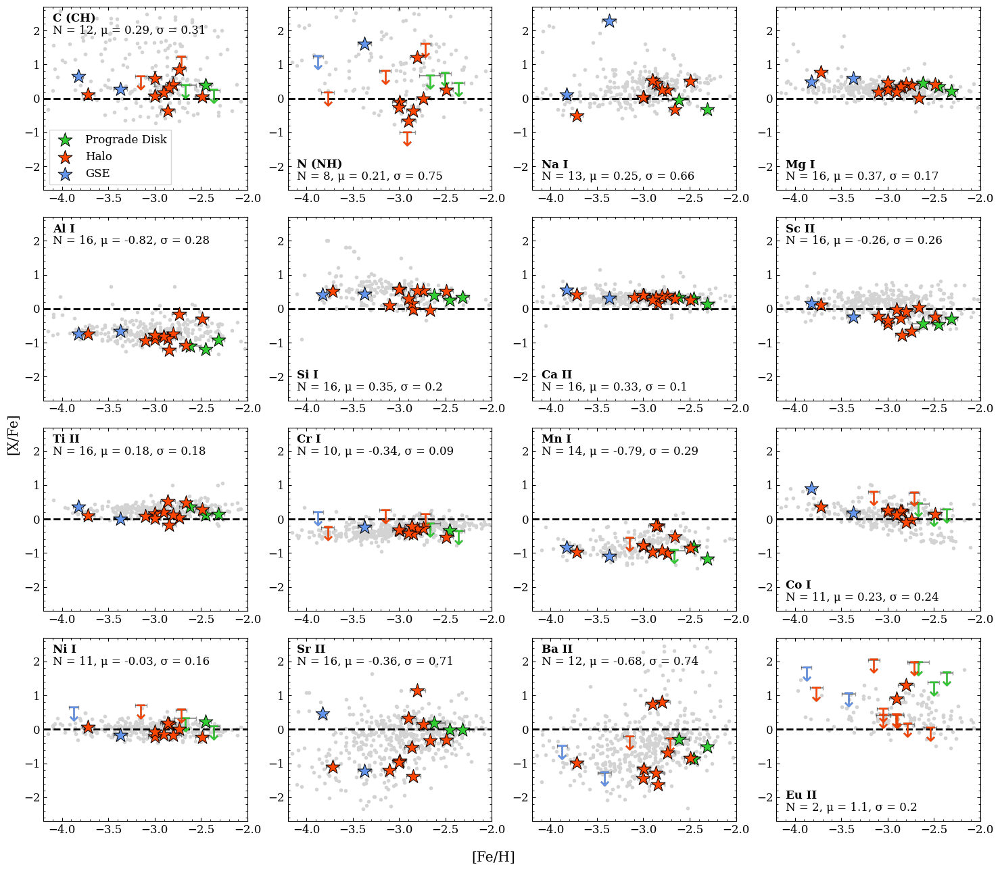

In [34]:
# Storing all abundance dataframes (both observed and literature) into lists
# NOTE: make sure that the order of the elements in el_list matches the order of the abundance dataframes in all_abunds and all_lit_abunds
el_list = ['C (CH)', 'N (NH)', 'Na I', 'Mg I', 'Al I', 'Si I', 'Ca II', 'Sc II',
           'Ti II', 'Cr I', 'Mn I', 'Co I', 'Ni I', 'Sr II', 'Ba II', 'Eu II']
all_abunds = [c_I_abunds, n_I_abunds, na_I_abunds, mg_I_abunds, al_I_abunds, si_I_abunds, ca_II_abunds, sc_II_abunds,
            ti_II_abunds, cr_I_abunds, mn_I_abunds, co_I_abunds, ni_I_abunds, sr_II_abunds, ba_II_abunds, eu_II_abunds]
all_lit_abunds = [cI_lit_abund, nI_lit_abund, naI_lit_abund, mgI_lit_abund, alI_lit_abund, siI_lit_abund, caI_lit_abund,
                  scII_lit_abund, tiII_lit_abund, crI_lit_abund, mnI_lit_abund, coI_lit_abund, niI_lit_abund, 
                  srII_lit_abund, baII_lit_abund, euII_lit_abund]
all_feh = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/stellar_params.csv')


fig, axs = plt.subplots(4, 4, figsize=[15,13], tight_layout=True)
fig.subplots_adjust(wspace=0.25)
fig.supxlabel('[Fe/H]')
fig.supylabel('[X/Fe]')


for ax, el in zip(axs.flat, el_list):

    # Getting index of element
    el_index = el_list.index(el)
    
    # Getting the abundance data for the element
    abund_df = all_abunds[el_index]
    
    abund_detect = abund_df[abund_df['detection'] == 'Y']
    abund_detect_prodisk = abund_detect[abund_detect['orbit'] == 'pro_disk']
    abund_detect_halo = abund_detect[abund_detect['orbit'] == 'halo']
    abund_detect_gse = abund_detect[abund_detect['orbit'] == 'gse']
    
    abund_nondetect = abund_df[abund_df['detection'] == 'N']
    abund_nondetect_prodisk = abund_nondetect[abund_nondetect['orbit'] == 'pro_disk']
    abund_nondetect_halo = abund_nondetect[abund_nondetect['orbit'] == 'halo']
    abund_nondetect_gse = abund_nondetect[abund_nondetect['orbit'] == 'gse']
    
    # Getting the literature data for the element
    lit_abund_df = all_lit_abunds[el_index]
    
    
    # ---PLOTTING--- #
    # Plotting literature data
    ax.scatter(lit_abund_df['feh'], lit_abund_df['abund'], c="lightgrey", marker='.', zorder=1)
    
    # Plotting observed data (detections)
    ax.scatter(abund_detect_prodisk['feh'], abund_detect_prodisk['bestfit_abund_xfe'], color='limegreen', label='Prograde Disk', 
               marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
    ax.errorbar(abund_detect_prodisk['feh'], abund_detect_prodisk['bestfit_abund_xfe'], xerr=abund_detect_prodisk['feh_err'],
               yerr=abund_detect_prodisk['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=0.4)
    ax.scatter(abund_detect_halo['feh'], abund_detect_halo['bestfit_abund_xfe'], color='orangered', label='Halo', 
               marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
    ax.errorbar(abund_detect_halo['feh'], abund_detect_halo['bestfit_abund_xfe'], xerr=abund_detect_halo['feh_err'],
               yerr=abund_detect_halo['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=0.4)
    ax.scatter(abund_detect_gse['feh'], abund_detect_gse['bestfit_abund_xfe'], color='cornflowerblue', label='GSE', 
               marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
    ax.errorbar(abund_detect_gse['feh'], abund_detect_gse['bestfit_abund_xfe'], xerr=abund_detect_gse['feh_err'],
               yerr=abund_detect_gse['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=0.4)
    
    # Plotting observed data (non-detections)
    ax.scatter(abund_nondetect_prodisk['feh'] - 0.05, abund_nondetect_prodisk['upper_limit_xfe'] - 0.05, color='limegreen', zorder=5, 
               marker='${↧}$', s=250, linewidths=0.1, edgecolor='black')
    ax.errorbar(abund_nondetect_prodisk['feh'] - 0.05, abund_nondetect_prodisk['upper_limit_xfe'] + 0.12, 
                xerr=abund_nondetect_prodisk['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)
    ax.scatter(abund_nondetect_halo['feh'] - 0.05, abund_nondetect_halo['upper_limit_xfe'] - 0.05, color='orangered', zorder=5, 
               marker='${↧}$', s=250, linewidths=0.1, edgecolor='black')
    ax.errorbar(abund_nondetect_halo['feh'] - 0.05, abund_nondetect_halo['upper_limit_xfe'] + 0.12, 
                xerr=abund_nondetect_halo['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)
    ax.scatter(abund_nondetect_gse['feh'] - 0.05, abund_nondetect_gse['upper_limit_xfe'] - 0.05, color='cornflowerblue', zorder=5, 
               marker='${↧}$', s=250, linewidths=0.1, edgecolor='black')
    ax.errorbar(abund_nondetect_gse['feh'] - 0.05, abund_nondetect_gse['upper_limit_xfe'] + 0.12, 
                xerr=abund_nondetect_gse['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)

    ax.axhline(y=0, color='black', linestyle='--', linewidth=2, zorder=2)
    
    if el == 'N (NH)' or el == 'Na I' or el == 'Mg I' or el == 'Si I' or el == 'Ca II' or el == 'Co I' or el == 'Eu II':
        ax.text(-4.1, -2.05, el, fontsize=12, fontweight='bold')
        ax.text(-4.1, -2.4, f"N = {len(abund_detect)}, μ = {round(np.mean(abund_detect['bestfit_abund_xfe']), 2)}, σ = {round(np.std(abund_detect['bestfit_abund_xfe']), 2)}", fontsize=12)
    else:
        ax.text(-4.1, 2.25, el, fontsize=12, fontweight='bold')
        ax.text(-4.1, 1.9, f"N = {len(abund_detect)}, μ = {round(np.mean(abund_detect['bestfit_abund_xfe']), 2)}, σ = {round(np.std(abund_detect['bestfit_abund_xfe']), 2)}", fontsize=12)

    
    ax.set_xlim(-4.2, -2.0)
    ax.set_ylim(-2.7, 2.7)
    
    # Putting the legend in the first subplot
    if el_index == 0:
        ax.legend(fancybox=False, loc='lower left')
    

plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/results/abund_comparision/fe_xfe_updated_v9.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/results/abund_comparision/fe_xfe_updated_v9.png", dpi=300, transparent=False, facecolor="white")



In [48]:
ba_II_abunds[['star_id', 'bestfit_abund_xfe', 'bestfit_abund_comberr_xfe', 'bestfit_abund_tefferr_xfe', 'bestfit_abund_loggerr_xfe', 'bestfit_abund_vmicerr_xfe']]

,star_id,bestfit_abund_xfe,bestfit_abund_comberr_xfe,bestfit_abund_tefferr_xfe,bestfit_abund_loggerr_xfe,bestfit_abund_vmicerr_xfe
0,ra_0103-7050_s163,-0.245400,0.240877,0.452050,0.337800,0.451373
16,ra_0834-5220_s316,-0.381358,0.102307,0.062120,0.094905,0.019529
37,ra_1604-2712_s24,-0.847222,0.045971,0.071826,0.096728,0.067118
48,ra_1604-2712_s292,-0.469547,18.571221,0.075505,0.095624,0.006659
64,ra_1624-2150_s278,-0.527086,0.036752,0.062886,0.090111,0.009023
80,ra_1633-2814_s130,-1.486997,0.039165,0.072136,0.092704,0.002719
96,ra_1633-2814_s284,-0.655744,0.041756,0.081689,0.094860,0.004578
112,ra_1648-0653_s38,-0.871406,0.115837,0.070225,0.092245,0.010531
132,ra_1656-1433_s143,0.796357,0.071094,0.084236,0.070970,0.182639
144,ra_1658-2454_s22,-1.356834,0.030930,0.065334,0.124127,0.014223


In [52]:
eu_II_abunds[eu_II_abunds['detection'] == 'Y'][['star_id', 'bestfit_abund_xfe']]

,star_id,bestfit_abund_xfe
19,ra_0834-5220_s316,1.622318
136,ra_1656-1433_s143,1.298468
192,ra_1752-4300_s214,-0.010288
246,ra_1853-3255_s45,0.907560


Checking the weirdness with Sc

In [37]:
sc_II_abunds.sort_values(by='bestfit_abund_xfe')[['star_id', 'bestfit_abund_xfe', 'bestfit_abund_tefferr_xfe', 'bestfit_abund_loggerr_xfe']]

,star_id,bestfit_abund_xfe,bestfit_abund_tefferr_xfe,bestfit_abund_loggerr_xfe
235,ra_1752-4300_s269,-0.780858,3.322081e-08,3.322081e-08
205,ra_1752-4300_s214,-0.738419,2.203838e-06,2.203838e-06
133,ra_1648-0653_s38,-0.440152,5.157380e-11,5.157380e-11
252,ra_1752-4300_s6,-0.396350,0.000000e+00,0.000000e+00
201,ra_1709-2130_s102,-0.349765,0.000000e+00,0.000000e+00
167,ra_1658-2454_s22,-0.333707,0.000000e+00,0.000000e+00
31,ra_0834-5220_s316,-0.330160,5.344170e-11,5.344170e-11
150,ra_1656-1433_s143,-0.299383,0.000000e+00,0.000000e+00
14,ra_0103-7050_s163,-0.277167,1.153488e-09,1.153488e-09
99,ra_1633-2814_s130,-0.265344,0.000000e+00,0.000000e+00


In [11]:
def sc_new(path):
    stars_list = [path + star for star in os.listdir(path) if os.path.isdir(os.path.join(path, star))]
    
    sc_all = []
    for star in stars_list:
        sc_abund = pd.read_csv(star + '/Sc_II_abund.csv')
        sc_dict = {'star_id': sc_abund['star_id'].values[0], 'feh': sc_abund['mh'].to_numpy()[0], 
                   'bestfit_abund_xfe': sc_abund['Sc_II_xfe_it2'].values[0], 'bestfit_abund_tefferr_xfe': sc_abund['Sc_II_xfe_tefferr'].values[0]}
        sc_all.append(sc_dict)
        
    sc_df = pd.DataFrame(sc_all)
    
    return sc_df
        

new_sc_abunds = sc_new('/data/misfit/benlowe/xshooter/korg_data/tests/sc_abunds/')
new_sc_abunds.sort_values(by='star_id')

sc_II_abunds.sort_values(by='bestfit_abund_xfe')[['star_id', 'bestfit_abund_xfe', 'teff', 'logg']]

,star_id,bestfit_abund_xfe,teff,logg
205,ra_1752-4300_s214,-1.262578,4853.568748,1.552000
234,ra_1752-4300_s269,-0.805785,4917.930552,1.682200
251,ra_1752-4300_s6,-0.620144,4857.902071,1.549800
132,ra_1648-0653_s38,-0.514705,6039.830368,3.646778
30,ra_0834-5220_s316,-0.457788,5959.304567,4.286104
200,ra_1709-2130_s102,-0.356065,4985.984984,1.850150
98,ra_1633-2814_s130,-0.330984,4997.869004,1.849800
57,ra_1604-2712_s292,-0.307851,5783.249268,3.404600
13,ra_0103-7050_s163,-0.275096,6298.806689,4.492229
268,ra_1853-3255_s45,-0.167960,5033.857005,2.378863


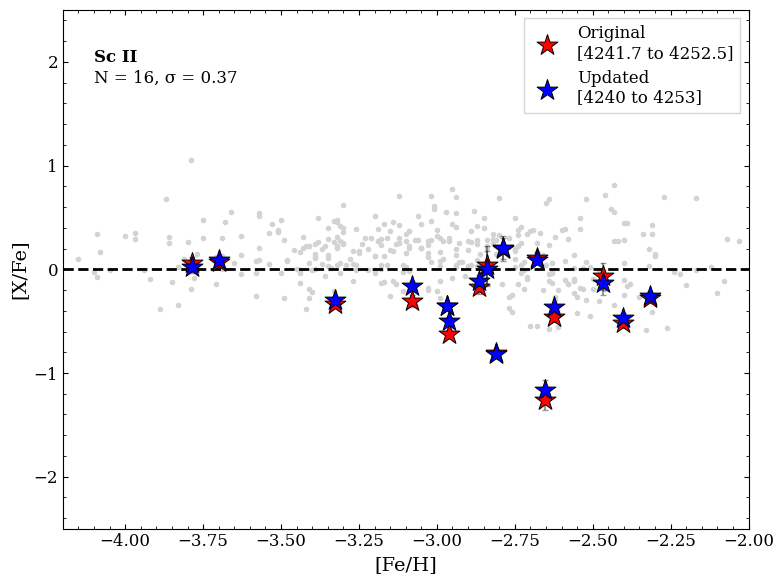

In [33]:
plt.figure(figsize=[8,6])
plt.scatter(scII_lit_abund['feh'], scII_lit_abund['abund'], c="lightgrey", marker='.', zorder=1)

# Plotting original Sc II data
plt.scatter(sc_II_abunds['feh'], sc_II_abunds['bestfit_abund_xfe'], color='red', label='Original\n[4241.7 to 4252.5]', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(sc_II_abunds['feh'], sc_II_abunds['bestfit_abund_xfe'],
            yerr=sc_II_abunds['bestfit_abund_tefferr_xfe'], fmt='o', color='black', zorder=1, alpha=0.4)

# Plotting updated Sc II data
plt.scatter(new_sc_abunds['feh'], new_sc_abunds['bestfit_abund_xfe'], color='blue', label='Updated\n[4240 to 4253]', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(new_sc_abunds['feh'], new_sc_abunds['bestfit_abund_xfe'],
            yerr=new_sc_abunds['bestfit_abund_tefferr_xfe'], fmt='o', color='black', zorder=1, alpha=0.4)


plt.axhline(y=0, color='black', linestyle='--', linewidth=2, zorder=2)
plt.text(-4.1, 2, 'Sc II', fontsize=12, fontweight='bold')
plt.text(-4.1, 1.8, f"N = {len(sc_II_abunds)}, σ = {round(np.std(sc_II_abunds['bestfit_abund_xfe']), 2)}", fontsize=12)
plt.xlim(-4.2, -2.0)
plt.ylim(-2.5, 2.5)

plt.xlabel('[Fe/H]')
plt.ylabel('[X/Fe]')

plt.legend(fancybox=False)
plt.tight_layout()

plt.savefig("/data/misfit/benlowe/xshooter/results/tests/sc/sc_cont_adjust.png", dpi=300, transparent=False, facecolor="white")


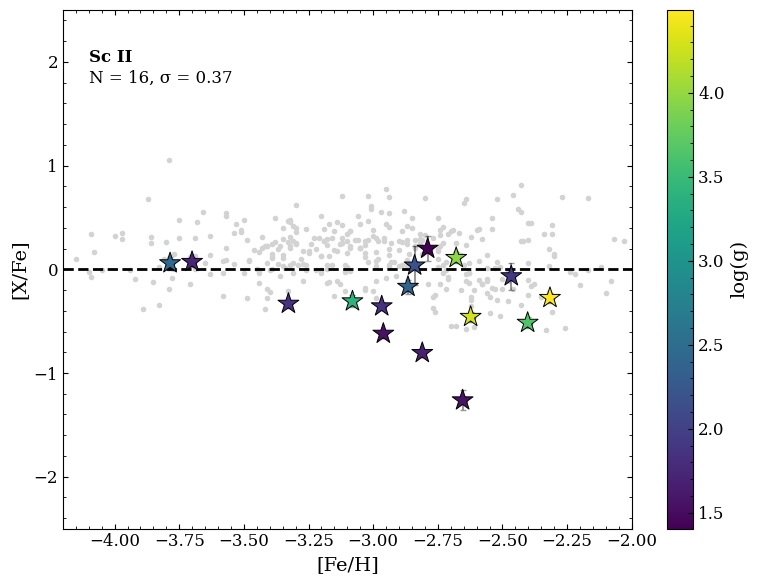

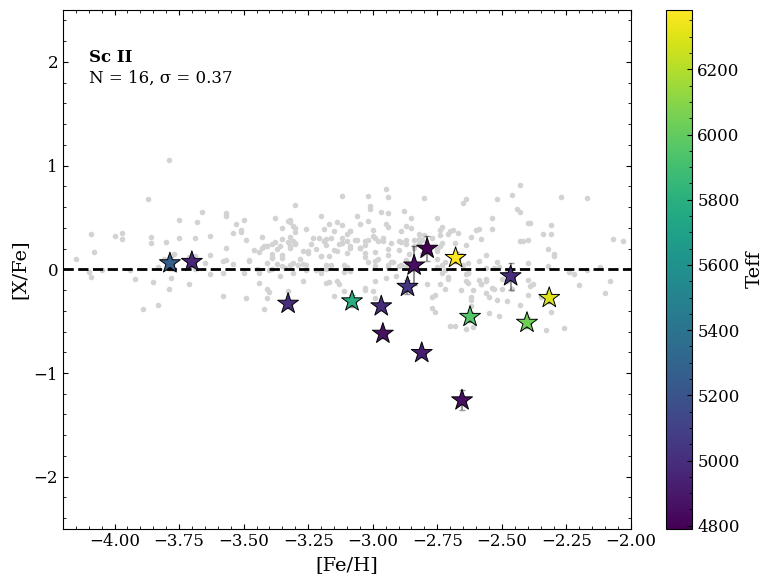

In [35]:
plt.figure(figsize=[8,6])
plt.scatter(scII_lit_abund['feh'], scII_lit_abund['abund'], c="lightgrey", marker='.', zorder=1)

# Plotting original Sc II data
plt.scatter(sc_II_abunds['feh'], sc_II_abunds['bestfit_abund_xfe'], c=sc_II_abunds['logg'], 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(sc_II_abunds['feh'], sc_II_abunds['bestfit_abund_xfe'],
            yerr=sc_II_abunds['bestfit_abund_tefferr_xfe'], fmt='o', color='black', zorder=1, alpha=0.4)


plt.axhline(y=0, color='black', linestyle='--', linewidth=2, zorder=2)
plt.text(-4.1, 2, 'Sc II', fontsize=12, fontweight='bold')
plt.text(-4.1, 1.8, f"N = {len(sc_II_abunds)}, σ = {round(np.std(sc_II_abunds['bestfit_abund_xfe']), 2)}", fontsize=12)
plt.xlim(-4.2, -2.0)
plt.ylim(-2.5, 2.5)

plt.xlabel('[Fe/H]')
plt.ylabel('[X/Fe]')

plt.colorbar(label='log(g)')
plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/results/tests/sc/sc_logg.png", dpi=300, transparent=False, facecolor="white")




plt.figure(figsize=[8,6])
plt.scatter(scII_lit_abund['feh'], scII_lit_abund['abund'], c="lightgrey", marker='.', zorder=1)

# Plotting original Sc II data
plt.scatter(sc_II_abunds['feh'], sc_II_abunds['bestfit_abund_xfe'], c=sc_II_abunds['teff'], 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(sc_II_abunds['feh'], sc_II_abunds['bestfit_abund_xfe'],
            yerr=sc_II_abunds['bestfit_abund_tefferr_xfe'], fmt='o', color='black', zorder=1, alpha=0.4)


plt.axhline(y=0, color='black', linestyle='--', linewidth=2, zorder=2)
plt.text(-4.1, 2, 'Sc II', fontsize=12, fontweight='bold')
plt.text(-4.1, 1.8, f"N = {len(sc_II_abunds)}, σ = {round(np.std(sc_II_abunds['bestfit_abund_xfe']), 2)}", fontsize=12)
plt.xlim(-4.2, -2.0)
plt.ylim(-2.5, 2.5)

plt.xlabel('[Fe/H]')
plt.ylabel('[X/Fe]')

plt.colorbar(label='Teff')
plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/results/tests/sc/sc_teff.png", dpi=300, transparent=False, facecolor="white")



In [41]:
print(np.nanmean(srba_lit_abund))
print(np.nanstd(srba_lit_abund))

print(np.nanmean(all_df['srba']))
print(np.nanstd(all_df['srba']))

0.11266958212206869
0.5951734095879577
0.45646546551686934
0.3597566876109484


Checking for any C-enhanced stars

In [151]:
print("The following are C-enhanced:")
for entry in c_I_abunds.iterrows():
    if entry[1]['detection'] == 'Y':
        star_id = entry[1]['star_id']
        cfe_vals = entry[1]['bestfit_abund_xfe']
        
        if cfe_vals >= 0.7:
            print(f"{star_id} ([C/Fe] = {cfe_vals:.2f})")
            
print()           
print("The following are C-normal:")
for entry in c_I_abunds.iterrows():
    if entry[1]['detection'] == 'Y':
        star_id = entry[1]['star_id']
        cfe_vals = entry[1]['bestfit_abund_xfe']
        
        if cfe_vals < 0.7 and cfe_vals >= 0:
            print(f"{star_id} ([C/Fe] = {cfe_vals:.2f})")
            
            
print()           
print("The following are C-depleted:")
for entry in c_I_abunds.iterrows():
    if entry[1]['detection'] == 'Y':
        star_id = entry[1]['star_id']
        cfe_vals = entry[1]['bestfit_abund_xfe']
        
        if cfe_vals < 0:
            print(f"{star_id} ([C/Fe] = {cfe_vals:.2f})")

The following are C-enhanced:
ra_1752-4300_s214 ([C/Fe] = 0.78)

The following are C-normal:
ra_0834-5220_s316 ([C/Fe] = 0.28)
ra_1604-2712_s24 ([C/Fe] = 0.01)
ra_1633-2814_s130 ([C/Fe] = 0.18)
ra_1633-2814_s284 ([C/Fe] = 0.64)
ra_1648-0653_s38 ([C/Fe] = 0.40)
ra_1656-1433_s143 ([C/Fe] = 0.36)
ra_1659-2154_s114 ([C/Fe] = 0.13)
ra_1709-2130_s102 ([C/Fe] = 0.06)
ra_1752-4300_s269 ([C/Fe] = 0.32)
ra_1752-4300_s6 ([C/Fe] = 0.56)
ra_1853-3255_s45 ([C/Fe] = 0.16)

The following are C-depleted:
ra_1658-2454_s22 ([C/Fe] = -0.35)


## Looking at individual element scatter

### N-enhanced stars

In [17]:
n_I_abunds

,star_id,teff,logg,vmic,vsini,feh,feh_err,el,detection,upper_limit_xfe,...,bestfit_abund_loggerr_xfe,bestfit_abund_loggerr_xh,bestfit_abund_vmicerr_xfe,bestfit_abund_vmicerr_xh,Jp,Jtot,Jz,Jr,zmax,orbit
6,ra_0103-7050_s163,6298.806689,4.492229,1.253413,0,-2.312521,0.067078,N_I,N,0.33,...,0.078673,0.078673,2.778008e-01,2.778008e-01,1191.012215,1.198272e+03,88.491505,9.754294e+01,2.132239,pro_disk
20,ra_1648-0653_s38,6039.830368,3.646778,1.533073,0,-2.453756,0.063382,N_I,N,0.62,...,0.081652,0.081652,2.143578e-02,2.143578e-02,1295.837964,1.297820e+03,71.690885,4.189520e-01,1.470769,pro_disk
33,ra_1604-2712_s24,5002.684528,1.891750,2.007753,0,-2.489450,0.069695,N_I,Y,-1.26,...,0.122475,0.122475,9.069008e-03,9.069008e-03,-508.586881,6.654891e+02,370.549358,2.165831e+02,5.618895,halo
54,ra_0834-5220_s316,5959.304567,4.286104,1.246679,0,-2.618883,0.115246,N_I,N,0.55,...,0.067514,0.067514,8.801009e-03,8.801009e-03,938.289662,1.009217e+03,48.475280,3.684863e+02,1.824720,pro_disk
66,ra_1752-4300_s214,4853.568748,1.552000,2.149283,0,-2.739103,0.077677,N_I,Y,-0.86,...,0.144389,0.144389,6.079666e-03,6.079666e-03,914.584316,1.323654e+03,210.528491,9.334202e+02,7.915003,halo
86,ra_1624-2150_s278,6381.865006,3.973617,1.490113,0,-2.663590,0.056390,N_I,N,1.48,...,0.049123,0.049123,4.907393e-02,4.907393e-02,849.634492,9.919699e+02,159.863856,4.863836e+02,4.521274,halo
96,ra_1656-1433_s143,4791.462397,1.406800,2.214264,0,-2.801119,0.086527,N_I,Y,-0.72,...,0.224825,0.224825,3.666702e-02,3.666702e-02,194.053140,5.428655e+02,499.728841,8.554198e+01,4.361530,halo
113,ra_1752-4300_s269,4917.930552,1.682200,2.101033,0,-2.845002,0.074637,N_I,Y,-0.75,...,0.111430,0.111430,7.796635e-03,7.796635e-03,11438.398252,1.951598e+07,343.039397,1.951598e+07,72.038029,halo
131,ra_1658-2454_s22,4852.253676,2.164886,1.673293,0,-2.861141,0.081783,N_I,N,-1.13,...,0.026668,0.026668,6.747960e-07,6.747960e-07,165.986919,3.408191e+02,222.753531,1.974508e+02,3.276006,halo
145,ra_1853-3255_s45,5033.857005,2.378863,1.678355,0,-2.901286,0.081281,N_I,Y,-1.11,...,0.066836,0.066836,1.266587e-02,1.266587e-02,146.169821,3.116854e+02,271.314839,4.658758e+01,2.652041,halo


In [ ]:
# Doing this for our stars
print("The following are N-enhanced:")
prodisk_list = []
halo_list = []
gse_list = []
all_list = []

for entry in c_I_abunds.iterrows():
    if entry[1]['detection'] == 'Y':
        star_id = entry[1]['star_id']
        nfe_entry = n_I_abunds[n_I_abunds['star_id'] == star_id]
        orb = entry[1]['orbit']
        if nfe_entry['detection'].values[0] == 'Y':
            
            # Getting raw [C/Fe] value by subtracting off the C correction
            cfe_vals = entry[1]['bestfit_abund_xfe']
            cfe_corr = entry[1]['cfe_corr']
            cfe_vals -= cfe_corr
            
            cfe_errs = entry[1]['bestfit_abund_comberr_xfe']
            nfe_vals = n_I_abunds[n_I_abunds['star_id'] == star_id]['bestfit_abund_xfe'].values[0]
            nfe_errs = n_I_abunds[n_I_abunds['star_id'] == star_id]['bestfit_abund_comberr_xfe'].values[0]
            feh_vals = entry[1]['feh']
            
            cn_vals = cfe_vals - nfe_vals
            cn_errs = np.sqrt(cfe_errs**2 + nfe_errs**2)
            
            if orb == 'pro_disk':
                prodisk_dict = {'star_id': star_id, 'detection': 'Y', 'cfe': cfe_vals, 'nfe': nfe_vals, 'nfe_err': nfe_errs, 
                                'cn': cn_vals, 'cn_err': cn_errs, 'feh': feh_vals}
                prodisk_list.append(prodisk_dict)
            elif orb == 'halo':
                halo_dict = {'star_id': star_id, 'detection': 'Y', 'cfe': cfe_vals, 'nfe': nfe_vals, 'nfe_err': nfe_errs, 
                                'cn': cn_vals, 'cn_err': cn_errs, 'feh': feh_vals}
                halo_list.append(halo_dict)
            elif orb == 'gse':
                gse_dict = {'star_id': star_id, 'detection': 'Y', 'cfe': cfe_vals, 'nfe': nfe_vals, 'nfe_err': nfe_errs, 
                                'cn': cn_vals, 'cn_err': cn_errs, 'feh': feh_vals}
                gse_list.append(gse_dict)
            
            all_list.append({'star_id': star_id, 'cfe': cfe_vals, 'nfe': nfe_vals, 'nfe_err': nfe_errs,
                                'cn': cn_vals, 'cn_err': cn_errs, 'feh': feh_vals, 'orbit': orb})
            
            if nfe_vals > 0.5 and cn_vals < -0.7:
                print(f"{star_id} ([N/Fe] = {nfe_vals:.2f} and [C/N] = {cn_vals:.2f})")

        if nfe_entry['detection'].values[0] == 'N':
            
            # Getting raw [C/Fe] value by subtracting off the C correction
            cfe_vals = entry[1]['bestfit_abund_xfe']
            cfe_corr = entry[1]['cfe_corr']
            cfe_vals -= cfe_corr
            
            cfe_errs = entry[1]['bestfit_abund_comberr_xfe']
            nfe_vals = n_I_abunds[n_I_abunds['star_id'] == star_id]['upper_limit_xfe'].values[0]
            nfe_errs = np.nan
            feh_vals = entry[1]['feh']
            
            cn_vals = cfe_vals - nfe_vals
            cn_errs = np.nan
            
            if orb == 'pro_disk':
                prodisk_dict = {'star_id': star_id, 'detection': 'N', 'cfe': cfe_vals, 'nfe': nfe_vals, 'nfe_err': nfe_errs, 
                                'cn': cn_vals, 'cn_err': cn_errs, 'feh': feh_vals}
                prodisk_list.append(prodisk_dict)
            elif orb == 'halo':
                halo_dict = {'star_id': star_id, 'detection': 'N', 'cfe': cfe_vals, 'nfe': nfe_vals, 'nfe_err': nfe_errs, 
                                'cn': cn_vals, 'cn_err': cn_errs, 'feh': feh_vals}
                halo_list.append(halo_dict)
            elif orb == 'gse':
                gse_dict = {'star_id': star_id, 'detection': 'N', 'cfe': cfe_vals, 'nfe': nfe_vals, 'nfe_err': nfe_errs, 
                                'cn': cn_vals, 'cn_err': cn_errs, 'feh': feh_vals}
                gse_list.append(gse_dict)
            
            all_list.append({'star_id': star_id, 'cfe': cfe_vals, 'nfe': nfe_vals, 'nfe_err': nfe_errs,
                                'cn': cn_vals, 'cn_err': cn_errs, 'feh': feh_vals, 'orbit': orb})
            
            if nfe_vals > 0.5 and cn_vals < -0.7:
                print(f"{star_id} ([N/Fe] = {nfe_vals:.2f} and [C/N] = {cn_vals:.2f})")
                
                
prodisk_df = pd.DataFrame(prodisk_list)
halo_df = pd.DataFrame(halo_list)
gse_df = pd.DataFrame(gse_list)
all_df = pd.DataFrame(all_list)

# Separating the non-detections from the detections
prodisk_detect_df = prodisk_df[prodisk_df['detection'] == 'Y']
gse_detect_df = gse_df[gse_df['detection'] == 'Y']
halo_detect_df = halo_df[halo_df['detection'] == 'Y']

prodisk_nondetect_df = prodisk_df[prodisk_df['detection'] == 'N']
gse_nondetect_df = gse_df[gse_df['detection'] == 'N']
halo_nondetect_df = halo_df[halo_df['detection'] == 'N']

# Doing this for literature stars
nfe_lit_abund = nI_lit_abund['abund'].to_numpy()
cfe_lit_abund = cI_lit_abund['abund'].to_numpy()
cn_lit_abund = cfe_lit_abund - nfe_lit_abund

The following are N-enhanced:
ra_1656-1433_s143 ([N/Fe] = 1.20 and [C/N] = -1.31)
ra_1633-2814_s130 ([N/Fe] = 1.61 and [C/N] = -1.37)


In [ ]:
display(halo_nondetect_df)
halo_nondetect_df

,star_id,detection,cfe,nfe,nfe_err,cn,cn_err,feh
1,ra_1633-2814_s284,N,0.6455,1.11,NaN,-0.4645,NaN,-3.824624


,star_id,detection,cfe,nfe,nfe_err,cn,cn_err,feh
4,ra_1658-2454_s22,N,-0.376443,-1.13,NaN,0.753557,NaN,-2.861141
8,ra_1659-2154_s114,N,-0.011369,0.05,NaN,-0.061369,NaN,-3.718210


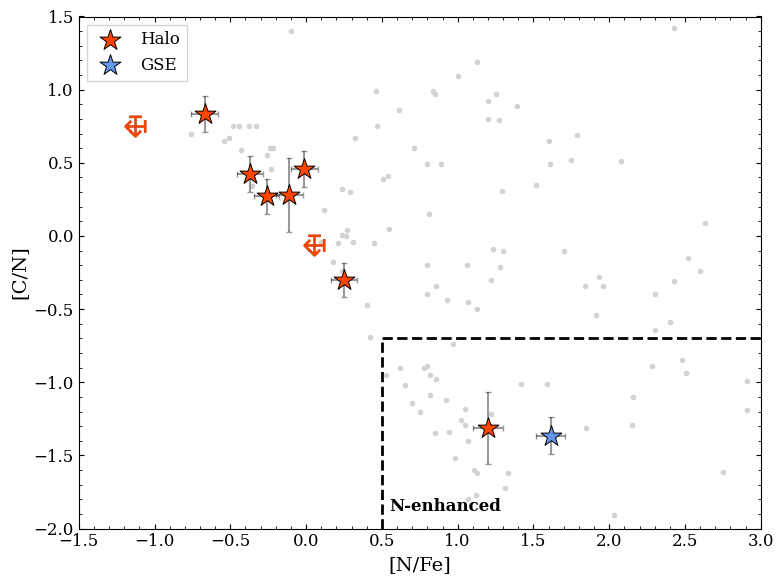

In [21]:
plt.figure(figsize=[8,6])
# plt.scatter(prodisk_df['nfe'], prodisk_df['cn'], color='limegreen', label='Prograde Disk', 
#             marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
# plt.errorbar(prodisk_df['nfe'], prodisk_df['cn'], xerr=prodisk_df['nfe_err'],
#              yerr=prodisk_df['cn_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(halo_detect_df['nfe'], halo_detect_df['cn'], color='orangered', label='Halo', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(halo_detect_df['nfe'], halo_detect_df['cn'], xerr=halo_detect_df['nfe_err'],
             yerr=halo_detect_df['cn_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(gse_detect_df['nfe'], gse_detect_df['cn'], color='cornflowerblue', label='GSE', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(gse_detect_df['nfe'], gse_detect_df['cn'], xerr=gse_detect_df['nfe_err'],
             yerr=gse_detect_df['cn_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(nfe_lit_abund, cn_lit_abund, color='lightgrey', marker='.', zorder=1)
plt.hlines(y=-0.7, xmin=0.5, xmax=10, color='black', linestyle='--', linewidth=2)
plt.vlines(x=0.5, ymax = -0.7, ymin=-2, color='black', linestyle='--', linewidth=2)

# For upper-limits in [N/Fe] and lower-limits in [C/N]: plot left-facing arrow for [N/Fe] upper-limit, and up-facing arrow for [C/N] lower-limit
plt.scatter(halo_nondetect_df['nfe'], halo_nondetect_df['cn'], color='orangered', zorder=5, 
            marker='${↧}$', s=250, linewidths=0.1, edgecolor='black')
plt.scatter(halo_nondetect_df['nfe'], halo_nondetect_df['cn'], color='orangered', zorder=5, 
            marker='${↤}$', s=250, linewidths=0.1, edgecolor='black')

# rectangle = plt.Rectangle((0.5, -0.7), 4, -2, facecolor='grey', alpha=0.1, zorder=-10)
# plt.gca().add_patch(rectangle)
plt.text(0.55, -1.85, 'N-enhanced', fontsize=12, color='black', ha='left', va='center', weight='bold')
plt.xlabel('[N/Fe]')
plt.ylabel('[C/N]')
plt.xlim(-1.5, 3)
plt.ylim(-2, 1.5)
plt.legend(fancybox=False)

plt.tight_layout()
# plt.savefig("/data/misfit/benlowe/xshooter/results/star_abunds/c_n_enhanced_v5.pdf", dpi=300, transparent=False, facecolor="white")
# plt.savefig("/data/misfit/benlowe/xshooter/results/star_abunds/c_n_enhanced_v5.png", dpi=300, transparent=False, facecolor="white")

In [27]:
# Making table for paper
cn_tab = all_df[['star_id', 'cn', 'cn_err']]

dict_list = []
for star in cn_tab.iterrows():
    
    cn_val = f"${star[1]['cn']:.2f} \pm {star[1]['cn_err']:.2f}$"

    cn_dict = {'Star': star[1]['star_id'], '[C/N]': cn_val}
    dict_list.append(cn_dict)
    
cn_final_tab = pd.DataFrame(dict_list)
cn_final_tab.sort_values(by='Star', inplace=True)

print(cn_final_tab.to_latex(index=False))


\begin{tabular}{ll}
\toprule
Star & [C/N] \\
\midrule
ra_1604-2712_s24 & $-0.19 \pm 0.12$ \\
ra_1633-2814_s130 & $-1.35 \pm 0.13$ \\
ra_1656-1433_s143 & $-0.78 \pm 0.24$ \\
ra_1709-2130_s102 & $0.33 \pm 0.12$ \\
ra_1752-4300_s214 & $0.86 \pm 0.12$ \\
ra_1752-4300_s269 & $0.69 \pm 0.12$ \\
ra_1752-4300_s6 & $0.69 \pm 0.25$ \\
ra_1853-3255_s45 & $0.85 \pm 0.12$ \\
\bottomrule
\end{tabular}



### r-process stars

In [33]:
ba_II_abunds

,star_id,teff,logg,vmic,vsini,feh,feh_err,el,detection,upper_limit_xfe,...,bestfit_abund_loggerr_xfe,bestfit_abund_loggerr_xh,bestfit_abund_vmicerr_xfe,bestfit_abund_vmicerr_xh,Jp,Jtot,Jz,Jr,zmax,orbit
0,ra_0103-7050_s163,6298.806689,4.492229,1.253413,0,-2.312521,0.067078,Ba_II,N,-0.695962,...,0.337800,0.337800,0.451373,0.451373,1191.012215,1.198272e+03,88.491505,9.754294e+01,2.132239,pro_disk
16,ra_1648-0653_s38,6039.830368,3.646778,1.533073,0,-2.453756,0.063382,Ba_II,Y,-0.750923,...,0.092245,0.092245,0.010531,0.010531,1295.837964,1.297820e+03,71.690885,4.189520e-01,1.470769,pro_disk
37,ra_1604-2712_s24,5002.684528,1.891750,2.007753,0,-2.489450,0.069695,Ba_II,Y,NaN,...,0.096728,0.096728,0.067118,0.067118,-508.586881,6.654891e+02,370.549358,2.165831e+02,5.618895,halo
48,ra_0834-5220_s316,5959.304567,4.286104,1.246679,0,-2.618883,0.115246,Ba_II,Y,-0.014225,...,0.094905,0.094905,0.019529,0.019529,938.289662,1.009217e+03,48.475280,3.684863e+02,1.824720,pro_disk
70,ra_1752-4300_s214,4853.568748,1.552000,2.149283,0,-2.739103,0.077677,Ba_II,Y,NaN,...,0.092568,0.092568,0.065497,0.065497,914.584316,1.323654e+03,210.528491,9.334202e+02,7.915003,halo
80,ra_1624-2150_s278,6381.865006,3.973617,1.490113,0,-2.663590,0.056390,Ba_II,N,-0.383487,...,0.090111,0.090111,0.009023,0.009023,849.634492,9.919699e+02,159.863856,4.863836e+02,4.521274,halo
100,ra_1656-1433_s143,4791.462397,1.406800,2.214264,0,-2.801119,0.086527,Ba_II,Y,NaN,...,0.070970,0.070970,0.182639,0.182639,194.053140,5.428655e+02,499.728841,8.554198e+01,4.361530,halo
117,ra_1752-4300_s269,4917.930552,1.682200,2.101033,0,-2.845002,0.074637,Ba_II,Y,NaN,...,0.093773,0.093773,0.010616,0.010616,11438.398252,1.951598e+07,343.039397,1.951598e+07,72.038029,halo
128,ra_1658-2454_s22,4852.253676,2.164886,1.673293,0,-2.861141,0.081783,Ba_II,Y,-1.258744,...,0.124127,0.124127,0.014223,0.014223,165.986919,3.408191e+02,222.753531,1.974508e+02,3.276006,halo
144,ra_1853-3255_s45,5033.857005,2.378863,1.678355,0,-2.901286,0.081281,Ba_II,Y,-1.132585,...,0.662077,0.662077,0.170623,0.170623,146.169821,3.116854e+02,271.314839,4.658758e+01,2.652041,halo


In [27]:
# Doing this for our stars
print("The following are r-II:")
prodisk_list = []
halo_list = []
gse_list = []
for entry in ba_II_abunds.iterrows():
    if entry[1]['detection'] == 'Y':
        star_id = entry[1]['star_id']
        eu_II_entry = eu_II_abunds[eu_II_abunds['star_id'] == star_id]
        orb = entry[1]['orbit']
        feh_vals = entry[1]['feh']
        feh_errs = entry[1]['feh_err']

        if eu_II_entry['detection'].values[0] == 'Y':
            ba_vals = entry[1]['bestfit_abund_xfe']
            ba_errs = entry[1]['bestfit_abund_comberr_xfe']
            eu_vals = eu_II_abunds[eu_II_abunds['star_id'] == star_id]['bestfit_abund_xfe'].values[0]
            eu_errs = eu_II_abunds[eu_II_abunds['star_id'] == star_id]['bestfit_abund_comberr_xfe'].values[0]
            
            baeu_vals = ba_vals - eu_vals
            baeu_errs = np.sqrt(ba_errs**2 + eu_errs**2)
            
            if orb == 'pro_disk':
                prodisk_dict = {'star_id': star_id, 'eufe': eu_vals, 'eufe_err': eu_errs, 'bafe': ba_vals, 'bafe_err': ba_errs,
                                'baeu': baeu_vals, 'baeu_err': baeu_errs, 'feh': feh_vals, 'feh_err': feh_errs, 'ul': 'N'}
                prodisk_list.append(prodisk_dict)
            elif orb == 'halo':
                halo_dict = {'star_id': star_id, 'eufe': eu_vals, 'eufe_err': eu_errs, 'bafe': ba_vals, 'bafe_err': ba_errs,
                                'baeu': baeu_vals, 'baeu_err': baeu_errs, 'feh': feh_vals, 'feh_err': feh_errs, 'ul': 'N'}
                halo_list.append(halo_dict)
            elif orb == 'gse':
                gse_dict = {'star_id': star_id, 'eufe': eu_vals, 'eufe_err': eu_errs, 'bafe': ba_vals, 'bafe_err': ba_errs,
                                'baeu': baeu_vals, 'baeu_err': baeu_errs, 'feh': feh_vals, 'feh_err': feh_errs, 'ul': 'N'}
                gse_list.append(gse_dict)


            
            if eu_vals > 1.0 and baeu_vals < 0:
                print(f"{star_id} ([Eu/Fe] = {eu_vals:.2f} ± {eu_errs:.2f} and [Ba/Eu] = {baeu_vals:.2f} ± {baeu_errs:.2f})")
                
        else:
            eu_ul = eu_II_abunds[eu_II_abunds['star_id'] == star_id]['upper_limit_xfe'].values[0]
            
            if orb == 'pro_disk':
                prodisk_dict = {'star_id': star_id, 'eufe_ul': eu_ul, 'feh': feh_vals, 'feh_err': feh_errs, 'ul': 'Y'}
                prodisk_list.append(prodisk_dict)
            elif orb == 'halo':
                halo_dict = {'star_id': star_id, 'eufe_ul': eu_ul, 'feh': feh_vals, 'feh_err': feh_errs, 'ul': 'Y'}
                halo_list.append(halo_dict)
            elif orb == 'gse':
                gse_dict = {'star_id': star_id, 'eufe_ul': eu_ul, 'feh': feh_vals, 'feh_err': feh_errs, 'ul': 'Y'}
                gse_list.append(gse_dict)


            
                
prodisk_df = pd.DataFrame(prodisk_list)
halo_df = pd.DataFrame(halo_list)
gse_df = pd.DataFrame(gse_list)
                
print()
print("The following are r-I:")
for entry in ba_II_abunds.iterrows():
    if entry[1]['detection'] == 'Y':
        star_id = entry[1]['star_id']
        eu_II_entry = eu_II_abunds[eu_II_abunds['star_id'] == star_id]
        if eu_II_entry['detection'].values[0] == 'Y':
            ba_vals = entry[1]['bestfit_abund_xfe']
            ba_errs = entry[1]['bestfit_abund_comberr_xfe']
            eu_vals = eu_II_abunds[eu_II_abunds['star_id'] == star_id]['bestfit_abund_xfe'].values[0]
            eu_errs = eu_II_abunds[eu_II_abunds['star_id'] == star_id]['bestfit_abund_comberr_xfe'].values[0]
            
            baeu_vals = ba_vals - eu_vals
            baeu_errs = np.sqrt(ba_errs**2 + eu_errs**2)
            
            if eu_vals >= 0.3 and eu_vals <= 1.0 and baeu_vals < 0:
                print(f"{star_id} ([Eu/Fe] = {eu_vals:.2f} ± {eu_errs:.2f} and [Ba/Eu] = {baeu_vals:.2f} ± {baeu_errs:.2f})")
        # cfe_vals = entry[1]['bestfit_abund_xfe']
        # nfe_vals = n_I_abunds[n_I_abunds['star_id'] == star_id]['bestfit_abund_xfe'].values[0]
        
        # cn_vals = cfe_vals - nfe_vals
        
        # if nfe_vals > 0.5 and cn_vals < -0.7:
        #     print(f"{star_id} ([N/Fe] = {nfe_vals:.2f} and [C/N] = {cn_vals:.2f})")
        
        
# Doing this for literature stars
euII_list_stars = euII_lit_abund['star_id'].to_numpy()

bafe_lit_abund = baII_lit_abund[baII_lit_abund['star_id'].isin(euII_list_stars)]['abund'].to_numpy()
eufe_lit_abund = euII_lit_abund['abund'].to_numpy()
baeu_lit_abund = bafe_lit_abund - eufe_lit_abund

The following are r-II:
ra_1656-1433_s143 ([Eu/Fe] = 1.30 ± 0.03 and [Ba/Eu] = -0.50 ± 0.08)

The following are r-I:
ra_1853-3255_s45 ([Eu/Fe] = 0.91 ± 0.04 and [Ba/Eu] = -0.16 ± 0.05)


In [29]:
prodisk_df

""


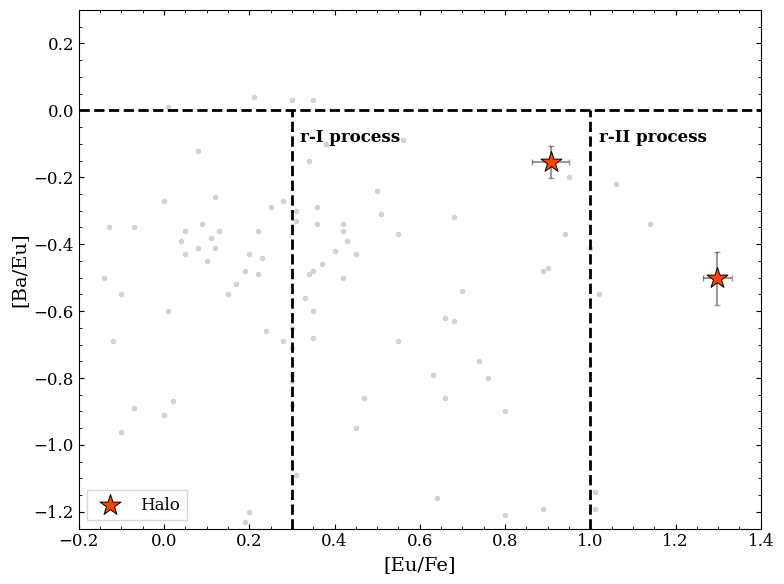

In [28]:
plt.figure(figsize=(8, 6))
# plt.scatter(prodisk_df['eufe'], prodisk_df['baeu'], color='limegreen', label='Prograde Disk', 
#             marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.scatter(halo_df['eufe'], halo_df['baeu'], color='orangered', label='Halo', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(halo_df['eufe'], halo_df['baeu'], xerr=halo_df['eufe_err'],
             yerr=halo_df['baeu_err'], fmt='o', color='black', zorder=9, alpha=0.4)
# plt.scatter(gse_df['eufe'], gse_df['baeu'], color='cornflowerblue', label='GSE', 
#             marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.scatter(eufe_lit_abund, baeu_lit_abund, color='lightgrey', marker='.', zorder=1)
plt.hlines(y=0, xmin=-0.2, xmax=1.4, color='black', linestyle='--', linewidth=2)
plt.vlines(x=0.3, ymax=0, ymin=-1.25, color='black', linestyle='--', linewidth=2)
plt.vlines(x=1.0, ymax=0, ymin=-1.25, color='black', linestyle='--', linewidth=2)

# rectangle = plt.Rectangle((0.3, 0), 0.7, -2.0, facecolor='grey', alpha=0.1, zorder=-10)
# plt.gca().add_patch(rectangle)
plt.text(0.32, -0.08, 'r-I process', fontsize=12, color='black', ha='left', va='center', weight='bold')

# rectangle = plt.Rectangle((1.0, 0), 0.7, -2.0, facecolor='grey', alpha=0.2, zorder=-10)
# plt.gca().add_patch(rectangle)
plt.text(1.02, -0.08, 'r-II process', fontsize=12, color='black', ha='left', va='center', weight='bold')

plt.xlabel('[Eu/Fe]')
plt.ylabel('[Ba/Eu]')
plt.xlim(-0.2, 1.4)
plt.ylim(-1.25, 0.3)
plt.legend(fancybox=False, loc='lower left')

plt.tight_layout()
# plt.savefig("/data/misfit/benlowe/xshooter/results/star_abunds/ba_eu_enhanced_v3.pdf", dpi=300, transparent=False, facecolor="white")
# plt.savefig("/data/misfit/benlowe/xshooter/results/star_abunds/ba_eu_enhanced_v3.png", dpi=300, transparent=False, facecolor="white")

In [34]:
prodisk_df

,star_id,eufe_ul,feh,feh_err,ul
0,ra_0103-7050_s163,1.551252,-2.316444,0.135492,Y
1,ra_0834-5220_s316,1.771755,-2.623191,0.381895,Y
2,ra_1648-0653_s38,1.208829,-2.402750,0.081063,Y


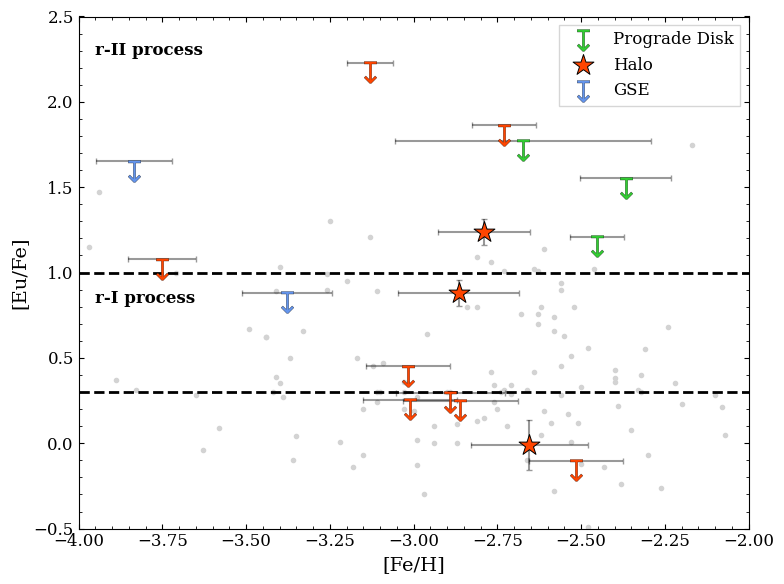

In [63]:
plt.figure(figsize=(8, 6))

for pro_entry in prodisk_df.iterrows():
    if pro_entry[1]['ul'] == 'Y':
        leg_pro = plt.scatter(pro_entry[1]['feh'] - 0.05, pro_entry[1]['eufe_ul'] - 0.055, color='limegreen', marker='${↧}$', s=250, 
                    linewidths=0.2, edgecolor='black', label='Prograde Disk', zorder=3)
        plt.errorbar(pro_entry[1]['feh'] - 0.05, pro_entry[1]['eufe_ul'], 
            xerr=pro_entry[1]['feh_err'], fmt='none', color='black', zorder=2, alpha=0.4)    
    else:
        plt.scatter(pro_entry[1]['feh'], pro_entry[1]['eufe'], color='limegreen', label='Prograde Disk', 
                    marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
        plt.errorbar(pro_entry[1]['feh'], pro_entry[1]['eufe'], xerr=pro_entry[1]['feh_err'],
                     yerr=pro_entry[1]['eufe_err'], fmt='o', color='black', zorder=9, alpha=0.4)
  
  
for halo_entry in halo_df.iterrows():
    if halo_entry[1]['ul'] == 'Y':
        plt.scatter(halo_entry[1]['feh'] - 0.05, halo_entry[1]['eufe_ul'] - 0.055, color='orangered', marker='${↧}$', s=250, 
                    linewidths=0.2, edgecolor='black', label='Halo', zorder=3)
        plt.errorbar(halo_entry[1]['feh'] - 0.05, halo_entry[1]['eufe_ul'], 
            xerr=halo_entry[1]['feh_err'], fmt='none', color='black', zorder=2, alpha=0.4)    
    else:
        leg_hal = plt.scatter(halo_entry[1]['feh'], halo_entry[1]['eufe'], color='orangered', label='Halo', 
                    marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
        plt.errorbar(halo_entry[1]['feh'], halo_entry[1]['eufe'], xerr=halo_entry[1]['feh_err'],
                     yerr=halo_entry[1]['eufe_err'], fmt='o', color='black', zorder=9, alpha=0.4)
        
        
for gse_entry in gse_df.iterrows():
    if gse_entry[1]['ul'] == 'Y':
        leg_gse = plt.scatter(gse_entry[1]['feh'] - 0.05, gse_entry[1]['eufe_ul'] - 0.055, color='cornflowerblue', marker='${↧}$', s=250, 
                    linewidths=0.2, edgecolor='black', label='GSE', zorder=3)
        plt.errorbar(gse_entry[1]['feh'] - 0.05, gse_entry[1]['eufe_ul'], 
            xerr=gse_entry[1]['feh_err'], fmt='none', color='black', zorder=2, alpha=0.4)    
    else:
        plt.scatter(gse_entry[1]['feh'], gse_entry[1]['eufe'], color='cornflowerblue', label='GSE', 
                    marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
        plt.errorbar(gse_entry[1]['feh'], gse_entry[1]['eufe'], xerr=gse_entry[1]['feh_err'],
                     yerr=gse_entry[1]['eufe_err'], fmt='o', color='black', zorder=9, alpha=0.4)     
# plt.scatter(halo_df['feh'], halo_df['eufe'], color='orangered', label='Halo', 
#             marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
# plt.errorbar(halo_df['feh'], halo_df['eufe'], xerr=halo_df['feh_err'],
#              yerr=halo_df['eufe_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(euII_lit_abund['feh'], euII_lit_abund['abund'], color='lightgrey', marker='.', zorder=1)

plt.hlines(y=0.3, xmin=-4, xmax=-1.0, color='black', linestyle='--', linewidth=2)
plt.hlines(y=1, xmin=-4, xmax=-1.0, color='black', linestyle='--', linewidth=2)

plt.text(-3.95, 0.85, 'r-I process', fontsize=12, color='black', ha='left', va='center', weight='bold')
plt.text(-3.95, 2.3, 'r-II process', fontsize=12, color='black', ha='left', va='center', weight='bold')

plt.legend(fancybox=False, handles = [leg_pro, leg_hal, leg_gse])
plt.xlim(-4, -2.0)
plt.ylim(-0.5, 2.5)
plt.xlabel('[Fe/H]')
plt.ylabel('[Eu/Fe]')

plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/results/star_abunds/eu_rprocess_v2.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/results/star_abunds/eu_rprocess_v2.png", dpi=300, transparent=False, facecolor="white")

Plotting [Ba/H] vs [Sr/Ba]

In [32]:
ba_II_abunds[ba_II_abunds['star_id'] == 'ra_1658-2454_s22']

,star_id,teff,logg,vmic,vsini,feh,feh_err,el,detection,upper_limit_xfe,...,bestfit_abund_loggerr_xfe,bestfit_abund_loggerr_xh,bestfit_abund_vmicerr_xfe,bestfit_abund_vmicerr_xh,Jp,Jtot,Jz,Jr,zmax,orbit


In [ ]:
prodisk_list = []
halo_list = []
gse_list = []
all_list = []

for entry in sr_II_abunds.iterrows():
    if entry[1]['detection'] == 'Y':
        star_id = entry[1]['star_id']
        bafe_entry = ba_II_abunds[ba_II_abunds['star_id'] == star_id]
        orb = entry[1]['orbit']
        if bafe_entry['detection'].values[0] == 'Y':
            sr_vals = entry[1]['bestfit_abund_xfe']
            sr_errs = entry[1]['bestfit_abund_comberr_xfe']
            ba_vals = ba_II_abunds[ba_II_abunds['star_id'] == star_id]['bestfit_abund_xfe'].values[0]
            ba_xh_vals = ba_II_abunds[ba_II_abunds['star_id'] == star_id]['bestfit_abund_xh'].values[0]
            ba_errs = ba_II_abunds[ba_II_abunds['star_id'] == star_id]['bestfit_abund_comberr_xfe'].values[0]
            ba_xh_errs = ba_II_abunds[ba_II_abunds['star_id'] == star_id]['bestfit_abund_comberr_xh'].values[0]
            feh_vals = entry[1]['feh']
            feh_errs = entry[1]['feh_err']
            
            srba_vals = sr_vals - ba_vals
            srba_errs = np.sqrt(sr_errs**2 + ba_errs**2)
            
            eufe_entry = eu_II_abunds[eu_II_abunds['star_id'] == star_id]
            if bafe_entry['detection'].values[0] == 'Y':
                eu_vals = eu_II_abunds[eu_II_abunds['star_id'] == star_id]['bestfit_abund_xfe'].values[0]
                eu_errs = eu_II_abunds[eu_II_abunds['star_id'] == star_id]['bestfit_abund_comberr_xfe'].values[0]
                baeu_vals = ba_vals - eu_vals
                baeu_errs = np.sqrt(sr_errs**2 + eu_errs**2)
                
                print(star_id)
                print(baeu_vals, baeu_errs)
            
            all_dict = {'star_id': star_id, 'srfe': sr_vals, 'bafe': ba_vals, 'srfe_err': sr_errs,
                                'bafe_err': ba_errs, 'srba': srba_vals, 'srba_err': srba_errs, 'feh': feh_vals, 'feh_err': feh_errs,
                                'bah': ba_xh_vals, 'bah_err': ba_xh_errs}
            all_list.append(all_dict)
            
            if orb == 'pro_disk':
                prodisk_dict = {'star_id': star_id, 'srfe': sr_vals, 'bafe': ba_vals, 'srfe_err': sr_errs,
                                'bafe_err': ba_errs, 'srba': srba_vals, 'srba_err': srba_errs, 'feh': feh_vals, 'feh_err': feh_errs,
                                'bah': ba_xh_vals, 'bah_err': ba_xh_errs}
                prodisk_list.append(prodisk_dict)
            elif orb == 'halo':
                halo_dict = {'star_id': star_id, 'srfe': sr_vals, 'bafe': ba_vals, 'srfe_err': sr_errs,
                                'bafe_err': ba_errs, 'srba': srba_vals, 'srba_err': srba_errs, 'feh': feh_vals, 'feh_err': feh_errs,
                                'bah': ba_xh_vals, 'bah_err': ba_xh_errs}
                halo_list.append(halo_dict)
            elif orb == 'gse':
                gse_dict = {'star_id': star_id, 'srfe': sr_vals, 'bafe': ba_vals, 'srfe_err': sr_errs,
                                'bafe_err': ba_errs, 'srba': srba_vals, 'srba_err': srba_errs, 'feh': feh_vals, 'feh_err': feh_errs,
                                'bah': ba_xh_vals, 'bah_err': ba_xh_errs}
                gse_list.append(gse_dict)                
                
        
                
prodisk_df = pd.DataFrame(prodisk_list)
halo_df = pd.DataFrame(halo_list)
gse_df = pd.DataFrame(gse_list)
all_df = pd.DataFrame(all_list)

# Doing this for literature stars
srfe_lit_abund = srII_lit_abund['abund'].to_numpy()
bafe_lit_abund = baII_lit_abund['abund'].to_numpy()
bah_lit_abund = baII_lit_abund['abund_xh'].to_numpy()
srba_lit_abund = srfe_lit_abund - bafe_lit_abund

ra_0103-7050_s163
ra_0103-7050_s163
2.3636172583951724 0.07446503490937893
ra_1648-0653_s38
ra_1648-0653_s38
-1.3959317394570316 0.09174406286453264
ra_1604-2712_s24
ra_1604-2712_s24
2.9323805292642677 0.4814775960583178
ra_0834-5220_s316
ra_0834-5220_s316
-1.917924066695731 0.0772196358935509
ra_1752-4300_s214
ra_1752-4300_s214
-0.5750546008105988 0.12404856848359273
ra_1624-2150_s278
ra_1656-1433_s143
ra_1656-1433_s143
-0.5021100979044975 0.050148230523072074
ra_1752-4300_s269
ra_1752-4300_s269
1.931404680915143 1.760221646150059
ra_1658-2454_s22
ra_1658-2454_s22
2.279681699068429 0.11224095917116983
ra_1853-3255_s45
ra_1853-3255_s45
-0.15565980478508645 0.08529663626878033
ra_1752-4300_s6
ra_1752-4300_s6
-1.0455263384954658 0.11352041642675607
ra_1709-2130_s102
ra_1709-2130_s102
-1.473805982056125 0.09667575545914583
ra_1604-2712_s292
ra_1633-2814_s130
ra_1659-2154_s114
ra_1659-2154_s114
-1.43472673279962 0.0966584155602771
ra_1633-2814_s284


In [17]:
# Making table for paper
srba_tab = all_df[['star_id', 'bah', 'bah_err', 'srba', 'srba_err']]

dict_list = []
for star in srba_tab.iterrows():
    
    srba_val = f"${star[1]['srba']:.2f} \pm {star[1]['srba_err']:.2f}$"
    bah_val = f"${star[1]['bah']:.2f} \pm {star[1]['bah_err']:.2f}$"

    srba_dict = {'Star': star[1]['star_id'], '[Ba/H]': bah_val, '[Sr/Ba]': srba_val}
    dict_list.append(srba_dict)
    
srba_final_tab = pd.DataFrame(dict_list)
srba_final_tab.sort_values(by='Star', inplace=True)

print(srba_final_tab.to_latex(index=False))




\begin{tabular}{lll}
\toprule
Star & [Ba/H] & [Sr/Ba] \\
\midrule
ra_0103-7050_s163 & $-2.82 \pm 0.07$ & $0.50 \pm 0.10$ \\
ra_0834-5220_s316 & $-2.91 \pm 0.12$ & $0.48 \pm 0.13$ \\
ra_1604-2712_s24 & $-3.34 \pm 0.05$ & $0.54 \pm 0.11$ \\
ra_1648-0653_s38 & $-3.32 \pm 0.12$ & $0.85 \pm 0.14$ \\
ra_1656-1433_s143 & $-2.00 \pm 0.07$ & $0.35 \pm 0.08$ \\
ra_1658-2454_s22 & $-4.14 \pm 0.03$ & $0.75 \pm 0.10$ \\
ra_1659-2154_s114 & $-4.70 \pm 0.06$ & $-0.12 \pm 0.07$ \\
ra_1709-2130_s102 & $-4.44 \pm 0.08$ & $0.47 \pm 0.11$ \\
ra_1752-4300_s214 & $-3.42 \pm 0.04$ & $0.83 \pm 0.09$ \\
ra_1752-4300_s269 & $-4.46 \pm 0.04$ & $0.24 \pm 0.08$ \\
ra_1752-4300_s6 & $-4.16 \pm 0.04$ & $0.23 \pm 0.09$ \\
ra_1853-3255_s45 & $-2.15 \pm 0.02$ & $-0.42 \pm 0.08$ \\
\bottomrule
\end{tabular}



In [39]:
print(np.nanmean(srba_lit_abund))
print(np.nanstd(srba_lit_abund))

print(np.nanmean(all_df['srba']))
print(np.nanstd(all_df['srba']))

0.11266958212206869
0.5951734095879577
0.40365343452286245
0.38143929138569777


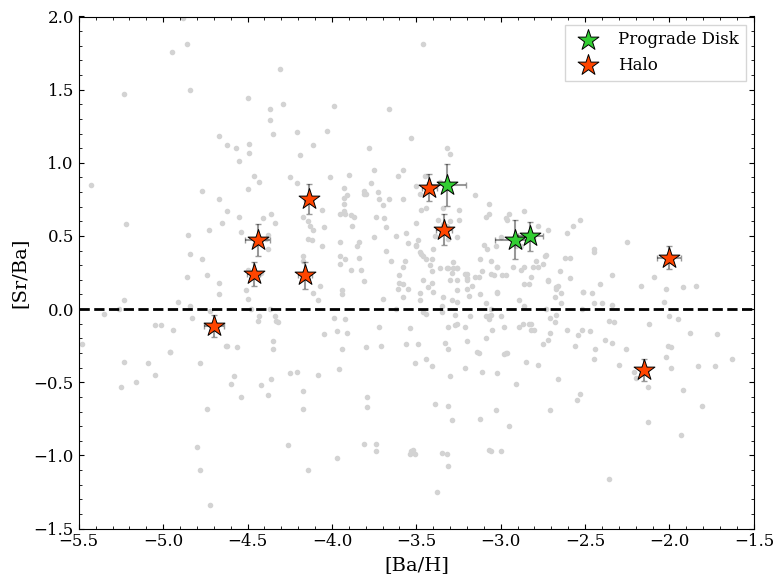

In [19]:
plt.figure(figsize=(8, 6))
plt.scatter(bah_lit_abund, srba_lit_abund, c="lightgrey", marker='.', zorder=1)
plt.scatter(prodisk_df['bah'], prodisk_df['srba'], color='limegreen', label='Prograde Disk', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(prodisk_df['bah'], prodisk_df['srba'], xerr=prodisk_df['bah_err'],
             yerr=prodisk_df['srba_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(halo_df['bah'], halo_df['srba'], color='orangered', label='Halo', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(halo_df['bah'], halo_df['srba'], xerr=halo_df['bah_err'],
             yerr=halo_df['srba_err'], fmt='o', color='black', zorder=9, alpha=0.4)
# plt.scatter(gse_df['feh'], gse_df['srba'], color='cornflowerblue', label='GSE', 
#             marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
# plt.errorbar(gse_df['feh'], gse_df['srba'], xerr=gse_df['feh_err'],
#              yerr=gse_df['srba_err'], fmt='o', color='black', zorder=9, alpha=0.4)


plt.axhline(y=0, color='black', linestyle='--', linewidth=2, zorder=2)
plt.xlim(-5.5, -1.5)
plt.ylim(-1.5, 2.0)

plt.legend(fancybox=False)
plt.xlabel('[Ba/H]')
plt.ylabel('[Sr/Ba]')
plt.tight_layout()

plt.savefig("/data/misfit/benlowe/xshooter/results/star_abunds/srba_plot_v3.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/results/star_abunds/srba_plot_v3.png", dpi=300, transparent=False, facecolor="white")


### α-enhanced stars

In [24]:
mg_I_abunds

,star_id,teff,logg,vmic,vsini,feh,feh_err,el,detection,upper_limit_xfe,...,bestfit_abund_loggerr_xfe,bestfit_abund_loggerr_xh,bestfit_abund_vmicerr_xfe,bestfit_abund_vmicerr_xh,Jp,Jtot,Jz,Jr,zmax,orbit
11,ra_0103-7050_s163,6298.806689,4.492229,1.253413,0,-2.312521,0.097705,Mg_I,Y,NaN,...,0.143966,0.143966,0.043421,0.043421,1191.012215,1.198272e+03,88.491505,9.754294e+01,2.132239,pro_disk
26,ra_1648-0653_s38,6039.830368,3.646778,1.533073,0,-2.453756,0.097838,Mg_I,Y,NaN,...,0.094156,0.094156,0.078593,0.078593,1295.837964,1.297820e+03,71.690885,4.189520e-01,1.470769,pro_disk
41,ra_1604-2712_s24,5002.684528,1.891750,2.007753,0,-2.489450,0.145383,Mg_I,Y,NaN,...,0.119797,0.119797,0.097257,0.097257,-508.586881,6.654891e+02,370.549358,2.165831e+02,5.618895,halo
59,ra_0834-5220_s316,5959.304567,4.286104,1.246679,0,-2.618883,0.130954,Mg_I,Y,NaN,...,0.124676,0.124676,0.010127,0.010127,938.289662,1.009217e+03,48.475280,3.684863e+02,1.824720,pro_disk
74,ra_1752-4300_s214,4853.568748,1.552000,2.149283,0,-2.739103,0.123195,Mg_I,Y,NaN,...,0.083175,0.083175,0.093831,0.093831,914.584316,1.323654e+03,210.528491,9.334202e+02,7.915003,halo
91,ra_1624-2150_s278,6381.865006,3.973617,1.490113,0,-2.663590,0.095188,Mg_I,Y,NaN,...,0.155430,0.155430,0.064977,0.064977,849.634492,9.919699e+02,159.863856,4.863836e+02,4.521274,halo
105,ra_1656-1433_s143,4791.462397,1.406800,2.214264,0,-2.801119,0.165019,Mg_I,Y,NaN,...,0.056953,0.056953,0.087373,0.087373,194.053140,5.428655e+02,499.728841,8.554198e+01,4.361530,halo
121,ra_1752-4300_s269,4917.930552,1.682200,2.101033,0,-2.845002,0.134640,Mg_I,Y,NaN,...,0.063323,0.063323,0.070851,0.070851,11438.398252,1.951598e+07,343.039397,1.951598e+07,72.038029,halo
138,ra_1658-2454_s22,4852.253676,2.164886,1.673293,0,-2.861141,0.172676,Mg_I,Y,NaN,...,0.209631,0.209631,0.064822,0.064822,165.986919,3.408191e+02,222.753531,1.974508e+02,3.276006,halo
151,ra_1853-3255_s45,5033.857005,2.378863,1.678355,0,-2.901286,0.175413,Mg_I,Y,NaN,...,0.092189,0.092189,0.150797,0.150797,146.169821,3.116854e+02,271.314839,4.658758e+01,2.652041,halo


In [22]:
# Doing this for our stars
prodisk_list = []
halo_list = []
gse_list = []
all_list = []

for entry in mg_I_abunds.iterrows():
    star_id = entry[1]['star_id']
    orb = entry[1]['orbit']
    si_I_entry = si_I_abunds[si_I_abunds['star_id'] == star_id]
    ca_II_entry = ca_II_abunds[ca_II_abunds['star_id'] == star_id]
    ti_II_entry = ti_II_abunds[ti_II_abunds['star_id'] == star_id]
    
    mg_vals = entry[1]['bestfit_abund_xfe']
    mg_errs = entry[1]['bestfit_abund_comberr_xfe']
    si_vals = si_I_entry['bestfit_abund_xfe'].values[0]
    si_errs = si_I_entry['bestfit_abund_comberr_xfe'].values[0]
    ca_vals = ca_II_entry['bestfit_abund_xfe'].values[0]
    ca_errs = ca_II_entry['bestfit_abund_comberr_xfe'].values[0]
    ti_vals = ti_II_entry['bestfit_abund_xfe'].values[0]
    ti_errs = ti_II_entry['bestfit_abund_comberr_xfe'].values[0]
    
    
    # alpha_vals = np.average([mg_vals, si_vals, ca_vals, ti_vals])
    # alpha_errs = 1/4 * np.sqrt(mg_errs**2 + si_errs**2 + ca_errs**2 + ti_errs**2)
    
    # Calculating weighted average
    alpha_arr = np.array([mg_vals, si_vals, ca_vals, ti_vals])
    alpha_weights = 1 / np.array([mg_errs, si_errs, ca_errs, ti_errs])**2
    
    # Weighted mean
    alpha_vals = np.sum(alpha_weights * alpha_arr) / np.sum(alpha_weights)

    # Uncertainty of weighted mean
    alpha_errs = np.sqrt(1 / np.sum(alpha_weights))
    
    feh_vals = entry[1]['feh']
    feh_errs = entry[1]['feh_err']
    
    all_dict = {'star_id': star_id, 'alpha': alpha_vals, 'alpha_err': alpha_errs,
                'feh': feh_vals, 'feh_err': feh_errs, 'mg': mg_vals, 'mg_err': mg_errs,
                'si': si_vals, 'si_err': si_errs, 'ca': ca_vals, 'ca_err': ca_errs, 'ti': ti_vals, 'ti_err': ti_errs}
    all_list.append(all_dict)
    
    if orb == 'pro_disk':
        prodisk_dict = {'star_id': star_id, 'alpha': alpha_vals, 'alpha_err': alpha_errs,
                        'feh': feh_vals, 'feh_err': feh_errs}
        prodisk_list.append(prodisk_dict)
    elif orb == 'halo':
        halo_dict = {'star_id': star_id, 'alpha': alpha_vals, 'alpha_err': alpha_errs,
                        'feh': feh_vals, 'feh_err': feh_errs}
        halo_list.append(halo_dict)
    elif orb == 'gse':
        gse_dict = {'star_id': star_id, 'alpha': alpha_vals, 'alpha_err': alpha_errs,
                        'feh': feh_vals, 'feh_err': feh_errs}
        gse_list.append(gse_dict)
    
    print(f"{star_id} ([α/Fe] = {alpha_vals:.2f} ± {alpha_errs:.2f})")
    # if eu_II_entry['detection'].values[0] == 'Y':
    #     ba_vals = entry[1]['bestfit_abund_xfe']
    #     eu_vals = eu_II_abunds[eu_II_abunds['star_id'] == star_id]['bestfit_abund_xfe'].values[0]
        
    #     baeu_vals = ba_vals - eu_vals
    #     if eu_vals >= 0.3 and eu_vals <= 1.0 and baeu_vals < 0:
    #         print(f"{star_id} ([Eu/Fe] = {eu_vals:.2f} and [Ba/Eu] = {baeu_vals:.2f})")

prodisk_df = pd.DataFrame(prodisk_list)
halo_df = pd.DataFrame(halo_list)
gse_df = pd.DataFrame(gse_list)
all_df = pd.DataFrame(all_list)

# Doing this for literature stars
mgI_list_stars = mgI_lit_abund['star_id'].to_numpy()
siI_list_stars = siI_lit_abund['star_id'].to_numpy()
caI_list_stars = caI_lit_abund['star_id'].to_numpy()
tiII_list_stars = tiII_lit_abund['star_id'].to_numpy()
alpha_lit_abund = []
for star in mgI_list_stars:
    if star in siI_list_stars and star in caI_list_stars and star in tiII_list_stars:
        mg_val = mgI_lit_abund[mgI_lit_abund['star_id'] == star]['abund'].values[0]
        si_val = siI_lit_abund[siI_lit_abund['star_id'] == star]['abund'].values[0]
        ca_val = caI_lit_abund[caI_lit_abund['star_id'] == star]['abund'].values[0]
        ti_val = tiII_lit_abund[tiII_lit_abund['star_id'] == star]['abund'].values[0]
        feh_val = mgI_lit_abund[mgI_lit_abund['star_id'] == star]['feh'].values[0]
        
        alpha_val = np.average([mg_val, si_val, ca_val, ti_val])
        alpha_lit_abund.append({'star_id': star, 'alpha': alpha_val, 'feh': feh_val})
        
alpha_lit_abund_df = pd.DataFrame(alpha_lit_abund)

ra_0103-7050_s163 ([α/Fe] = 0.18 ± 0.02)
ra_1648-0653_s38 ([α/Fe] = 0.27 ± 0.02)
ra_1604-2712_s24 ([α/Fe] = 0.29 ± 0.02)
ra_0834-5220_s316 ([α/Fe] = 0.37 ± 0.02)
ra_1752-4300_s214 ([α/Fe] = 0.39 ± 0.01)
ra_1624-2150_s278 ([α/Fe] = 0.25 ± 0.02)
ra_1656-1433_s143 ([α/Fe] = 0.36 ± 0.02)
ra_1752-4300_s269 ([α/Fe] = 0.14 ± 0.02)
ra_1658-2454_s22 ([α/Fe] = 0.34 ± 0.02)
ra_1853-3255_s45 ([α/Fe] = 0.25 ± 0.02)
ra_1752-4300_s6 ([α/Fe] = 0.35 ± 0.02)
ra_1709-2130_s102 ([α/Fe] = 0.36 ± 0.02)
ra_1604-2712_s292 ([α/Fe] = 0.25 ± 0.02)
ra_1633-2814_s130 ([α/Fe] = 0.32 ± 0.02)
ra_1659-2154_s114 ([α/Fe] = 0.27 ± 0.02)
ra_1633-2814_s284 ([α/Fe] = 0.50 ± 0.02)


In [72]:
print(prodisk_df['alpha'].mean(), prodisk_df['alpha'].std())
print(halo_df['alpha'].mean(), halo_df['alpha'].std())
print(gse_df['alpha'].mean(), gse_df['alpha'].std())

0.2719995612146911 0.0964304361212996
0.29530674968548404 0.07460328933067259
0.4094242922432044 0.12339532659325685


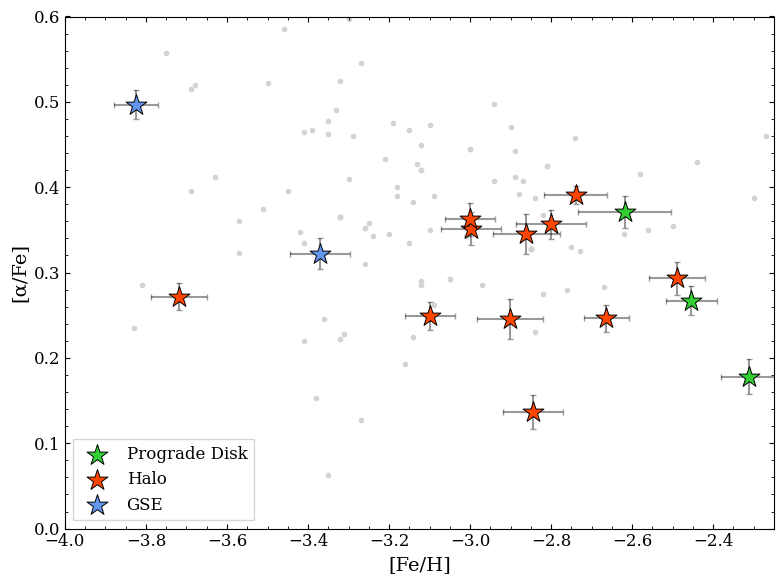

In [21]:
plt.figure(figsize=(8, 6))
plt.scatter(prodisk_df['feh'], prodisk_df['alpha'], color='limegreen', label='Prograde Disk', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(prodisk_df['feh'], prodisk_df['alpha'], xerr=prodisk_df['feh_err'],
             yerr=prodisk_df['alpha_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(halo_df['feh'], halo_df['alpha'], color='orangered', label='Halo', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(halo_df['feh'], halo_df['alpha'], xerr=halo_df['feh_err'],
             yerr=halo_df['alpha_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(gse_df['feh'], gse_df['alpha'], color='cornflowerblue', label='GSE', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(gse_df['feh'], gse_df['alpha'], xerr=gse_df['feh_err'],
             yerr=gse_df['alpha_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(alpha_lit_abund_df['feh'], alpha_lit_abund_df['alpha'], color='lightgrey', marker='.', zorder=1)
# plt.axhline(y=0.15, color='black', linestyle='--', linewidth=2)
# plt.axhline(y=0.4, color='black', linestyle='--', linewidth=2)
# # plt.axvline(x=0.3, ymax=0.955, color='black', linestyle='--', linewidth=2)
# # plt.axvline(x=1.0, ymax=0.955, color='black', linestyle='--', linewidth=2)

# # rectangle = plt.Rectangle((-4.0, 0.15), 1.8, -0.15, facecolor='grey', alpha=0.1, zorder=-10)
# # plt.gca().add_patch(rectangle)
# plt.text(-3.97, 0.13, 'α-poor', fontsize=12, color='black', ha='left', va='center', weight='bold')

# # rectangle = plt.Rectangle((-4.0, 0.4), 1.8, -0.25, facecolor='grey', alpha=0.1, zorder=-10)
# # plt.gca().add_patch(rectangle)
# plt.text(-3.97, 0.38, 'α-normal', fontsize=12, color='black', ha='left', va='center', weight='bold')

# # rectangle = plt.Rectangle((-4.0, 0.4), 1.8, 0.2, facecolor='grey', alpha=0.2, zorder=-10)
# # plt.gca().add_patch(rectangle)
# plt.text(-3.97, 0.58, 'α-rich', fontsize=12, color='black', ha='left', va='center', weight='bold')

plt.xlabel('[Fe/H]')
plt.ylabel('[α/Fe]')
plt.legend(fancybox=False, loc='lower left')

plt.xlim(-4, -2.25)
plt.ylim(0, 0.6)

plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/results/star_abunds/alpha_enhanced_v6.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/results/star_abunds/alpha_enhanced_v6.png", dpi=300, transparent=False, facecolor="white")

In [24]:
# Making table for paper
alpha_tab = all_df[['star_id', 'alpha', 'alpha_err']]

dict_list = []
for star in alpha_tab.iterrows():
    
    alpha_val = f"${star[1]['alpha']:.2f} \pm {star[1]['alpha_err']:.2f}$"

    alpha_dict = {'Star': star[1]['star_id'], '[Alpha/Fe]': alpha_val}
    dict_list.append(alpha_dict)
    
alpha_final_tab = pd.DataFrame(dict_list)
alpha_final_tab.sort_values(by='Star', inplace=True)

print(alpha_final_tab.to_latex(index=False))


\begin{tabular}{ll}
\toprule
Star & [Alpha/Fe] \\
\midrule
ra_0103-7050_s163 & $0.18 \pm 0.02$ \\
ra_0834-5220_s316 & $0.37 \pm 0.02$ \\
ra_1604-2712_s24 & $0.29 \pm 0.02$ \\
ra_1604-2712_s292 & $0.25 \pm 0.02$ \\
ra_1624-2150_s278 & $0.25 \pm 0.02$ \\
ra_1633-2814_s130 & $0.32 \pm 0.02$ \\
ra_1633-2814_s284 & $0.50 \pm 0.02$ \\
ra_1648-0653_s38 & $0.27 \pm 0.02$ \\
ra_1656-1433_s143 & $0.36 \pm 0.02$ \\
ra_1658-2454_s22 & $0.34 \pm 0.02$ \\
ra_1659-2154_s114 & $0.27 \pm 0.02$ \\
ra_1709-2130_s102 & $0.36 \pm 0.02$ \\
ra_1752-4300_s214 & $0.39 \pm 0.01$ \\
ra_1752-4300_s269 & $0.14 \pm 0.02$ \\
ra_1752-4300_s6 & $0.35 \pm 0.02$ \\
ra_1853-3255_s45 & $0.25 \pm 0.02$ \\
\bottomrule
\end{tabular}



In [23]:
all_df

,star_id,alpha,alpha_err,feh,feh_err,mg,mg_err,si,si_err,ca,ca_err,ti,ti_err
0,ra_0103-7050_s163,0.178105,0.020462,-2.312521,0.067078,0.218275,0.058176,0.328078,0.054974,0.143116,0.030615,0.143347,0.037926
1,ra_1648-0653_s38,0.267114,0.016894,-2.453756,0.063382,0.357492,0.050930,0.257574,0.054336,0.295306,0.021547,0.119476,0.039986
2,ra_1604-2712_s24,0.293259,0.019115,-2.489450,0.069695,0.411503,0.066692,0.510861,0.073590,0.263408,0.022026,0.273586,0.061312
3,ra_0834-5220_s316,0.370780,0.018911,-2.618883,0.115246,0.444565,0.054284,0.400929,0.058661,0.332847,0.034593,0.369199,0.027415
4,ra_1752-4300_s214,0.390802,0.010332,-2.739103,0.077677,0.399011,0.056880,0.541904,0.058739,0.393975,0.010814,0.052665,0.067842
5,ra_1624-2150_s278,0.246433,0.015905,-2.663590,0.056390,0.017904,0.062165,-0.048404,0.034768,0.303501,0.021918,0.480969,0.035679
6,ra_1656-1433_s143,0.356333,0.017235,-2.801119,0.086527,0.440273,0.046813,0.534247,0.083393,0.371322,0.020726,0.130981,0.047763
7,ra_1752-4300_s269,0.136726,0.020027,-2.845002,0.074637,0.323408,0.046237,-0.015155,0.118588,0.159364,0.025069,-0.173040,0.052464
8,ra_1658-2454_s22,0.344912,0.023355,-2.861141,0.081783,0.342363,0.085076,0.162252,0.091208,0.328995,0.027558,0.512468,0.062229
9,ra_1853-3255_s45,0.245361,0.023731,-2.901286,0.081281,0.183415,0.070700,0.297992,0.101439,0.260632,0.029106,0.209294,0.057929


Plotting the individual alpha-elements to see if trend is consistent

In [55]:
all_df

,star_id,alpha,alpha_err,feh,feh_err,mg,mg_err,si,si_err,ca,ti,ti_err
0,ra_0103-7050_s163,0.178105,0.020462,-2.312521,0.067078,0.218275,0.058176,0.328078,0.054974,0.143116,0.143347,0.037926
1,ra_1648-0653_s38,0.267114,0.016894,-2.453756,0.063382,0.357492,0.050930,0.257574,0.054336,0.295306,0.119476,0.039986
2,ra_1604-2712_s24,0.293259,0.019115,-2.489450,0.069695,0.411503,0.066692,0.510861,0.073590,0.263408,0.273586,0.061312
3,ra_0834-5220_s316,0.370780,0.018911,-2.618883,0.115246,0.444565,0.054284,0.400929,0.058661,0.332847,0.369199,0.027415
4,ra_1752-4300_s214,0.390802,0.010332,-2.739103,0.077677,0.399011,0.056880,0.541904,0.058739,0.393975,0.052665,0.067842
5,ra_1624-2150_s278,0.246433,0.015905,-2.663590,0.056390,0.017904,0.062165,-0.048404,0.034768,0.303501,0.480969,0.035679
6,ra_1656-1433_s143,0.356333,0.017235,-2.801119,0.086527,0.440273,0.046813,0.534247,0.083393,0.371322,0.130981,0.047763
7,ra_1752-4300_s269,0.136726,0.020027,-2.845002,0.074637,0.323408,0.046237,-0.015155,0.118588,0.159364,-0.173040,0.052464
8,ra_1658-2454_s22,0.344912,0.023355,-2.861141,0.081783,0.342363,0.085076,0.162252,0.091208,0.328995,0.512468,0.062229
9,ra_1853-3255_s45,0.245361,0.023731,-2.901286,0.081281,0.183415,0.070700,0.297992,0.101439,0.260632,0.209294,0.057929


0.06
0.07
0.10
0.04
0.15
0.20
0.12
0.17
0.09
0.04
0.14
0.17
0.09
0.17
0.19
0.07


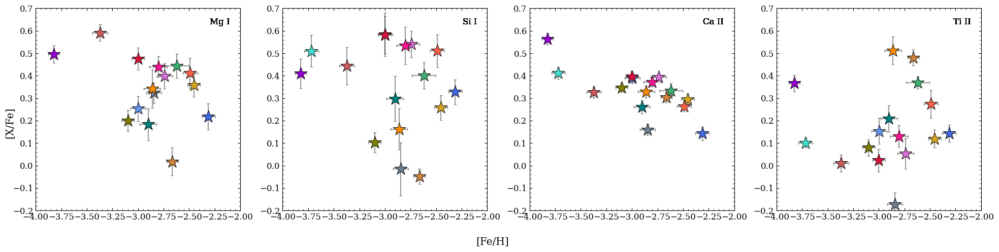

In [70]:
fig, axs = plt.subplots(1, 4, figsize=[20,5])

colors = [
    "royalblue",
    "goldenrod",
    "tomato",
    "mediumseagreen",
    "orchid",
    "peru",
    "deeppink",
    "slategray",
    "darkorange",
    "teal",
    "cornflowerblue",
    "crimson",
    "olive",
    "indianred",
    "turquoise",
    "darkviolet"
]


# For each star, plot its individual alpha abundance
for i, entry in enumerate(all_df.iterrows()):
    star_id = entry[1]['star_id']
    feh = entry[1]['feh']
    alpha = entry[1]['alpha']
    mg = entry[1]['mg']
    si = entry[1]['si']
    ca = entry[1]['ca']
    ti = entry[1]['ti']
    
    mean_alpha = np.mean(np.array([mg, si, ca, ti]))
    mean_difference = np.mean(np.abs(np.array([mg, si, ca, ti]) - mean_alpha))
    print(f'{mean_difference:.2f}')
    
    axs[0].scatter(feh, mg, color=colors[i], marker='*', s=350, edgecolor='black', zorder=10, linewidths=0.7)
    axs[0].errorbar(feh, mg, xerr=entry[1]['feh_err'], yerr=entry[1]['mg_err'], fmt='o', color='black', zorder=9, alpha=0.4)
    axs[0].set_xlim(right=-2.0, left=-4.0)
    axs[0].set_ylim(top=0.7, bottom=-0.2)
    axs[0].text(-2.1, 0.63, 'Mg I', ha='right')
    
    axs[1].scatter(feh, si, color=colors[i], marker='*', s=350, edgecolor='black', zorder=10, linewidths=0.7)
    axs[1].errorbar(feh, si, xerr=entry[1]['feh_err'], yerr=entry[1]['si_err'], fmt='o', color='black', zorder=9, alpha=0.4)
    axs[1].set_xlim(right=-2.0, left=-4.0)
    axs[1].set_ylim(top=0.7, bottom=-0.2)
    axs[1].text(-2.1, 0.63, 'Si I', ha='right')
    
    axs[2].scatter(feh, ca, color=colors[i], marker='*', s=350, edgecolor='black', zorder=10, linewidths=0.7)
    axs[2].errorbar(feh, ca, xerr=entry[1]['feh_err'], yerr=entry[1]['ca_err'], fmt='o', color='black', zorder=9, alpha=0.4)
    axs[2].set_xlim(right=-2.0, left=-4.0)
    axs[2].set_ylim(top=0.7, bottom=-0.2)
    axs[2].text(-2.1, 0.63, 'Ca II', ha='right')
  
    axs[3].scatter(feh, ti, color=colors[i], marker='*', s=350, edgecolor='black', zorder=10, linewidths=0.7)
    axs[3].errorbar(feh, ti, xerr=entry[1]['feh_err'], yerr=entry[1]['ti_err'], fmt='o', color='black', zorder=9, alpha=0.4)
    axs[3].set_xlim(right=-2.0, left=-4.0)
    axs[3].set_ylim(top=0.7, bottom=-0.2)
    axs[3].text(-2.1, 0.63, 'Ti II', ha='right')

fig.supxlabel('[Fe/H]')
fig.supylabel('[X/Fe]')
plt.tight_layout()

### C-enhanced stars

In [21]:
prodisk_list = []
halo_list = []
gse_list = []

prodisk_ul_list = []
halo_ul_list = []
gse_ul_list = []

c_corrs_df = pd.read_csv('/data/misfit/benlowe/xshooter/C_evolve_corrections/cfe_corrections.csv')

for entry in c_I_abunds.iterrows():
    orb = entry[1]['orbit']
    if entry[1]['detection'] == 'Y':
        star_id = entry[1]['star_id']
        feh_vals = entry[1]['feh']
        feh_errs = entry[1]['feh_err']
        
        c_vals = entry[1]['bestfit_abund_xfe']
        c_errs = entry[1]['bestfit_abund_comberr_xfe']
        
        c_corr = c_corrs_df[c_corrs_df['star_id'] == star_id]['cfe_corr'].values[0]
        c_orig = c_vals - c_corr
        
        if orb == 'pro_disk':
            prodisk_dict = {'star_id': star_id, 'cfe': c_vals, 'cfe_err': c_errs, 'cfe_uncorr': c_orig,
                            'feh': feh_vals, 'feh_err': feh_errs}
            prodisk_list.append(prodisk_dict)
        elif orb == 'halo':
            halo_dict = {'star_id': star_id, 'cfe': c_vals, 'cfe_err': c_errs, 'cfe_uncorr': c_orig,
                            'feh': feh_vals, 'feh_err': feh_errs}
            halo_list.append(halo_dict)
        elif orb == 'gse':
            gse_dict = {'star_id': star_id, 'cfe': c_vals, 'cfe_err': c_errs, 'cfe_uncorr': c_orig,
                            'feh': feh_vals, 'feh_err': feh_errs}
            gse_list.append(gse_dict)
            
    elif entry[1]['detection'] == 'N':
        star_id = entry[1]['star_id']
        feh_vals = entry[1]['feh']
        feh_errs = entry[1]['feh_err']
        
        c_vals = entry[1]['upper_limit_xfe']
        # c_errs = entry[1]['upper_limit_tefferr_xfe']
        
        if orb == 'pro_disk':
            prodisk_ul_dict = {'star_id': star_id, 'cfe_ul': c_vals,
                               'feh': feh_vals, 'feh_err': feh_errs}
            prodisk_ul_list.append(prodisk_ul_dict)
        elif orb == 'halo':
            halo_ul_dict = {'star_id': star_id, 'cfe_ul': c_vals,
                            'feh': feh_vals, 'feh_err': feh_errs}
            halo_ul_list.append(halo_ul_dict)
        elif orb == 'gse':
            gse_ul_dict = {'star_id': star_id, 'cfe_ul': c_vals,
                           'feh': feh_vals, 'feh_err': feh_errs}
            gse_ul_list.append(gse_ul_dict)
            
prodisk_df = pd.DataFrame(prodisk_list)
halo_df = pd.DataFrame(halo_list)
gse_df = pd.DataFrame(gse_list)

prodisk_ul_df = pd.DataFrame(prodisk_ul_list)
halo_ul_df = pd.DataFrame(halo_ul_list)
gse_ul_df = pd.DataFrame(gse_ul_list)


# Doing this for literature stars
cfe_lit_abund = cI_lit_abund['abund'].to_numpy()
feh_lit_abund = cI_lit_abund['feh'].to_numpy()

In [138]:
halo_df

,star_id,cfe,cfe_err,feh,feh_err
0,ra_1604-2712_s24,0.013734,0.227440,-2.466047,0.140045
1,ra_1656-1433_s143,0.358195,0.229868,-2.789339,0.136585
2,ra_1658-2454_s22,-0.345457,0.231005,-2.839827,0.163973
3,ra_1659-2154_s114,0.128789,0.229228,-3.700563,0.101061
4,ra_1709-2130_s102,0.062062,0.230291,-2.967078,0.125340
5,ra_1752-4300_s214,0.781197,0.223999,-2.654234,0.173620
6,ra_1752-4300_s269,0.323914,0.233364,-2.810264,0.170590
7,ra_1752-4300_s6,0.562016,0.235134,-2.960823,0.140897
8,ra_1853-3255_s45,0.164000,0.226076,-2.865494,0.180771


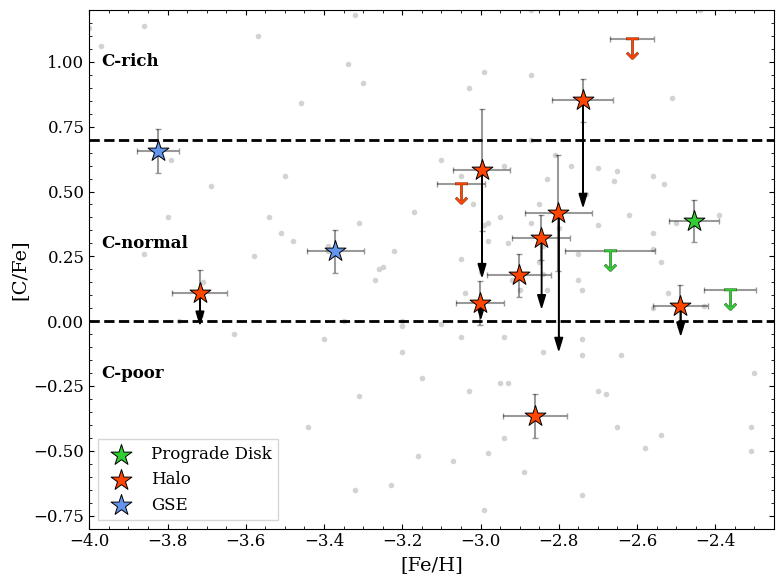

In [22]:
plt.figure(figsize=(8, 6))

# Plotting the data points
plt.scatter(prodisk_df['feh'], prodisk_df['cfe'], color='limegreen', label='Prograde Disk', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(prodisk_df['feh'], prodisk_df['cfe'], xerr=prodisk_df['feh_err'],
             yerr=prodisk_df['cfe_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(halo_df['feh'], halo_df['cfe'], color='orangered', label='Halo', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(halo_df['feh'], halo_df['cfe'], xerr=halo_df['feh_err'],
             yerr=halo_df['cfe_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(gse_df['feh'], gse_df['cfe'], color='cornflowerblue', label='GSE', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(gse_df['feh'], gse_df['cfe'], xerr=gse_df['feh_err'],
             yerr=gse_df['cfe_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(feh_lit_abund, cfe_lit_abund, color='lightgrey', marker='.', zorder=1)
plt.axhline(y=0, color='black', linestyle='--', linewidth=2)
plt.axhline(y=0.7, color='black', linestyle='--', linewidth=2)

# Plotting the un-corrected data as arrows
for xi, yi1, yi2 in zip(halo_df['feh'], halo_df['cfe'], halo_df['cfe_uncorr']):
    dy = yi2 - yi1
    
    # If correction is too small, then won't plot
    if abs(dy) < 0.05:
        continue
    else:
        # Arrow position slightly off from marker, so applying 0.001 offset
        plt.arrow(xi+0.001, yi1, 0, dy, head_width=0.02, head_length=0.05, length_includes_head=True, color='black')


for xi, yi1, yi2 in zip(gse_df['feh'], gse_df['cfe'], gse_df['cfe_uncorr']):
    dy = yi2 - yi1
    
    # If correction is too small, then won't plot
    if abs(dy) < 0.05:
        continue
    else:
        # Arrow position slightly off from marker, so applying 0.001 offset
        plt.arrow(xi+0.001, yi1, 0, dy, head_width=0.02, head_length=0.05, length_includes_head=True, color='black')


# Plotting the upper-limits
plt.scatter(prodisk_ul_df['feh'] - 0.05, prodisk_ul_df['cfe_ul'] - 0.035, color='limegreen', zorder=5, 
            marker='${↧}$', s=250, linewidths=0.2, edgecolor='black')
plt.errorbar(prodisk_ul_df['feh'] - 0.05, prodisk_ul_df['cfe_ul'], 
            xerr=prodisk_ul_df['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)
plt.scatter(halo_ul_df['feh'] + 0.05, halo_ul_df['cfe_ul'] - 0.035, color='orangered', zorder=5, 
            marker='${↧}$', s=250, linewidths=0.2, edgecolor='black')
plt.errorbar(halo_ul_df['feh'] + 0.05, halo_ul_df['cfe_ul'], 
            xerr=halo_ul_df['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)
# plt.scatter(gse_ul_df['feh'] + 0.15, gse_ul_df['cfe_ul'] - 0.05, color='cornflowerblue', zorder=5, 
#             marker='${↧}$', s=250, linewidths=0.2, edgecolor='black')
# plt.errorbar(gse_ul_df['feh'] + 0.15, gse_ul_df['cfe_ul'] + 0.12, 
#             xerr=gse_ul_df['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)




# plt.axvline(x=0.3, ymax=0.955, color='black', linestyle='--', linewidth=2)
# plt.axvline(x=1.0, ymax=0.955, color='black', linestyle='--', linewidth=2)

# rectangle = plt.Rectangle((-4.0, 0.15), 1.8, -0.15, facecolor='grey', alpha=0.1, zorder=-10)
# plt.gca().add_patch(rectangle)
plt.text(-3.97, -0.2, 'C-poor', fontsize=12, color='black', ha='left', va='center', weight='bold')

# rectangle = plt.Rectangle((-4.0, 0.7), 1.8, -0.7, facecolor='grey', alpha=0.1, zorder=-10)
# plt.gca().add_patch(rectangle)
plt.text(-3.97, 0.3, 'C-normal', fontsize=12, color='black', ha='left', va='center', weight='bold')

# rectangle = plt.Rectangle((-4.0, 0.7), 1.8, 0.5, facecolor='grey', alpha=0.2, zorder=-10)
# plt.gca().add_patch(rectangle)
plt.text(-3.97, 1.0, 'C-rich', fontsize=12, color='black', ha='left', va='center', weight='bold')

plt.xlabel('[Fe/H]')
plt.ylabel('[C/Fe]')
plt.legend(fancybox=False)

plt.xlim(-4, -2.25)
plt.ylim(-0.8, 1.2)

plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/results/star_abunds/c_enhanced_v6.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/results/star_abunds/c_enhanced_v6.png", dpi=300, transparent=False, facecolor="white")

/tmp/ipykernel_987638/2110566624.py:4: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  plt.scatter(na_I_abunds['feh'], na_I_abunds['bestfit_abund_xfe'], marker='*', color='darkred', s=250, vmin=-4.0, vmax=-2.3, edgecolors='black')


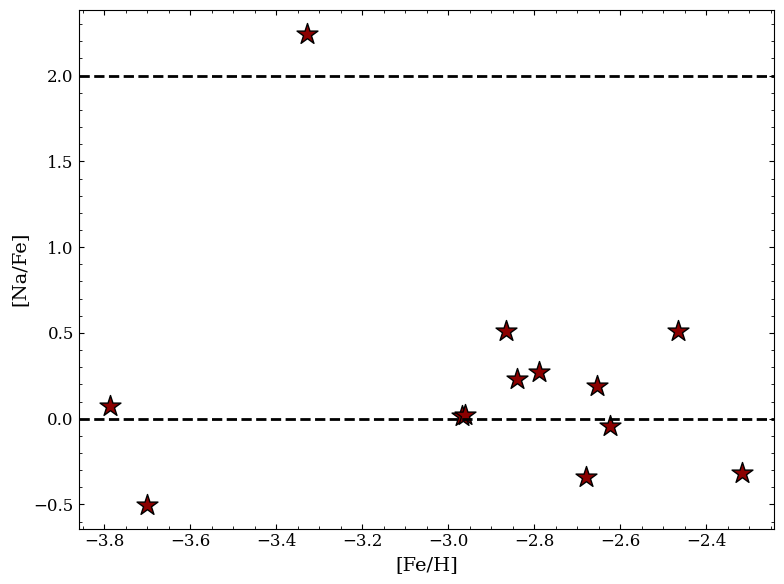

In [153]:
# Plotting [Fe/H] vs [Na/Fe]
plt.figure(figsize=[8,6])

plt.scatter(na_I_abunds['feh'], na_I_abunds['bestfit_abund_xfe'], marker='*', color='darkred', s=250, vmin=-4.0, vmax=-2.3, edgecolors='black')
plt.xlabel('[Fe/H]')
plt.ylabel('[Na/Fe]')
plt.axhline(y=0, color='black', linestyle='--', linewidth=2)
# plt.axhline(y=1.0, color='black', linestyle='--', linewidth=2)
plt.axhline(y=2, color='black', linestyle='--', linewidth=2)

plt.tight_layout()

plt.savefig("/data/misfit/benlowe/xshooter/results/star_abunds/na_enhanced.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/results/star_abunds/na_enhanced.png", dpi=300, transparent=False, facecolor="white")

## Comparing parameters from 2dF with X-Shooter, alongside chemical abundances amongst different code iterations

#### Comparing metallicities from the old approach to the new approach with AAT

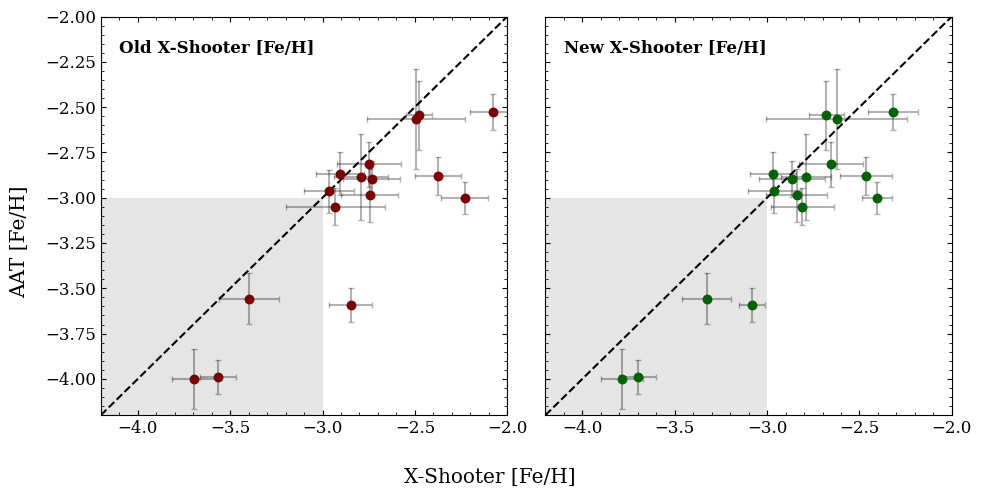

In [2]:
# Loading in the data
# Old X-Shooter data
xshooter_old_data= pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/tests/perturb/teff_100K/stellar_params.csv')
xshooter_old_feh = xshooter_old_data['Fe_it2'].to_numpy()
xshooter_old_feh_err = xshooter_old_data['Fe_error'].to_numpy()

# New X-Shooter data
xshooter_new_data= pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final/stellar_params.csv')
xshooter_new_feh = xshooter_new_data['Fe_it2'].to_numpy()
xshooter_new_feh_err = xshooter_new_data['Fe_tefferr'].to_numpy()

# AAT data
aat_data= pd.read_csv('/data/misfit/benlowe/xshooter/stellar_params/emp_params_FINAL.csv')
aat_feh = aat_data['z'].to_numpy()
aat_feh_err = aat_data['randz_std'].to_numpy()



# Plotting
fig, axs = plt.subplots(1, 2, figsize=[10,5], tight_layout=True, sharey=True, sharex=True)
axs[0].set_xlim(-4.2, -2.0)
axs[0].set_ylim(-4.2, -2.0)
fig.supxlabel('X-Shooter [Fe/H]')
fig.supylabel('AAT [Fe/H]')

# Comparing old X-Shooter data to AAT data
axs[0].scatter(xshooter_old_feh, aat_feh, color='maroon', zorder=10)
axs[0].errorbar(xshooter_old_feh, aat_feh, xerr=xshooter_old_feh_err, yerr=aat_feh_err, fmt='o', color='black', alpha=0.3, zorder=1)
axs[0].plot([-4.2, -2.0], [-4.2, -2.0], color='black', linestyle='--')
axs[0].text(-4.1, -2.2, 'Old X-Shooter [Fe/H]', fontsize=12, fontweight='bold')

rectangle = plt.Rectangle((-4.2, -4.2), 1.2, 1.2, facecolor='grey', alpha=0.2, zorder=-10)
axs[0].add_patch(rectangle)

# Comparing new X-Shooter data to AAT data
axs[1].scatter(xshooter_new_feh, aat_feh, color='darkgreen', zorder=10)
axs[1].errorbar(xshooter_new_feh, aat_feh, xerr=xshooter_new_feh_err, yerr=aat_feh_err, fmt='o', color='black', alpha=0.3, zorder=1)
axs[1].plot([-4.2, -2.0], [-4.2, -2.0], color='black', linestyle='--')
axs[1].text(-4.1, -2.2, 'New X-Shooter [Fe/H]', fontsize=12, fontweight='bold')

rectangle = plt.Rectangle((-4.2, -4.2), 1.2, 1.2, facecolor='grey', alpha=0.2, zorder=-10)
axs[1].add_patch(rectangle)


# plt.savefig("/data/misfit/benlowe/results/aat_comparision/aat_xshooter_feh_oldvsnew.png", dpi=300, transparent=False, facecolor="white")


#### Comparing metallicities from X-Shooter (the new approach from above) with AAT

In [ ]:
# Setting up subplot
fig = plt.figure(figsize=[7,7])
gs = fig.add_gridspec(2, 1, wspace=0.1, hspace=0.03, width_ratios=[1], height_ratios=[2, 1])
(ax1), (ax2) = gs.subplots(sharex='col')


# ax1 = fig.add_subplot(gs[0, 0])  # Row 0, Column 0:2
# ax1.set_xticklabels([])
# ax2 = fig.add_subplot(gs[1, 0])  # Row 0, Column 2
# cax = fig.add_subplot(gs[0:2, 1]) # Row 0:1, Column 4

# Plotting main data
density_martin_df = density(data_df=aat_martin, x_param='z', y_param='FeH_CaHKsyn')
colormap = cmr.amber # Choose a colormap
cmap = plt.get_cmap(colormap, 5)
norm = plt.Normalize(0, 100)

ax1.scatter(emp_new_df['z'].to_numpy(), emp_new_df['FeH_CaHKsyn'].to_numpy(), marker='*', edgecolor='black', color='c', s=350, label='EMPs', zorder=10)
ax1.scatter(density_martin_df['z'], density_martin_df['FeH_CaHKsyn'], c=density_martin_df['color'], 
            cmap=cmap, norm=norm, marker='.')
ax1.plot([0,-4], [0,-4], color='grey', linestyle='--', linewidth=3)

ax1.text(-4.1, -0.6, '$\sigma$: {:.2f}'.format(aat_martin_std), ha='left', va='center', fontsize=12)
ax1.text(-4.1, -0.85, '$\Delta$ [Fe/H]: {:.2f}'.format(aat_martin_mean_diff), ha='left', va='center', fontsize=12)


ax1.set_xlim(left=-4.2, right=0.05)
ax1.set_ylim(bottom=-4.2, top=0.05)
ax1.set_ylabel('[Fe/H] (Martin+2023)')
ax1.legend()

# Plotting the difference plot
density_martin_diff_df = density(data_df=density_martin_df, x_param='z', y_param='FeH_CaHKsyn', diff=True)
colormap = cmr.amber # Choose a colormap
cmap = plt.get_cmap(colormap, 5)
norm = plt.Normalize(0, 100)

cbar = ax2.scatter(density_martin_diff_df['z'].to_numpy(), density_martin_diff_df['FeH_CaHKsyn-z'],
            c=density_martin_df['color'], cmap=cmap, marker='.')
ax2.scatter(emp_new_df['z'].to_numpy(), emp_new_df['FeH_CaHKsyn'].to_numpy()-emp_new_df['z'].to_numpy(), marker='*', edgecolor='black', color='c', s=350, label='EMPs', zorder=10)

ax2.axhline(0, color='grey', linestyle='--', linewidth=3)
ax2.set_xlabel("[Fe/H] (This work)")
ax2.set_ylabel("$\Delta$ [Fe/H]")
ax2.set_xlim(left=-4.2, right=0.05)
ax2.set_ylim(bottom=-4, top=4)

# Adding colourbar
# fig.colorbar(cbar, cax=cax, label='Population Density')

gs.tight_layout(fig)

plt.savefig('/data/mustard/benlowe/results/paper_plots/paper1/FINAL/aat_martin_feh_v3.pdf', dpi=300, transparent=False, facecolor='white',
            bbox_inches='tight')

In [9]:
aat_data

,star_id,good_plx,iter_num,teff,teff_err,logg,logg_upp_err,logg_low_err,z,z_err,...,e,dist,Vr,Vphi,X,Y,i,2sig_detect,detect_flag,orbit
0,ra_0103-7050_s163,yes,5,6298.806689,61.621800,4.492229,0.033977,0.033977,-2.525558,0.373337,...,0.322595,1.360807,9.944337,163.296965,7.692528,-0.794982,47.785507,0.70,no,pro_disk
1,ra_0834-5220_s316,yes,5,5959.304567,259.760830,4.286104,0.089793,0.089793,-2.565577,0.554251,...,0.591672,1.533442,105.154213,110.539518,8.203069,-1.521019,82.505634,0.08,no,pro_disk
2,ra_1604-2712_s24,no,5,5002.684528,59.438263,1.891750,0.135100,0.138550,-2.879473,0.729159,...,0.576337,12.836988,78.775534,-210.282472,-3.623043,-2.666097,30.305945,-0.26,yes,halo
9,ra_1604-2712_s292,no,5,5783.249268,86.914328,3.404600,0.049500,0.065650,-3.592300,1.432228,...,0.456776,5.147421,-53.007179,564.610323,3.449457,-1.130220,26.008098,1.25,yes,halo
3,ra_1624-2150_s278,yes,5,6381.865006,242.589024,3.973617,0.259682,0.259682,-2.545053,1.561994,...,0.659060,2.587272,-229.608190,209.354958,5.765052,-0.206388,71.805413,1.27,no,halo
10,ra_1633-2814_s130,no,5,4997.869004,171.853096,1.849800,0.404900,0.398700,-3.556733,0.801110,...,0.689207,8.515677,-74.676882,23.297086,-0.010026,-1.272978,53.462936,0.36,yes,gse
11,ra_1633-2814_s284,no,5,5261.142090,172.509874,2.447800,0.423400,0.418250,-4.000139,1.998873,...,0.712309,7.450813,-237.213529,230.762746,1.030313,-1.100148,52.340616,1.33,no,gse
14,ra_1648-0653_s38,yes,5,6039.830368,212.471150,3.646778,0.268698,0.268698,-2.999995,1.100866,...,0.020229,2.988196,10.321077,345.229096,5.520911,0.521296,NaN,NaN,NaN,pro_disk
15,ra_1656-1433_s143,no,5,4791.462397,190.634949,1.406800,0.443350,0.450100,-2.886807,0.361517,...,0.500366,7.702155,175.851105,965.682026,0.899507,0.778123,NaN,NaN,NaN,halo
4,ra_1658-2454_s22,yes,5,4852.253676,113.748557,2.164886,0.221337,0.221337,-2.985995,0.358533,...,0.610365,7.208796,-117.561953,488.691570,1.150159,-0.342291,41.554085,-0.98,yes,halo


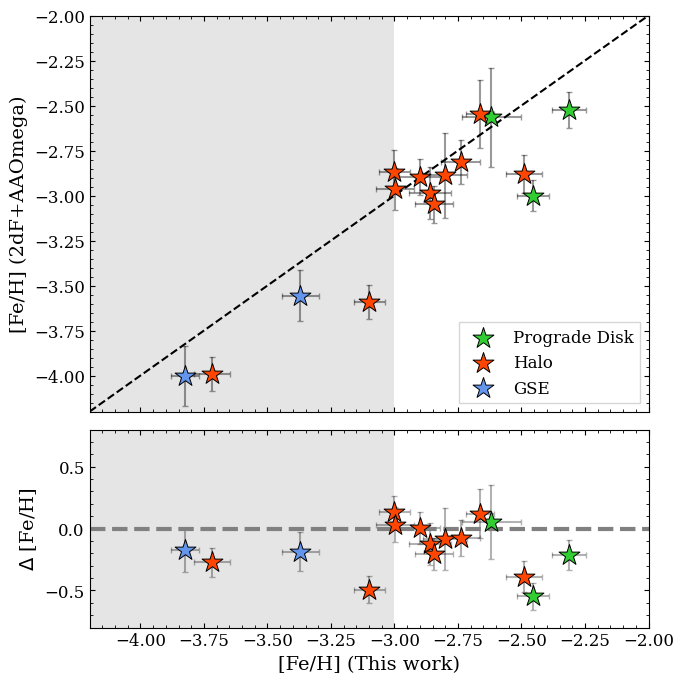

In [3]:
# Loading in the data
# X-Shooter data
xshooter_new_data= pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/stellar_params.csv').sort_values(by='star_id')
xshooter_new_feh = xshooter_new_data['Fe_it1'].to_numpy()
xshooter_new_feh_err = xshooter_new_data['Fe_comberr'].to_numpy()

# AAT data
aat_data= pd.read_csv('/data/misfit/benlowe/xshooter/stellar_params/emp_params_FINAL.csv').sort_values(by='star_id')
aat_feh = aat_data['z'].to_numpy()
aat_feh_err = aat_data['randz_std'].to_numpy()

# Merging the data together, then separating based on orbit type
feh_comb_df = pd.merge(xshooter_new_data[['star_id', 'Fe_it1', 'Fe_comberr']], aat_data[['star_id', 'z', 'randz_std', 'orbit']], on='star_id', how='inner')

feh_prodisk_df = feh_comb_df[feh_comb_df['orbit'] == 'pro_disk']
feh_halo_df = feh_comb_df[feh_comb_df['orbit'] == 'halo']
feh_gse_df = feh_comb_df[feh_comb_df['orbit'] == 'gse']


# Plotting
fig = plt.figure(figsize=[7,7])
gs = fig.add_gridspec(2, 1, wspace=0.1, hspace=0.03, width_ratios=[1], height_ratios=[2, 1])
(ax1), (ax2) = gs.subplots(sharex='col')

# Main plot
ax1.scatter(feh_prodisk_df['Fe_it1'], feh_prodisk_df['z'], color='limegreen', label='Prograde Disk', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
ax1.errorbar(feh_prodisk_df['Fe_it1'], feh_prodisk_df['z'], xerr=feh_prodisk_df['Fe_comberr'],
                yerr=feh_prodisk_df['randz_std'], fmt='o', color='black', zorder=9, alpha=0.4)
ax1.scatter(feh_halo_df['Fe_it1'], feh_halo_df['z'], color='orangered', label='Halo', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
ax1.errorbar(feh_halo_df['Fe_it1'], feh_halo_df['z'], xerr=feh_halo_df['Fe_comberr'],
                yerr=feh_halo_df['randz_std'], fmt='o', color='black', zorder=9, alpha=0.4)
ax1.scatter(feh_gse_df['Fe_it1'], feh_gse_df['z'], color='cornflowerblue', label='GSE', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
ax1.errorbar(feh_gse_df['Fe_it1'], feh_gse_df['z'], xerr=feh_gse_df['Fe_comberr'],
                yerr=feh_gse_df['randz_std'], fmt='o', color='black', zorder=9, alpha=0.4)
ax1.plot([-4.2, -2.0], [-4.2, -2.0], color='black', linestyle='--')

rectangle = plt.Rectangle((-4.2, -4.2), 1.2, 2.5, facecolor='grey', alpha=0.2, zorder=-10)
ax1.add_patch(rectangle)
ax1.set_xlim(-4.2, -2.0)
ax1.set_ylim(-4.2, -2.0)
ax1.set_ylabel('[Fe/H] (2dF+AAOmega)')
ax1.legend(fancybox=False)


# Difference plot
ax2.scatter(feh_prodisk_df['Fe_it1'], feh_prodisk_df['z'] - feh_prodisk_df['Fe_it1'], color='limegreen', marker='*', s=250, edgecolor='black', 
            zorder=10, linewidths=0.7)
ax2.errorbar(feh_prodisk_df['Fe_it1'], feh_prodisk_df['z'] - feh_prodisk_df['Fe_it1'], 
             xerr=feh_prodisk_df['Fe_comberr'], yerr=np.sqrt(feh_prodisk_df['Fe_comberr']**2 + feh_prodisk_df['randz_std']**2), 
             fmt='o', color='black', alpha=0.3, zorder=1)
ax2.scatter(feh_halo_df['Fe_it1'], feh_halo_df['z'] - feh_halo_df['Fe_it1'], color='orangered', marker='*', s=250, edgecolor='black', zorder=10, 
            linewidths=0.7)
ax2.errorbar(feh_halo_df['Fe_it1'], feh_halo_df['z'] - feh_halo_df['Fe_it1'], 
             xerr=feh_halo_df['Fe_comberr'], yerr=np.sqrt(feh_halo_df['Fe_comberr']**2 + feh_halo_df['randz_std']**2), fmt='o', color='black', alpha=0.3, zorder=1)
ax2.scatter(feh_gse_df['Fe_it1'], feh_gse_df['z'] - feh_gse_df['Fe_it1'], color='cornflowerblue', marker='*', s=250, edgecolor='black', 
            zorder=10, linewidths=0.7)
ax2.errorbar(feh_gse_df['Fe_it1'], feh_gse_df['z'] - feh_gse_df['Fe_it1'], 
             xerr=feh_gse_df['Fe_comberr'], yerr=np.sqrt(feh_gse_df['Fe_comberr']**2 + feh_gse_df['randz_std']**2), fmt='o', color='black', alpha=0.3, zorder=1)

# ax2.scatter(xshooter_new_feh, aat_feh-xshooter_new_feh, color='darkred', zorder=10)
# ax2.errorbar(xshooter_new_feh, aat_feh-xshooter_new_feh, yerr=np.sqrt(xshooter_new_feh_err**2 + aat_feh_err**2), 
#              xerr=xshooter_new_feh_err, fmt='o', color='black', alpha=0.3, zorder=1)


rectangle = plt.Rectangle((-4.2, -2), 1.2, 5, facecolor='grey', alpha=0.2, zorder=-10)
ax2.add_patch(rectangle)
ax2.axhline(0, color='grey', linestyle='--', linewidth=3)
ax2.set_xlabel("[Fe/H] (This work)")
ax2.set_ylabel("$\Delta$ [Fe/H]")
ax2.set_xlim(-4.2, -2.0)
ax2.set_ylim(bottom=-0.8, top=0.8)

gs.tight_layout(fig)

# plt.savefig("/data/misfit/benlowe/xshooter/results/aat_comparision/aat_xshooter_feh_v6.pdf", dpi=300, transparent=False, facecolor="white")
# plt.savefig("/data/misfit/benlowe/xshooter/results/aat_comparision/aat_xshooter_feh_v6.png", dpi=300, transparent=False, facecolor="white")



In [22]:
print(len(feh_comb_df[feh_comb_df['Fe_it2'] <= -3.0]))
print(len(feh_comb_df[feh_comb_df['z'] <= -3.0]))

4/5 * 100

4
5


80.0

In [4]:
diff = aat_feh-xshooter_new_feh
diff_mean = np.mean(diff)
diff_std = np.std(diff)

print(f"Mean difference: {diff_mean:.3f}, Standard deviation: {diff_std:.3f}")

Mean difference: -0.152, Standard deviation: 0.196


#### Comparing metallicites between the two iterations

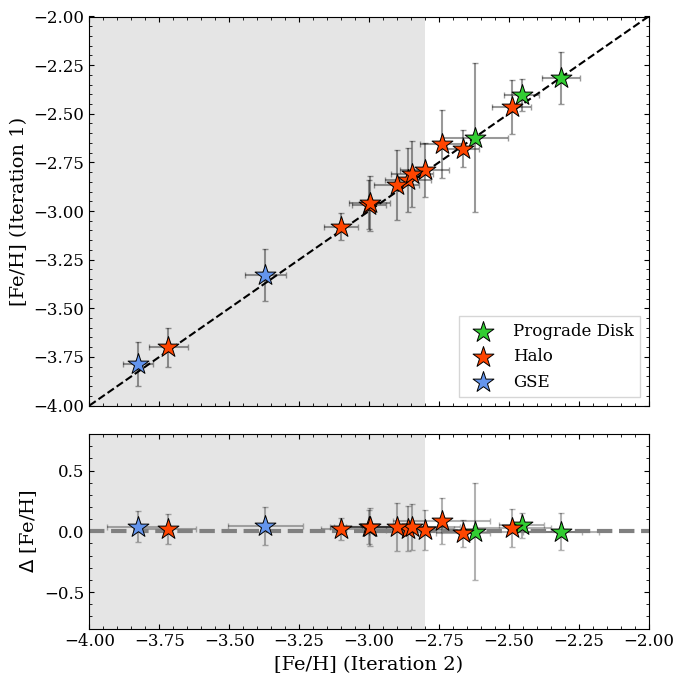

In [ ]:
# Loading in the data
# X-Shooter it1 data
it1_data = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final/stellar_params.csv').sort_values(by='star_id')
it1_feh = it1_data['Fe_it2'].to_numpy()
it1_feh_err = it1_data['Fe_tefferr'].to_numpy()

# X-Shooter it2 data
it2_data = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/stellar_params.csv').sort_values(by='star_id')
it2_feh = it2_data['Fe_it1'].to_numpy()
it2_feh_err = it2_data['Fe_comberr'].to_numpy()

# AAT data (for orbital classification)
aat_data = pd.read_csv('/data/misfit/benlowe/xshooter/stellar_params/emp_params_FINAL.csv').sort_values(by='star_id')

# Merging the data together, then separating based on orbit type
feh_comb_df = pd.merge(it1_data[['star_id', 'Fe_it2', 'Fe_tefferr']], it2_data[['star_id', 'Fe_it1', 'Fe_comberr']], on='star_id', how='inner')
feh_comb_df = pd.merge(feh_comb_df, aat_data[['star_id', 'orbit']], on='star_id', how='inner')


feh_prodisk_df = feh_comb_df[feh_comb_df['orbit'] == 'pro_disk']
feh_halo_df = feh_comb_df[feh_comb_df['orbit'] == 'halo']
feh_gse_df = feh_comb_df[feh_comb_df['orbit'] == 'gse']

# Calculating the mean difference and standard deviation
diff = feh_prodisk_df['Fe_it2'] - feh_prodisk_df['Fe_it1']
diff_mean = np.mean(diff)
diff_std = np.std(diff)


# Plotting
fig = plt.figure(figsize=[7,7])
gs = fig.add_gridspec(2, 1, wspace=0.1, hspace=0.03, width_ratios=[1], height_ratios=[2, 1])
(ax1), (ax2) = gs.subplots(sharex='col')

# Main plot
ax1.scatter(feh_prodisk_df['Fe_it1'], feh_prodisk_df['Fe_it2'], color='limegreen', label='Prograde Disk', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
ax1.errorbar(feh_prodisk_df['Fe_it1'], feh_prodisk_df['Fe_it2'], xerr=feh_prodisk_df['Fe_comberr'],
                yerr=feh_prodisk_df['Fe_tefferr'], fmt='o', color='black', zorder=9, alpha=0.4)
ax1.scatter(feh_halo_df['Fe_it1'], feh_halo_df['Fe_it2'], color='orangered', label='Halo', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
ax1.errorbar(feh_halo_df['Fe_it1'], feh_halo_df['Fe_it2'], xerr=feh_halo_df['Fe_comberr'],
                yerr=feh_halo_df['Fe_tefferr'], fmt='o', color='black', zorder=9, alpha=0.4)
ax1.scatter(feh_gse_df['Fe_it1'], feh_gse_df['Fe_it2'], color='cornflowerblue', label='GSE', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
ax1.errorbar(feh_gse_df['Fe_it1'], feh_gse_df['Fe_it2'], xerr=feh_gse_df['Fe_comberr'],
                yerr=feh_gse_df['Fe_tefferr'], fmt='o', color='black', zorder=9, alpha=0.4)
ax1.plot([-4, -2.0], [-4, -2.0], color='black', linestyle='--')
# ax1.text(f'Mean diff: {diff_mean:.2f} ± {diff_std:.2f}', -3.9, -2.25)

rectangle = plt.Rectangle((-4, -4), 1.2, 2.5, facecolor='grey', alpha=0.2, zorder=-10)
ax1.add_patch(rectangle)
ax1.set_xlim(-4, -2.0)
ax1.set_ylim(-4, -2.0)
ax1.set_ylabel('[Fe/H] (Iteration 1)')
ax1.legend(fancybox=False)


# Difference plot
ax2.scatter(feh_prodisk_df['Fe_it1'], feh_prodisk_df['Fe_it2'] - feh_prodisk_df['Fe_it1'], color='limegreen', marker='*', s=250, edgecolor='black', 
            zorder=10, linewidths=0.7)
ax2.errorbar(feh_prodisk_df['Fe_it1'], feh_prodisk_df['Fe_it2'] - feh_prodisk_df['Fe_it1'], 
             xerr=feh_prodisk_df['Fe_tefferr'], yerr=np.sqrt(feh_prodisk_df['Fe_tefferr']**2 + feh_prodisk_df['Fe_comberr']**2), 
             fmt='o', color='black', alpha=0.3, zorder=1)
ax2.scatter(feh_halo_df['Fe_it1'], feh_halo_df['Fe_it2'] - feh_halo_df['Fe_it1'], color='orangered', marker='*', s=250, edgecolor='black', zorder=10, 
            linewidths=0.7)
ax2.errorbar(feh_halo_df['Fe_it1'], feh_halo_df['Fe_it2'] - feh_halo_df['Fe_it1'], 
             xerr=feh_halo_df['Fe_tefferr'], yerr=np.sqrt(feh_halo_df['Fe_tefferr']**2 + feh_halo_df['Fe_comberr']**2), fmt='o', color='black', alpha=0.3, zorder=1)
ax2.scatter(feh_gse_df['Fe_it1'], feh_gse_df['Fe_it2'] - feh_gse_df['Fe_it1'], color='cornflowerblue', marker='*', s=250, edgecolor='black', 
            zorder=10, linewidths=0.7)
ax2.errorbar(feh_gse_df['Fe_it1'], feh_gse_df['Fe_it2'] - feh_gse_df['Fe_it1'], 
             xerr=feh_gse_df['Fe_tefferr'], yerr=np.sqrt(feh_gse_df['Fe_tefferr']**2 + feh_gse_df['Fe_comberr']**2), fmt='o', color='black', alpha=0.3, zorder=1)

# ax2.scatter(xshooter_new_feh, aat_feh-xshooter_new_feh, color='darkred', zorder=10)
# ax2.errorbar(xshooter_new_feh, aat_feh-xshooter_new_feh, yerr=np.sqrt(xshooter_new_feh_err**2 + aat_feh_err**2), 
#              xerr=xshooter_new_feh_err, fmt='o', color='black', alpha=0.3, zorder=1)


rectangle = plt.Rectangle((-4, -2), 1.2, 5, facecolor='grey', alpha=0.2, zorder=-10)
ax2.add_patch(rectangle)
ax2.axhline(0, color='grey', linestyle='--', linewidth=3)
ax2.set_xlabel("[Fe/H] (Iteration 2)")
ax2.set_ylabel("$\Delta$ [Fe/H]")
ax2.set_xlim(-4, -2.0)
ax2.set_ylim(bottom=-0.8, top=0.8)

gs.tight_layout(fig)

# plt.savefig("/data/misfit/benlowe/xshooter/results/aat_comparision/aat_xshooter_feh_v5.pdf", dpi=300, transparent=False, facecolor="white")
# plt.savefig("/data/misfit/benlowe/xshooter/results/aat_comparision/aat_xshooter_feh_v5.png", dpi=300, transparent=False, facecolor="white")



#### Comparing chemical abundances across the itterations

Loading in the chemical abundances: C, N, Al and Si

In [38]:
# Loading in the data
# X-Shooter it1 data
it1_data = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final/stellar_abunds.csv').sort_values(by='star_id')
it1_c = it1_data[['star_id', 'C_I_xfe_it2', 'C_I_xfe_tefferr', 'teff']]
it1_n = it1_data[['star_id', 'N_I_xfe_it2', 'N_I_xfe_tefferr', 'teff']]
it1_al = it1_data[['star_id', 'Al_I_xfe_it2', 'Al_I_xfe_tefferr', 'teff']]
it1_si = it1_data[['star_id', 'Si_I_xfe_it2', 'Si_I_xfe_tefferr', 'teff']]

# X-Shooter it2 data
it2_data = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/stellar_abunds.csv').sort_values(by='star_id')
it2_c = it2_data[['star_id', 'C_I_xfe_it1', 'C_I_xfe_comberr']]
it2_n = it2_data[['star_id', 'N_I_xfe_it1', 'N_I_xfe_comberr']]
it2_al = it2_data[['star_id', 'Al_I_xfe_it1', 'Al_I_xfe_comberr']]
it2_si = it2_data[['star_id', 'Si_I_xfe_it1', 'Si_I_xfe_comberr']]

# Combining dataframes for each element
c_data = pd.merge(it1_c[it1_c['teff'] < 5300], it2_c, on='star_id', how='inner')
n_data = pd.merge(it1_n[it1_c['teff'] < 5300], it2_n, on='star_id', how='inner')
al_data = pd.merge(it1_al, it2_al, on='star_id', how='inner')
si_data = pd.merge(it1_si, it2_si, on='star_id', how='inner')


# AAT data (for orbital classification)
aat_data = pd.read_csv('/data/misfit/benlowe/xshooter/stellar_params/emp_params_FINAL.csv').sort_values(by='star_id')

# Merging the data together, then separating based on orbit type
c_data = pd.merge(c_data, aat_data[['star_id', 'orbit']], on='star_id', how='inner')
c_data.loc[c_data['star_id'] == 'ra_1656-1433_s143', 'C_I_xfe_it2'] = 0.358195
c_data.loc[c_data['star_id'] == 'ra_1656-1433_s143', 'C_I_xfe_tefferr'] = abs(0.358195 - 0.588063)
c_data.loc[c_data['star_id'] == 'ra_1656-1433_s143', 'C_I_xfe_comberr'] = 0.223806
c_data.loc[c_data['star_id'] == 'ra_1752-4300_s6', 'C_I_xfe_comberr'] = 0.234297

n_data = pd.merge(n_data, aat_data[['star_id', 'orbit']], on='star_id', how='inner')
n_data = n_data[~n_data['star_id'].isin(['ra_1659-2154_s114', 'ra_1658-2454_s22', 'ra_1633-2814_s284'])] # Removing the following stars from the N data due to bad N abundances
al_data = pd.merge(al_data, aat_data[['star_id', 'orbit']], on='star_id', how='inner')
si_data = pd.merge(si_data, aat_data[['star_id', 'orbit']], on='star_id', how='inner')


c_prodisk_df = c_data[c_data['orbit'] == 'pro_disk']
c_halo_df = c_data[c_data['orbit'] == 'halo']
c_gse_df = c_data[c_data['orbit'] == 'gse']

n_prodisk_df = n_data[n_data['orbit'] == 'pro_disk']
n_halo_df = n_data[n_data['orbit'] == 'halo']
n_gse_df = n_data[n_data['orbit'] == 'gse']

al_prodisk_df = al_data[al_data['orbit'] == 'pro_disk']
al_halo_df = al_data[al_data['orbit'] == 'halo']
al_gse_df = al_data[al_data['orbit'] == 'gse']

si_prodisk_df = si_data[si_data['orbit'] == 'pro_disk']
si_halo_df = si_data[si_data['orbit'] == 'halo']
si_gse_df = si_data[si_data['orbit'] == 'gse']


In [53]:
print(f'{diff_mean} ±')

-0.02477362991914095 ±


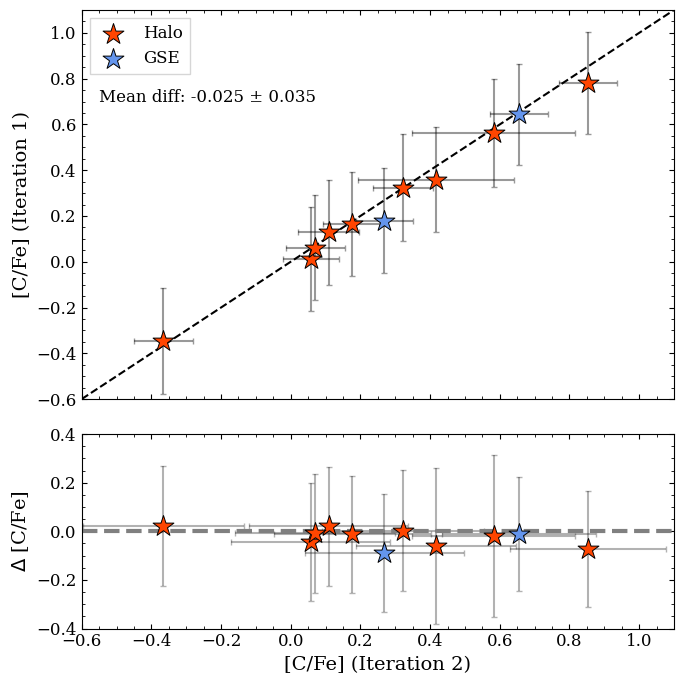

In [65]:
# Calculating the mean difference and standard deviation
diff = c_data['C_I_xfe_it2'].to_numpy() - c_data['C_I_xfe_it1'].to_numpy()
diff_mean = float(np.mean(diff))
diff_std = float(np.std(diff))


# Plotting
fig = plt.figure(figsize=[7,7])
gs = fig.add_gridspec(2, 1, wspace=0.1, hspace=0.03, width_ratios=[1], height_ratios=[2, 1])
(ax1), (ax2) = gs.subplots(sharex='col')

# Main plot
# ax1.scatter(c_prodisk_df['C_I_xfe_it1'], c_prodisk_df['C_I_xfe_it2'], color='limegreen', label='Prograde Disk', 
#             marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
# ax1.errorbar(c_prodisk_df['C_I_xfe_it1'], c_prodisk_df['C_I_xfe_it2'], xerr=c_prodisk_df['C_I_xfe_comberr'],
#                 yerr=c_prodisk_df['C_I_xfe_tefferr'], fmt='o', color='black', zorder=9, alpha=0.4)
ax1.scatter(c_halo_df['C_I_xfe_it1'], c_halo_df['C_I_xfe_it2'], color='orangered', label='Halo', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
ax1.errorbar(c_halo_df['C_I_xfe_it1'], c_halo_df['C_I_xfe_it2'], xerr=c_halo_df['C_I_xfe_comberr'],
                yerr=c_halo_df['C_I_xfe_tefferr'], fmt='o', color='black', zorder=9, alpha=0.4)
ax1.scatter(c_gse_df['C_I_xfe_it1'], c_gse_df['C_I_xfe_it2'], color='cornflowerblue', label='GSE', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
ax1.errorbar(c_gse_df['C_I_xfe_it1'], c_gse_df['C_I_xfe_it2'], xerr=c_gse_df['C_I_xfe_comberr'],
                yerr=c_gse_df['C_I_xfe_tefferr'], fmt='o', color='black', zorder=9, alpha=0.4)
ax1.plot([-0.6, 1.1], [-0.6, 1.1], color='black', linestyle='--')
ax1.text(s=f'Mean diff: {diff_mean:.3f} ± {diff_std:.3f}', x=-0.55, y=0.7)

ax1.set_xlim(-0.6, 1.1)
ax1.set_ylim(-0.6, 1.1)
ax1.set_ylabel('[C/Fe] (Iteration 1)')
ax1.legend(fancybox=False)


# Difference plot
# ax2.scatter(c_prodisk_df['C_I_xfe_it1'], c_prodisk_df['C_I_xfe_it2'] - c_prodisk_df['C_I_xfe_it1'], color='limegreen', marker='*', s=250, edgecolor='black', 
#             zorder=10, linewidths=0.7)
# ax2.errorbar(c_prodisk_df['C_I_xfe_it1'], c_prodisk_df['C_I_xfe_it2'] - c_prodisk_df['C_I_xfe_it1'], 
#              xerr=c_prodisk_df['C_I_xfe_tefferr'], yerr=np.sqrt(c_prodisk_df['C_I_xfe_tefferr']**2 + c_prodisk_df['C_I_xfe_comberr']**2), 
#              fmt='o', color='black', alpha=0.3, zorder=1)
ax2.scatter(c_halo_df['C_I_xfe_it1'], c_halo_df['C_I_xfe_it2'] - c_halo_df['C_I_xfe_it1'], color='orangered', marker='*', s=250, edgecolor='black', zorder=10, 
            linewidths=0.7)
ax2.errorbar(c_halo_df['C_I_xfe_it1'], c_halo_df['C_I_xfe_it2'] - c_halo_df['C_I_xfe_it1'], 
             xerr=c_halo_df['C_I_xfe_tefferr'], yerr=np.sqrt(c_halo_df['C_I_xfe_tefferr']**2 + c_halo_df['C_I_xfe_comberr']**2), fmt='o', color='black', alpha=0.3, zorder=1)
ax2.scatter(c_gse_df['C_I_xfe_it1'], c_gse_df['C_I_xfe_it2'] - c_gse_df['C_I_xfe_it1'], color='cornflowerblue', marker='*', s=250, edgecolor='black', 
            zorder=10, linewidths=0.7)
ax2.errorbar(c_gse_df['C_I_xfe_it1'], c_gse_df['C_I_xfe_it2'] - c_gse_df['C_I_xfe_it1'], 
             xerr=c_gse_df['C_I_xfe_tefferr'], yerr=np.sqrt(c_gse_df['C_I_xfe_tefferr']**2 + c_gse_df['C_I_xfe_comberr']**2), fmt='o', color='black', alpha=0.3, zorder=1)

# ax2.scatter(xshooter_new_feh, aat_feh-xshooter_new_feh, color='darkred', zorder=10)
# ax2.errorbar(xshooter_new_feh, aat_feh-xshooter_new_feh, yerr=np.sqrt(xshooter_new_feh_err**2 + aat_feh_err**2), 
#              xerr=xshooter_new_feh_err, fmt='o', color='black', alpha=0.3, zorder=1)


ax2.axhline(0, color='grey', linestyle='--', linewidth=3)
ax2.set_xlabel("[C/Fe] (Iteration 2)")
ax2.set_ylabel("$\Delta$ [C/Fe]")
ax2.set_xlim(-0.6, 1.1)
ax2.set_ylim(bottom=-0.4, top=0.4)

gs.tight_layout(fig)

plt.savefig("/data/misfit/benlowe/xshooter/results/abund_comparision/xshooter_cfe_it.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/results/abund_comparision/xshooter_cfe_it.png", dpi=300, transparent=False, facecolor="white")



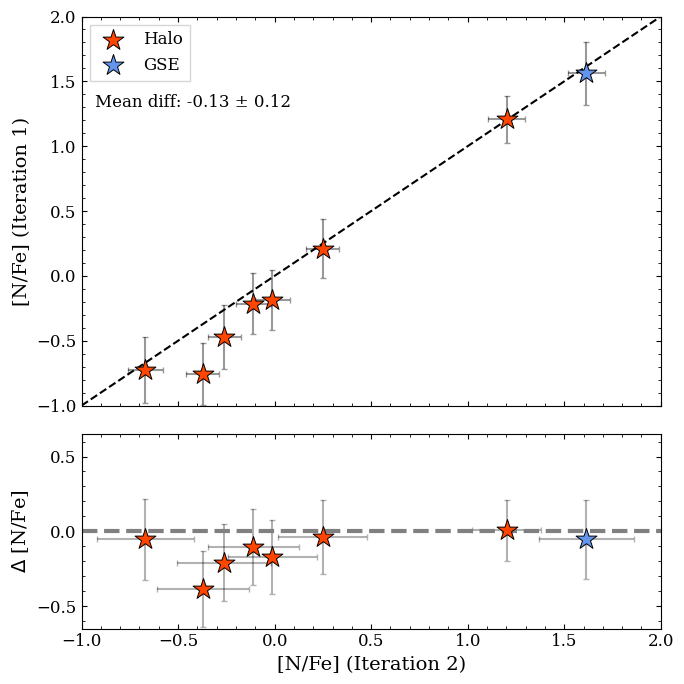

In [75]:
# Calculating the mean difference and standard deviation for N
diff = n_data['N_I_xfe_it2'].to_numpy() - n_data['N_I_xfe_it1'].to_numpy()
diff_mean = float(np.mean(diff))
diff_std = float(np.std(diff))

# Plotting
fig = plt.figure(figsize=[7,7])
gs = fig.add_gridspec(2, 1, wspace=0.1, hspace=0.03, width_ratios=[1], height_ratios=[2, 1])
(ax1), (ax2) = gs.subplots(sharex='col')

# Main plot
ax1.scatter(n_halo_df['N_I_xfe_it1'], n_halo_df['N_I_xfe_it2'], color='orangered', label='Halo', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
ax1.errorbar(n_halo_df['N_I_xfe_it1'], n_halo_df['N_I_xfe_it2'], xerr=n_halo_df['N_I_xfe_comberr'],
                yerr=n_halo_df['N_I_xfe_tefferr'], fmt='o', color='black', zorder=9, alpha=0.4)
ax1.scatter(n_gse_df['N_I_xfe_it1'], n_gse_df['N_I_xfe_it2'], color='cornflowerblue', label='GSE', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
ax1.errorbar(n_gse_df['N_I_xfe_it1'], n_gse_df['N_I_xfe_it2'], xerr=n_gse_df['N_I_xfe_comberr'],
                yerr=n_gse_df['N_I_xfe_tefferr'], fmt='o', color='black', zorder=9, alpha=0.4)
ax1.plot([-1, 2], [-1, 2], color='black', linestyle='--')
ax1.text(s=f'Mean diff: {diff_mean:.2f} ± {diff_std:.2f}', x=-0.93, y=1.3)

ax1.set_xlim(-1, 2)
ax1.set_ylim(-1, 2)
ax1.set_ylabel('[N/Fe] (Iteration 1)')
ax1.legend(fancybox=False)

# Difference plot
ax2.scatter(n_halo_df['N_I_xfe_it1'], n_halo_df['N_I_xfe_it2'] - n_halo_df['N_I_xfe_it1'], color='orangered', marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
ax2.errorbar(n_halo_df['N_I_xfe_it1'], n_halo_df['N_I_xfe_it2'] - n_halo_df['N_I_xfe_it1'], 
             xerr=n_halo_df['N_I_xfe_tefferr'], yerr=np.sqrt(n_halo_df['N_I_xfe_tefferr']**2 + n_halo_df['N_I_xfe_comberr']**2), fmt='o', color='black', alpha=0.3, zorder=1)
ax2.scatter(n_gse_df['N_I_xfe_it1'], n_gse_df['N_I_xfe_it2'] - n_gse_df['N_I_xfe_it1'], color='cornflowerblue', marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
ax2.errorbar(n_gse_df['N_I_xfe_it1'], n_gse_df['N_I_xfe_it2'] - n_gse_df['N_I_xfe_it1'], 
             xerr=n_gse_df['N_I_xfe_tefferr'], yerr=np.sqrt(n_gse_df['N_I_xfe_tefferr']**2 + n_gse_df['N_I_xfe_comberr']**2), fmt='o', color='black', alpha=0.3, zorder=1)

ax2.axhline(0, color='grey', linestyle='--', linewidth=3)
ax2.set_xlabel("[N/Fe] (Iteration 2)")
ax2.set_ylabel("$\Delta$ [N/Fe]")
ax2.set_xlim(-1, 2)
ax2.set_ylim(bottom=-0.65, top=0.65)

gs.tight_layout(fig)

plt.savefig("/data/misfit/benlowe/xshooter/results/abund_comparision/xshooter_nfe_it.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/results/abund_comparision/xshooter_nfe_it.png", dpi=300, transparent=False, facecolor="white")


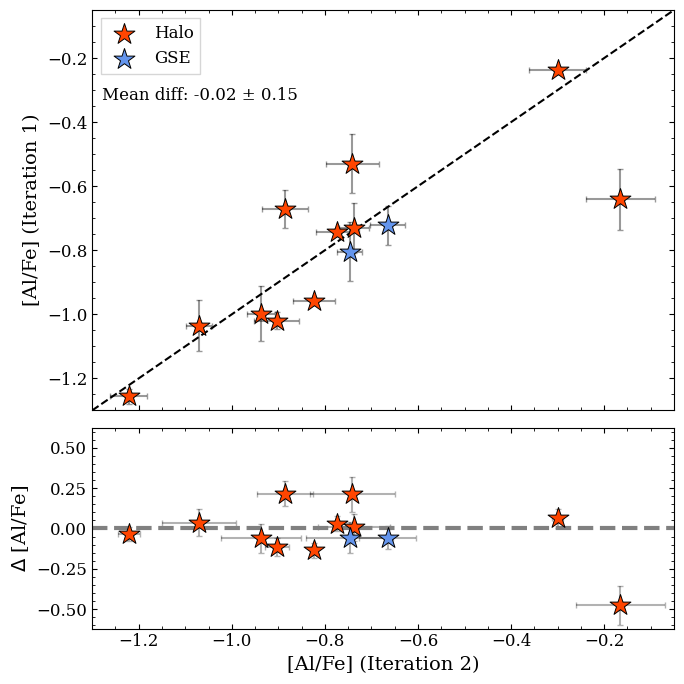

In [90]:
# Calculating the mean difference and standard deviation for Al
diff = al_data['Al_I_xfe_it2'].to_numpy() - al_data['Al_I_xfe_it1'].to_numpy()
diff_mean = float(np.mean(diff))
diff_std = float(np.std(diff))

# Plotting
fig = plt.figure(figsize=[7,7])
gs = fig.add_gridspec(2, 1, wspace=0.1, hspace=0.03, width_ratios=[1], height_ratios=[2, 1])
(ax1), (ax2) = gs.subplots(sharex='col')

# Main plot
ax1.scatter(al_halo_df['Al_I_xfe_it1'], al_halo_df['Al_I_xfe_it2'], color='orangered', label='Halo', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
ax1.errorbar(al_halo_df['Al_I_xfe_it1'], al_halo_df['Al_I_xfe_it2'], xerr=al_halo_df['Al_I_xfe_comberr'],
                yerr=al_halo_df['Al_I_xfe_tefferr'], fmt='o', color='black', zorder=9, alpha=0.4)
ax1.scatter(al_gse_df['Al_I_xfe_it1'], al_gse_df['Al_I_xfe_it2'], color='cornflowerblue', label='GSE', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
ax1.errorbar(al_gse_df['Al_I_xfe_it1'], al_gse_df['Al_I_xfe_it2'], xerr=al_gse_df['Al_I_xfe_comberr'],
                yerr=al_gse_df['Al_I_xfe_tefferr'], fmt='o', color='black', zorder=9, alpha=0.4)
ax1.plot([-1.3, 1.1], [-1.3, 1.1], color='black', linestyle='--')
ax1.text(s=f'Mean diff: {diff_mean:.2f} ± {diff_std:.2f}', x=-1.28, y=-0.33)

ax1.set_xlim(-1.3, -0.05)
ax1.set_ylim(-1.3, -0.05)
ax1.set_ylabel('[Al/Fe] (Iteration 1)')
ax1.legend(fancybox=False)

# Difference plot
ax2.scatter(al_halo_df['Al_I_xfe_it1'], al_halo_df['Al_I_xfe_it2'] - al_halo_df['Al_I_xfe_it1'], color='orangered', marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
ax2.errorbar(al_halo_df['Al_I_xfe_it1'], al_halo_df['Al_I_xfe_it2'] - al_halo_df['Al_I_xfe_it1'], 
             xerr=al_halo_df['Al_I_xfe_tefferr'], yerr=np.sqrt(al_halo_df['Al_I_xfe_tefferr']**2 + al_halo_df['Al_I_xfe_comberr']**2), fmt='o', color='black', alpha=0.3, zorder=1)
ax2.scatter(al_gse_df['Al_I_xfe_it1'], al_gse_df['Al_I_xfe_it2'] - al_gse_df['Al_I_xfe_it1'], color='cornflowerblue', marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
ax2.errorbar(al_gse_df['Al_I_xfe_it1'], al_gse_df['Al_I_xfe_it2'] - al_gse_df['Al_I_xfe_it1'], 
             xerr=al_gse_df['Al_I_xfe_tefferr'], yerr=np.sqrt(al_gse_df['Al_I_xfe_tefferr']**2 + al_gse_df['Al_I_xfe_comberr']**2), fmt='o', color='black', alpha=0.3, zorder=1)

ax2.axhline(0, color='grey', linestyle='--', linewidth=3)
ax2.set_xlabel("[Al/Fe] (Iteration 2)")
ax2.set_ylabel("$\Delta$ [Al/Fe]")
ax2.set_xlim(-1.3, -0.05)
ax2.set_ylim(-0.62, 0.62)

gs.tight_layout(fig)

plt.savefig("/data/misfit/benlowe/xshooter/results/abund_comparision/xshooter_alfe_it.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/results/abund_comparision/xshooter_alfe_it.png", dpi=300, transparent=False, facecolor="white")

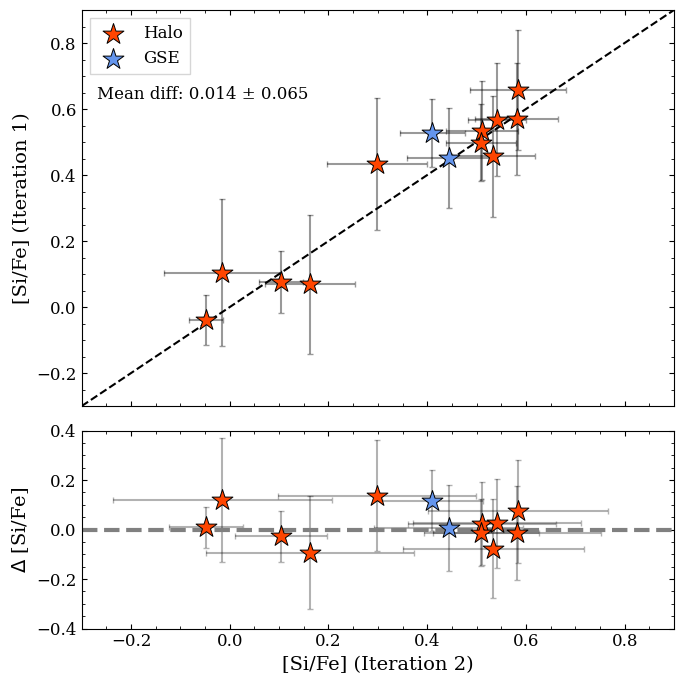

In [89]:
# Calculating the mean difference and standard deviation for Si
diff = si_data['Si_I_xfe_it2'].to_numpy() - si_data['Si_I_xfe_it1'].to_numpy()
diff_mean = float(np.mean(diff))
diff_std = float(np.std(diff))

# Plotting
fig = plt.figure(figsize=[7,7])
gs = fig.add_gridspec(2, 1, wspace=0.1, hspace=0.03, width_ratios=[1], height_ratios=[2, 1])
(ax1), (ax2) = gs.subplots(sharex='col')

# Main plot
ax1.scatter(si_halo_df['Si_I_xfe_it1'], si_halo_df['Si_I_xfe_it2'], color='orangered', label='Halo', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
ax1.errorbar(si_halo_df['Si_I_xfe_it1'], si_halo_df['Si_I_xfe_it2'], xerr=si_halo_df['Si_I_xfe_comberr'],
                yerr=si_halo_df['Si_I_xfe_tefferr'], fmt='o', color='black', zorder=9, alpha=0.4)
ax1.scatter(si_gse_df['Si_I_xfe_it1'], si_gse_df['Si_I_xfe_it2'], color='cornflowerblue', label='GSE', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
ax1.errorbar(si_gse_df['Si_I_xfe_it1'], si_gse_df['Si_I_xfe_it2'], xerr=si_gse_df['Si_I_xfe_comberr'],
                yerr=si_gse_df['Si_I_xfe_tefferr'], fmt='o', color='black', zorder=9, alpha=0.4)
ax1.plot([-0.3, 0.9], [-0.3, 0.9], color='black', linestyle='--')
ax1.text(s=f'Mean diff: {diff_mean:.3f} ± {diff_std:.3f}', x=-0.27, y=0.63)

ax1.set_xlim(-0.3, 0.9)
ax1.set_ylim(-0.3, 0.9)
ax1.set_ylabel('[Si/Fe] (Iteration 1)')
ax1.legend(fancybox=False)

# Difference plot
ax2.scatter(si_halo_df['Si_I_xfe_it1'], si_halo_df['Si_I_xfe_it2'] - si_halo_df['Si_I_xfe_it1'], color='orangered', marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
ax2.errorbar(si_halo_df['Si_I_xfe_it1'], si_halo_df['Si_I_xfe_it2'] - si_halo_df['Si_I_xfe_it1'], 
             xerr=si_halo_df['Si_I_xfe_tefferr'], yerr=np.sqrt(si_halo_df['Si_I_xfe_tefferr']**2 + si_halo_df['Si_I_xfe_comberr']**2), fmt='o', color='black', alpha=0.3, zorder=1)
ax2.scatter(si_gse_df['Si_I_xfe_it1'], si_gse_df['Si_I_xfe_it2'] - si_gse_df['Si_I_xfe_it1'], color='cornflowerblue', marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
ax2.errorbar(si_gse_df['Si_I_xfe_it1'], si_gse_df['Si_I_xfe_it2'] - si_gse_df['Si_I_xfe_it1'], 
             xerr=si_gse_df['Si_I_xfe_tefferr'], yerr=np.sqrt(si_gse_df['Si_I_xfe_tefferr']**2 + si_gse_df['Si_I_xfe_comberr']**2), fmt='o', color='black', alpha=0.3, zorder=1)

ax2.axhline(0, color='grey', linestyle='--', linewidth=3)
ax2.set_xlabel("[Si/Fe] (Iteration 2)")
ax2.set_ylabel("$\Delta$ [Si/Fe]")
ax2.set_ylim(-0.4, 0.4)
ax2.set_xlim(-0.3, 0.9)


gs.tight_layout(fig)

plt.savefig("/data/misfit/benlowe/xshooter/results/abund_comparision/xshooter_sife_it.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/results/abund_comparision/xshooter_sife_it.png", dpi=300, transparent=False, facecolor="white")

In [91]:
al_data

,star_id,Al_I_xfe_it2,Al_I_xfe_tefferr,teff,Al_I_xfe_it1,Al_I_xfe_comberr,orbit
0,ra_0103-7050_s163,-0.911585,0.084966,6298.806689,-0.924846,0.033061,pro_disk
1,ra_0834-5220_s316,-1.088198,0.080565,5959.304567,-1.091062,0.028781,pro_disk
2,ra_1604-2712_s24,-0.238237,0.011530,5002.684528,-0.300252,0.060455,halo
3,ra_1604-2712_s292,-0.998076,0.086740,5783.249268,-0.937130,0.030098,halo
4,ra_1624-2150_s278,-1.035326,0.079748,6381.865006,-1.070537,0.026925,halo
5,ra_1633-2814_s130,-0.721554,0.061179,4997.869004,-0.664663,0.037544,gse
6,ra_1633-2814_s284,-0.804129,0.092590,5261.142090,-0.747141,0.026766,gse
7,ra_1648-0653_s38,-1.224484,0.081360,6039.830368,-1.203182,0.029468,pro_disk
8,ra_1656-1433_s143,-0.529801,0.091625,4791.462397,-0.741009,0.057638,halo
9,ra_1658-2454_s22,-0.671310,0.060569,4852.253676,-0.885948,0.049826,halo


#### Comparing radial velocities

-13.044610287470967
19.976135062508973


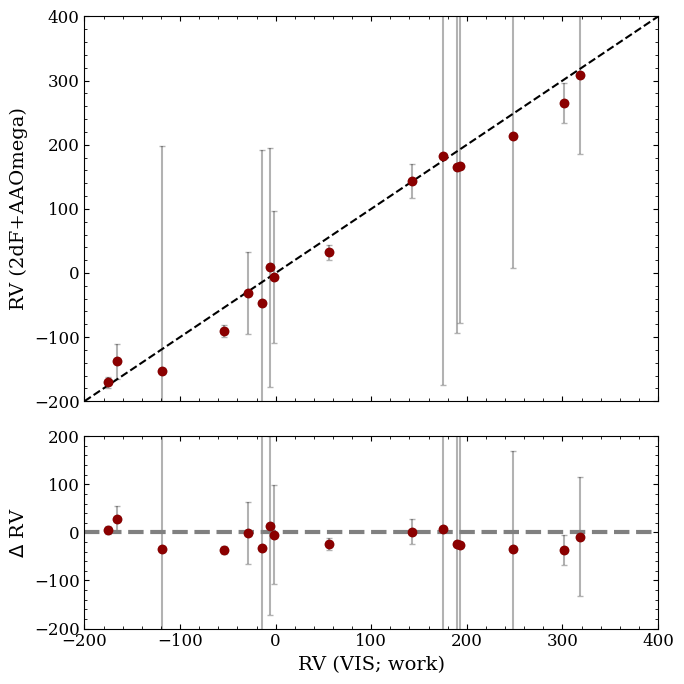

In [14]:
# Loading in the data
# X-Shooter RV data
xshooter_info_df = pd.read_csv('/data/misfit/benlowe/xshooter/reduced_data/comb_spec_2/star_info.csv').sort_values(by='star_id')
xshooter_rv = xshooter_info_df['rv_vis'].to_numpy()
xshooter_rv_err = xshooter_info_df['rv_vis_err'].to_numpy()

# AAT data
aat_data= pd.read_csv('/data/misfit/benlowe/xshooter/stellar_params/emp_params_FINAL.csv').sort_values(by='star_id')
aat_rv = aat_data['rv'].to_numpy()
aat_rv_err = aat_data['rv_err'].to_numpy()



# Plotting
fig = plt.figure(figsize=[7,7])
gs = fig.add_gridspec(2, 1, wspace=0.1, hspace=0.03, width_ratios=[1], height_ratios=[2, 1])
(ax1), (ax2) = gs.subplots(sharex='col')

# Main plot
ax1.scatter(xshooter_rv, aat_rv, color='darkred', zorder=10)
ax1.errorbar(xshooter_rv, aat_rv, xerr=xshooter_rv_err, yerr=aat_rv_err, fmt='o', color='black', alpha=0.3, zorder=1)
ax1.plot([-200, 400], [-200, 400], color='black', linestyle='--')
ax1.set_xlim(-200, 400)
ax1.set_ylim(-200, 400)
ax1.set_ylabel('RV (2dF+AAOmega)')


# Difference plot
ax2.scatter(xshooter_rv, aat_rv-xshooter_rv, color='darkred', zorder=10)
ax2.errorbar(xshooter_rv, aat_rv-xshooter_rv, yerr=np.sqrt(xshooter_rv_err**2 + aat_rv_err**2), 
             xerr=xshooter_rv_err, fmt='o', color='black', alpha=0.3, zorder=1)


ax2.axhline(0, color='grey', linestyle='--', linewidth=3)
ax2.set_xlabel("RV (VIS; work)")
ax2.set_ylabel("$\Delta$ RV")
ax2.set_xlim(-200, 400)
ax2.set_ylim(bottom=-200, top=200)

gs.tight_layout(fig)

# Calculating the mean difference between the two datasets
print(np.mean(aat_rv-xshooter_rv))
print(np.std(aat_rv-xshooter_rv))

# plt.savefig("/data/misfit/benlowe/xshooter/results/aat_comparision/aat_xshooter_rv.pdf", dpi=300, transparent=False, facecolor="white")
# plt.savefig("/data/misfit/benlowe/xshooter/results/aat_comparision/aat_xshooter_rv.png", dpi=300, transparent=False, facecolor="white")


-5.575712195346101
21.258169595455154


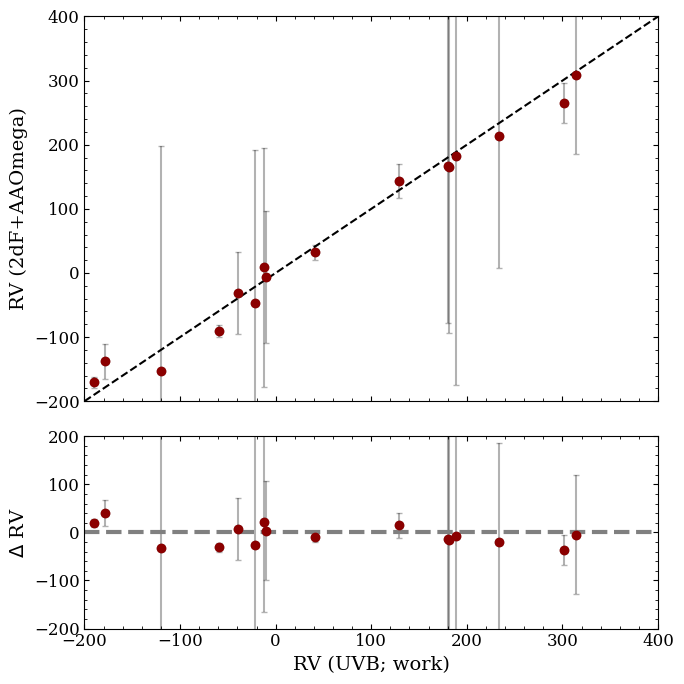

In [13]:
# Loading in the data
# X-Shooter RV data
xshooter_info_df = pd.read_csv('/data/misfit/benlowe/xshooter/reduced_data/comb_spec_2/star_info.csv').sort_values(by='star_id')
xshooter_rv = xshooter_info_df['rv_uvb'].to_numpy()
xshooter_rv_err = xshooter_info_df['rv_uvb_err'].to_numpy()

# AAT data
aat_data= pd.read_csv('/data/misfit/benlowe/xshooter/stellar_params/emp_params_FINAL.csv').sort_values(by='star_id')
aat_rv = aat_data['rv'].to_numpy()
aat_rv_err = aat_data['rv_err'].to_numpy()



# Plotting
fig = plt.figure(figsize=[7,7])
gs = fig.add_gridspec(2, 1, wspace=0.1, hspace=0.03, width_ratios=[1], height_ratios=[2, 1])
(ax1), (ax2) = gs.subplots(sharex='col')

# Main plot
ax1.scatter(xshooter_rv, aat_rv, color='darkred', zorder=10)
ax1.errorbar(xshooter_rv, aat_rv, xerr=xshooter_rv_err, yerr=aat_rv_err, fmt='o', color='black', alpha=0.3, zorder=1)
ax1.plot([-200, 400], [-200, 400], color='black', linestyle='--')
ax1.set_xlim(-200, 400)
ax1.set_ylim(-200, 400)
ax1.set_ylabel('RV (2dF+AAOmega)')


# Difference plot
ax2.scatter(xshooter_rv, aat_rv-xshooter_rv, color='darkred', zorder=10)
ax2.errorbar(xshooter_rv, aat_rv-xshooter_rv, yerr=np.sqrt(xshooter_rv_err**2 + aat_rv_err**2), 
             xerr=xshooter_rv_err, fmt='o', color='black', alpha=0.3, zorder=1)


ax2.axhline(0, color='grey', linestyle='--', linewidth=3)
ax2.set_xlabel("RV (UVB; work)")
ax2.set_ylabel("$\Delta$ RV")
ax2.set_xlim(-200, 400)
ax2.set_ylim(bottom=-200, top=200)

gs.tight_layout(fig)

# Calculating the mean difference between the two datasets
print(np.mean(aat_rv-xshooter_rv))
print(np.std(aat_rv-xshooter_rv))

# plt.savefig("/data/misfit/benlowe/xshooter/results/aat_comparision/aat_xshooter_rv.pdf", dpi=300, transparent=False, facecolor="white")
# plt.savefig("/data/misfit/benlowe/xshooter/results/aat_comparision/aat_xshooter_rv.png", dpi=300, transparent=False, facecolor="white")


In [15]:
diff = aat_rv-xshooter_rv
diff_mean = np.mean(diff)
diff_std = np.std(diff)

print(f"Mean difference: {diff_mean:.3f}, Standard deviation: {diff_std:.3f}")

Mean difference: -12.631, Standard deviation: 19.832


/tmp/ipykernel_2817642/1459894025.py:196: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax2.scatter(xshooter_new_feh, aat_feh-xshooter_new_feh, c=colors, zorder=10, cmap=cmr.dusk_r)


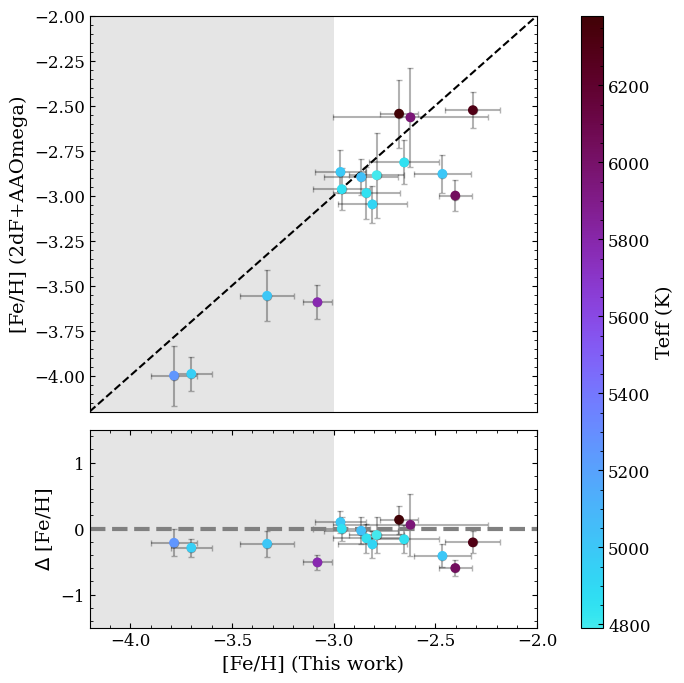

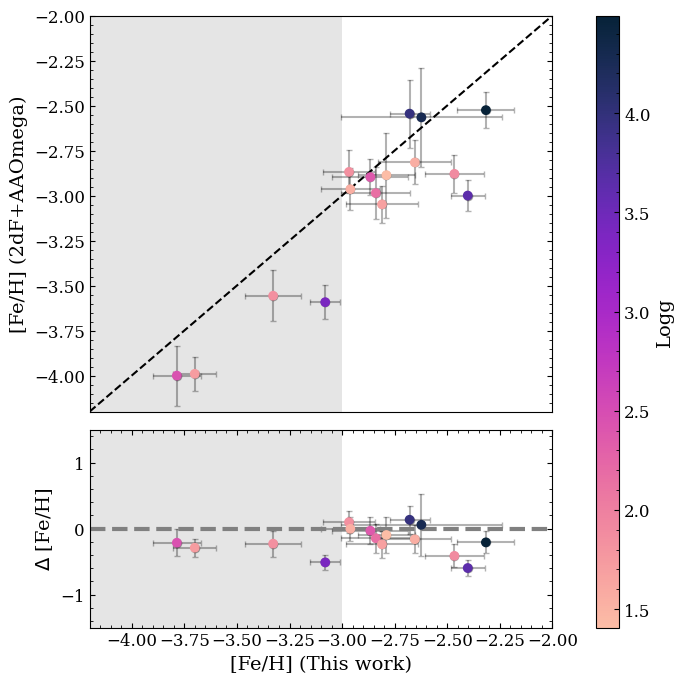

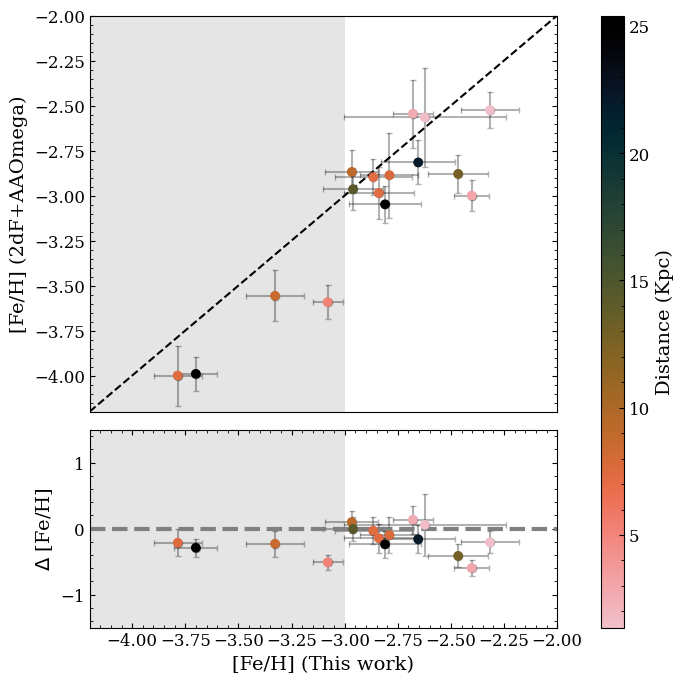

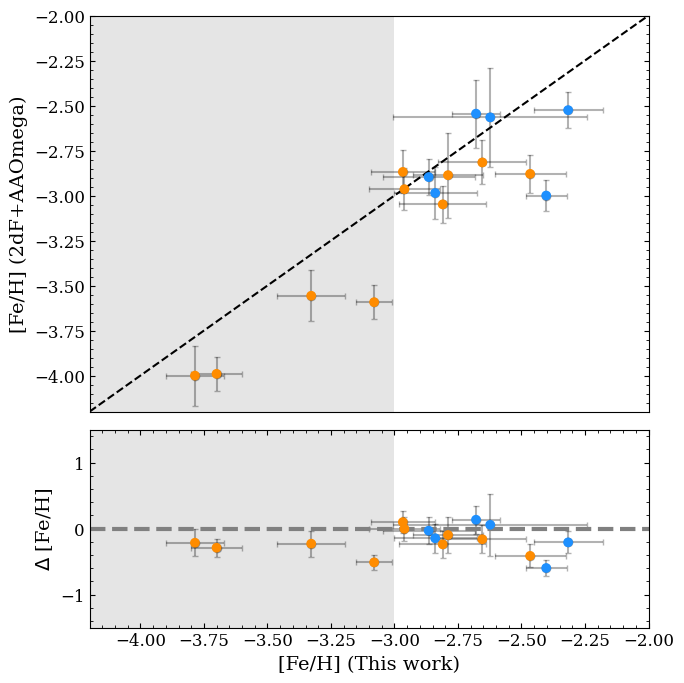

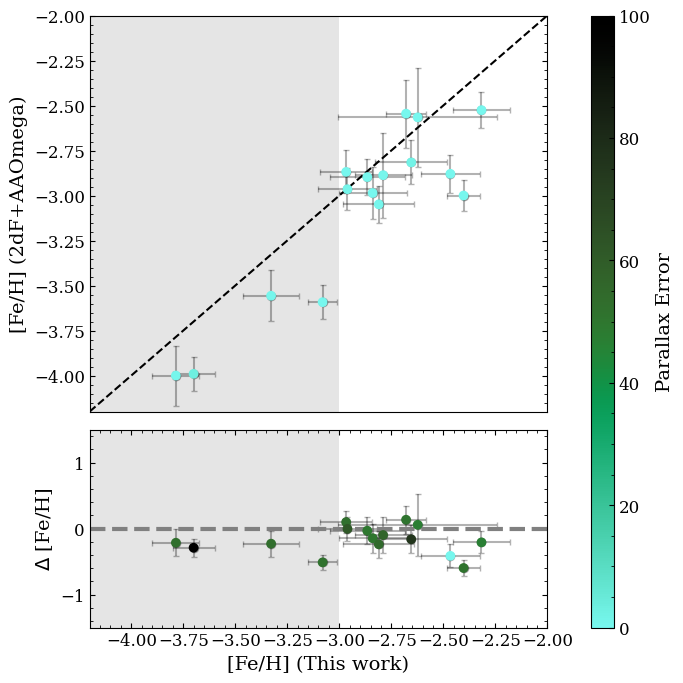

In [14]:
# Loading in the data
# X-Shooter data
xshooter_new_data= pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final/stellar_params.csv').sort_values(by='star_id')
xshooter_new_feh = xshooter_new_data['Fe_it2'].to_numpy()
xshooter_new_feh_err = xshooter_new_data['Fe_tefferr'].to_numpy()

# AAT data
aat_data= pd.read_csv('/data/misfit/benlowe/xshooter/stellar_params/emp_params_FINAL.csv').sort_values(by='star_id')
aat_feh = aat_data['z'].to_numpy()
aat_feh_err = aat_data['randz_std'].to_numpy()
teff = aat_data['teff'].to_numpy()
logg = aat_data['logg'].to_numpy()
plx_flag = aat_data['good_plx'].to_numpy()
plx_err = 1/aat_data['parallax_over_error'].to_numpy()
dist = aat_data['dist'].to_numpy()



# Plotting - teff colorbar
fig = plt.figure(figsize=[7,7])
gs = fig.add_gridspec(2, 2, wspace=0.1, hspace=0.03, width_ratios=[1, 0.05], height_ratios=[2, 1])

# Add subplots using the GridSpec object
ax1 = fig.add_subplot(gs[0, 0])  # Row 0, Column 0
ax2 = fig.add_subplot(gs[1, 0])  # Row 1, Column 0
cbar = fig.add_subplot(gs[0:2, 1])  # Row 0:2, Column 1

# Remove x-ticks from ax1 and cbar
ax1.set_xticks([])
cbar.set_xticks([])

# Main plot
cmap = ax1.scatter(xshooter_new_feh, aat_feh, c=teff, zorder=10, cmap=cmr.gem_r)
ax1.errorbar(xshooter_new_feh, aat_feh, xerr=xshooter_new_feh_err, yerr=aat_feh_err, fmt='o', color='black', alpha=0.3, zorder=1)
ax1.plot([-4.2, -2.0], [-4.2, -2.0], color='black', linestyle='--')

rectangle = plt.Rectangle((-4.2, -4.2), 1.2, 2.5, facecolor='grey', alpha=0.2, zorder=-10)
ax1.add_patch(rectangle)
ax1.set_xlim(-4.2, -2.0)
ax1.set_ylim(-4.2, -2.0)
ax1.set_ylabel('[Fe/H] (2dF+AAOmega)')


# Difference plot
ax2.scatter(xshooter_new_feh, aat_feh-xshooter_new_feh, c=teff, zorder=10, cmap=cmr.gem_r)
ax2.errorbar(xshooter_new_feh, aat_feh-xshooter_new_feh, yerr=np.sqrt(xshooter_new_feh_err**2 + aat_feh_err**2), 
             xerr=xshooter_new_feh_err, fmt='o', color='black', alpha=0.3, zorder=1)


rectangle = plt.Rectangle((-4.2, -2), 1.2, 5, facecolor='grey', alpha=0.2, zorder=-10)
ax2.add_patch(rectangle)
ax2.axhline(0, color='grey', linestyle='--', linewidth=3)
ax2.set_xlabel("[Fe/H] (This work)")
ax2.set_ylabel("$\Delta$ [Fe/H]")
ax2.set_xlim(-4.2, -2.0)
ax2.set_ylim(bottom=-1.5, top=1.5)

# Colorbar
cbar = fig.colorbar(cmap, cax=cbar, label='Teff (K)')

gs.tight_layout(fig)

plt.savefig("/data/misfit/benlowe/results/aat_comparision/aat_xshooter_feh_teff.png", dpi=300, transparent=False, facecolor="white")



# Plotting - logg colorbar
fig = plt.figure(figsize=[7,7])
gs = fig.add_gridspec(2, 2, wspace=0.1, hspace=0.03, width_ratios=[1, 0.05], height_ratios=[2, 1])

# Add subplots using the GridSpec object
ax1 = fig.add_subplot(gs[0, 0])  # Row 0, Column 0
ax2 = fig.add_subplot(gs[1, 0])  # Row 1, Column 0
cbar = fig.add_subplot(gs[0:2, 1])  # Row 0:2, Column 1

# Remove x-ticks from ax1 and cbar
ax1.set_xticks([])
cbar.set_xticks([])

# Main plot
cmap = ax1.scatter(xshooter_new_feh, aat_feh, c=logg, zorder=10, cmap=cmr.bubblegum_r)
ax1.errorbar(xshooter_new_feh, aat_feh, xerr=xshooter_new_feh_err, yerr=aat_feh_err, fmt='o', color='black', alpha=0.3, zorder=1)
ax1.plot([-4.2, -2.0], [-4.2, -2.0], color='black', linestyle='--')

rectangle = plt.Rectangle((-4.2, -4.2), 1.2, 2.5, facecolor='grey', alpha=0.2, zorder=-10)
ax1.add_patch(rectangle)
ax1.set_xlim(-4.2, -2.0)
ax1.set_ylim(-4.2, -2.0)
ax1.set_ylabel('[Fe/H] (2dF+AAOmega)')


# Difference plot
ax2.scatter(xshooter_new_feh, aat_feh-xshooter_new_feh, c=logg, zorder=10, cmap=cmr.bubblegum_r)
ax2.errorbar(xshooter_new_feh, aat_feh-xshooter_new_feh, yerr=np.sqrt(xshooter_new_feh_err**2 + aat_feh_err**2), 
             xerr=xshooter_new_feh_err, fmt='o', color='black', alpha=0.3, zorder=1)


rectangle = plt.Rectangle((-4.2, -2), 1.2, 5, facecolor='grey', alpha=0.2, zorder=-10)
ax2.add_patch(rectangle)
ax2.axhline(0, color='grey', linestyle='--', linewidth=3)
ax2.set_xlabel("[Fe/H] (This work)")
ax2.set_ylabel("$\Delta$ [Fe/H]")
ax2.set_xlim(-4.2, -2.0)
ax2.set_ylim(bottom=-1.5, top=1.5)

# Colorbar
cbar = fig.colorbar(cmap, cax=cbar, label='Logg')

gs.tight_layout(fig)

plt.savefig("/data/misfit/benlowe/results/aat_comparision/aat_xshooter_feh_logg.png", dpi=300, transparent=False, facecolor="white")



# Plotting - distance colorbar
fig = plt.figure(figsize=[7,7])
gs = fig.add_gridspec(2, 2, wspace=0.1, hspace=0.03, width_ratios=[1, 0.05], height_ratios=[2, 1])

# Add subplots using the GridSpec object
ax1 = fig.add_subplot(gs[0, 0])  # Row 0, Column 0
ax2 = fig.add_subplot(gs[1, 0])  # Row 1, Column 0
cbar = fig.add_subplot(gs[0:2, 1])  # Row 0:2, Column 1

# Remove x-ticks from ax1 and cbar
ax1.set_xticks([])
cbar.set_xticks([])

# Main plot
cmap = ax1.scatter(xshooter_new_feh, aat_feh, c=dist, zorder=10, cmap=cmr.dusk_r)
ax1.errorbar(xshooter_new_feh, aat_feh, xerr=xshooter_new_feh_err, yerr=aat_feh_err, fmt='o', color='black', alpha=0.3, zorder=1)
ax1.plot([-4.2, -2.0], [-4.2, -2.0], color='black', linestyle='--')

rectangle = plt.Rectangle((-4.2, -4.2), 1.2, 2.5, facecolor='grey', alpha=0.2, zorder=-10)
ax1.add_patch(rectangle)
ax1.set_xlim(-4.2, -2.0)
ax1.set_ylim(-4.2, -2.0)
ax1.set_ylabel('[Fe/H] (2dF+AAOmega)')


# Difference plot
ax2.scatter(xshooter_new_feh, aat_feh-xshooter_new_feh, c=dist, zorder=10, cmap=cmr.dusk_r)
ax2.errorbar(xshooter_new_feh, aat_feh-xshooter_new_feh, yerr=np.sqrt(xshooter_new_feh_err**2 + aat_feh_err**2), 
             xerr=xshooter_new_feh_err, fmt='o', color='black', alpha=0.3, zorder=1)


rectangle = plt.Rectangle((-4.2, -2), 1.2, 5, facecolor='grey', alpha=0.2, zorder=-10)
ax2.add_patch(rectangle)
ax2.axhline(0, color='grey', linestyle='--', linewidth=3)
ax2.set_xlabel("[Fe/H] (This work)")
ax2.set_ylabel("$\Delta$ [Fe/H]")
ax2.set_xlim(-4.2, -2.0)
ax2.set_ylim(bottom=-1.5, top=1.5)

# Colorbar
cbar = fig.colorbar(cmap, cax=cbar, label='Distance (Kpc)')

gs.tight_layout(fig)

plt.savefig("/data/misfit/benlowe/results/aat_comparision/aat_xshooter_feh_dist.png", dpi=300, transparent=False, facecolor="white")


# Plotting - good parallax colorbar
fig = plt.figure(figsize=[7,7])
gs = fig.add_gridspec(2, 1, wspace=0.1, hspace=0.03, width_ratios=[1], height_ratios=[2, 1])

# Add subplots using the GridSpec object
ax1 = fig.add_subplot(gs[0, 0])  # Row 0, Column 0
ax2 = fig.add_subplot(gs[1, 0])  # Row 1, Column 0

# Remove x-ticks from ax1 and cbar
ax1.set_xticks([])

# Main plot
colors = []
for i in plx_flag:
    if i == 'yes':
        colors.append("dodgerblue")
        
    if i == 'no':
        colors.append("darkorange")


# Main plot
ax1.scatter(xshooter_new_feh, aat_feh, c=colors, zorder=10)
ax1.errorbar(xshooter_new_feh, aat_feh, xerr=xshooter_new_feh_err, yerr=aat_feh_err, fmt='o', color='black', alpha=0.3, zorder=1)
ax1.plot([-4.2, -2.0], [-4.2, -2.0], color='black', linestyle='--')

rectangle = plt.Rectangle((-4.2, -4.2), 1.2, 2.5, facecolor='grey', alpha=0.2, zorder=-10)
ax1.add_patch(rectangle)
ax1.set_xlim(-4.2, -2.0)
ax1.set_ylim(-4.2, -2.0)
ax1.set_ylabel('[Fe/H] (2dF+AAOmega)')


# Difference plot
ax2.scatter(xshooter_new_feh, aat_feh-xshooter_new_feh, c=colors, zorder=10, cmap=cmr.dusk_r)
ax2.errorbar(xshooter_new_feh, aat_feh-xshooter_new_feh, yerr=np.sqrt(xshooter_new_feh_err**2 + aat_feh_err**2), 
             xerr=xshooter_new_feh_err, fmt='o', color='black', alpha=0.3, zorder=1)


rectangle = plt.Rectangle((-4.2, -2), 1.2, 5, facecolor='grey', alpha=0.2, zorder=-10)
ax2.add_patch(rectangle)
ax2.axhline(0, color='grey', linestyle='--', linewidth=3)
ax2.set_xlabel("[Fe/H] (This work)")
ax2.set_ylabel("$\Delta$ [Fe/H]")
ax2.set_xlim(-4.2, -2.0)
ax2.set_ylim(bottom=-1.5, top=1.5)

gs.tight_layout(fig)

plt.savefig("/data/misfit/benlowe/results/aat_comparision/aat_xshooter_feh_plxflag.png", dpi=300, transparent=False, facecolor="white")


# Plotting - parallax error colorbar
fig = plt.figure(figsize=[7,7])
gs = fig.add_gridspec(2, 2, wspace=0.1, hspace=0.03, width_ratios=[1, 0.05], height_ratios=[2, 1])

# Add subplots using the GridSpec object
ax1 = fig.add_subplot(gs[0, 0])  # Row 0, Column 0
ax2 = fig.add_subplot(gs[1, 0])  # Row 1, Column 0
cbar = fig.add_subplot(gs[0:2, 1])  # Row 0:2, Column 1

# Remove x-ticks from ax1 and cbar
ax1.set_xticks([])
cbar.set_xticks([])

# Main plot
cmap = ax1.scatter(xshooter_new_feh, aat_feh, c=plx_err, zorder=10, cmap=cmr.emerald_r, vmin=0, vmax=100)
ax1.errorbar(xshooter_new_feh, aat_feh, xerr=xshooter_new_feh_err, yerr=aat_feh_err, fmt='o', color='black', alpha=0.3, zorder=1)
ax1.plot([-4.2, -2.0], [-4.2, -2.0], color='black', linestyle='--')

rectangle = plt.Rectangle((-4.2, -4.2), 1.2, 2.5, facecolor='grey', alpha=0.2, zorder=-10)
ax1.add_patch(rectangle)
ax1.set_xlim(-4.2, -2.0)
ax1.set_ylim(-4.2, -2.0)
ax1.set_ylabel('[Fe/H] (2dF+AAOmega)')


# Difference plot
ax2.scatter(xshooter_new_feh, aat_feh-xshooter_new_feh, c=plx_err, zorder=10, cmap=cmr.emerald_r)
ax2.errorbar(xshooter_new_feh, aat_feh-xshooter_new_feh, yerr=np.sqrt(xshooter_new_feh_err**2 + aat_feh_err**2), 
             xerr=xshooter_new_feh_err, fmt='o', color='black', alpha=0.3, zorder=1)


rectangle = plt.Rectangle((-4.2, -2), 1.2, 5, facecolor='grey', alpha=0.2, zorder=-10)
ax2.add_patch(rectangle)
ax2.axhline(0, color='grey', linestyle='--', linewidth=3)
ax2.set_xlabel("[Fe/H] (This work)")
ax2.set_ylabel("$\Delta$ [Fe/H]")
ax2.set_xlim(-4.2, -2.0)
ax2.set_ylim(bottom=-1.5, top=1.5)

# Colorbar
cbar = fig.colorbar(cmap, cax=cbar, label='Parallax Error')

gs.tight_layout(fig)

plt.savefig("/data/misfit/benlowe/results/aat_comparision/aat_xshooter_feh_plxerror.png", dpi=300, transparent=False, facecolor="white")



Comparing the [C/Fe] abundances from X-Shooter with AAT

In [19]:
stars_data

,star_id,Fe_it2,teff,logg,Mg_I_xfe_it2,Mg_I_xh_it2,Mg_I_xfe_tefferr,Ca_II_xfe_it2,Ca_II_xh_it2,Ca_II_xfe_tefferr,...,Sc_II_xfe_tefferr,Sr_II_xfe_it2,Sr_II_xh_it2,Sr_II_xfe_tefferr,N_I_xfe_it2,N_I_xh_it2,N_I_xfe_tefferr,C_I_xfe_it2,C_I_xh_it2,C_I_xfe_tefferr
0,ra_0103-7050_s163,-2.316444,6298.806689,4.492229,0.223997,-2.092447,0.097545,0.144885,-2.171559,0.070094,...,0.050548,0.019595,-2.296849,0.075953,-4.227195,-6.543638,0.171153,0.372516,-1.943928,0.204510
1,ra_0834-5220_s316,-2.623191,5959.304567,4.286104,0.434260,-2.188931,0.118313,0.335718,-2.287473,0.081916,...,0.046567,0.201461,-2.421730,0.087047,0.025847,-2.597344,0.188158,0.276993,-2.346198,0.194023
2,ra_1604-2712_s24,-2.466047,5002.684528,1.891750,0.404122,-2.061925,0.126191,0.218059,-2.247989,0.074768,...,0.129976,-0.244649,-2.710696,0.091956,0.210444,-2.255603,0.230134,0.013734,-2.452313,0.227440
3,ra_1604-2712_s292,-3.080278,5783.249268,3.404600,0.177362,-2.902916,0.098711,0.327977,-2.752302,0.057867,...,0.057845,-1.213389,-4.293667,0.064907,-2.199449,-5.279727,0.104513,0.116186,-2.964092,0.238927
4,ra_1624-2150_s278,-2.679156,6381.865006,3.973617,0.068757,-2.610399,0.247877,0.127461,-2.551696,0.215030,...,0.051797,-0.299866,-2.979022,0.062802,0.959545,-1.719611,0.197231,0.401335,-2.277821,0.342573
5,ra_1633-2814_s130,-3.327966,4997.869004,1.849800,0.539619,-2.788346,0.079791,0.295623,-3.032343,0.067503,...,0.036249,-1.272750,-4.600716,0.067054,1.562017,-1.765949,0.245105,0.178908,-3.149058,0.229133
6,ra_1633-2814_s284,-3.785562,5261.142090,2.447800,0.401788,-3.383774,0.109950,0.516842,-3.268720,0.050132,...,0.062219,0.454392,-3.331170,0.076957,-3.323878,-7.109440,0.004546,0.644624,-3.140938,0.220257
7,ra_1648-0653_s38,-2.402750,6039.830368,3.646778,0.338384,-2.064366,0.101289,0.238750,-2.164000,0.061265,...,0.054207,-0.023138,-2.425888,0.075408,0.064774,-2.337976,0.221664,0.395410,-2.007340,0.206741
8,ra_1656-1433_s143,-2.789339,4791.462397,1.406800,0.429458,-2.359881,0.091310,0.350262,-2.439077,0.064424,...,0.123892,1.141303,-1.648036,0.099689,1.207374,-1.581964,0.180065,-2.767071,-5.556410,3.355134
9,ra_1658-2454_s22,-2.839827,4852.253676,2.164886,0.279424,-2.560402,0.179879,0.300496,-2.539331,0.070875,...,0.185349,-0.497207,-3.337034,0.090286,-3.973221,-6.813047,0.032640,-0.345457,-3.185284,0.231005


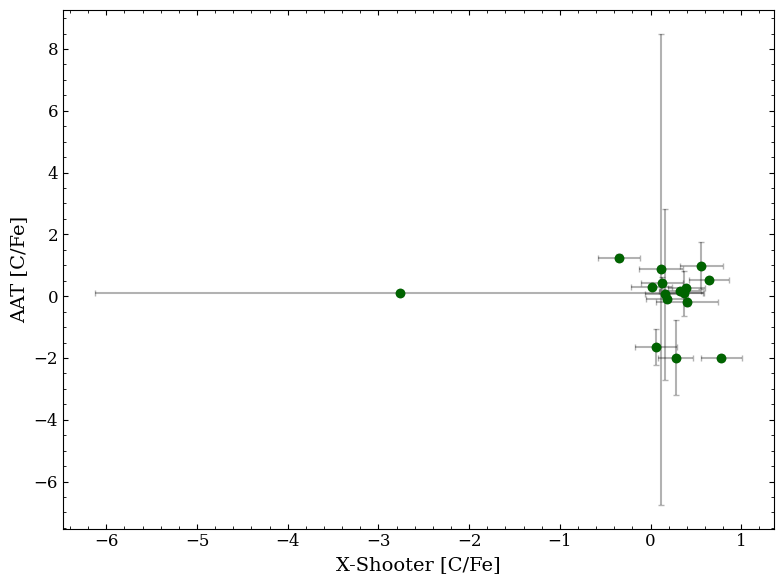

In [17]:
# Loading in the data
# X-Shooter data
xshooter_cfe = stars_data['C_I_xfe_it2'].to_numpy()
xshooter_cfe_err = stars_data['C_I_xfe_tefferr'].to_numpy()

# AAT data
aat_data= pd.read_csv('/data/misfit/benlowe/xshooter/stellar_params/emp_params_FINAL.csv')
aat_cfe = aat_data['cfe'].to_numpy()
aat_cfe_err = aat_data['randcarb_std'].to_numpy()


# Plotting
plt.figure(figsize=[8,6])
plt.scatter(xshooter_cfe, aat_cfe, color='darkgreen', zorder=10)
plt.errorbar(xshooter_cfe, aat_cfe, xerr=xshooter_cfe_err, yerr=aat_cfe_err, fmt='o', color='black', alpha=0.3, zorder=1)
# plt.plot([-4.2, -2.0], [-4.2, -2.0], color='black', linestyle='--')

plt.xlabel('X-Shooter [C/Fe]')
plt.ylabel('AAT [C/Fe]')
plt.tight_layout()
# plt.savefig("/data/misfit/benlowe/results/aat_comparision/aat_xshooter_feh_v2.png", dpi=300, transparent=False, facecolor="white")


## Looking at abundances for each star

In [24]:
star_data[star_data['el'] == 'Sc_II']

,star_id,teff,logg,vmic,vsini,feh,feh_err,el,detection,upper_limit_xfe,...,bestfit_abund_tefferr_xfe,bestfit_abund_tefferr_xh,bestfit_abund_loggerr_xfe,bestfit_abund_loggerr_xh,Jp,Jtot,Jz,Jr,zmax,orbit
268,ra_1853-3255_s45,5033.857005,2.378863,1.678355,0,-2.865494,0.180771,Sc_II,Y,NaN,...,0.0,0.0,0.0,0.0,146.169821,311.685356,271.314839,46.587584,2.652041,halo


/tmp/ipykernel_3090385/3134575689.py:103: DeprecationWarning: The truth value of an empty array is ambiguous. Returning False, but in future this will result in an error. Use `array.size > 0` to check that an array is not empty.
  if detection == 'Y':
/tmp/ipykernel_3090385/3134575689.py:138: DeprecationWarning: The truth value of an empty array is ambiguous. Returning False, but in future this will result in an error. Use `array.size > 0` to check that an array is not empty.
  elif detection == 'N':


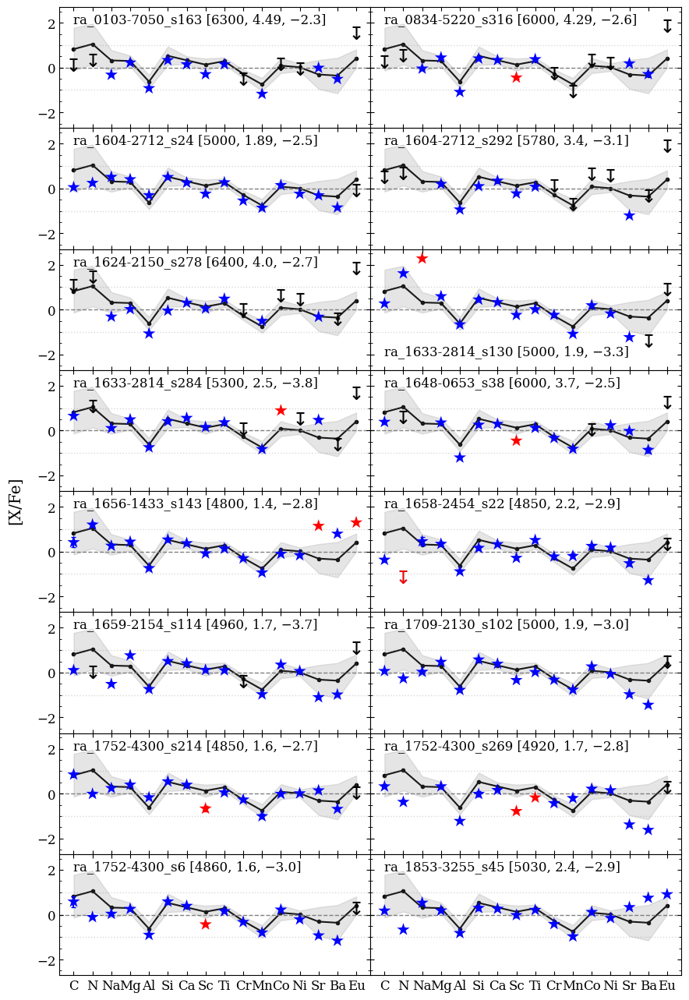

In [23]:
el_list = ['C', 'N', 'Na', 'Mg', 'Al', 'Si', 'Ca', 'Sc',
           'Ti', 'Cr', 'Mn', 'Co', 'Ni', 'Sr', 'Ba', 'Eu']

# Separating the upper-limits for each element
bad_na_stars = ['ra_1604-2712_s292', 'ra_1648-0653_s38', 'ra_1752-4300_s269'] # These stars have interstellar Na contamination, so we remove them

stars = stars_data['star_id'].to_numpy()

# Taking the mean if the literature  (in order with above el_list)
mean_lit_abunds = [cI_lit_abund['abund'].mean(), nI_lit_abund['abund'].mean(), naI_lit_abund['abund'].mean(),
                    mgI_lit_abund['abund'].mean(), alI_lit_abund['abund'].mean(), siI_lit_abund['abund'].mean(),
                    caI_lit_abund['abund'].mean(), scII_lit_abund['abund'].mean(), tiII_lit_abund['abund'].mean(),
                    crI_lit_abund['abund'].mean(), mnI_lit_abund['abund'].mean(), coI_lit_abund['abund'].mean(),
                    niI_lit_abund['abund'].mean(), srII_lit_abund['abund'].mean(), baII_lit_abund['abund'].mean(),
                    euII_lit_abund['abund'].mean()]
std_lit_abunds = [cI_lit_abund['abund'].std(), nI_lit_abund['abund'].std(), naI_lit_abund['abund'].std(),
                    mgI_lit_abund['abund'].std(), alI_lit_abund['abund'].std(), siI_lit_abund['abund'].std(),
                    caI_lit_abund['abund'].std(), scII_lit_abund['abund'].std(), tiII_lit_abund['abund'].std(),
                    crI_lit_abund['abund'].std(), mnI_lit_abund['abund'].std(), coI_lit_abund['abund'].std(),
                    niI_lit_abund['abund'].std(), srII_lit_abund['abund'].std(), baII_lit_abund['abund'].std(),
                    euII_lit_abund['abund'].std()]

# Loading in the rounded stellar parameters
params_rounded = pd.read_csv('/data/misfit/benlowe/xshooter/stellar_params/star_params_rd.csv')

fig, axs = plt.subplots(8, 2, figsize=[9, 13], tight_layout=True, sharex=True, sharey=True, gridspec_kw={'wspace': 0, 'hspace': 0})
fig.subplots_adjust(wspace=0.25)
# fig.supxlabel('[Fe/H]')
fig.supylabel('[X/Fe]')


for ax, star in zip(axs.flat, stars):
    
    # Plotting the mean abundances from the literature
    ax.plot(el_list, mean_lit_abunds, color='black', zorder=-1, marker='.')
    ax.fill_between(el_list, np.array(mean_lit_abunds) - np.array(std_lit_abunds), 
                    np.array(mean_lit_abunds) + np.array(std_lit_abunds), color='grey', alpha=0.2, zorder=-1)


    # Getting the entries for the star
    star_data = stars_upperlimits[stars_upperlimits['star_id'] == star]
    
    # Stellar parameters
    star_teff = params_rounded[params_rounded['star_id'] == star]['teff'].to_numpy()[0]
    star_logg = params_rounded[params_rounded['star_id'] == star]['logg'].to_numpy()[0]
    star_feh = params_rounded[params_rounded['star_id'] == star]['feh'].to_numpy()[0]
    
    # Separating star data by element, then storing into list
    al_I_abund = al_I_abunds[al_I_abunds['star_id'] == star]
    ba_II_abund = ba_II_abunds[ba_II_abunds['star_id'] == star]
    c_I_abund = c_I_abunds[c_I_abunds['star_id'] == star]
    ca_II_abund = ca_II_abunds[ca_II_abunds['star_id'] == star]
    co_I_abund = co_I_abunds[co_I_abunds['star_id'] == star]
    cr_I_abund = cr_I_abunds[cr_I_abunds['star_id'] == star]
    eu_II_abund = eu_II_abunds[eu_II_abunds['star_id'] == star]
    mg_I_abund = mg_I_abunds[mg_I_abunds['star_id'] == star]
    mn_I_abund = mn_I_abunds[mn_I_abunds['star_id'] == star]
    n_I_abund = n_I_abunds[n_I_abunds['star_id'] == star]
    na_I_abund = na_I_abunds[na_I_abunds['star_id'] == star]
    ni_I_abund = ni_I_abunds[ni_I_abunds['star_id'] == star]
    sc_II_abund = sc_II_abunds[sc_II_abunds['star_id'] == star]
    si_I_abund = si_I_abunds[si_I_abunds['star_id'] == star]
    sr_II_abund = sr_II_abunds[sr_II_abunds['star_id'] == star]
    ti_II_abund = ti_II_abunds[ti_II_abunds['star_id'] == star]
    # ba_II_abund = star_data[star_data['el'] == 'Ba_II']
    # c_I_abund = star_data[(star_data['el'] == 'C_I') & (star_data['teff'] < 5300)]
    # ca_II_abund = star_data[star_data['el'] == 'Ca_II']
    # co_I_abund = star_data[star_data['el'] == 'Co_I']
    # cr_I_abund = star_data[star_data['el'] == 'Cr_I']
    # eu_II_abund = star_data[star_data['el'] == 'Eu_II']
    # mg_I_abund = star_data[star_data['el'] == 'Mg_I']
    # mn_I_abund = star_data[star_data['el'] == 'Mn_I']
    # n_I_abund = star_data[(star_data['el'] == 'N_I') & (star_data['teff'] < 5300)]
    # na_I_abund = star_data[(star_data['el'] == 'Na_I') & (~star_data['star_id'].isin(bad_na_stars))]
    # ni_I_abund = star_data[star_data['el'] == 'Ni_I']
    # sc_II_abund = star_data[star_data['el'] == 'Sc_II']
    # si_I_abund = star_data[star_data['el'] == 'Si_I']
    # sr_II_abund = star_data[star_data['el'] == 'Sr_II']
    # ti_II_abund = star_data[star_data['el'] == 'Ti_II']
    
    # # For star ra_1656-1433_s143, change [C/Fe] abundance to first iteration (instead of second iteration)
    # if star == 'ra_1656-1433_s143':
    #     c_I_abunds['bestfit_abund_comberr_xfe'] = c_I_abunds['bestfit_abund_tefferr_xfe']
        
    # if star == 'ra_1752-4300_s6':
    #     c_I_abunds['bestfit_abund_comberr_xfe'] = c_I_abunds['bestfit_abund_tefferr_xfe']
            
    star_abund = [
        c_I_abund, n_I_abund, na_I_abund, mg_I_abund, al_I_abund, si_I_abund,
        ca_II_abund, sc_II_abund, ti_II_abund, cr_I_abund, mn_I_abund,
        co_I_abund, ni_I_abund, sr_II_abund, ba_II_abund, eu_II_abund
    ]
        
    # Plotting each element
    # - If detection is 'Y', plot the abundance with error bars
    # - If detection is 'N', plot the upper limit 
    abunds = [] # This contains both detections and upper limits for the star - for connecting line
    el_names = []
    for i, el_abund in enumerate(star_abund):
        detection = el_abund['detection'].to_numpy()
        
        
        if detection == 'Y':
            el = el_list[i]
            abund_val = el_abund['bestfit_abund_xfe'].to_numpy()
            abund_val_err = el_abund['bestfit_abund_comberr_xfe'].to_numpy()[0]
            
            # If the abundance value is empty, skip to the next element
            if len(abund_val) == 0:
                continue
            else:
                abunds.append(abund_val[0])
                el_names.append(el)
                
            
            # Computing the difference between the abundance value and the mean literature abundance.
            ith_lit_abund = mean_lit_abunds[i]
            ith_lit_std = std_lit_abunds[i]
            obs_lit_diff = abs(abund_val[0] - ith_lit_abund)
            
            # Seeing if the abundance value is within 2 sigma of the literature value
            lower_bound = ith_lit_abund - 2 * ith_lit_std
            upper_bound = ith_lit_abund + 2 * ith_lit_std

            if lower_bound <= abund_val <= upper_bound:
                abund_color = 'blue'
            else:
                abund_color = 'red'
                        
            # if obs_lit_diff > 0.5:
            #     abund_color = 'red'
            # else:
            #     abund_color = 'blue'
            
            ax.scatter(el, abund_val, color=abund_color, marker='*', s=150, edgecolor='none', zorder=3)
            ax.errorbar(x=el, y=abund_val, yerr=abund_val_err, color=abund_color, alpha=1, zorder=1, linestyle='')
            
        elif detection == 'N':
            
            el = el_list[i]
            abund_ul = el_abund['upper_limit_xfe'].to_numpy()
            abund_val = el_abund['bestfit_abund_xfe'].to_numpy()
            
            # If the abundance value is empty, skip to the next element
            if len(abund_val) == 0:
                continue
            else:
                abunds.append(abund_ul[0])
                el_names.append(el)      
            
            # If the upper limit is greater than 2sigma from the literature value, plot it in red
            ith_lit_abund = mean_lit_abunds[i]
            ith_lit_std = std_lit_abunds[i]
            obs_lit_diff = abs(abund_ul[0] - ith_lit_abund)
            lower_bound = ith_lit_abund - 2 * ith_lit_std
            upper_bound = ith_lit_abund + 2 * ith_lit_std
            
            if abund_ul < lower_bound:
                abund_color = 'red'
            else:
                abund_color = 'black'
            
            ax.scatter(el, abund_ul, color=abund_color, zorder=5, 
            marker='${↧}$', s=150, linewidths=0.1, edgecolor='black')
            
    
    # Pllotting horizontal lines
    ax.axhline(y=0, color='grey', linestyle='--', linewidth=1, zorder=0)
    ax.axhline(y=-1, color='grey', linestyle=':', linewidth=1, zorder=0, alpha=0.3)
    ax.axhline(y=1, color='grey', linestyle=':', linewidth=1, zorder=0, alpha=0.3)

    if star == 'ra_1633-2814_s130':
        ax.text(s = f"{star} [{star_teff}, {star_logg}, {star_feh}]", y = -2, x = el_list[0], fontsize=12, color='black')
    else:
        ax.text(s = f"{star} [{star_teff}, {star_logg}, {star_feh}]", y = 2, x = el_list[0], fontsize=12, color='black')

    # Plotting the connecting line between the abundances
    # ax.plot(el_names, abunds, linestyle='-', color='black', alpha=0.5)
    
    
    ax.set_ylim(-2.7, 2.7)
    ax.xaxis.set_minor_locator(plt.NullLocator())
        
    # display(na_I_abunds)
    
    
plt.savefig("/data/misfit/benlowe/xshooter/results/star_abunds/abunds_trend_v12.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/results/star_abunds/abunds_trend_v12.png", dpi=300, transparent=False, facecolor="white")

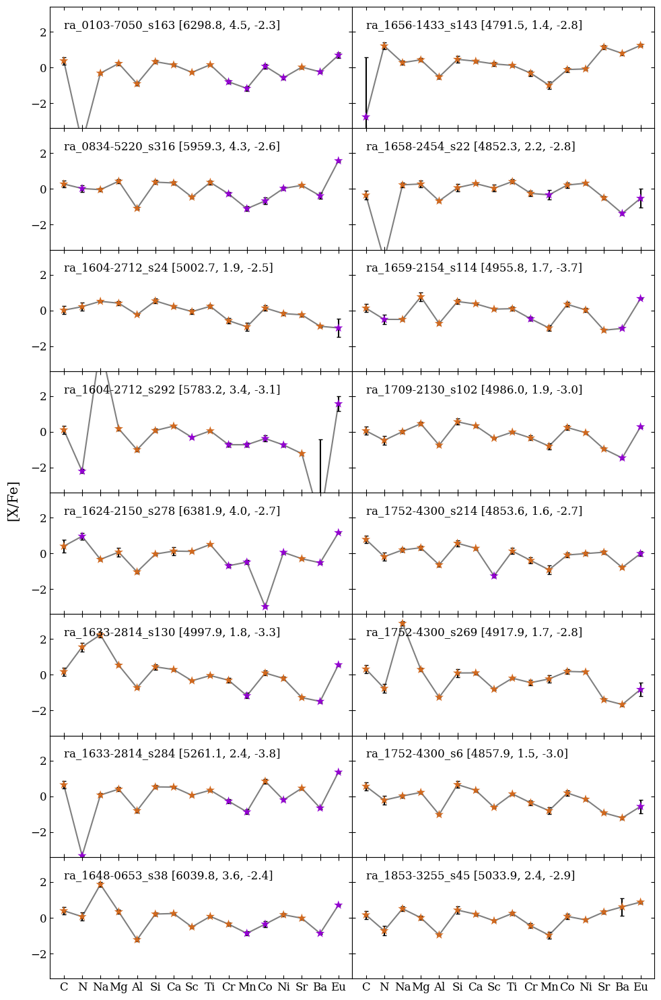

In [23]:
def abunds_trend(abunds_data, detections):
    
    stars = abunds_data['star_id'].to_numpy()
    fig, axs = plt.subplots(8, 2, figsize=[10, 15], tight_layout=True, sharex=True, sharey=True, gridspec_kw={'wspace': 0, 'hspace': 0})
    
    for k, star in enumerate(stars):
        
        # List of elements
        elements = ['C', 'N', 'Na', 'Mg', 'Al', 'Si', 'Ca', 'Sc', 'Ti', 'Cr', 'Mn', 'Co', 'Ni', 'Sr', 'Ba', 'Eu']
        
        # Getting the abundance data  (and errors) for the star
        star_data = abunds_data[abunds_data['star_id'] == star]
        star_abunds = star_data[['C_I_xfe_it2', 'N_I_xfe_it2', 'Na_I_xfe_it2', 'Mg_I_xfe_it2',
                                 'Al_I_xfe_it2', 'Si_I_xfe_it2', 'Ca_II_xfe_it2', 'Sc_II_xfe_it2',
                                 'Ti_II_xfe_it2', 'Cr_I_xfe_it2', 'Mn_I_xfe_it2', 'Co_I_xfe_it2',
                                 'Ni_I_xfe_it2', 'Sr_II_xfe_it2', 'Ba_II_xfe_it2', 'Eu_II_xfe_it2']]
        star_abunds_err = star_data[['C_I_xfe_tefferr', 'N_I_xfe_tefferr', 'Na_I_xfe_tefferr', 'Mg_I_xfe_tefferr',
                                     'Al_I_xfe_tefferr', 'Si_I_xfe_tefferr', 'Ca_II_xfe_tefferr', 'Sc_II_xfe_tefferr',
                                     'Ti_II_xfe_tefferr', 'Cr_I_xfe_tefferr', 'Mn_I_xfe_tefferr', 'Co_I_xfe_tefferr',
                                     'Ni_I_xfe_tefferr', 'Sr_II_xfe_tefferr', 'Ba_II_xfe_tefferr', 'Eu_II_xfe_tefferr']]
        
        # Getting the stellar parameters for the star
        star_feh = star_data['Fe_it2'].to_numpy()[0]
        star_teff = star_data['teff'].to_numpy()[0]
        star_logg = star_data['logg'].to_numpy()[0]
        
        # Getting the detections for the star
        star_detects = detections[detections['star_id'] == star] # REPLACE WITH NEW DETECTIONS FILE ONCE DONE
        star_abund_detects = star_detects[['C_I', 'N_I', 'Na_I', 'Mg_I', 'Al_I', 'Si_I', 'Ca_II', 'Sc_II',
                                           'Ti_II', 'Cr_I', 'Mn_I', 'Co_I', 'Ni_I', 'Sr_II', 'Ba_II', 'Eu_II']]
        
        # Creating the figure for the star
        # plt.figure(figsize=[10,5])
        
        
        # axs[0,0].plot(elements, star_abunds.to_numpy()[0], linestyle='-', marker='.', color='black', alpha=0.5)
        
        # Plotting will be done as follows:
        # There is 16 stars in total, so we will plot 8 in the first row and 8 in the second row.
        # To ensure we do that, I will initialize j = 0 and increment it for each detection. For 
        # j values < 8, we will plot in the first row, and for j values >= 8, we will plot in the second row.
        for i, el in enumerate(star_abund_detects):
            detect = star_abund_detects[el].to_numpy()[0]
            key_list = star_abunds.keys()
            err_key_list = star_abunds_err.keys()
            
            # Plotting the detections
            if detect == 'Y':
                yes_abund_key = key_list[i]
                yes_abund_val = star_abunds[yes_abund_key].to_numpy()[0]
                yes_err_key = err_key_list[i]
                yes_err_val = star_abunds_err[yes_err_key].to_numpy()[0]
                yes_el = elements[i]
                
                if k < 8:
                    axs[k, 0].scatter(yes_el, yes_abund_val, color='chocolate', marker='*', s=100, edgecolor='none', zorder=3)
                    axs[k, 0].errorbar(x=yes_el, y=yes_abund_val, yerr=yes_err_val, color='black', alpha=1, zorder=1, linestyle='')
                else:
                    axs[k-8, 1].scatter(yes_el, yes_abund_val, color='chocolate', marker='*', s=100, edgecolor='none', zorder=3)
                    axs[k-8, 1].errorbar(x=yes_el, y=yes_abund_val, yerr=yes_err_val, color='black', alpha=1, zorder=1, linestyle='')
                                

                
            # Plotting the non-detections
            elif detect == 'N':
                no_abund_key = key_list[i]
                no_abund_val = star_abunds[no_abund_key].to_numpy()[0]
                no_err_key = err_key_list[i]
                no_err_val = star_abunds_err[no_err_key].to_numpy()[0]
                no_el = elements[i]
                
                if k < 8:
                    axs[k, 0].scatter(no_el, no_abund_val, color='darkviolet', marker='*', s=100, edgecolor='none', zorder=3)
                    axs[k, 0].errorbar(x=no_el, y=no_abund_val, yerr=no_err_val, color='black', alpha=1, zorder=1, linestyle='')
                else:
                    axs[k-8, 1].scatter(no_el, no_abund_val, color='darkviolet', marker='*', s=100, edgecolor='none', zorder=3)
                    axs[k-8, 1].errorbar(x=no_el, y=no_abund_val, yerr=no_err_val, color='black', alpha=1, zorder=1, linestyle='')
                    
                        
        # Plotting the connecting line
        if k < 8:
            axs[k, 0].plot(elements, star_abunds.to_numpy()[0], linestyle='-', marker='.', color='black', alpha=0.5)
            axs[k, 0].text(s = f"{star} [{star_teff:.1f}, {star_logg:.1f}, {star_feh:.1f}]", y = 2.2, x = elements[0], fontsize=12, color='black')

        else:
            axs[k-8, 1].plot(elements, star_abunds.to_numpy()[0], linestyle='-', marker='.', color='black', alpha=0.5)
            axs[k-8, 1].text(s = f"{star} [{star_teff:.1f}, {star_logg:.1f}, {star_feh:.1f}]", y = 2.2, x = elements[0], fontsize=12, color='black')
        
        # plt.axhline(y=0, linestyle='dashed', color='black', zorder=0, alpha=0.5)
        plt.gca().minorticks_off()
        plt.ylim(top=3.4, bottom=-3.4)
        fig.supylabel('[X/Fe]')
      
        
abunds_detect = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/abund_detections.csv')


abunds_trend(abunds_data=stars_data, detections=abunds_detect)
plt.tight_layout()
plt.savefig("/data/misfit/benlowe/results/star_abunds/abunds_trend.png", dpi=300, transparent=False, facecolor="white")

ra_1656-1433_s143

Text(0, 0.5, '[X/Fe]')

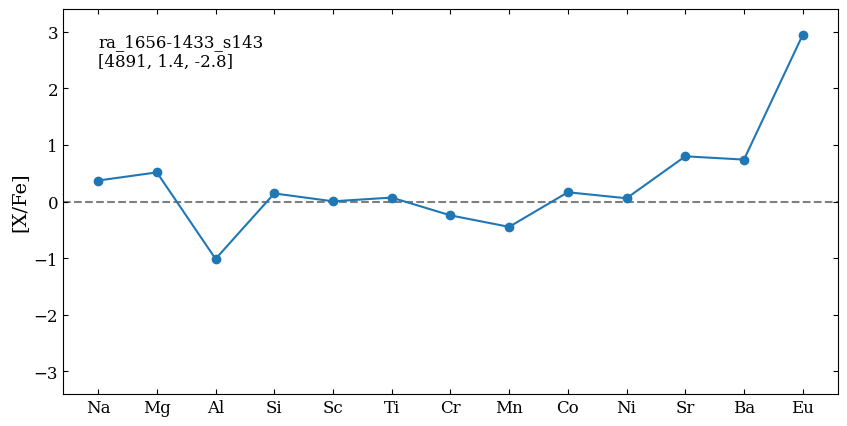

In [ ]:
elements = ['Na', 'Mg', 'Al', 'Si', 'Sc', 'Ti', 'Cr', 'Mn', 'Co', 'Ni', 'Sr', 'Ba', 'Eu']

star = stars_data[stars_data['star_id'] == 'ra_1656-1433_s143']
star_vals = star[['Na_I_xfe_it1', 'Mg_I_xfe_it1', 'Al_I_xfe_it1', 'Si_I_xfe_it1', 'Sc_II_xfe_it1', 'Ti_II_xfe_it1', 'Cr_I_xfe_it1', 'Mn_I_xfe_it1', 
                    'Co_I_xfe_it1', 'Ni_I_xfe_it1', 'Sr_II_xfe_it1', 'Ba_II_xfe_it1', 'Eu_II_xfe_it1']]


plt.figure(figsize=[10,5])
plt.plot(elements, star_vals.to_numpy()[0], linestyle='-', marker='o')
plt.text(s = f"{star['star_id'].to_numpy()[0]}\n[{star['teff'].to_numpy()[0]:.0f}, {star['logg'].to_numpy()[0]:.1f}, {star['Fe_it2'].to_numpy()[0]:.1f}]", y = 2.4, x = "Na", fontsize=12, color='black')
plt.axhline(y=0, linestyle='dashed', color='black', zorder=0, alpha=0.5)
plt.gca().minorticks_off()
plt.ylim(top=3.4, bottom=-3.4)
plt.ylabel('[X/Fe]')

ra_ra_1853-3255_s45

Text(0, 0.5, '[X/Fe]')

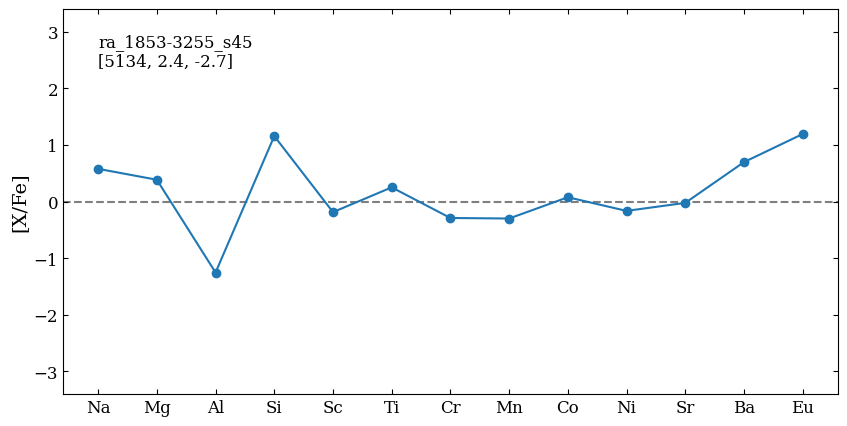

In [ ]:
elements = ['Na', 'Mg', 'Al', 'Si', 'Sc', 'Ti', 'Cr', 'Mn', 'Co', 'Ni', 'Sr', 'Ba', 'Eu']

star = stars_data[stars_data['star_id'] == 'ra_1853-3255_s45']
star_vals = star[['Na_I_xfe_it1', 'Mg_I_xfe_it1', 'Al_I_xfe_it1', 'Si_I_xfe_it1', 'Sc_II_xfe_it1', 'Ti_II_xfe_it1', 'Cr_I_xfe_it1', 'Mn_I_xfe_it1', 
                    'Co_I_xfe_it1', 'Ni_I_xfe_it1', 'Sr_II_xfe_it1', 'Ba_II_xfe_it1', 'Eu_II_xfe_it1']]


plt.figure(figsize=[10,5])
plt.plot(elements, star_vals.to_numpy()[0], linestyle='-', marker='o')
plt.text(s = f"{star['star_id'].to_numpy()[0]}\n[{star['teff'].to_numpy()[0]:.0f}, {star['logg'].to_numpy()[0]:.1f}, {star['Fe_it2'].to_numpy()[0]:.1f}]", y = 2.4, x = "Na", fontsize=12, color='black')
plt.axhline(y=0, linestyle='dashed', color='black', zorder=0, alpha=0.5)
plt.gca().minorticks_off()
plt.ylim(top=3.4, bottom=-3.4)
plt.ylabel('[X/Fe]')

In [29]:
star

,star_id,Fe_it2,teff,logg,Mg_I_xfe_it1,Mg_I_xh_it1,Ca_I_xfe_it1,Ca_I_xh_it1,Si_I_xfe_it1,Si_I_xh_it1,...,Co_I_xfe_it1,Co_I_xh_it1,Ni_I_xfe_it1,Ni_I_xh_it1,Sr_II_xfe_it1,Sr_II_xh_it1,Na_I_xfe_it1,Na_I_xh_it1,Eu_II_xfe_it1,Eu_II_xh_it1
8,ra_1656-1433_s143,-2.791973,4891.462397,1.4068,0.516639,-2.275334,-0.060281,-2.852254,0.144986,-2.646987,...,0.165704,-2.626269,0.059559,-2.732414,0.800422,-1.991551,0.372958,-2.419015,2.944615,0.152642


In [18]:
star.keys()

Index(['star_id', 'Mg_I_xfe_it1', 'Mg_I_xh_it1', 'Ca_I_xfe_it1', 'Ca_I_xh_it1',
       'Si_I_xfe_it1', 'Si_I_xh_it1', 'Ba_II_xfe_it1', 'Ba_II_xh_it1',
       'Al_I_xfe_it1', 'Al_I_xh_it1', 'Mn_I_xfe_it1', 'Mn_I_xh_it1',
       'Cr_I_xfe_it1', 'Cr_I_xh_it1', 'Ti_II_xfe_it1', 'Ti_II_xh_it1',
       'Sc_II_xfe_it1', 'Sc_II_xh_it1', 'Co_I_xfe_it1', 'Co_I_xh_it1',
       'Ni_I_xfe_it1', 'Ni_I_xh_it1', 'Sr_II_xfe_it1', 'Sr_II_xh_it1',
       'Na_I_xfe_it1', 'Na_I_xh_it1', 'Eu_II_xfe_it1', 'Eu_II_xh_it1'],
      dtype='object')

## Seeing how abundances vary across MW

Loading in the data, and then making the orbital cuts

In [24]:
# ---EMP STARS--- #
# Orbital params
orb_params = pd.read_csv('/data/misfit/benlowe/xshooter/stellar_params/emp_params_FINAL.csv')

# Combining with the abundance data
emp_params = stars_data.merge(orb_params, on='star_id', how='left')

# Performing the orbital cuts, identifying stars that are in:
# 1. The prograde disk
# 2. The retrograde disk
# 3. The GSE
# 4. The halo
for star in emp_params.iterrows():
    Jp = star[1]['Jp']
    Jtot = star[1]['Jtot']
    Jz = star[1]['Jz']
    Jr = star[1]['Jr']
    zmax = star[1]['zmax']
    if Jp/Jtot >= 0.75 and zmax < 3:
        emp_params.loc[star[0], 'orbit'] = 'pro_disk'
    elif Jp/Jtot <= -0.75 and zmax < 3:
        emp_params.loc[star[0], 'orbit'] = 'ret_disk'
    elif -0.25 < Jp/Jtot < 0.25 and -0.75 < (Jz - Jr)/Jtot < 0.25:
        emp_params.loc[star[0], 'orbit'] = 'gse'
    else:
        emp_params.loc[star[0], 'orbit'] = 'halo'

emp_prodisk = emp_params[emp_params['orbit'] == 'pro_disk']
emp_halo = emp_params[emp_params['orbit'] == 'halo']
emp_ges = emp_params[emp_params['orbit'] == 'gse']
display(emp_params)


# ---AAT STARS--- #
# Orbital params
aat_orb_params = pd.read_csv('/data/misfit/benlowe/xshooter/stellar_params/aat_params_FINAL.csv')

# Performing the orbital cuts, identifying stars that are in:
# 1. The prograde disk
# 2. The retrograde disk
# 3. The GSE
# 4. The halo
for star in aat_orb_params.iterrows():
    Jp = star[1]['Jp']
    Jtot = star[1]['Jtot']
    Jz = star[1]['Jz']
    Jr = star[1]['Jr']
    zmax = star[1]['zmax']
    if Jp/Jtot >= 0.75 and zmax < 3:
        aat_orb_params.loc[star[0], 'orbit'] = 'pro_disk'
    elif Jp/Jtot <= -0.75 and zmax < 3:
        aat_orb_params.loc[star[0], 'orbit'] = 'ret_disk'
    elif -0.25 < Jp/Jtot < 0.25 and -0.75 < (Jz - Jr)/Jtot < 0.25:
        aat_orb_params.loc[star[0], 'orbit'] = 'gse'
    else:
        aat_orb_params.loc[star[0], 'orbit'] = 'halo'
        

,star_id,Fe_it2,teff_x,logg_x,Mg_I_xfe_it2,Mg_I_xh_it2,Mg_I_xfe_tefferr,Ca_II_xfe_it2,Ca_II_xh_it2,Ca_II_xfe_tefferr,...,e,dist,Vr,Vphi,X,Y,i,2sig_detect,detect_flag,orbit
0,ra_0103-7050_s163,-2.316444,6298.806689,4.492229,0.223997,-2.092447,0.097545,0.144885,-2.171559,0.070094,...,0.322595,1.360807,9.944337,163.296965,7.692528,-0.794982,47.785507,0.70,no,pro_disk
1,ra_0834-5220_s316,-2.623191,5959.304567,4.286104,0.434260,-2.188931,0.118313,0.335718,-2.287473,0.081916,...,0.591672,1.533442,105.154213,110.539518,8.203069,-1.521019,82.505634,0.08,no,pro_disk
2,ra_1604-2712_s24,-2.466047,5002.684528,1.891750,0.404122,-2.061925,0.126191,0.218059,-2.247989,0.074768,...,0.576337,12.836988,78.775534,-210.282472,-3.623043,-2.666097,30.305945,-0.26,yes,halo
3,ra_1604-2712_s292,-3.080278,5783.249268,3.404600,0.177362,-2.902916,0.098711,0.327977,-2.752302,0.057867,...,0.456776,5.147421,-53.007179,564.610323,3.449457,-1.130220,26.008098,1.25,yes,halo
4,ra_1624-2150_s278,-2.679156,6381.865006,3.973617,0.068757,-2.610399,0.247877,0.127461,-2.551696,0.215030,...,0.659060,2.587272,-229.608190,209.354958,5.765052,-0.206388,71.805413,1.27,no,halo
5,ra_1633-2814_s130,-3.327966,4997.869004,1.849800,0.539619,-2.788346,0.079791,0.295623,-3.032343,0.067503,...,0.689207,8.515677,-74.676882,23.297086,-0.010026,-1.272978,53.462936,0.36,yes,gse
6,ra_1633-2814_s284,-3.785562,5261.142090,2.447800,0.401788,-3.383774,0.109950,0.516842,-3.268720,0.050132,...,0.712309,7.450813,-237.213529,230.762746,1.030313,-1.100148,52.340616,1.33,no,gse
7,ra_1648-0653_s38,-2.402750,6039.830368,3.646778,0.338384,-2.064366,0.101289,0.238750,-2.164000,0.061265,...,0.020229,2.988196,10.321077,345.229096,5.520911,0.521296,NaN,NaN,NaN,pro_disk
8,ra_1656-1433_s143,-2.789339,4791.462397,1.406800,0.429458,-2.359881,0.091310,0.350262,-2.439077,0.064424,...,0.500366,7.702155,175.851105,965.682026,0.899507,0.778123,NaN,NaN,NaN,halo
9,ra_1658-2454_s22,-2.839827,4852.253676,2.164886,0.279424,-2.560402,0.179879,0.300496,-2.539331,0.070875,...,0.610365,7.208796,-117.561953,488.691570,1.150159,-0.342291,41.554085,-0.98,yes,halo


Making the orbital selection plot (with the AAT data underneath)

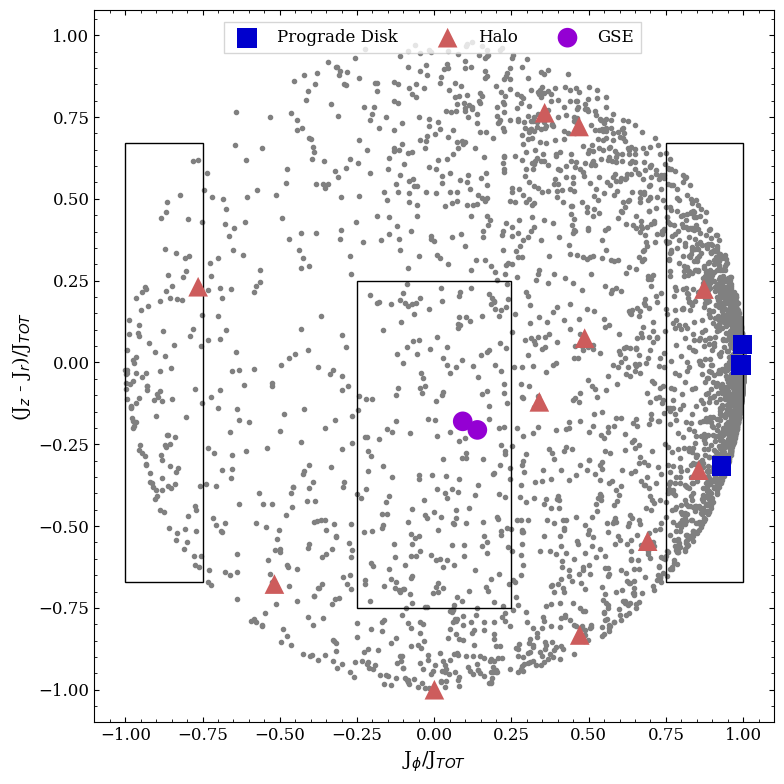

In [25]:
plt.figure(figsize=[8,8])

# Plotting the whole AAT sample
plt.scatter(aat_orb_params['Jp']/aat_orb_params['Jtot'], (aat_orb_params['Jz'] - aat_orb_params['Jr'])/aat_orb_params['Jtot'], color='grey', marker='.')

# Plotting the EMP stars
plt.scatter(emp_prodisk['Jp']/emp_prodisk['Jtot'], (emp_prodisk['Jz'] - emp_prodisk['Jr'])/emp_prodisk['Jtot'], 
            color='MediumBlue', marker='s', s=200, edgecolor='none', zorder=10, label='Prograde Disk')

plt.scatter(emp_halo['Jp']/emp_halo['Jtot'], (emp_halo['Jz'] - emp_halo['Jr'])/emp_halo['Jtot'], color='IndianRed', 
            marker='^', s=200, edgecolor='none', zorder=10, label='Halo')

plt.scatter(emp_ges['Jp']/emp_ges['Jtot'], (emp_ges['Jz'] - emp_ges['Jr'])/emp_ges['Jtot'], color='DarkViolet',
            marker='o', s=200, edgecolor='none', zorder=10, label='GSE')

# Making the rectangles for the different orbits
rect_ret = patches.Rectangle(xy=(-1,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
plt.gca().add_patch(rect_ret)
rect_pro = patches.Rectangle(xy=(0.75,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
plt.gca().add_patch(rect_pro)
rect_gse = patches.Rectangle(xy=(-0.25,-0.75), width=0.5, height=1.0, edgecolor='black', facecolor='None')
plt.gca().add_patch(rect_gse)


plt.legend(fancybox=False, loc=[0.19,0.94], ncols=3)
plt.xlabel('J$_\phi$/J$_{TOT}$')
plt.ylabel('(J$_z$ - J$_r$)/J$_{TOT}$')
plt.tight_layout()
plt.savefig("/data/misfit/benlowe/results/orbits/aat_emp_orbits.png", dpi=300, transparent=False, facecolor="white")

Seeing how abundances vary given orbital selections

/tmp/ipykernel_717395/1173673170.py:15: UserWarning: You passed a edgecolor/edgecolors ('none') for an unfilled marker ('+').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  axs[0,0].scatter(emp_halo['Jp']/emp_halo['Jtot'], (emp_halo['Jz'] - emp_halo['Jr'])/emp_halo['Jtot'], color='white',
/tmp/ipykernel_717395/1173673170.py:17: UserWarning: You passed a edgecolor/edgecolors ('none') for an unfilled marker ('4').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  axs[0,0].scatter(emp_ges['Jp']/emp_ges['Jtot'], (emp_ges['Jz'] - emp_ges['Jr'])/emp_ges['Jtot'], color='white',
/tmp/ipykernel_717395/1173673170.py:34: UserWarning: You passed a edgecolor/edgecolors ('none') for an unfilled marker ('+').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  axs[0,1].scatter(emp_halo['Jp']/emp_halo['Jtot'], (emp_halo['Jz'] - e

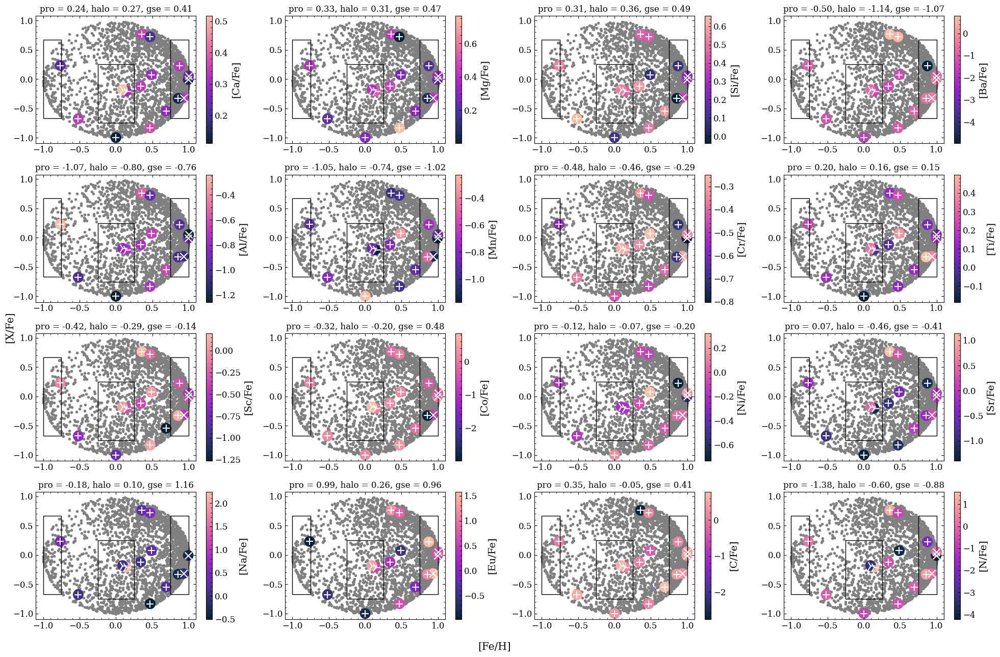

In [39]:
fig, axs = plt.subplots(4, 4, figsize=[20,13], tight_layout=True)
fig.subplots_adjust(wspace=0.25)
fig.supxlabel('[Fe/H]')
# cmap = mpl.cm.viridis
cmap = cmr.bubblegum

fig.supylabel('[X/Fe]')
# plt.tight_layout()

# Plotting Ca-II
axs[0,0].scatter(aat_orb_params['Jp']/aat_orb_params['Jtot'], (aat_orb_params['Jz'] - aat_orb_params['Jr'])/aat_orb_params['Jtot'], color='grey', marker='.')
sc = axs[0,0].scatter(emp_params['Jp']/emp_params['Jtot'], (emp_params['Jz'] - emp_params['Jr'])/emp_params['Jtot'], c=emp_params['Ca_II_xfe_it2'], marker='o', s=200, cmap=cmap)
axs[0,0].scatter(emp_prodisk['Jp']/emp_prodisk['Jtot'], (emp_prodisk['Jz'] - emp_prodisk['Jr'])/emp_prodisk['Jtot'], 
            color='white', marker='x', s=100, zorder=100)
axs[0,0].scatter(emp_halo['Jp']/emp_halo['Jtot'], (emp_halo['Jz'] - emp_halo['Jr'])/emp_halo['Jtot'], color='white', 
            marker='+', s=100, edgecolor='none', zorder=10, label='Halo')
axs[0,0].scatter(emp_ges['Jp']/emp_ges['Jtot'], (emp_ges['Jz'] - emp_ges['Jr'])/emp_ges['Jtot'], color='white',
            marker='4', s=200, edgecolor='none', zorder=10, label='GSE')
rect_ret = patches.Rectangle(xy=(-1,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[0,0].add_patch(rect_ret)
rect_pro = patches.Rectangle(xy=(0.75,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[0,0].add_patch(rect_pro)
rect_gse = patches.Rectangle(xy=(-0.25,-0.75), width=0.5, height=1.0, edgecolor='black', facecolor='None')
axs[0,0].add_patch(rect_gse)
axs[0,0].set_title(f'pro = {emp_prodisk["Ca_II_xfe_it2"].mean():.2f}, halo = {emp_halo["Ca_II_xfe_it2"].mean():.2f}, gse = {emp_ges["Ca_II_xfe_it2"].mean():.2f}', fontsize=12)
plt.colorbar(sc, label='[Ca/Fe]')


# Plotting Mg-I
axs[0,1].scatter(aat_orb_params['Jp']/aat_orb_params['Jtot'], (aat_orb_params['Jz'] - aat_orb_params['Jr'])/aat_orb_params['Jtot'], color='grey', marker='.')
sc = axs[0,1].scatter(emp_params['Jp']/emp_params['Jtot'], (emp_params['Jz'] - emp_params['Jr'])/emp_params['Jtot'], c=emp_params['Mg_I_xfe_it2'], marker='o', s=200, cmap=cmap)
axs[0,1].scatter(emp_prodisk['Jp']/emp_prodisk['Jtot'], (emp_prodisk['Jz'] - emp_prodisk['Jr'])/emp_prodisk['Jtot'], 
            color='white', marker='x', s=100, zorder=100)
axs[0,1].scatter(emp_halo['Jp']/emp_halo['Jtot'], (emp_halo['Jz'] - emp_halo['Jr'])/emp_halo['Jtot'], color='white', 
            marker='+', s=100, edgecolor='none', zorder=10, label='Halo')
axs[0,1].scatter(emp_ges['Jp']/emp_ges['Jtot'], (emp_ges['Jz'] - emp_ges['Jr'])/emp_ges['Jtot'], color='white',
            marker='4', s=200, edgecolor='none', zorder=10, label='GSE')
rect_ret = patches.Rectangle(xy=(-1,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[0,1].add_patch(rect_ret)
rect_pro = patches.Rectangle(xy=(0.75,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[0,1].add_patch(rect_pro)
rect_gse = patches.Rectangle(xy=(-0.25,-0.75), width=0.5, height=1.0, edgecolor='black', facecolor='None')
axs[0,1].add_patch(rect_gse)
plt.colorbar(sc, label='[Mg/Fe]')
axs[0,1].set_title(f'pro = {emp_prodisk["Mg_I_xfe_it2"].mean():.2f}, halo = {emp_halo["Mg_I_xfe_it2"].mean():.2f}, gse = {emp_ges["Mg_I_xfe_it2"].mean():.2f}', fontsize=12)


# Plotting Si-I
axs[0,2].scatter(aat_orb_params['Jp']/aat_orb_params['Jtot'], (aat_orb_params['Jz'] - aat_orb_params['Jr'])/aat_orb_params['Jtot'], color='grey', marker='.')
sc = axs[0,2].scatter(emp_params['Jp']/emp_params['Jtot'], (emp_params['Jz'] - emp_params['Jr'])/emp_params['Jtot'], c=emp_params['Si_I_xfe_it2'], marker='o', s=200, cmap=cmap)
axs[0,2].scatter(emp_prodisk['Jp']/emp_prodisk['Jtot'], (emp_prodisk['Jz'] - emp_prodisk['Jr'])/emp_prodisk['Jtot'], 
            color='white', marker='x', s=100, zorder=100)
axs[0,2].scatter(emp_halo['Jp']/emp_halo['Jtot'], (emp_halo['Jz'] - emp_halo['Jr'])/emp_halo['Jtot'], color='white', 
            marker='+', s=100, edgecolor='none', zorder=10, label='Halo')
axs[0,2].scatter(emp_ges['Jp']/emp_ges['Jtot'], (emp_ges['Jz'] - emp_ges['Jr'])/emp_ges['Jtot'], color='white',
            marker='4', s=200, edgecolor='none', zorder=10, label='GSE')
rect_ret = patches.Rectangle(xy=(-1,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[0,2].add_patch(rect_ret)
rect_pro = patches.Rectangle(xy=(0.75,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[0,2].add_patch(rect_pro)
rect_gse = patches.Rectangle(xy=(-0.25,-0.75), width=0.5, height=1.0, edgecolor='black', facecolor='None')
axs[0,2].add_patch(rect_gse)
plt.colorbar(sc, label='[Si/Fe]')
axs[0,2].set_title(f'pro = {emp_prodisk["Si_I_xfe_it2"].mean():.2f}, halo = {emp_halo["Si_I_xfe_it2"].mean():.2f}, gse = {emp_ges["Si_I_xfe_it2"].mean():.2f}', fontsize=12)


# Plotting Ba-II
axs[0,3].scatter(aat_orb_params['Jp']/aat_orb_params['Jtot'], (aat_orb_params['Jz'] - aat_orb_params['Jr'])/aat_orb_params['Jtot'], color='grey', marker='.')
sc = axs[0,3].scatter(emp_params['Jp']/emp_params['Jtot'], (emp_params['Jz'] - emp_params['Jr'])/emp_params['Jtot'], c=emp_params['Ba_II_xfe_it2'], marker='o', s=200, cmap=cmap)
axs[0,3].scatter(emp_prodisk['Jp']/emp_prodisk['Jtot'], (emp_prodisk['Jz'] - emp_prodisk['Jr'])/emp_prodisk['Jtot'], 
            color='white', marker='x', s=100, zorder=100)
axs[0,3].scatter(emp_halo['Jp']/emp_halo['Jtot'], (emp_halo['Jz'] - emp_halo['Jr'])/emp_halo['Jtot'], color='white', 
            marker='+', s=100, edgecolor='none', zorder=10, label='Halo')
axs[0,3].scatter(emp_ges['Jp']/emp_ges['Jtot'], (emp_ges['Jz'] - emp_ges['Jr'])/emp_ges['Jtot'], color='white',
            marker='4', s=200, edgecolor='none', zorder=10, label='GSE')
rect_ret = patches.Rectangle(xy=(-1,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[0,3].add_patch(rect_ret)
rect_pro = patches.Rectangle(xy=(0.75,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[0,3].add_patch(rect_pro)
rect_gse = patches.Rectangle(xy=(-0.25,-0.75), width=0.5, height=1.0, edgecolor='black', facecolor='None')
axs[0,3].add_patch(rect_gse)
plt.colorbar(sc, label='[Ba/Fe]')
axs[0,3].set_title(f'pro = {emp_prodisk["Ba_II_xfe_it2"].mean():.2f}, halo = {emp_halo["Ba_II_xfe_it2"].mean():.2f}, gse = {emp_ges["Ba_II_xfe_it2"].mean():.2f}', fontsize=12)


# Plotting Al-I
axs[1,0].scatter(aat_orb_params['Jp']/aat_orb_params['Jtot'], (aat_orb_params['Jz'] - aat_orb_params['Jr'])/aat_orb_params['Jtot'], color='grey', marker='.')
sc = axs[1,0].scatter(emp_params['Jp']/emp_params['Jtot'], (emp_params['Jz'] - emp_params['Jr'])/emp_params['Jtot'], c=emp_params['Al_I_xfe_it2'], marker='o', s=200, cmap=cmap)
axs[1,0].scatter(emp_prodisk['Jp']/emp_prodisk['Jtot'], (emp_prodisk['Jz'] - emp_prodisk['Jr'])/emp_prodisk['Jtot'], 
            color='white', marker='x', s=100, zorder=100)
axs[1,0].scatter(emp_halo['Jp']/emp_halo['Jtot'], (emp_halo['Jz'] - emp_halo['Jr'])/emp_halo['Jtot'], color='white', 
            marker='+', s=100, edgecolor='none', zorder=10, label='Halo')
axs[1,0].scatter(emp_ges['Jp']/emp_ges['Jtot'], (emp_ges['Jz'] - emp_ges['Jr'])/emp_ges['Jtot'], color='white',
            marker='4', s=200, edgecolor='none', zorder=10, label='GSE')
rect_ret = patches.Rectangle(xy=(-1,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[1,0].add_patch(rect_ret)
rect_pro = patches.Rectangle(xy=(0.75,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[1,0].add_patch(rect_pro)
rect_gse = patches.Rectangle(xy=(-0.25,-0.75), width=0.5, height=1.0, edgecolor='black', facecolor='None')
axs[1,0].add_patch(rect_gse)
plt.colorbar(sc, label='[Al/Fe]')
axs[1,0].set_title(f'pro = {emp_prodisk["Al_I_xfe_it2"].mean():.2f}, halo = {emp_halo["Al_I_xfe_it2"].mean():.2f}, gse = {emp_ges["Al_I_xfe_it2"].mean():.2f}', fontsize=12)


# Plotting Mn-I
axs[1,1].scatter(aat_orb_params['Jp']/aat_orb_params['Jtot'], (aat_orb_params['Jz'] - aat_orb_params['Jr'])/aat_orb_params['Jtot'], color='grey', marker='.')
sc = axs[1,1].scatter(emp_params['Jp']/emp_params['Jtot'], (emp_params['Jz'] - emp_params['Jr'])/emp_params['Jtot'], c=emp_params['Mn_I_xfe_it2'], marker='o', s=200, cmap=cmap)
axs[1,1].scatter(emp_prodisk['Jp']/emp_prodisk['Jtot'], (emp_prodisk['Jz'] - emp_prodisk['Jr'])/emp_prodisk['Jtot'], 
            color='white', marker='x', s=100, zorder=100)
axs[1,1].scatter(emp_halo['Jp']/emp_halo['Jtot'], (emp_halo['Jz'] - emp_halo['Jr'])/emp_halo['Jtot'], color='white', 
            marker='+', s=100, edgecolor='none', zorder=10, label='Halo')
axs[1,1].scatter(emp_ges['Jp']/emp_ges['Jtot'], (emp_ges['Jz'] - emp_ges['Jr'])/emp_ges['Jtot'], color='white',
            marker='4', s=200, edgecolor='none', zorder=10, label='GSE')
rect_ret = patches.Rectangle(xy=(-1,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[1,1].add_patch(rect_ret)
rect_pro = patches.Rectangle(xy=(0.75,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[1,1].add_patch(rect_pro)
rect_gse = patches.Rectangle(xy=(-0.25,-0.75), width=0.5, height=1.0, edgecolor='black', facecolor='None')
axs[1,1].add_patch(rect_gse)
plt.colorbar(sc, label='[Mn/Fe]')
axs[1,1].set_title(f'pro = {emp_prodisk["Mn_I_xfe_it2"].mean():.2f}, halo = {emp_halo["Mn_I_xfe_it2"].mean():.2f}, gse = {emp_ges["Mn_I_xfe_it2"].mean():.2f}', fontsize=12)


# Plotting Cr-I
axs[1,2].scatter(aat_orb_params['Jp']/aat_orb_params['Jtot'], (aat_orb_params['Jz'] - aat_orb_params['Jr'])/aat_orb_params['Jtot'], color='grey', marker='.')
sc = axs[1,2].scatter(emp_params['Jp']/emp_params['Jtot'], (emp_params['Jz'] - emp_params['Jr'])/emp_params['Jtot'], c=emp_params['Cr_I_xfe_it2'], marker='o', s=200, cmap=cmap)
axs[1,2].scatter(emp_prodisk['Jp']/emp_prodisk['Jtot'], (emp_prodisk['Jz'] - emp_prodisk['Jr'])/emp_prodisk['Jtot'], 
            color='white', marker='x', s=100, zorder=100)
axs[1,2].scatter(emp_halo['Jp']/emp_halo['Jtot'], (emp_halo['Jz'] - emp_halo['Jr'])/emp_halo['Jtot'], color='white', 
            marker='+', s=100, edgecolor='none', zorder=10, label='Halo')
axs[1,2].scatter(emp_ges['Jp']/emp_ges['Jtot'], (emp_ges['Jz'] - emp_ges['Jr'])/emp_ges['Jtot'], color='white',
            marker='4', s=200, edgecolor='none', zorder=10, label='GSE')
rect_ret = patches.Rectangle(xy=(-1,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[1,2].add_patch(rect_ret)
rect_pro = patches.Rectangle(xy=(0.75,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[1,2].add_patch(rect_pro)
rect_gse = patches.Rectangle(xy=(-0.25,-0.75), width=0.5, height=1.0, edgecolor='black', facecolor='None')
axs[1,2].add_patch(rect_gse)
plt.colorbar(sc, label='[Cr/Fe]')
axs[1,2].set_title(f'pro = {emp_prodisk["Cr_I_xfe_it2"].mean():.2f}, halo = {emp_halo["Cr_I_xfe_it2"].mean():.2f}, gse = {emp_ges["Cr_I_xfe_it2"].mean():.2f}', fontsize=12)


# Plotting Ti-II
axs[1,3].scatter(aat_orb_params['Jp']/aat_orb_params['Jtot'], (aat_orb_params['Jz'] - aat_orb_params['Jr'])/aat_orb_params['Jtot'], color='grey', marker='.')
sc = axs[1,3].scatter(emp_params['Jp']/emp_params['Jtot'], (emp_params['Jz'] - emp_params['Jr'])/emp_params['Jtot'], c=emp_params['Ti_II_xfe_it2'], marker='o', s=200, cmap=cmap)
axs[1,3].scatter(emp_prodisk['Jp']/emp_prodisk['Jtot'], (emp_prodisk['Jz'] - emp_prodisk['Jr'])/emp_prodisk['Jtot'], 
            color='white', marker='x', s=100, zorder=100)
axs[1,3].scatter(emp_halo['Jp']/emp_halo['Jtot'], (emp_halo['Jz'] - emp_halo['Jr'])/emp_halo['Jtot'], color='white', 
            marker='+', s=100, edgecolor='none', zorder=10, label='Halo')
axs[1,3].scatter(emp_ges['Jp']/emp_ges['Jtot'], (emp_ges['Jz'] - emp_ges['Jr'])/emp_ges['Jtot'], color='white',
            marker='4', s=200, edgecolor='none', zorder=10, label='GSE')
rect_ret = patches.Rectangle(xy=(-1,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[1,3].add_patch(rect_ret)
rect_pro = patches.Rectangle(xy=(0.75,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[1,3].add_patch(rect_pro)
rect_gse = patches.Rectangle(xy=(-0.25,-0.75), width=0.5, height=1.0, edgecolor='black', facecolor='None')
axs[1,3].add_patch(rect_gse)
plt.colorbar(sc, label='[Ti/Fe]')
axs[1,3].set_title(f'pro = {emp_prodisk["Ti_II_xfe_it2"].mean():.2f}, halo = {emp_halo["Ti_II_xfe_it2"].mean():.2f}, gse = {emp_ges["Ti_II_xfe_it2"].mean():.2f}', fontsize=12)


# Plotting Sc-II
axs[2,0].scatter(aat_orb_params['Jp']/aat_orb_params['Jtot'], (aat_orb_params['Jz'] - aat_orb_params['Jr'])/aat_orb_params['Jtot'], color='grey', marker='.')
sc = axs[2,0].scatter(emp_params['Jp']/emp_params['Jtot'], (emp_params['Jz'] - emp_params['Jr'])/emp_params['Jtot'], c=emp_params['Sc_II_xfe_it2'], marker='o', s=200, cmap=cmap)
axs[2,0].scatter(emp_prodisk['Jp']/emp_prodisk['Jtot'], (emp_prodisk['Jz'] - emp_prodisk['Jr'])/emp_prodisk['Jtot'], 
            color='white', marker='x', s=100, zorder=100)
axs[2,0].scatter(emp_halo['Jp']/emp_halo['Jtot'], (emp_halo['Jz'] - emp_halo['Jr'])/emp_halo['Jtot'], color='white', 
            marker='+', s=100, edgecolor='none', zorder=10, label='Halo')
axs[2,0].scatter(emp_ges['Jp']/emp_ges['Jtot'], (emp_ges['Jz'] - emp_ges['Jr'])/emp_ges['Jtot'], color='white',
            marker='4', s=200, edgecolor='none', zorder=10, label='GSE')
rect_ret = patches.Rectangle(xy=(-1,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[2,0].add_patch(rect_ret)
rect_pro = patches.Rectangle(xy=(0.75,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[2,0].add_patch(rect_pro)
rect_gse = patches.Rectangle(xy=(-0.25,-0.75), width=0.5, height=1.0, edgecolor='black', facecolor='None')
axs[2,0].add_patch(rect_gse)
plt.colorbar(sc, label='[Sc/Fe]')
axs[2,0].set_title(f'pro = {emp_prodisk["Sc_II_xfe_it2"].mean():.2f}, halo = {emp_halo["Sc_II_xfe_it2"].mean():.2f}, gse = {emp_ges["Sc_II_xfe_it2"].mean():.2f}', fontsize=12)


# Plotting Co-I
axs[2,1].scatter(aat_orb_params['Jp']/aat_orb_params['Jtot'], (aat_orb_params['Jz'] - aat_orb_params['Jr'])/aat_orb_params['Jtot'], color='grey', marker='.')
sc = axs[2,1].scatter(emp_params['Jp']/emp_params['Jtot'], (emp_params['Jz'] - emp_params['Jr'])/emp_params['Jtot'], c=emp_params['Co_I_xfe_it2'], marker='o', s=200, cmap=cmap)
axs[2,1].scatter(emp_prodisk['Jp']/emp_prodisk['Jtot'], (emp_prodisk['Jz'] - emp_prodisk['Jr'])/emp_prodisk['Jtot'], 
            color='white', marker='x', s=100, zorder=100)
axs[2,1].scatter(emp_halo['Jp']/emp_halo['Jtot'], (emp_halo['Jz'] - emp_halo['Jr'])/emp_halo['Jtot'], color='white', 
            marker='+', s=100, edgecolor='none', zorder=10, label='Halo')
axs[2,1].scatter(emp_ges['Jp']/emp_ges['Jtot'], (emp_ges['Jz'] - emp_ges['Jr'])/emp_ges['Jtot'], color='white',
            marker='4', s=200, edgecolor='none', zorder=10, label='GSE')
rect_ret = patches.Rectangle(xy=(-1,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[2,1].add_patch(rect_ret)
rect_pro = patches.Rectangle(xy=(0.75,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[2,1].add_patch(rect_pro)
rect_gse = patches.Rectangle(xy=(-0.25,-0.75), width=0.5, height=1.0, edgecolor='black', facecolor='None')
axs[2,1].add_patch(rect_gse)
plt.colorbar(sc, label='[Co/Fe]')
axs[2,1].set_title(f'pro = {emp_prodisk["Co_I_xfe_it2"].mean():.2f}, halo = {emp_halo["Co_I_xfe_it2"].mean():.2f}, gse = {emp_ges["Co_I_xfe_it2"].mean():.2f}', fontsize=12)


# Plotting Ni-I
axs[2,2].scatter(aat_orb_params['Jp']/aat_orb_params['Jtot'], (aat_orb_params['Jz'] - aat_orb_params['Jr'])/aat_orb_params['Jtot'], color='grey', marker='.')
sc = axs[2,2].scatter(emp_params['Jp']/emp_params['Jtot'], (emp_params['Jz'] - emp_params['Jr'])/emp_params['Jtot'], c=emp_params['Ni_I_xfe_it2'], marker='o', s=200, cmap=cmap)
axs[2,2].scatter(emp_prodisk['Jp']/emp_prodisk['Jtot'], (emp_prodisk['Jz'] - emp_prodisk['Jr'])/emp_prodisk['Jtot'], 
            color='white', marker='x', s=100, zorder=100)
axs[2,2].scatter(emp_halo['Jp']/emp_halo['Jtot'], (emp_halo['Jz'] - emp_halo['Jr'])/emp_halo['Jtot'], color='white', 
            marker='+', s=100, edgecolor='none', zorder=10, label='Halo')
axs[2,2].scatter(emp_ges['Jp']/emp_ges['Jtot'], (emp_ges['Jz'] - emp_ges['Jr'])/emp_ges['Jtot'], color='white',
            marker='4', s=200, edgecolor='none', zorder=10, label='GSE')
rect_ret = patches.Rectangle(xy=(-1,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[2,2].add_patch(rect_ret)
rect_pro = patches.Rectangle(xy=(0.75,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[2,2].add_patch(rect_pro)
rect_gse = patches.Rectangle(xy=(-0.25,-0.75), width=0.5, height=1.0, edgecolor='black', facecolor='None')
axs[2,2].add_patch(rect_gse)
plt.colorbar(sc, label='[Ni/Fe]')
axs[2,2].set_title(f'pro = {emp_prodisk["Ni_I_xfe_it2"].mean():.2f}, halo = {emp_halo["Ni_I_xfe_it2"].mean():.2f}, gse = {emp_ges["Ni_I_xfe_it2"].mean():.2f}', fontsize=12)


# Plotting Sr-II
axs[2,3].scatter(aat_orb_params['Jp']/aat_orb_params['Jtot'], (aat_orb_params['Jz'] - aat_orb_params['Jr'])/aat_orb_params['Jtot'], color='grey', marker='.')
sc = axs[2,3].scatter(emp_params['Jp']/emp_params['Jtot'], (emp_params['Jz'] - emp_params['Jr'])/emp_params['Jtot'], c=emp_params['Sr_II_xfe_it2'], marker='o', s=200, cmap=cmap)
axs[2,3].scatter(emp_prodisk['Jp']/emp_prodisk['Jtot'], (emp_prodisk['Jz'] - emp_prodisk['Jr'])/emp_prodisk['Jtot'], 
            color='white', marker='x', s=100, zorder=100)
axs[2,3].scatter(emp_halo['Jp']/emp_halo['Jtot'], (emp_halo['Jz'] - emp_halo['Jr'])/emp_halo['Jtot'], color='white', 
            marker='+', s=100, edgecolor='none', zorder=10, label='Halo')
axs[2,3].scatter(emp_ges['Jp']/emp_ges['Jtot'], (emp_ges['Jz'] - emp_ges['Jr'])/emp_ges['Jtot'], color='white',
            marker='4', s=200, edgecolor='none', zorder=10, label='GSE')
rect_ret = patches.Rectangle(xy=(-1,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[2,3].add_patch(rect_ret)
rect_pro = patches.Rectangle(xy=(0.75,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[2,3].add_patch(rect_pro)
rect_gse = patches.Rectangle(xy=(-0.25,-0.75), width=0.5, height=1.0, edgecolor='black', facecolor='None')
axs[2,3].add_patch(rect_gse)
plt.colorbar(sc, label='[Sr/Fe]')
axs[2,3].set_title(f'pro = {emp_prodisk["Sr_II_xfe_it2"].mean():.2f}, halo = {emp_halo["Sr_II_xfe_it2"].mean():.2f}, gse = {emp_ges["Sr_II_xfe_it2"].mean():.2f}', fontsize=12)


# Plotting Na-I
yes_na = emp_params[~emp_params['star_id'].isin(['ra_1604-2712_s292', 'ra_1648-0653_s38', 'ra_1752-4300_s269'])]
yes_na_prodisk = emp_prodisk[~emp_prodisk['star_id'].isin(['ra_1604-2712_s292', 'ra_1648-0653_s38', 'ra_1752-4300_s269'])]
yes_na_halo = emp_halo[~emp_halo['star_id'].isin(['ra_1604-2712_s292', 'ra_1648-0653_s38', 'ra_1752-4300_s269'])]
yes_na_ges = emp_ges[~emp_ges['star_id'].isin(['ra_1604-2712_s292', 'ra_1648-0653_s38', 'ra_1752-4300_s269'])]

no_na = emp_params[emp_params['star_id'].isin(['ra_1604-2712_s292', 'ra_1648-0653_s38', 'ra_1752-4300_s269'])]


axs[3,0].scatter(aat_orb_params['Jp']/aat_orb_params['Jtot'], (aat_orb_params['Jz'] - aat_orb_params['Jr'])/aat_orb_params['Jtot'], color='grey', marker='.')
sc = axs[3,0].scatter(yes_na['Jp']/yes_na['Jtot'], (yes_na['Jz'] - yes_na['Jr'])/yes_na['Jtot'], c=yes_na['Na_I_xfe_it2'], marker='o', s=200, cmap=cmap)
# axs[3,0].scatter(no_na['Jp']/no_na['Jtot'], (no_na['Jz'] - no_na['Jr'])/no_na['Jtot'], c='yellow', marker='o', s=200, cmap=cmap)
axs[3,0].scatter(yes_na_prodisk['Jp']/yes_na_prodisk['Jtot'], (yes_na_prodisk['Jz'] - yes_na_prodisk['Jr'])/yes_na_prodisk['Jtot'], 
            color='white', marker='x', s=100, zorder=100)
axs[3,0].scatter(yes_na_halo['Jp']/yes_na_halo['Jtot'], (yes_na_halo['Jz'] - yes_na_halo['Jr'])/yes_na_halo['Jtot'], color='white', 
            marker='+', s=100, edgecolor='none', zorder=10, label='Halo')
axs[3,0].scatter(yes_na_ges['Jp']/yes_na_ges['Jtot'], (yes_na_ges['Jz'] - yes_na_ges['Jr'])/yes_na_ges['Jtot'], color='white',
            marker='4', s=200, edgecolor='none', zorder=10, label='GSE')
rect_ret = patches.Rectangle(xy=(-1,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[3,0].add_patch(rect_ret)
rect_pro = patches.Rectangle(xy=(0.75,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[3,0].add_patch(rect_pro)
rect_gse = patches.Rectangle(xy=(-0.25,-0.75), width=0.5, height=1.0, edgecolor='black', facecolor='None')
axs[3,0].add_patch(rect_gse)
plt.colorbar(sc, label='[Na/Fe]')
axs[3,0].set_title(f'pro = {yes_na_prodisk["Na_I_xfe_it2"].mean():.2f}, halo = {yes_na_halo["Na_I_xfe_it2"].mean():.2f}, gse = {yes_na_ges["Na_I_xfe_it2"].mean():.2f}', fontsize=12)


# Plotting Eu-II
axs[3,1].scatter(aat_orb_params['Jp']/aat_orb_params['Jtot'], (aat_orb_params['Jz'] - aat_orb_params['Jr'])/aat_orb_params['Jtot'], color='grey', marker='.')
sc = axs[3,1].scatter(emp_params['Jp']/emp_params['Jtot'], (emp_params['Jz'] - emp_params['Jr'])/emp_params['Jtot'], c=emp_params['Eu_II_xfe_it2'], marker='o', s=200, cmap=cmap)
axs[3,1].scatter(emp_prodisk['Jp']/emp_prodisk['Jtot'], (emp_prodisk['Jz'] - emp_prodisk['Jr'])/emp_prodisk['Jtot'], 
            color='white', marker='x', s=100, zorder=100)
axs[3,1].scatter(emp_halo['Jp']/emp_halo['Jtot'], (emp_halo['Jz'] - emp_halo['Jr'])/emp_halo['Jtot'], color='white', 
            marker='+', s=100, edgecolor='none', zorder=10, label='Halo')
axs[3,1].scatter(emp_ges['Jp']/emp_ges['Jtot'], (emp_ges['Jz'] - emp_ges['Jr'])/emp_ges['Jtot'], color='white',
            marker='4', s=200, edgecolor='none', zorder=10, label='GSE')
rect_ret = patches.Rectangle(xy=(-1,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[3,1].add_patch(rect_ret)
rect_pro = patches.Rectangle(xy=(0.75,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[3,1].add_patch(rect_pro)
rect_gse = patches.Rectangle(xy=(-0.25,-0.75), width=0.5, height=1.0, edgecolor='black', facecolor='None')
axs[3,1].add_patch(rect_gse)
plt.colorbar(sc, label='[Eu/Fe]')
axs[3,1].set_title(f'pro = {emp_prodisk["Eu_II_xfe_it2"].mean():.2f}, halo = {emp_halo["Eu_II_xfe_it2"].mean():.2f}, gse = {emp_ges["Eu_II_xfe_it2"].mean():.2f}', fontsize=12)


# Plotting C-I
axs[3,2].scatter(aat_orb_params['Jp']/aat_orb_params['Jtot'], (aat_orb_params['Jz'] - aat_orb_params['Jr'])/aat_orb_params['Jtot'], color='grey', marker='.')
sc = axs[3,2].scatter(emp_params['Jp']/emp_params['Jtot'], (emp_params['Jz'] - emp_params['Jr'])/emp_params['Jtot'], c=emp_params['C_I_xfe_it2'], marker='o', s=200, cmap=cmap)
axs[3,2].scatter(emp_prodisk['Jp']/emp_prodisk['Jtot'], (emp_prodisk['Jz'] - emp_prodisk['Jr'])/emp_prodisk['Jtot'], 
            color='white', marker='x', s=100, zorder=100)
axs[3,2].scatter(emp_halo['Jp']/emp_halo['Jtot'], (emp_halo['Jz'] - emp_halo['Jr'])/emp_halo['Jtot'], color='white', 
            marker='+', s=100, edgecolor='none', zorder=10, label='Halo')
axs[3,2].scatter(emp_ges['Jp']/emp_ges['Jtot'], (emp_ges['Jz'] - emp_ges['Jr'])/emp_ges['Jtot'], color='white',
            marker='4', s=200, edgecolor='none', zorder=10, label='GSE')
rect_ret = patches.Rectangle(xy=(-1,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[3,2].add_patch(rect_ret)
rect_pro = patches.Rectangle(xy=(0.75,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[3,2].add_patch(rect_pro)
rect_gse = patches.Rectangle(xy=(-0.25,-0.75), width=0.5, height=1.0, edgecolor='black', facecolor='None')
axs[3,2].add_patch(rect_gse)
plt.colorbar(sc, label='[C/Fe]')
axs[3,2].set_title(f'pro = {emp_prodisk["C_I_xfe_it2"].mean():.2f}, halo = {emp_halo["C_I_xfe_it2"].mean():.2f}, gse = {emp_ges["C_I_xfe_it2"].mean():.2f}', fontsize=12)


# Plotting N-I
axs[3,3].scatter(aat_orb_params['Jp']/aat_orb_params['Jtot'], (aat_orb_params['Jz'] - aat_orb_params['Jr'])/aat_orb_params['Jtot'], color='grey', marker='.')
sc = axs[3,3].scatter(emp_params['Jp']/emp_params['Jtot'], (emp_params['Jz'] - emp_params['Jr'])/emp_params['Jtot'], c=emp_params['N_I_xfe_it2'], marker='o', s=200, cmap=cmap)
axs[3,3].scatter(emp_prodisk['Jp']/emp_prodisk['Jtot'], (emp_prodisk['Jz'] - emp_prodisk['Jr'])/emp_prodisk['Jtot'], 
            color='white', marker='x', s=100, zorder=100)
axs[3,3].scatter(emp_halo['Jp']/emp_halo['Jtot'], (emp_halo['Jz'] - emp_halo['Jr'])/emp_halo['Jtot'], color='white', 
            marker='+', s=100, edgecolor='none', zorder=10, label='Halo')
axs[3,3].scatter(emp_ges['Jp']/emp_ges['Jtot'], (emp_ges['Jz'] - emp_ges['Jr'])/emp_ges['Jtot'], color='white',
            marker='4', s=200, edgecolor='none', zorder=10, label='GSE')
rect_ret = patches.Rectangle(xy=(-1,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[3,3].add_patch(rect_ret)
rect_pro = patches.Rectangle(xy=(0.75,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
axs[3,3].add_patch(rect_pro)
rect_gse = patches.Rectangle(xy=(-0.25,-0.75), width=0.5, height=1.0, edgecolor='black', facecolor='None')
axs[3,3].add_patch(rect_gse)
plt.colorbar(sc, label='[N/Fe]')
axs[3,3].set_title(f'pro = {emp_prodisk["N_I_xfe_it2"].mean():.2f}, halo = {emp_halo["N_I_xfe_it2"].mean():.2f}, gse = {emp_ges["N_I_xfe_it2"].mean():.2f}', fontsize=12)

# Saving
plt.savefig("/data/misfit/benlowe/results/star_abunds/orbit_abunds.png", dpi=300, transparent=False, facecolor="white")


Making a plot of the means with the standard deviation

In [ ]:
import seaborn as sns

emp_prodisk_ca = emp_prodisk[['star_id', 'Ca_II_xfe_it2']]
emp_prodisk_ca["element"] = "Ca"
emp_prodisk_ca["group"] = "Prograde disk"

emp_halo_ca = emp_halo[['star_id', 'Ca_II_xfe_it2']]
emp_halo_ca["element"] = "Ca"
emp_halo_ca["group"] = "Halo"

emp_ges_ca = emp_ges[['star_id', 'Ca_II_xfe_it2']]
emp_ges_ca["element"] = "Ca"
emp_ges_ca["group"] = "GSE"

emp_prodisk_ca

/tmp/ipykernel_3926330/293182039.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  emp_prodisk_ca["element"] = "Ca"
/tmp/ipykernel_3926330/293182039.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  emp_prodisk_ca["group"] = "Prograde disk"


,star_id,Ca_II_xfe_it2,element,group
0,ra_0103-7050_s163,0.144885,Ca,Prograde disk
1,ra_0834-5220_s316,0.335718,Ca,Prograde disk
7,ra_1648-0653_s38,0.238750,Ca,Prograde disk


## Making the [C/Fe] and [N/Fe] spectral fit plots

/tmp/ipykernel_1924304/3590197755.py:239: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(8, 6))


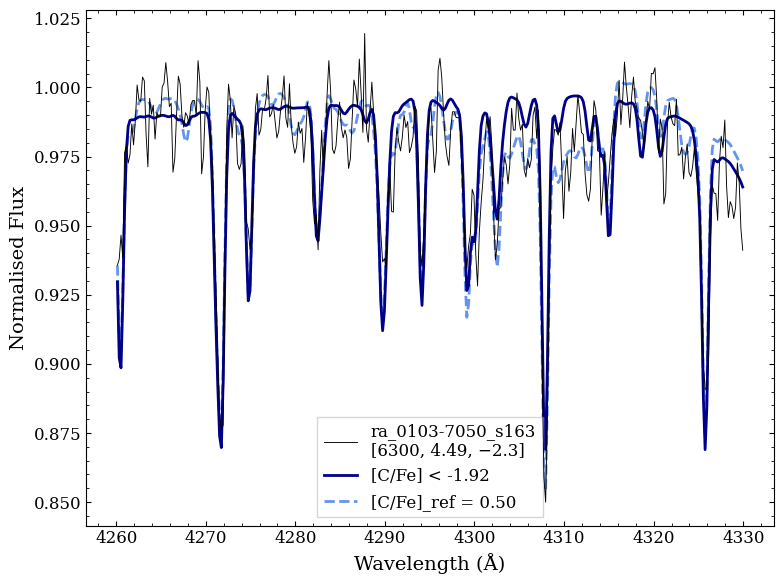

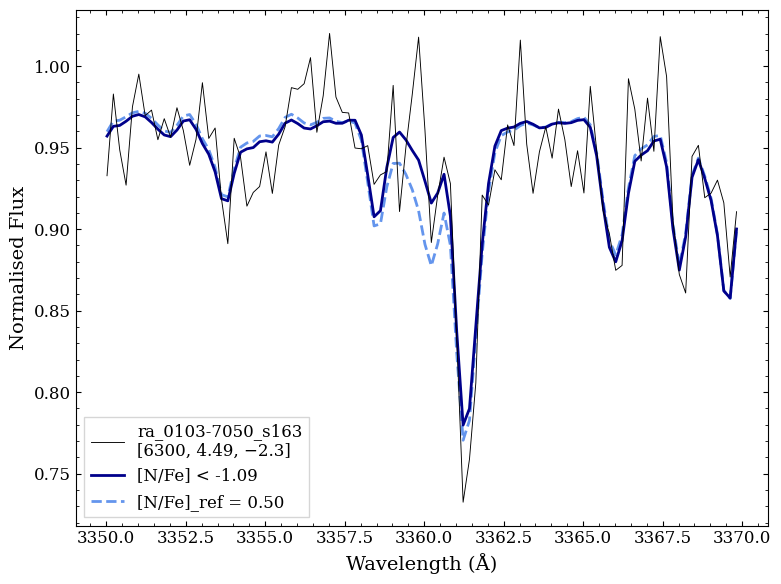

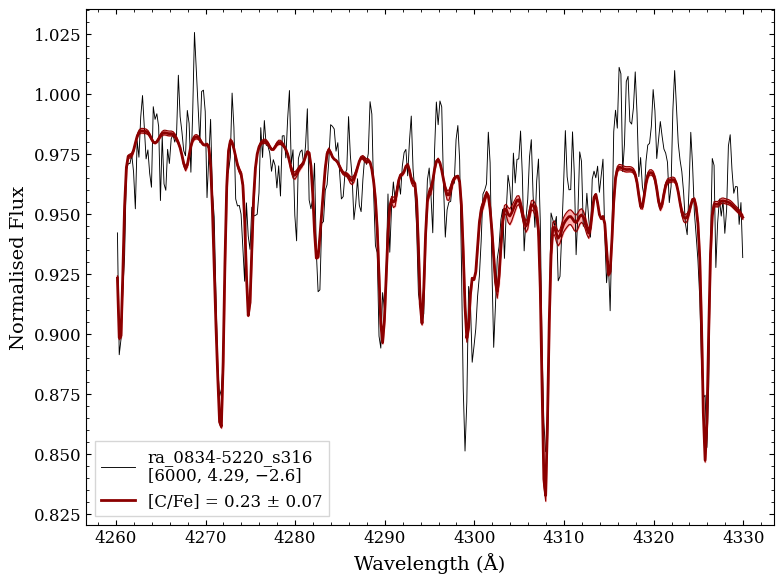

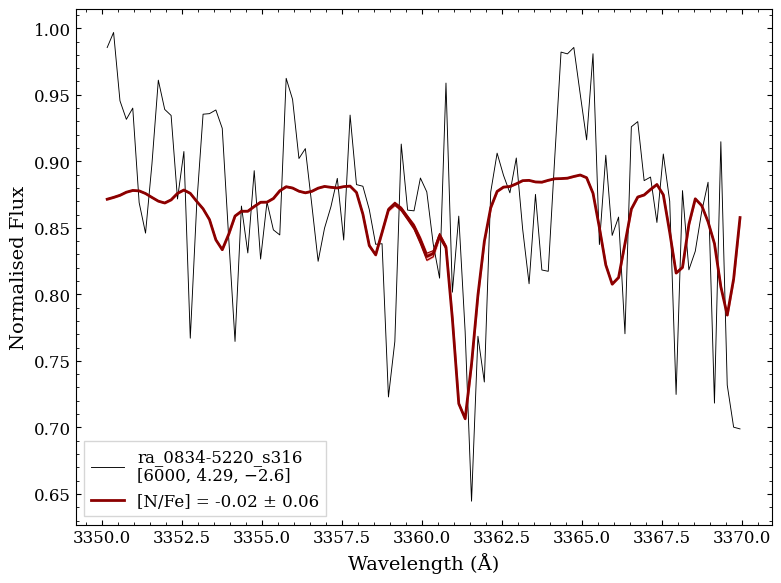

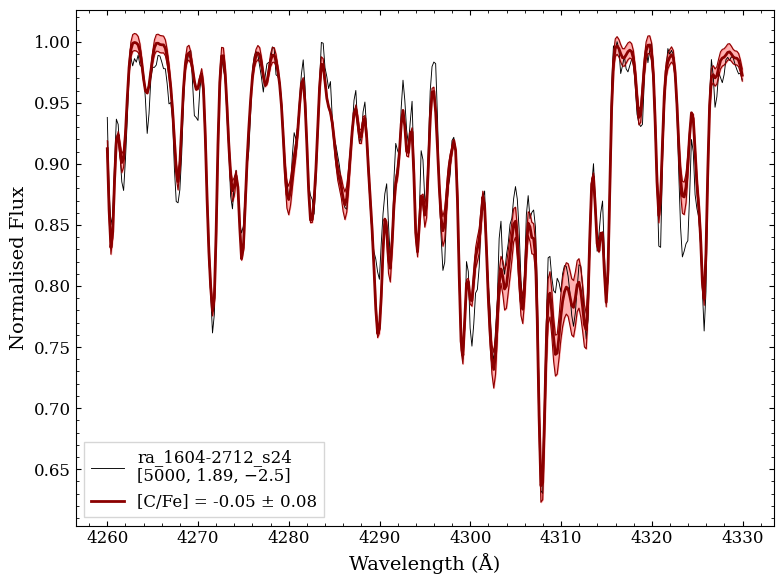

...

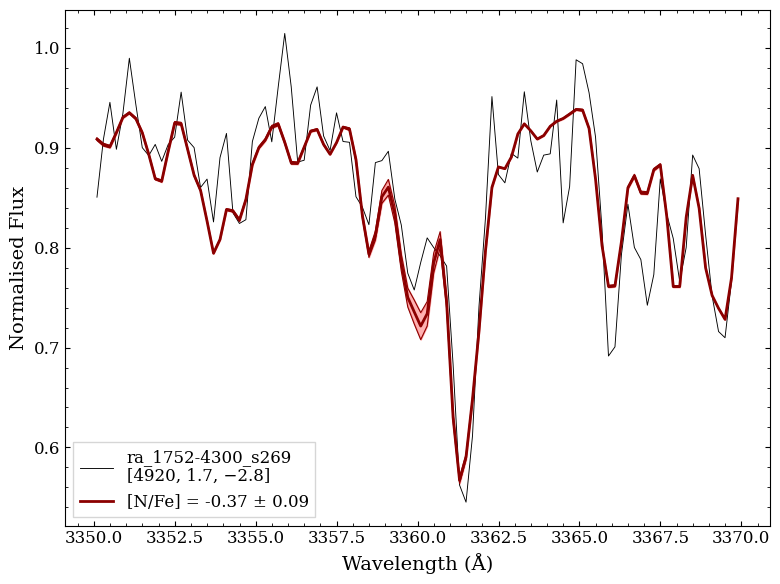

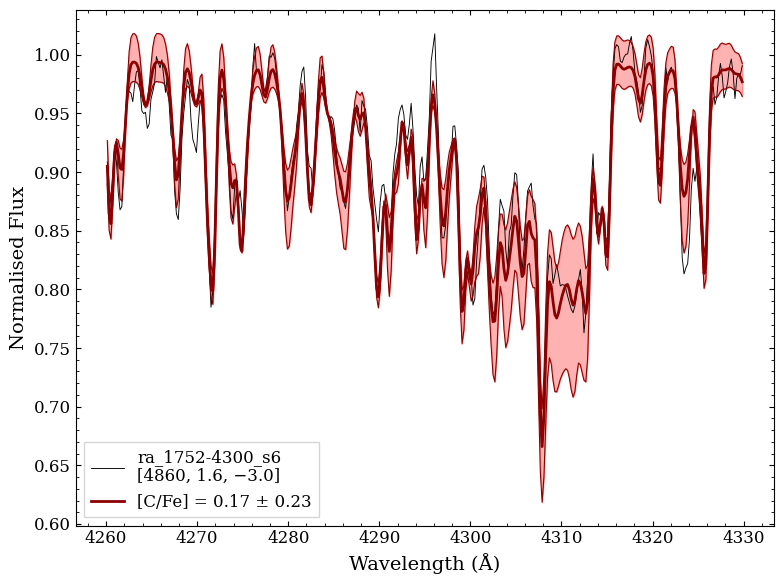

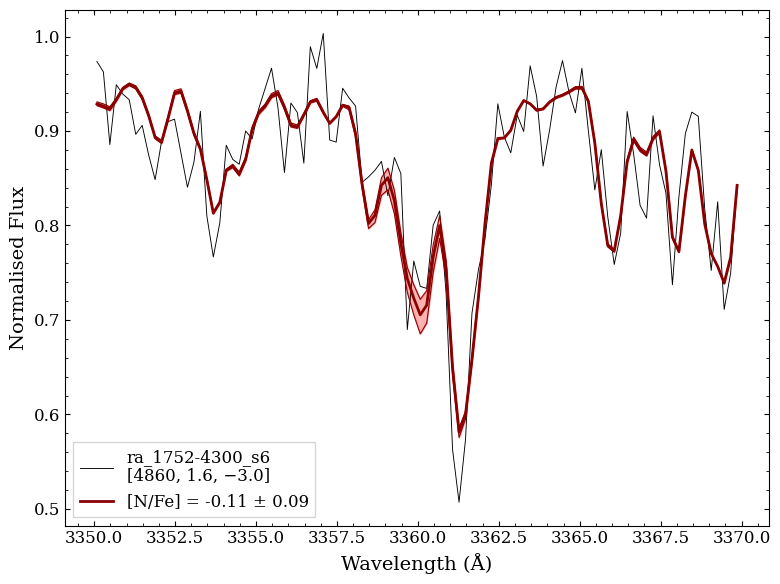

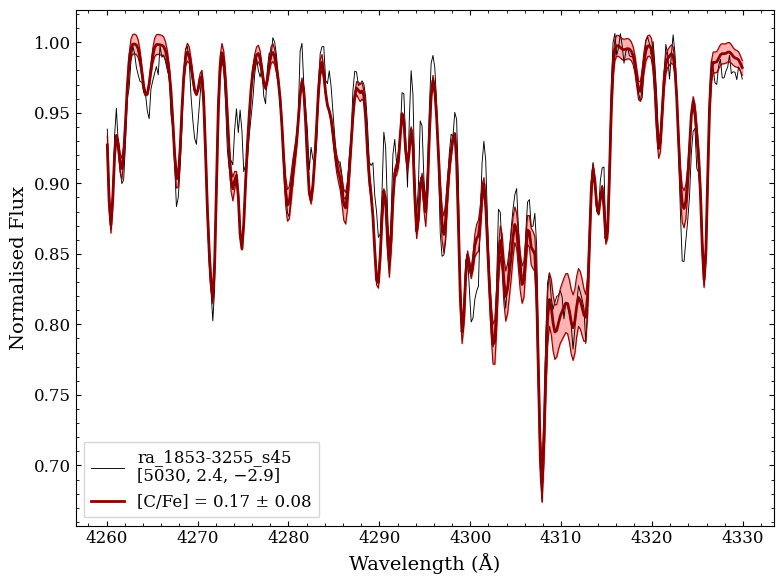

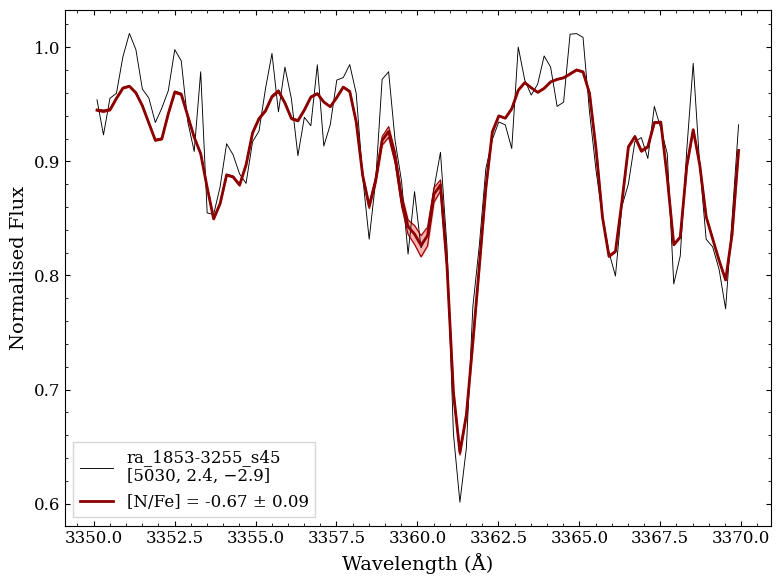

In [95]:
def CN_spec_fit(detect_flag, spec_dir, element, abund_val, abund_err, abund_ul, star_params, savepath, wavelim=None):
    
    
    star_id = star_params['star_id']
    
    # If detection, then plot the best abundance spectra, with ± error
    if detect_flag == 'Y':

        # Getting the file paths for the spectra
        # If the file does not exist (idk why), try the next abundance value (it's close enough!)
        try:   
            spec_abund = f'{spec_dir}{abund_val:.2f}_spec.csv'
            spec_abund_df = pd.read_csv(spec_abund)
        except FileNotFoundError:
            abund_val_2 = abund_val + 0.01
            spec_abund = f'{spec_dir}{abund_val_2:.2f}_spec.csv'
            spec_abund_df = pd.read_csv(spec_abund)
            
        try:
            spec_abund_perr = f'{spec_dir}{abund_val + abund_err:.2f}_spec.csv'
            spec_abund_perr_df = pd.read_csv(spec_abund_perr)
        except FileNotFoundError:
            abund_val_2 = (abund_val + abund_err) + 0.01
            spec_abund_perr = f'{spec_dir}{abund_val_2:.2f}_spec.csv'
            spec_abund_perr_df = pd.read_csv(spec_abund_perr)
            
        try:
            spec_abund_merr = f'{spec_dir}{abund_val - abund_err:.2f}_spec.csv'
            spec_abund_merr_df = pd.read_csv(spec_abund_merr)
        except FileNotFoundError:
            abund_val_2 = (abund_val - abund_err) + 0.01
            spec_abund_merr = f'{spec_dir}{abund_val_2:.2f}_spec.csv'
            spec_abund_merr_df = pd.read_csv(spec_abund_merr)
            
        try:
            spec_abund_empty = f'{spec_dir}{-3.00:.2f}_spec.csv'
            spec_abund_empty_df = pd.read_csv(spec_abund_empty)
        except FileNotFoundError:
            abund_val_2 = -3.00 + 0.01
            spec_abund_empty = f'{spec_dir}{abund_val_2:.2f}_spec.csv'
            spec_abund_empty_df = pd.read_csv(spec_abund_empty)
            
        # Plotting the spectra
        obs_wave = np.array(ast.literal_eval(spec_abund_df['obs_wave'].to_numpy()[0]))
        obs_flux = np.array(ast.literal_eval(spec_abund_df['obs_flux'].to_numpy()[0]))
        bestfit_wave = np.array(ast.literal_eval(spec_abund_df['fit_wave'].to_numpy()[0]))
        bestfit_flux = np.array(ast.literal_eval(spec_abund_df['fit_flux'].to_numpy()[0]))
        pfit_wave = np.array(ast.literal_eval(spec_abund_perr_df['fit_wave'].to_numpy()[0]))
        pfit_flux = np.array(ast.literal_eval(spec_abund_perr_df['fit_flux'].to_numpy()[0]))
        mfit_wave = np.array(ast.literal_eval(spec_abund_merr_df['fit_wave'].to_numpy()[0]))
        mfit_flux = np.array(ast.literal_eval(spec_abund_merr_df['fit_flux'].to_numpy()[0]))
        mfit_wave = np.array(ast.literal_eval(spec_abund_merr_df['fit_wave'].to_numpy()[0]))
        mfit_flux = np.array(ast.literal_eval(spec_abund_merr_df['fit_flux'].to_numpy()[0]))
        emptyfit_wave = np.array(ast.literal_eval(spec_abund_empty_df['fit_wave'].to_numpy()[0]))
        emptyfit_flux = np.array(ast.literal_eval(spec_abund_empty_df['fit_flux'].to_numpy()[0]))
                
        if wavelim is not None:
            obs_wavelim = np.where((obs_wave >= wavelim[0]) & (obs_wave <= wavelim[1]))
            obs_wave = obs_wave[obs_wavelim]
            obs_flux = obs_flux[obs_wavelim]
            bestfit_wavelim = np.where((bestfit_wave >= wavelim[0]) & (bestfit_wave <= wavelim[1]))
            bestfit_wave = bestfit_wave[bestfit_wavelim]
            bestfit_flux = bestfit_flux[bestfit_wavelim]
            pfit_wavelim = np.where((pfit_wave >= wavelim[0]) & (pfit_wave <= wavelim[1]))
            pfit_wave = pfit_wave[pfit_wavelim]
            pfit_flux = pfit_flux[pfit_wavelim]
            mfit_wavelim = np.where((mfit_wave >= wavelim[0]) & (mfit_wave <= wavelim[1]))
            mfit_wave = mfit_wave[mfit_wavelim]
            mfit_flux = mfit_flux[mfit_wavelim]
            emptyfit_wavelim = np.where((emptyfit_wave >= wavelim[0]) & (emptyfit_wave <= wavelim[1]))
            emptyfit_wave = emptyfit_wave[emptyfit_wavelim]
            emptyfit_flux = emptyfit_flux[emptyfit_wavelim]
        
        # print(obs_flux)
        # print(bestfit_flux)
        # print(pfit_flux)
        # print(mfit_flux)
                
        plt.plot(obs_wave, obs_flux, linewidth=0.65, color='black', 
                 label='{0}\n[{1}, {2}, {3}]'.format(star_params['star_id'], star_params['teff'], star_params['logg'], star_params['feh']))
        plt.plot(bestfit_wave, bestfit_flux, linewidth=2, color='darkred', label='[{0}/Fe] = {1:.2f} ± {2:.2f}'.format(element, abund_val, abund_err))
        plt.plot(pfit_wave, pfit_flux, linewidth=0.8, color='darkred')
        plt.plot(mfit_wave, mfit_flux, linewidth=0.8, color='darkred')
        # plt.plot(emptyfit_wave, emptyfit_flux, linewidth=1.5, color='black', linestyle='--', label='[{0}/Fe] = -3.00'.format(element))
        plt.fill_between(obs_wave, pfit_flux, mfit_flux, color='red', alpha=0.3)


        plt.xlabel('Wavelength (Å)')
        plt.ylabel('Normalised Flux')
        plt.legend(fancybox=False)
        plt.tight_layout()
        
        plt.savefig(savepath + star_params['star_id'] + '_plot.pdf', dpi=300, transparent=False, facecolor="white")
        plt.savefig(savepath + star_params['star_id'] + '_plot.png', dpi=300, transparent=False, facecolor="white")

    if detect_flag == 'N':

        # Getting the file paths for the spectra
        # If the file does not exist (idk why), try the next abundance value (it's close enough!)
        try:   
            spec_abund_ul = f'{spec_dir}{abund_ul:.2f}_spec.csv'
            spec_abund_ul_df = pd.read_csv(spec_abund_ul)
        except FileNotFoundError:
            abund_val_2 = abund_ul + 0.01
            spec_abund_ul = f'{spec_dir}{abund_val_2:.2f}_spec.csv'
            spec_abund_ul_df = pd.read_csv(spec_abund_ul)
            
        # For the upper limit spectra, also plot a reference spectra at 0.5 dex
        try:   
            spec_abund_ref = f'{spec_dir}{0.5:.2f}_spec.csv'
            spec_abund_ref_df = pd.read_csv(spec_abund_ref)
        except FileNotFoundError:
            abund_val_2 = 0.5 + 0.01
            spec_abund_ref = f'{spec_dir}{abund_val_2:.2f}_spec.csv'
            spec_abund_ref_df = pd.read_csv(spec_abund_ref)
            
        try:
            spec_abund_empty = f'{spec_dir}{-3.00:.2f}_spec.csv'
            spec_abund_empty_df = pd.read_csv(spec_abund_empty)
        except FileNotFoundError:
            abund_val_2 = -3.00 + 0.01
            spec_abund_empty = f'{spec_dir}{abund_val_2:.2f}_spec.csv'
            spec_abund_empty_df = pd.read_csv(spec_abund_empty)
                        
        # Plotting the spectra
        obs_wave = np.array(ast.literal_eval(spec_abund_ul_df['obs_wave'].to_numpy()[0]))
        obs_flux = np.array(ast.literal_eval(spec_abund_ul_df['obs_flux'].to_numpy()[0]))
        ul_wave = np.array(ast.literal_eval(spec_abund_ul_df['fit_wave'].to_numpy()[0]))
        ul_flux = np.array(ast.literal_eval(spec_abund_ul_df['fit_flux'].to_numpy()[0]))
        ref_wave = np.array(ast.literal_eval(spec_abund_ref_df['fit_wave'].to_numpy()[0]))
        ref_flux = np.array(ast.literal_eval(spec_abund_ref_df['fit_flux'].to_numpy()[0]))
        emptyfit_wave = np.array(ast.literal_eval(spec_abund_empty_df['fit_wave'].to_numpy()[0]))
        emptyfit_flux = np.array(ast.literal_eval(spec_abund_empty_df['fit_flux'].to_numpy()[0]))

        
        
        if wavelim is not None:
            obs_wavelim = np.where((obs_wave >= wavelim[0]) & (obs_wave <= wavelim[1]))
            obs_wave = obs_wave[obs_wavelim]
            obs_flux = obs_flux[obs_wavelim]
            ul_wavelim = np.where((ul_wave >= wavelim[0]) & (ul_wave <= wavelim[1]))
            ul_wave = ul_wave[ul_wavelim]
            ul_flux = ul_flux[ul_wavelim]
            ref_wavelim = np.where((ref_wave >= wavelim[0]) & (ref_wave <= wavelim[1]))
            ref_wave = ref_wave[ref_wavelim]
            ref_flux = ref_flux[ref_wavelim]
            emptyfit_wavelim = np.where((emptyfit_wave >= wavelim[0]) & (emptyfit_wave <= wavelim[1]))
            emptyfit_wave = emptyfit_wave[emptyfit_wavelim]
            emptyfit_flux = emptyfit_flux[emptyfit_wavelim]
        
        # print(obs_flux)
        # print(bestfit_flux)
        # print(pfit_flux)
        # print(mfit_flux)
                
        plt.plot(obs_wave, obs_flux, linewidth=0.65, color='black', 
                 label='{0}\n[{1}, {2}, {3}]'.format(star_params['star_id'], star_params['teff'], star_params['logg'], star_params['feh']), zorder=10)
        plt.plot(ul_wave, ul_flux, linewidth=2, color='darkblue', label='[{0}/Fe] < {1:.2f}'.format(element, abund_ul), zorder=5)
        plt.plot(ref_wave, ref_flux, linewidth=2, color='cornflowerblue', linestyle='--', zorder=0, label='[{0}/Fe]_ref = 0.50'.format(element))
        # plt.plot(emptyfit_wave, emptyfit_flux, linewidth=1.5, color='black', linestyle='--', label='[{0}/Fe] = -3.00'.format(element))



        plt.xlabel('Wavelength (Å)')
        plt.ylabel('Normalised Flux')
        plt.legend(fancybox=False)
        plt.tight_layout()

        plt.savefig(savepath + star_params['star_id'] + '_plot.pdf', dpi=300, transparent=False, facecolor="white")
        plt.savefig(savepath + star_params['star_id'] + '_plot.png', dpi=300, transparent=False, facecolor="white")

    

stars = stars_data['star_id'].to_numpy()
params_rounded = pd.read_csv('/data/misfit/benlowe/xshooter/stellar_params/star_params_rd.csv')

for star in stars:

    # Getting the entries for the star
    star_data = stars_upperlimits[stars_upperlimits['star_id'] == star]
    star_params = stars_data[stars_data['star_id'] == star]
    
    # Stellar parameters
    star_teff = params_rounded[params_rounded['star_id'] == star]['teff'].to_numpy()[0]
    star_logg = params_rounded[params_rounded['star_id'] == star]['logg'].to_numpy()[0]
    star_feh = params_rounded[params_rounded['star_id'] == star]['feh'].to_numpy()[0]
    star_snr = star_params['snr_uvb'].to_numpy()[0]
    params = {'star_id': star, 'teff': star_teff, 'logg': star_logg, 'feh': star_feh, 'snr': star_snr}

    # Getting C abundances. 
    # We want the uncorrected C abundances (the ones provided are corrected), so need to subtract the corrections off
    c_I_df = star_data[star_data['el'] == 'C_I']
    c_I_detect = c_I_df['detection'].to_numpy()[0]
    c_I_val = c_I_df['bestfit_abund_xfe'].to_numpy()[0]
    c_I_err = c_I_df['bestfit_abund_comberr_xfe'].to_numpy()[0]
    c_I_ul = c_I_df['upper_limit_xfe'].to_numpy()[0]
    
    c_I_correct_df = pd.read_csv('/data/misfit/benlowe/xshooter/C_evolve_corrections/cfe_corrections.csv')
    c_I_val_corr = c_I_correct_df[c_I_correct_df['star_id'] == star]['cfe_corr'].to_numpy()[0]
    
    if star == 'ra_1656-1433_s143':
        c_I_err = c_I_abunds[c_I_abunds['star_id'] == 'ra_1656-1433_s143']['bestfit_abund_tefferr_xfe'].to_numpy()[0]
        
    if star == 'ra_1752-4300_s6':
        c_I_err = c_I_abunds[c_I_abunds['star_id'] == 'ra_1752-4300_s6']['bestfit_abund_tefferr_xfe'].to_numpy()[0]
                
                
    c_I_val = c_I_val - c_I_val_corr
    
    # c_I_abunds.loc[c_I_abunds['star_id'] == 'ra_1656-1433_s143', 'bestfit_abund_comberr_xfe'] = c_I_abunds[c_I_abunds['star_id'] == 'ra_1656-1433_s143']['bestfit_abund_tefferr_xfe']
    # c_I_abunds.loc[c_I_abunds['star_id'] == 'ra_1752-4300_s6', 'bestfit_abund_comberr_xfe'] = c_I_abunds[c_I_abunds['star_id'] == 'ra_1752-4300_s6']['bestfit_abund_tefferr_xfe']

    
    
    # if star == 'ra_1656-1433_s143':
    #     c_I_val = 0.358195 - c_I_val_corr
    #     c_I_err = abs(c_I_val - (0.588063 - c_I_val_corr))
    # else:
    #     c_I_val = c_I_val - c_I_val_corr
    
    # Getting N abundances
    n_I_abunds = star_data[star_data['el'] == 'N_I']
    n_I_detect = n_I_abunds['detection'].to_numpy()[0]
    n_I_val = n_I_abunds['bestfit_abund_xfe'].to_numpy()[0]
    n_I_err = n_I_abunds['bestfit_abund_comberr_xfe'].to_numpy()[0]  
    n_I_ul = n_I_abunds['upper_limit_xfe'].to_numpy()[0]
    
    # if n_I_ul < -2.00:
    #     n_I_ul = -2.00
    
    # Directory to spectral data
    spec_c_dir = f'/data/misfit/benlowe/xshooter/korg_data/synths/{star}/C_I/obs/line_4300.313/spectra/'
    spec_n_dir = f'/data/misfit/benlowe/xshooter/korg_data/synths/{star}/N_I/obs/line_3360.22/spectra/'
    
    # Save path
    cfe_savepath = '/data/misfit/benlowe/xshooter/results/ch_nh_fits/cfe_plots/'
    nfe_savepath = '/data/misfit/benlowe/xshooter/results/ch_nh_fits/nfe_plots/'

    plt.figure(figsize=(8, 6))
    CN_spec_fit(detect_flag=c_I_detect, spec_dir=spec_c_dir, element='C', abund_val=c_I_val, abund_err=c_I_err, 
                abund_ul=c_I_ul, star_params=params, wavelim=[4260, 4330], savepath=cfe_savepath)
    
    plt.figure(figsize=(8, 6))
    CN_spec_fit(detect_flag=n_I_detect, spec_dir=spec_n_dir, element='N', abund_val=n_I_val, abund_err=n_I_err, 
                abund_ul=n_I_ul, star_params=params, wavelim=[3350, 3370], savepath=nfe_savepath)
    
    # [3350, 3370]
            

Test plots on NH

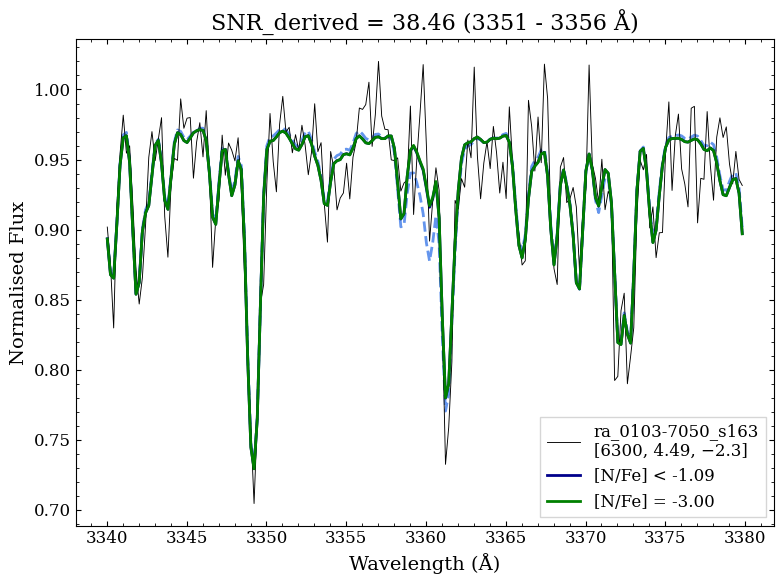

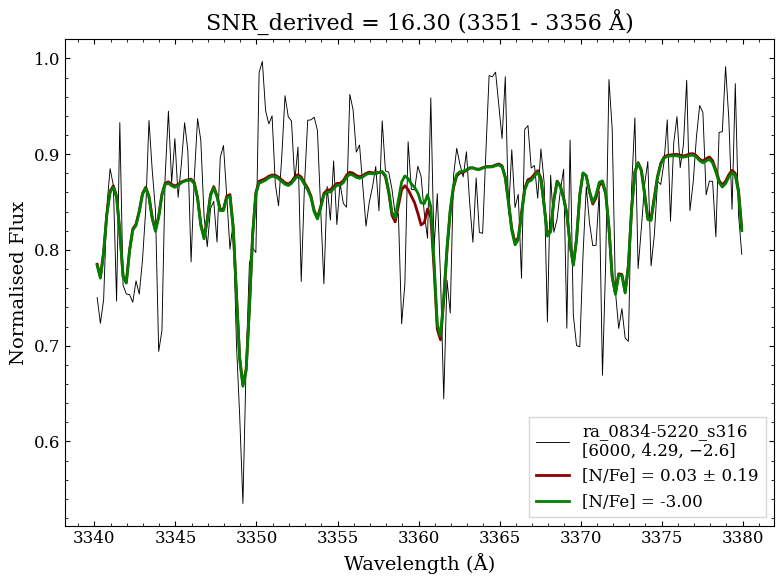

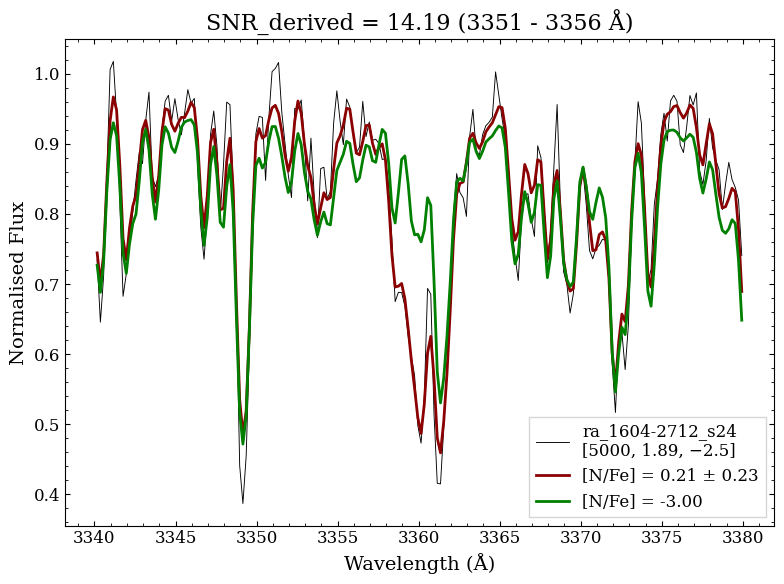

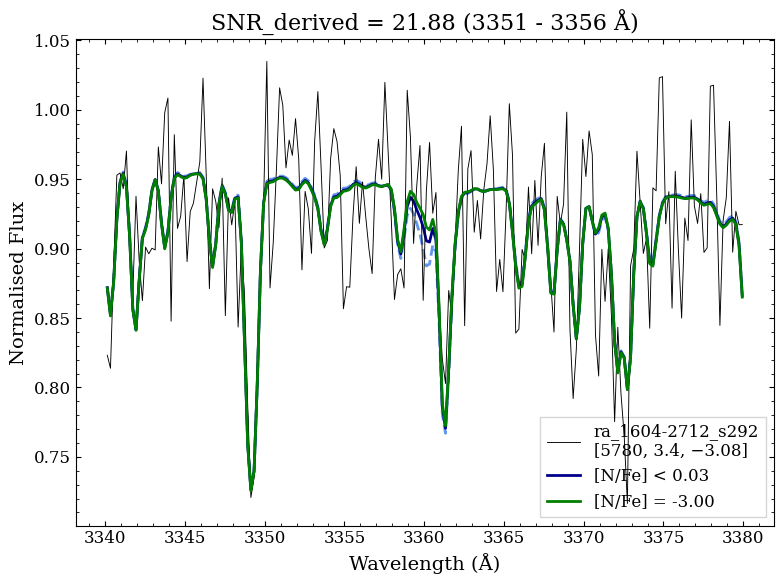

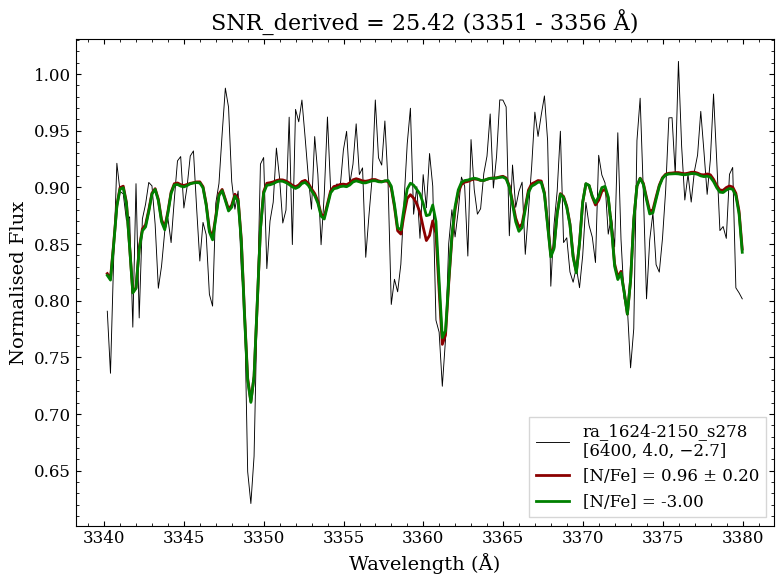

...

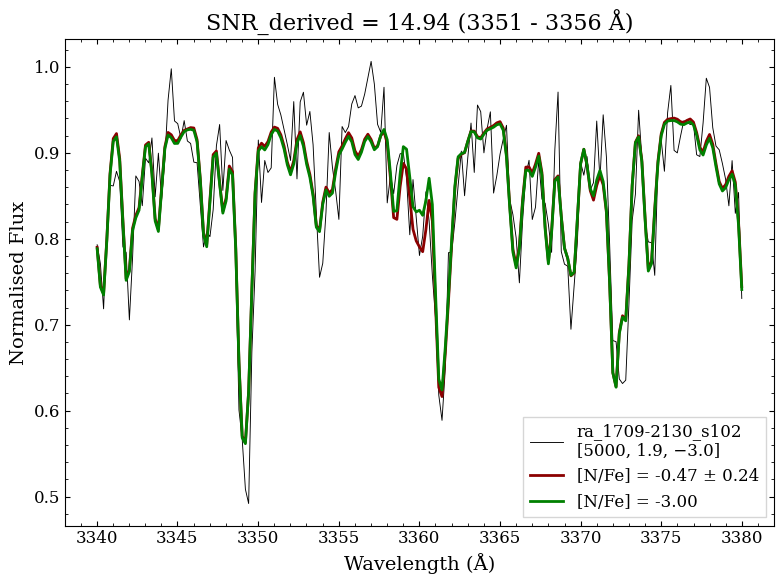

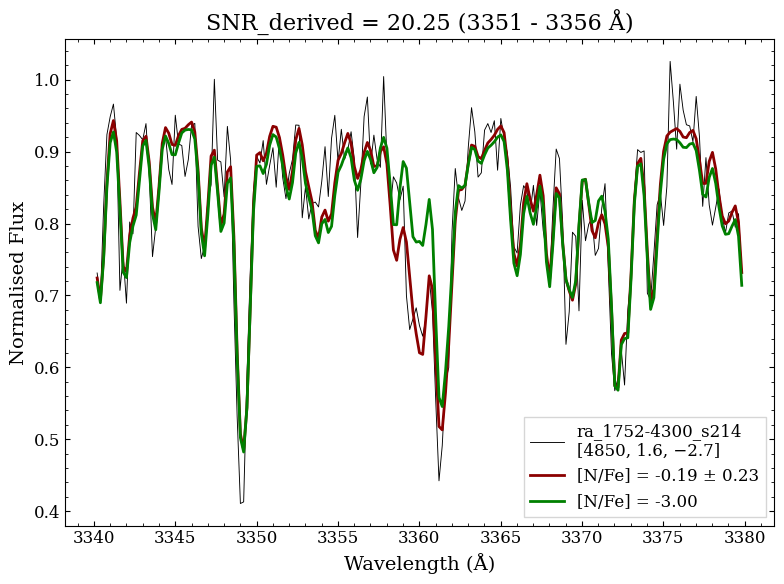

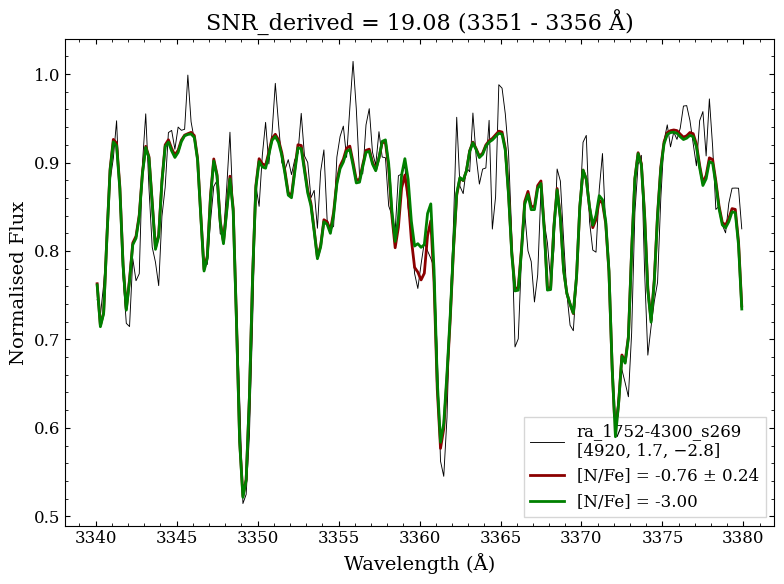

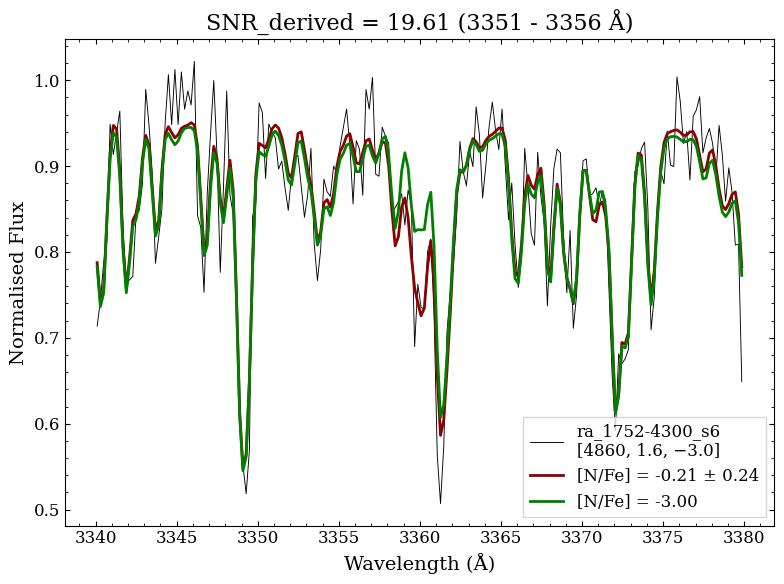

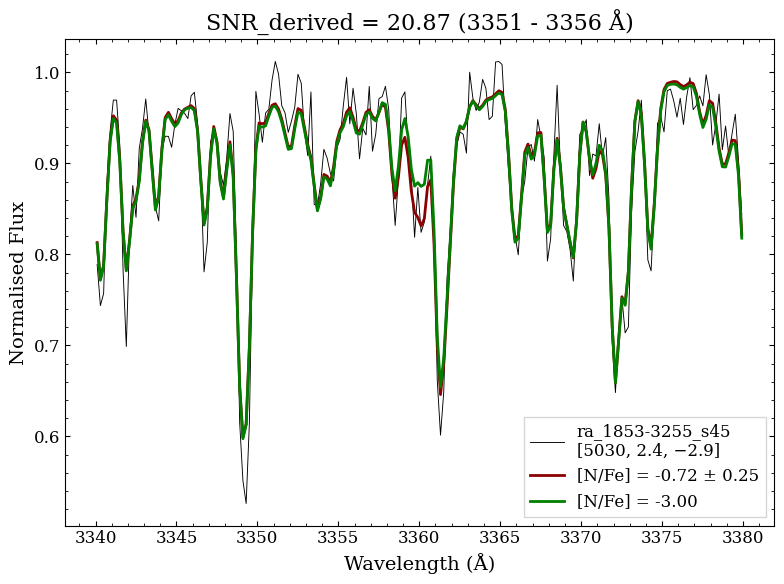

In [33]:
def CN_spec_fit(detect_flag, spec_dir, element, abund_val, abund_err, abund_ul, star_params, savepath, wavelim=None):
    
    
    star_id = star_params['star_id']
    snr_given = stars_data[stars_data['star_id'] == star_id]['snr_uvb'].to_numpy()[0]
    
    # If detection, then plot the best abundance spectra, with ± error
    if detect_flag == 'Y':

        # Getting the file paths for the spectra
        # If the file does not exist (idk why), try the next abundance value (it's close enough!)
        try:   
            spec_abund = f'{spec_dir}{abund_val:.2f}_spec.csv'
            spec_abund_df = pd.read_csv(spec_abund)
        except FileNotFoundError:
            abund_val_2 = abund_val + 0.01
            spec_abund = f'{spec_dir}{abund_val_2:.2f}_spec.csv'
            spec_abund_df = pd.read_csv(spec_abund)
            
        try:
            spec_abund_perr = f'{spec_dir}{abund_val + abund_err:.2f}_spec.csv'
            spec_abund_perr_df = pd.read_csv(spec_abund_perr)
        except FileNotFoundError:
            abund_val_2 = (abund_val + abund_err) + 0.01
            spec_abund_perr = f'{spec_dir}{abund_val_2:.2f}_spec.csv'
            spec_abund_perr_df = pd.read_csv(spec_abund_perr)
            
        try:
            spec_abund_merr = f'{spec_dir}{abund_val - abund_err:.2f}_spec.csv'
            spec_abund_merr_df = pd.read_csv(spec_abund_merr)
        except FileNotFoundError:
            abund_val_2 = (abund_val - abund_err) + 0.01
            spec_abund_merr = f'{spec_dir}{abund_val_2:.2f}_spec.csv'
            spec_abund_merr_df = pd.read_csv(spec_abund_merr)
            
        # Getting spectra at -3.0 dex
        try:   
            spec_empty = f'{spec_dir}{-3.0:.2f}_spec.csv'
            spec_empty_df = pd.read_csv(spec_empty)
        except FileNotFoundError:
            abund_val_2 = -3.0 + 0.01
            spec_empty = f'{spec_dir}{abund_val_2:.2f}_spec.csv'
            spec_empty_df = pd.read_csv(spec_empty)
        
            
        # Plotting the spectra
        obs_wave = np.array(ast.literal_eval(spec_abund_df['obs_wave'].to_numpy()[0]))
        obs_flux = np.array(ast.literal_eval(spec_abund_df['obs_flux'].to_numpy()[0]))
        bestfit_wave = np.array(ast.literal_eval(spec_abund_df['fit_wave'].to_numpy()[0]))
        bestfit_flux = np.array(ast.literal_eval(spec_abund_df['fit_flux'].to_numpy()[0]))
        pfit_wave = np.array(ast.literal_eval(spec_abund_perr_df['fit_wave'].to_numpy()[0]))
        pfit_flux = np.array(ast.literal_eval(spec_abund_perr_df['fit_flux'].to_numpy()[0]))
        mfit_wave = np.array(ast.literal_eval(spec_abund_merr_df['fit_wave'].to_numpy()[0]))
        mfit_flux = np.array(ast.literal_eval(spec_empty_df['fit_flux'].to_numpy()[0]))
        empty_wave = np.array(ast.literal_eval(spec_empty_df['fit_wave'].to_numpy()[0]))
        empty_flux =  np.array(ast.literal_eval(spec_empty_df['fit_flux'].to_numpy()[0]))
        
        # Getting the snr
        snr_derived = np.mean(obs_flux[np.where((obs_wave >= 3351) & (obs_wave <= 3356))])/np.std(obs_flux[np.where((obs_wave >= 3351) & (obs_wave <= 3356))])
        
        if wavelim is not None:
            obs_wavelim = np.where((obs_wave >= wavelim[0]) & (obs_wave <= wavelim[1]))
            obs_wave = obs_wave[obs_wavelim]
            obs_flux = obs_flux[obs_wavelim]
            bestfit_wavelim = np.where((bestfit_wave >= wavelim[0]) & (bestfit_wave <= wavelim[1]))
            bestfit_wave = bestfit_wave[bestfit_wavelim]
            bestfit_flux = bestfit_flux[bestfit_wavelim]
            pfit_wavelim = np.where((pfit_wave >= wavelim[0]) & (pfit_wave <= wavelim[1]))
            pfit_wave = pfit_wave[pfit_wavelim]
            pfit_flux = pfit_flux[pfit_wavelim]
            mfit_wavelim = np.where((mfit_wave >= wavelim[0]) & (mfit_wave <= wavelim[1]))
            mfit_wave = mfit_wave[mfit_wavelim]
            mfit_flux = mfit_flux[mfit_wavelim]
            empty_wavelim = np.where((empty_wave >= wavelim[0]) & (empty_wave <= wavelim[1]))
            empty_wave = empty_wave[empty_wavelim]
            empty_flux = empty_flux[empty_wavelim]
        
        # print(obs_flux)
        # print(bestfit_flux)
        # print(pfit_flux)
        # print(mfit_flux)
                
        plt.plot(obs_wave, obs_flux, linewidth=0.65, color='black', 
                 label='{0}\n[{1}, {2}, {3}]'.format(star_params['star_id'], star_params['teff'], star_params['logg'], star_params['feh']))
        plt.plot(bestfit_wave, bestfit_flux, linewidth=2, color='darkred', label='[{0}/Fe] = {1:.2f} ± {2:.2f}'.format(element, abund_val, abund_err))
        # plt.plot(pfit_wave, pfit_flux, linewidth=0.8, color='darkred')
        # plt.plot(mfit_wave, mfit_flux, linewidth=0.8, color='darkred')
        plt.plot(empty_wave, empty_flux, linewidth=2, color='green', zorder=12, label='[N/Fe] = -3.00')
        # plt.fill_between(obs_wave, pfit_flux, mfit_flux, color='red', alpha=0.3)


        plt.xlabel('Wavelength (Å)')
        plt.ylabel('Normalised Flux')
        plt.legend(fancybox=False)
        plt.title(f'SNR_derived = {snr_derived:.2f} (3351 - 3356 Å)')
        plt.tight_layout()
        
        plt.savefig('/data/misfit/benlowe/xshooter/korg_data/tests/NH_tests/' + star_params['star_id'] + '_plot.png', dpi=300, transparent=False, facecolor="white")
        # plt.savefig(savepath + star_params['star_id'] + '_plot.pdf', dpi=300, transparent=False, facecolor="white")
        # plt.savefig(savepath + star_params['star_id'] + '_plot.png', dpi=300, transparent=False, facecolor="white")

    if detect_flag == 'N':

        # Getting the file paths for the spectra
        # If the file does not exist (idk why), try the next abundance value (it's close enough!)
        try:   
            spec_abund_ul = f'{spec_dir}{abund_ul:.2f}_spec.csv'
            spec_abund_ul_df = pd.read_csv(spec_abund_ul)
        except FileNotFoundError:
            abund_val_2 = abund_ul + 0.01
            spec_abund_ul = f'{spec_dir}{abund_val_2:.2f}_spec.csv'
            spec_abund_ul_df = pd.read_csv(spec_abund_ul)
            
        # For the upper limit spectra, also plot a reference spectra at 0.5 dex
        try:   
            spec_abund_ref = f'{spec_dir}{0.5:.2f}_spec.csv'
            spec_abund_ref_df = pd.read_csv(spec_abund_ref)
        except FileNotFoundError:
            abund_val_2 = 0.5 + 0.01
            spec_abund_ref = f'{spec_dir}{abund_val_2:.2f}_spec.csv'
            spec_abund_ref_df = pd.read_csv(spec_abund_ref)
            
        # Getting spectra at -3.0 dex
        try:   
            spec_empty = f'{spec_dir}{-3.0:.2f}_spec.csv'
            spec_empty_df = pd.read_csv(spec_empty)
        except FileNotFoundError:
            abund_val_2 = -3.0 + 0.01
            spec_empty = f'{spec_dir}{abund_val_2:.2f}_spec.csv'
            spec_empty_df = pd.read_csv(spec_empty)
                        
        # Plotting the spectra
        obs_wave = np.array(ast.literal_eval(spec_abund_ul_df['obs_wave'].to_numpy()[0]))
        obs_flux = np.array(ast.literal_eval(spec_abund_ul_df['obs_flux'].to_numpy()[0]))
        ul_wave = np.array(ast.literal_eval(spec_abund_ul_df['fit_wave'].to_numpy()[0]))
        ul_flux = np.array(ast.literal_eval(spec_abund_ul_df['fit_flux'].to_numpy()[0]))
        ref_wave = np.array(ast.literal_eval(spec_abund_ref_df['fit_wave'].to_numpy()[0]))
        ref_flux = np.array(ast.literal_eval(spec_abund_ref_df['fit_flux'].to_numpy()[0]))
        empty_wave = np.array(ast.literal_eval(spec_empty_df['fit_wave'].to_numpy()[0]))
        empty_flux =  np.array(ast.literal_eval(spec_empty_df['fit_flux'].to_numpy()[0]))

        
        snr_derived = np.mean(obs_flux[np.where((obs_wave >= 3351) & (obs_wave <= 3356))])/np.std(obs_flux[np.where((obs_wave >= 3351) & (obs_wave <= 3356))])

        
        if wavelim is not None:
            obs_wavelim = np.where((obs_wave >= wavelim[0]) & (obs_wave <= wavelim[1]))
            obs_wave = obs_wave[obs_wavelim]
            obs_flux = obs_flux[obs_wavelim]
            ul_wavelim = np.where((ul_wave >= wavelim[0]) & (ul_wave <= wavelim[1]))
            ul_wave = ul_wave[ul_wavelim]
            ul_flux = ul_flux[ul_wavelim]
            ref_wavelim = np.where((ref_wave >= wavelim[0]) & (ref_wave <= wavelim[1]))
            ref_wave = ref_wave[ref_wavelim]
            ref_flux = ref_flux[ref_wavelim]
            empty_wavelim = np.where((empty_wave >= wavelim[0]) & (empty_wave <= wavelim[1]))
            empty_wave = empty_wave[empty_wavelim]
            empty_flux = empty_flux[empty_wavelim]

        
        # print(obs_flux)
        # print(bestfit_flux)
        # print(pfit_flux)
        # print(mfit_flux)
                
        plt.plot(obs_wave, obs_flux, linewidth=0.65, color='black', 
                 label='{0}\n[{1}, {2}, {3}]'.format(star_params['star_id'], star_params['teff'], star_params['logg'], star_params['feh']), zorder=10)
        plt.plot(ul_wave, ul_flux, linewidth=2, color='darkblue', label='[{0}/Fe] < {1:.2f}'.format(element, abund_ul), zorder=5)
        plt.plot(ref_wave, ref_flux, linewidth=2, color='cornflowerblue', linestyle='--', zorder=0)
        plt.plot(empty_wave, empty_flux, linewidth=2, color='green', zorder=12, label='[N/Fe] = -3.00')


        plt.xlabel('Wavelength (Å)')
        plt.ylabel('Normalised Flux')
        plt.legend(fancybox=False)
        plt.title(f'SNR_derived = {snr_derived:.2f} (3351 - 3356 Å)')
        plt.tight_layout()

        plt.savefig('/data/misfit/benlowe/xshooter/korg_data/tests/NH_tests/' + star_params['star_id'] + '_plot.png', dpi=300, transparent=False, facecolor="white")
        # plt.savefig(savepath + star_params['star_id'] + '_plot.pdf', dpi=300, transparent=False, facecolor="white")
        # plt.savefig(savepath + star_params['star_id'] + '_plot.png', dpi=300, transparent=False, facecolor="white")

    

stars = stars_data['star_id'].to_numpy()
params_rounded = pd.read_csv('/data/misfit/benlowe/xshooter/stellar_params/star_params_rd.csv')

for star in stars:

    # Getting the entries for the star
    star_data = stars_upperlimits[stars_upperlimits['star_id'] == star]
    star_params = stars_data[stars_data['star_id'] == star]
    
    # Stellar parameters
    star_teff = params_rounded[params_rounded['star_id'] == star]['teff'].to_numpy()[0]
    star_logg = params_rounded[params_rounded['star_id'] == star]['logg'].to_numpy()[0]
    star_feh = params_rounded[params_rounded['star_id'] == star]['feh'].to_numpy()[0]
    star_snr = star_params['snr_uvb'].to_numpy()[0]
    params = {'star_id': star, 'teff': star_teff, 'logg': star_logg, 'feh': star_feh, 'snr': star_snr}

    # Getting C abundances. 
    # We want the uncorrected C abundances (the ones provided are corrected), so need to subtract the corrections off
    c_I_df = star_data[star_data['el'] == 'C_I']
    c_I_detect = c_I_df['detection'].to_numpy()[0]
    c_I_val = c_I_df['bestfit_abund_xfe'].to_numpy()[0]
    c_I_err = c_I_df['bestfit_abund_tefferr_xfe'].to_numpy()[0]
    c_I_ul = c_I_df['upper_limit_xfe'].to_numpy()[0]
    
    c_I_correct_df = pd.read_csv('/data/misfit/benlowe/xshooter/C_evolve_corrections/cfe_corrections.csv')
    c_I_val_corr = c_I_correct_df[c_I_correct_df['star_id'] == star]['cfe_corr'].to_numpy()[0]
    
    if star == 'ra_1656-1433_s143':
        c_I_val = 0.358195 - c_I_val_corr
        c_I_err = abs(c_I_val - (0.588063 - c_I_val_corr))
    else:
        c_I_val = c_I_val - c_I_val_corr
    
    # Getting N abundances
    n_I_abunds = star_data[star_data['el'] == 'N_I']
    n_I_detect = n_I_abunds['detection'].to_numpy()[0]
    n_I_val = n_I_abunds['bestfit_abund_xfe'].to_numpy()[0]
    n_I_err = n_I_abunds['bestfit_abund_tefferr_xfe'].to_numpy()[0]  
    n_I_ul = n_I_abunds['upper_limit_xfe'].to_numpy()[0]
    
    # if n_I_ul < -2.00:
    #     n_I_ul = -2.00
    
    # Directory to spectral data
    spec_c_dir = f'/data/misfit/benlowe/xshooter/korg_data/synths/{star}/C_I/obs/line_4300.313/spectra/'
    spec_n_dir = f'/data/misfit/benlowe/xshooter/korg_data/synths/{star}/N_I/obs/line_3360.22/spectra/'
    
    # Save path
    cfe_savepath = '/data/misfit/benlowe/xshooter/results/cfe_plots/'
    nfe_savepath = '/data/misfit/benlowe/xshooter/results/nfe_plots/'

    # plt.figure(figsize=(8, 6))
    # CN_spec_fit(detect_flag=c_I_detect, spec_dir=spec_c_dir, element='C', abund_val=c_I_val, abund_err=c_I_err, 
    #             abund_ul=c_I_ul, star_params=params, wavelim=[4260, 4330], savepath=cfe_savepath)
    
    plt.figure(figsize=(8, 6))
    CN_spec_fit(detect_flag=n_I_detect, spec_dir=spec_n_dir, element='N', abund_val=n_I_val, abund_err=n_I_err, 
                abund_ul=n_I_ul, star_params=params, wavelim=[3310, 3410], savepath=nfe_savepath)
    
    # [3350, 3370]
            

Test plots on CH

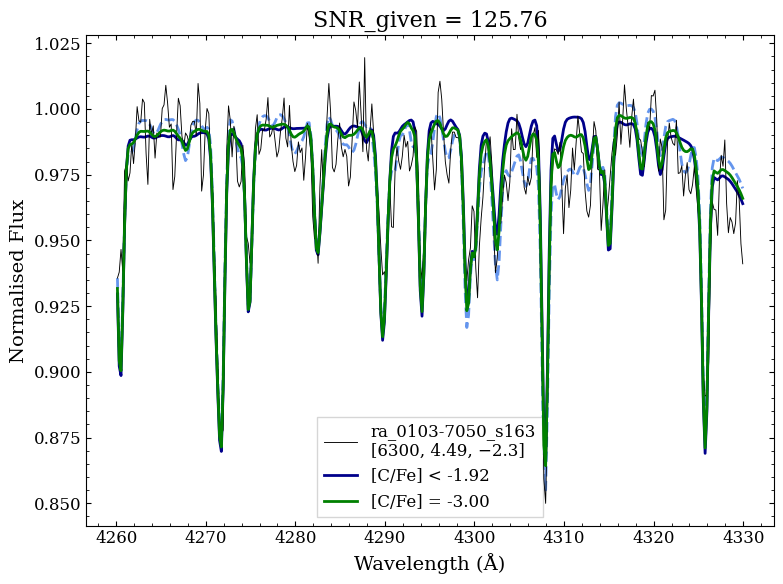

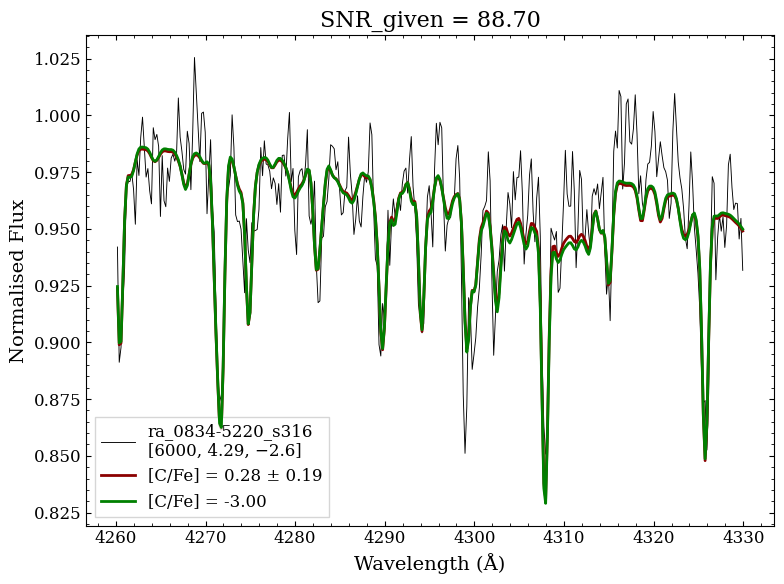

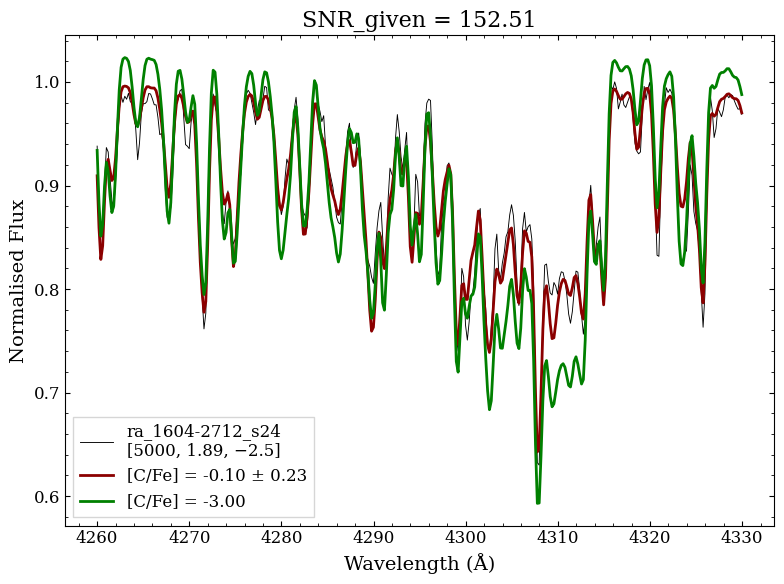

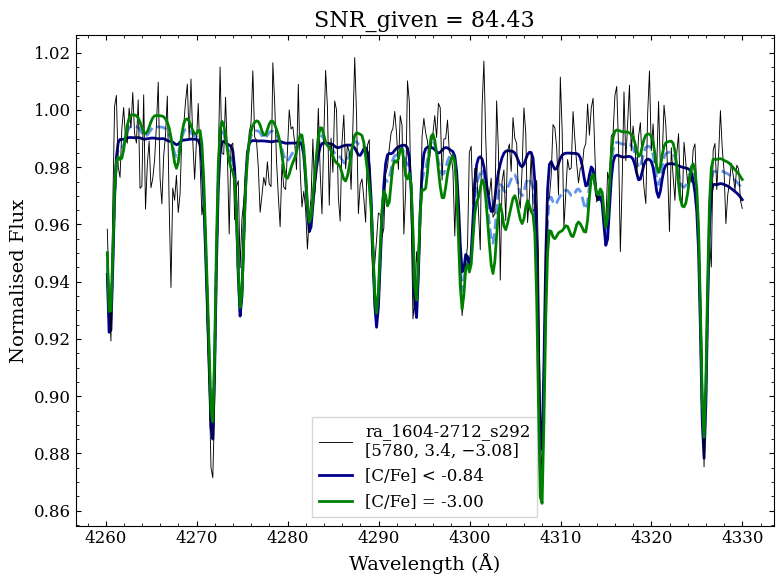

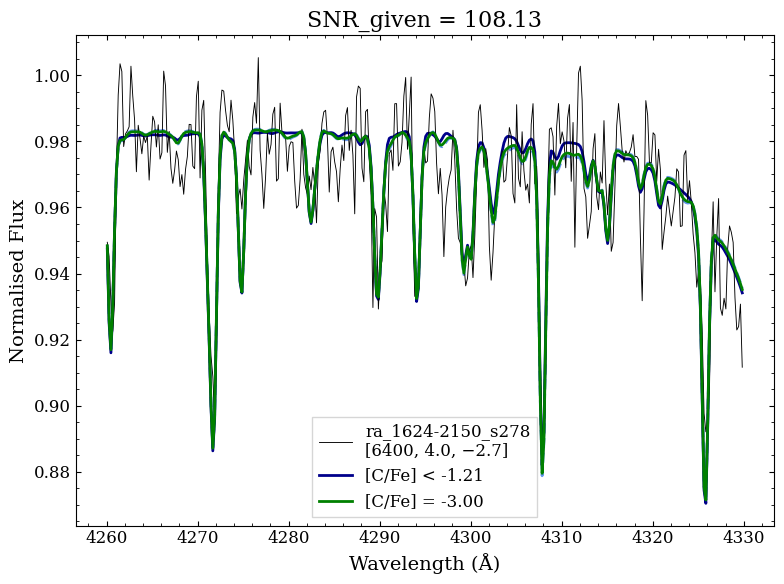

...

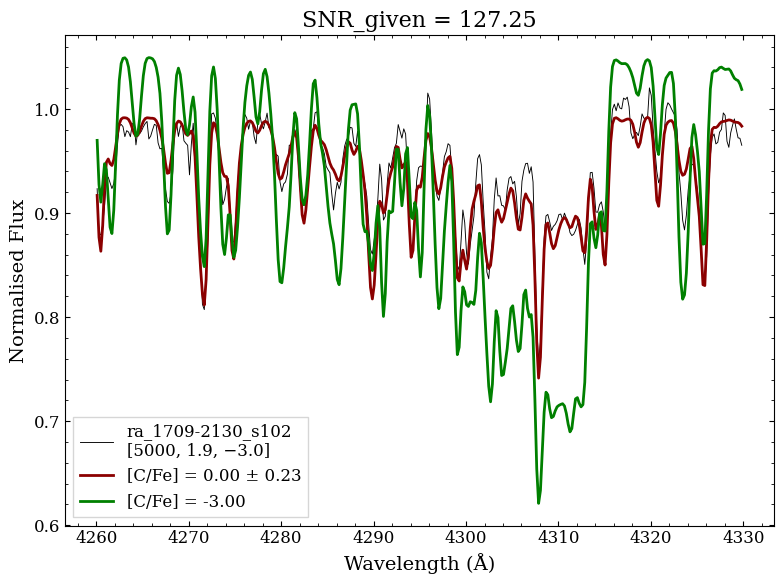

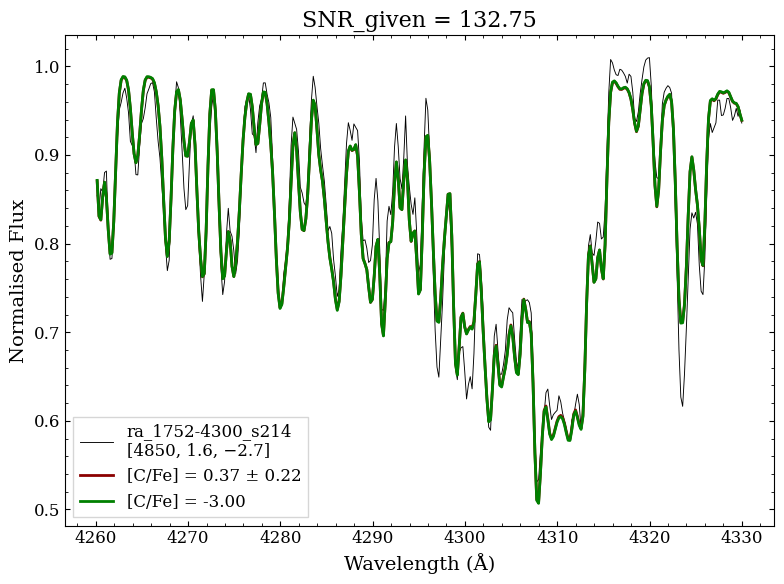

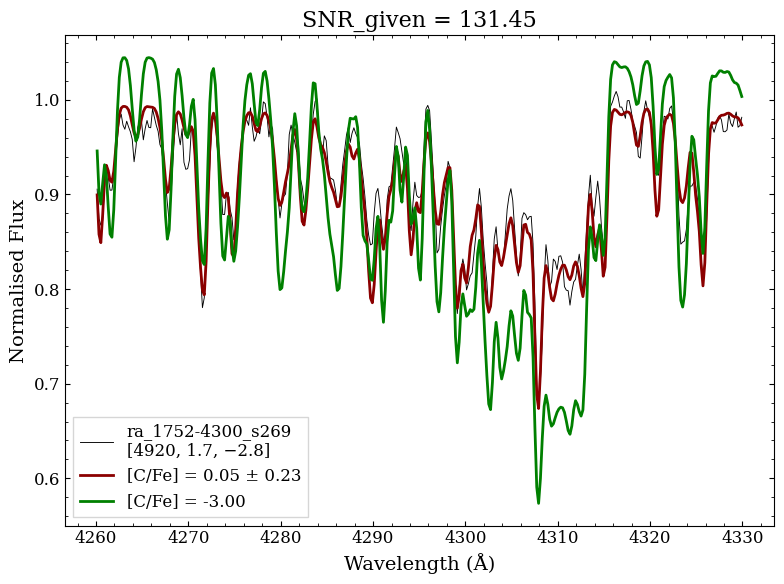

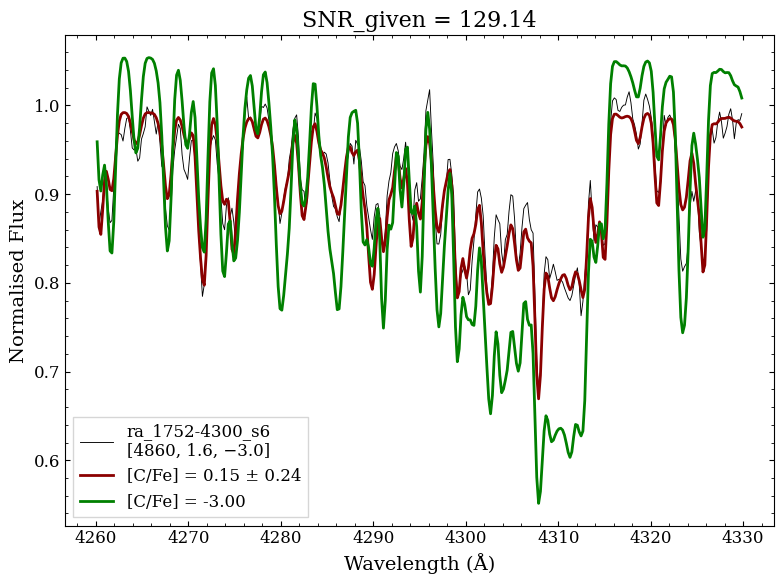

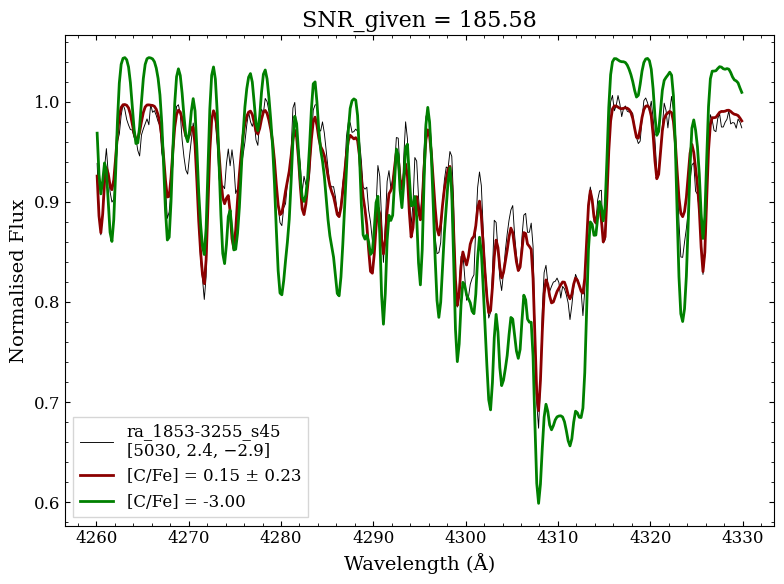

In [10]:
def CN_spec_fit(detect_flag, spec_dir, element, abund_val, abund_err, abund_ul, star_params, savepath, wavelim=None):
    
    
    star_id = star_params['star_id']
    snr_given = stars_data[stars_data['star_id'] == star_id]['snr_uvb'].to_numpy()[0]
    
    # If detection, then plot the best abundance spectra, with ± error
    if detect_flag == 'Y':

        # Getting the file paths for the spectra
        # If the file does not exist (idk why), try the next abundance value (it's close enough!)
        try:   
            spec_abund = f'{spec_dir}{abund_val:.2f}_spec.csv'
            spec_abund_df = pd.read_csv(spec_abund)
        except FileNotFoundError:
            abund_val_2 = abund_val + 0.01
            spec_abund = f'{spec_dir}{abund_val_2:.2f}_spec.csv'
            spec_abund_df = pd.read_csv(spec_abund)
            
        try:
            spec_abund_perr = f'{spec_dir}{abund_val + abund_err:.2f}_spec.csv'
            spec_abund_perr_df = pd.read_csv(spec_abund_perr)
        except FileNotFoundError:
            abund_val_2 = (abund_val + abund_err) + 0.01
            spec_abund_perr = f'{spec_dir}{abund_val_2:.2f}_spec.csv'
            spec_abund_perr_df = pd.read_csv(spec_abund_perr)
            
        try:
            spec_abund_merr = f'{spec_dir}{abund_val - abund_err:.2f}_spec.csv'
            spec_abund_merr_df = pd.read_csv(spec_abund_merr)
        except FileNotFoundError:
            abund_val_2 = (abund_val - abund_err) + 0.01
            spec_abund_merr = f'{spec_dir}{abund_val_2:.2f}_spec.csv'
            spec_abund_merr_df = pd.read_csv(spec_abund_merr)
            
        # Getting spectra at -3.0 dex
        try:   
            spec_empty = f'{spec_dir}{-3.0:.2f}_spec.csv'
            spec_empty_df = pd.read_csv(spec_empty)
        except FileNotFoundError:
            abund_val_2 = -3.0 + 0.01
            spec_empty = f'{spec_dir}{abund_val_2:.2f}_spec.csv'
            spec_empty_df = pd.read_csv(spec_empty)
        
            
        # Plotting the spectra
        obs_wave = np.array(ast.literal_eval(spec_abund_df['obs_wave'].to_numpy()[0]))
        obs_flux = np.array(ast.literal_eval(spec_abund_df['obs_flux'].to_numpy()[0]))
        bestfit_wave = np.array(ast.literal_eval(spec_abund_df['fit_wave'].to_numpy()[0]))
        bestfit_flux = np.array(ast.literal_eval(spec_abund_df['fit_flux'].to_numpy()[0]))
        pfit_wave = np.array(ast.literal_eval(spec_abund_perr_df['fit_wave'].to_numpy()[0]))
        pfit_flux = np.array(ast.literal_eval(spec_abund_perr_df['fit_flux'].to_numpy()[0]))
        mfit_wave = np.array(ast.literal_eval(spec_abund_merr_df['fit_wave'].to_numpy()[0]))
        mfit_flux = np.array(ast.literal_eval(spec_empty_df['fit_flux'].to_numpy()[0]))
        empty_wave = np.array(ast.literal_eval(spec_empty_df['fit_wave'].to_numpy()[0]))
        empty_flux =  np.array(ast.literal_eval(spec_empty_df['fit_flux'].to_numpy()[0]))
        
        # Getting the snr
        # snr_derived = np.mean(obs_flux[np.where((obs_wave >= 3351) & (obs_wave <= 3356))])/np.std(obs_flux[np.where((obs_wave >= 3351) & (obs_wave <= 3356))])
        
        if wavelim is not None:
            obs_wavelim = np.where((obs_wave >= wavelim[0]) & (obs_wave <= wavelim[1]))
            obs_wave = obs_wave[obs_wavelim]
            obs_flux = obs_flux[obs_wavelim]
            bestfit_wavelim = np.where((bestfit_wave >= wavelim[0]) & (bestfit_wave <= wavelim[1]))
            bestfit_wave = bestfit_wave[bestfit_wavelim]
            bestfit_flux = bestfit_flux[bestfit_wavelim]
            pfit_wavelim = np.where((pfit_wave >= wavelim[0]) & (pfit_wave <= wavelim[1]))
            pfit_wave = pfit_wave[pfit_wavelim]
            pfit_flux = pfit_flux[pfit_wavelim]
            mfit_wavelim = np.where((mfit_wave >= wavelim[0]) & (mfit_wave <= wavelim[1]))
            mfit_wave = mfit_wave[mfit_wavelim]
            mfit_flux = mfit_flux[mfit_wavelim]
            empty_wavelim = np.where((empty_wave >= wavelim[0]) & (empty_wave <= wavelim[1]))
            empty_wave = empty_wave[empty_wavelim]
            empty_flux = empty_flux[empty_wavelim]
        
        # print(obs_flux)
        # print(bestfit_flux)
        # print(pfit_flux)
        # print(mfit_flux)
                
        plt.plot(obs_wave, obs_flux, linewidth=0.65, color='black', 
                 label='{0}\n[{1}, {2}, {3}]'.format(star_params['star_id'], star_params['teff'], star_params['logg'], star_params['feh']))
        plt.plot(bestfit_wave, bestfit_flux, linewidth=2, color='darkred', label='[{0}/Fe] = {1:.2f} ± {2:.2f}'.format(element, abund_val, abund_err))
        # plt.plot(pfit_wave, pfit_flux, linewidth=0.8, color='darkred')
        # plt.plot(mfit_wave, mfit_flux, linewidth=0.8, color='darkred')
        plt.plot(empty_wave, empty_flux, linewidth=2, color='green', zorder=12, label='[C/Fe] = -3.00')
        # plt.fill_between(obs_wave, pfit_flux, mfit_flux, color='red', alpha=0.3)


        plt.xlabel('Wavelength (Å)')
        plt.ylabel('Normalised Flux')
        plt.legend(fancybox=False)
        plt.title(f'SNR_given = {snr_given:.2f}')
        plt.tight_layout()
        
        plt.savefig('/data/misfit/benlowe/xshooter/korg_data/tests/CH_tests/' + star_params['star_id'] + '_plot.png', dpi=300, transparent=False, facecolor="white")
        # plt.savefig(savepath + star_params['star_id'] + '_plot.pdf', dpi=300, transparent=False, facecolor="white")
        # plt.savefig(savepath + star_params['star_id'] + '_plot.png', dpi=300, transparent=False, facecolor="white")

    if detect_flag == 'N':

        # Getting the file paths for the spectra
        # If the file does not exist (idk why), try the next abundance value (it's close enough!)
        try:   
            spec_abund_ul = f'{spec_dir}{abund_ul:.2f}_spec.csv'
            spec_abund_ul_df = pd.read_csv(spec_abund_ul)
        except FileNotFoundError:
            abund_val_2 = abund_ul + 0.01
            spec_abund_ul = f'{spec_dir}{abund_val_2:.2f}_spec.csv'
            spec_abund_ul_df = pd.read_csv(spec_abund_ul)
            
        # For the upper limit spectra, also plot a reference spectra at 0.5 dex
        try:   
            spec_abund_ref = f'{spec_dir}{0.5:.2f}_spec.csv'
            spec_abund_ref_df = pd.read_csv(spec_abund_ref)
        except FileNotFoundError:
            abund_val_2 = 0.5 + 0.01
            spec_abund_ref = f'{spec_dir}{abund_val_2:.2f}_spec.csv'
            spec_abund_ref_df = pd.read_csv(spec_abund_ref)
            
        # Getting spectra at -3.0 dex
        try:   
            spec_empty = f'{spec_dir}{-3.0:.2f}_spec.csv'
            spec_empty_df = pd.read_csv(spec_empty)
        except FileNotFoundError:
            abund_val_2 = -3.0 + 0.01
            spec_empty = f'{spec_dir}{abund_val_2:.2f}_spec.csv'
            spec_empty_df = pd.read_csv(spec_empty)
                        
        # Plotting the spectra
        obs_wave = np.array(ast.literal_eval(spec_abund_ul_df['obs_wave'].to_numpy()[0]))
        obs_flux = np.array(ast.literal_eval(spec_abund_ul_df['obs_flux'].to_numpy()[0]))
        ul_wave = np.array(ast.literal_eval(spec_abund_ul_df['fit_wave'].to_numpy()[0]))
        ul_flux = np.array(ast.literal_eval(spec_abund_ul_df['fit_flux'].to_numpy()[0]))
        ref_wave = np.array(ast.literal_eval(spec_abund_ref_df['fit_wave'].to_numpy()[0]))
        ref_flux = np.array(ast.literal_eval(spec_abund_ref_df['fit_flux'].to_numpy()[0]))
        empty_wave = np.array(ast.literal_eval(spec_empty_df['fit_wave'].to_numpy()[0]))
        empty_flux =  np.array(ast.literal_eval(spec_empty_df['fit_flux'].to_numpy()[0]))

        
        # snr_derived = np.mean(obs_flux[np.where((obs_wave >= 3351) & (obs_wave <= 3356))])/np.std(obs_flux[np.where((obs_wave >= 3351) & (obs_wave <= 3356))])

        
        if wavelim is not None:
            obs_wavelim = np.where((obs_wave >= wavelim[0]) & (obs_wave <= wavelim[1]))
            obs_wave = obs_wave[obs_wavelim]
            obs_flux = obs_flux[obs_wavelim]
            ul_wavelim = np.where((ul_wave >= wavelim[0]) & (ul_wave <= wavelim[1]))
            ul_wave = ul_wave[ul_wavelim]
            ul_flux = ul_flux[ul_wavelim]
            ref_wavelim = np.where((ref_wave >= wavelim[0]) & (ref_wave <= wavelim[1]))
            ref_wave = ref_wave[ref_wavelim]
            ref_flux = ref_flux[ref_wavelim]
            empty_wavelim = np.where((empty_wave >= wavelim[0]) & (empty_wave <= wavelim[1]))
            empty_wave = empty_wave[empty_wavelim]
            empty_flux = empty_flux[empty_wavelim]

        
        # print(obs_flux)
        # print(bestfit_flux)
        # print(pfit_flux)
        # print(mfit_flux)
                
        plt.plot(obs_wave, obs_flux, linewidth=0.65, color='black', 
                 label='{0}\n[{1}, {2}, {3}]'.format(star_params['star_id'], star_params['teff'], star_params['logg'], star_params['feh']), zorder=10)
        plt.plot(ul_wave, ul_flux, linewidth=2, color='darkblue', label='[{0}/Fe] < {1:.2f}'.format(element, abund_ul), zorder=5)
        plt.plot(ref_wave, ref_flux, linewidth=2, color='cornflowerblue', linestyle='--', zorder=0)
        plt.plot(empty_wave, empty_flux, linewidth=2, color='green', zorder=12, label='[C/Fe] = -3.00')


        plt.xlabel('Wavelength (Å)')
        plt.ylabel('Normalised Flux')
        plt.legend(fancybox=False)
        plt.title(f'SNR_given = {snr_given:.2f}')
        plt.tight_layout()

        plt.savefig('/data/misfit/benlowe/xshooter/korg_data/tests/CH_tests/' + star_params['star_id'] + '_plot.png', dpi=300, transparent=False, facecolor="white")
        # plt.savefig(savepath + star_params['star_id'] + '_plot.pdf', dpi=300, transparent=False, facecolor="white")
        # plt.savefig(savepath + star_params['star_id'] + '_plot.png', dpi=300, transparent=False, facecolor="white")

    

stars = stars_data['star_id'].to_numpy()
params_rounded = pd.read_csv('/data/misfit/benlowe/xshooter/stellar_params/star_params_rd.csv')

for star in stars:

    # Getting the entries for the star
    star_data = stars_upperlimits[stars_upperlimits['star_id'] == star]
    star_params = stars_data[stars_data['star_id'] == star]
    
    # Stellar parameters
    star_teff = params_rounded[params_rounded['star_id'] == star]['teff'].to_numpy()[0]
    star_logg = params_rounded[params_rounded['star_id'] == star]['logg'].to_numpy()[0]
    star_feh = params_rounded[params_rounded['star_id'] == star]['feh'].to_numpy()[0]
    star_snr = star_params['snr_uvb'].to_numpy()[0]
    params = {'star_id': star, 'teff': star_teff, 'logg': star_logg, 'feh': star_feh, 'snr': star_snr}

    # Getting C abundances. 
    # We want the uncorrected C abundances (the ones provided are corrected), so need to subtract the corrections off
    c_I_df = star_data[star_data['el'] == 'C_I']
    c_I_detect = c_I_df['detection'].to_numpy()[0]
    c_I_val = c_I_df['bestfit_abund_xfe'].to_numpy()[0]
    c_I_err = c_I_df['bestfit_abund_tefferr_xfe'].to_numpy()[0]
    c_I_ul = c_I_df['upper_limit_xfe'].to_numpy()[0]
    
    c_I_correct_df = pd.read_csv('/data/misfit/benlowe/xshooter/C_evolve_corrections/cfe_corrections.csv')
    c_I_val_corr = c_I_correct_df[c_I_correct_df['star_id'] == star]['cfe_corr'].to_numpy()[0]
    
    if star == 'ra_1656-1433_s143':
        c_I_val = 0.358195 - c_I_val_corr
        c_I_err = abs(c_I_val - (0.588063 - c_I_val_corr))
    else:
        c_I_val = c_I_val - c_I_val_corr
    
    # Getting N abundances
    n_I_abunds = star_data[star_data['el'] == 'N_I']
    n_I_detect = n_I_abunds['detection'].to_numpy()[0]
    n_I_val = n_I_abunds['bestfit_abund_xfe'].to_numpy()[0]
    n_I_err = n_I_abunds['bestfit_abund_tefferr_xfe'].to_numpy()[0]  
    n_I_ul = n_I_abunds['upper_limit_xfe'].to_numpy()[0]
    
    # if n_I_ul < -2.00:
    #     n_I_ul = -2.00
    
    # Directory to spectral data
    spec_c_dir = f'/data/misfit/benlowe/xshooter/korg_data/synths/{star}/C_I/obs/line_4300.313/spectra/'
    spec_n_dir = f'/data/misfit/benlowe/xshooter/korg_data/synths/{star}/N_I/obs/line_3360.22/spectra/'
    
    # Save path
    cfe_savepath = '/data/misfit/benlowe/xshooter/results/cfe_plots/'
    nfe_savepath = '/data/misfit/benlowe/xshooter/results/nfe_plots/'

    plt.figure(figsize=(8, 6))
    CN_spec_fit(detect_flag=c_I_detect, spec_dir=spec_c_dir, element='C', abund_val=c_I_val, abund_err=c_I_err, 
                abund_ul=c_I_ul, star_params=params, wavelim=[4260, 4330], savepath=cfe_savepath)
    
    # plt.figure(figsize=(8, 6))
    # CN_spec_fit(detect_flag=n_I_detect, spec_dir=spec_n_dir, element='N', abund_val=n_I_val, abund_err=n_I_err, 
    #             abund_ul=n_I_ul, star_params=params, wavelim=[3310, 3410], savepath=nfe_savepath)
    
    # [3350, 3370]
            

## Making accretion plots

[Al/Fe] vs [Mg/Mn]

In [10]:
mnI_lit_abund

,star_id,feh,abund
0,b'CS 22957-022',-2.92,-0.68
1,b'CS 29503-010',-1.00,NaN
2,b'CS 31085-024',-2.80,-0.60
3,b'BS 17570-063',-2.95,NaN
4,b'HE 0024-2523',-2.82,NaN
...,...,...,...
374,b'J224145.62-064643.0',-3.19,-1.08
375,b'J230525.31-213807.0',-3.35,-0.87
376,b'J230702.22-693718.5',-2.89,NaN
377,b'J232121.57-160505.4',-3.03,-0.75


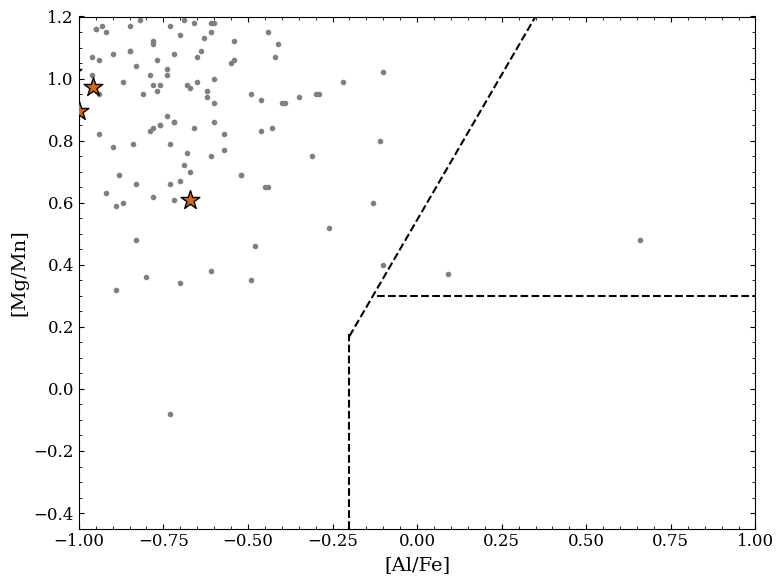

In [64]:
# X-Shooter sample
al_fe_emp = stars_data['Al_I_xfe_it2']
mg_mn_emp = stars_data['Mg_I_xfe_it2'] - stars_data['Mn_I_xfe_it2']

# Literature sample
al_fe_lit = alI_lit_abund['abund'].values
mg_mn_lit = mgI_lit_abund['abund'].values - mnI_lit_abund['abund'].values

# Plotting
plt.figure(figsize=(8, 6))
plt.scatter(al_fe_emp, mg_mn_emp, color='chocolate', marker='*', s=200, edgecolor='black', zorder=3)
plt.scatter(al_fe_lit, mg_mn_lit, color='grey', marker='.')

plt.axvline(x=-0.2, ymax=0.38, color='black', linestyle='--')
plt.axhline(y=0.3, xmin=0.44, color='black', linestyle='--')
plt.plot([-0.2, 0.35], [0.17, 1.2], color='black', linestyle='--')
plt.xlim(-1, 1)
plt.ylim(-0.45, 1.2)
plt.xlabel('[Al/Fe]')
plt.ylabel('[Mg/Mn]')
plt.tight_layout()

In [ ]:
# display(yes_na)
display(yes_na_prodisk)
# display(yes_na_halo)
# display(yes_na_ges)


,star_id,Fe_it2,teff_x,logg_x,Mg_I_xfe_it2,Mg_I_xh_it2,Mg_I_xfe_tefferr,Ca_II_xfe_it2,Ca_II_xh_it2,Ca_II_xfe_tefferr,...,e,dist,Vr,Vphi,X,Y,i,2sig_detect,detect_flag,orbit
0,ra_0103-7050_s163,-2.316444,6298.806689,4.492229,0.223997,-2.092447,0.097545,0.144885,-2.171559,0.070094,...,0.322595,1.360807,9.944337,163.296965,7.692528,-0.794982,47.785507,0.70,no,pro_disk
1,ra_0834-5220_s316,-2.623191,5959.304567,4.286104,0.434260,-2.188931,0.118313,0.335718,-2.287473,0.081916,...,0.591672,1.533442,105.154213,110.539518,8.203069,-1.521019,82.505634,0.08,no,pro_disk
2,ra_1604-2712_s24,-2.466047,5002.684528,1.891750,0.404122,-2.061925,0.126191,0.218059,-2.247989,0.074768,...,0.576337,12.836988,78.775534,-210.282472,-3.623043,-2.666097,30.305945,-0.26,yes,halo
4,ra_1624-2150_s278,-2.679156,6381.865006,3.973617,0.068757,-2.610399,0.247877,0.127461,-2.551696,0.215030,...,0.659060,2.587272,-229.608190,209.354958,5.765052,-0.206388,71.805413,1.27,no,halo
5,ra_1633-2814_s130,-3.327966,4997.869004,1.849800,0.539619,-2.788346,0.079791,0.295623,-3.032343,0.067503,...,0.689207,8.515677,-74.676882,23.297086,-0.010026,-1.272978,53.462936,0.36,yes,gse
6,ra_1633-2814_s284,-3.785562,5261.142090,2.447800,0.401788,-3.383774,0.109950,0.516842,-3.268720,0.050132,...,0.712309,7.450813,-237.213529,230.762746,1.030313,-1.100148,52.340616,1.33,no,gse
8,ra_1656-1433_s143,-2.789339,4791.462397,1.406800,0.429458,-2.359881,0.091310,0.350262,-2.439077,0.064424,...,0.500366,7.702155,175.851105,965.682026,0.899507,0.778123,NaN,NaN,NaN,halo
9,ra_1658-2454_s22,-2.839827,4852.253676,2.164886,0.279424,-2.560402,0.179879,0.300496,-2.539331,0.070875,...,0.610365,7.208796,-117.561953,488.691570,1.150159,-0.342291,41.554085,-0.98,yes,halo
10,ra_1659-2154_s114,-3.700563,4955.802189,1.725800,0.764199,-2.936364,0.245896,0.368295,-3.332268,0.055907,...,0.876559,25.068807,-86.152280,193.375182,-16.249955,0.335624,86.881662,0.93,no,halo
11,ra_1709-2130_s102,-2.967078,4985.984984,1.850150,0.456335,-2.510743,0.094504,0.338383,-2.628695,0.068851,...,0.831303,9.091754,309.260097,323.701893,-0.707910,0.352688,50.195829,-0.58,yes,halo


,star_id,Fe_it2,teff_x,logg_x,Mg_I_xfe_it2,Mg_I_xh_it2,Mg_I_xfe_tefferr,Ca_II_xfe_it2,Ca_II_xh_it2,Ca_II_xfe_tefferr,...,e,dist,Vr,Vphi,X,Y,i,2sig_detect,detect_flag,orbit
7,ra_1648-0653_s38,-2.40275,6039.830368,3.646778,0.338384,-2.064366,0.101289,0.23875,-2.164,0.061265,...,0.020229,2.988196,10.321077,345.229096,5.520911,0.521296,NaN,NaN,NaN,pro_disk


,star_id,Fe_it2,teff_x,logg_x,Mg_I_xfe_it2,Mg_I_xh_it2,Mg_I_xfe_tefferr,Ca_II_xfe_it2,Ca_II_xh_it2,Ca_II_xfe_tefferr,...,e,dist,Vr,Vphi,X,Y,i,2sig_detect,detect_flag,orbit
3,ra_1604-2712_s292,-3.080278,5783.249268,3.4046,0.177362,-2.902916,0.098711,0.327977,-2.752302,0.057867,...,0.456776,5.147421,-53.007179,564.610323,3.449457,-1.130220,26.008098,1.25,yes,halo
13,ra_1752-4300_s269,-2.810264,4917.930552,1.6822,0.297793,-2.512471,0.100227,0.110218,-2.700046,0.075211,...,0.967223,25.412329,32.186203,318.256432,-16.428220,-4.903373,89.998993,-0.46,yes,halo


,star_id,Fe_it2,teff_x,logg_x,Mg_I_xfe_it2,Mg_I_xh_it2,Mg_I_xfe_tefferr,Ca_II_xfe_it2,Ca_II_xh_it2,Ca_II_xfe_tefferr,...,e,dist,Vr,Vphi,X,Y,i,2sig_detect,detect_flag,orbit


## Checking for teff trends

In [9]:
def abund_lines(path, stars, element):
    # Getting abundances for each star
    all_abunds = []
    for star in stars:

        # Getting directory to given star
        star_path = path + star + '/' + element + '/iter_1/{}_results.csv'.format(element.split('_')[0])
        
        # Loading in abundances
        star_df = pd.read_csv(star_path)
        star_lines = star_df['line'].to_numpy()
        star_abund = star_df['abund_xfe'].to_numpy()
        
        # Making new dataframe for each star
        if element == 'Al_I':
            abund_dict = {'star_id': star, str(star_lines[0]): star_abund[0], str(star_lines[1]): star_abund[1]}
            all_abunds.append(abund_dict)
        if element == 'Si_I':
            abund_dict = {'star_id': star, str(star_lines[0]): star_abund[0]}
            all_abunds.append(abund_dict)
        if element == 'Cr_I':
            abund_dict = {'star_id': star, str(star_lines[0]): star_abund[0], str(star_lines[1]): star_abund[1],
                          str(star_lines[2]): star_abund[2], str(star_lines[3]): star_abund[3],
                          str(star_lines[4]): star_abund[4], str(star_lines[5]): star_abund[5],
                          str(star_lines[6]): star_abund[6]}
            all_abunds.append(abund_dict)
        if element == 'Ti_II':
            abund_dict = {'star_id': star, str(star_lines[0]): star_abund[0], str(star_lines[1]): star_abund[1],
                          str(star_lines[2]): star_abund[2], str(star_lines[3]): star_abund[3],
                          str(star_lines[4]): star_abund[4]}
            all_abunds.append(abund_dict)
        if element == 'Sc_II':
            abund_dict = {'star_id': star, str(star_lines[0]): star_abund[0]}
            all_abunds.append(abund_dict)
        if element == 'Co_I':
            abund_dict = {'star_id': star, str(star_lines[0]): star_abund[0]}
            all_abunds.append(abund_dict)
        if element == 'Ni_I':
            abund_dict = {'star_id': star, str(star_lines[0]): star_abund[0]}
            all_abunds.append(abund_dict)
            
            
    
    # Storing all stellar abundnaces into one dataframe
    all_abunds_df = pd.DataFrame(all_abunds)
    
    return all_abunds_df


### In Al-II

In [ ]:
stars = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/stars/stellar_params.csv')
al_abunds = abund_lines(path='/data/misfit/benlowe/xshooter/korg_data/tests/TEST51/', stars=stars['star_id'].to_numpy(), element='Al_I')
al_abunds = pd.merge(stars[['star_id', 'Fe_it2', 'teff', 'logg']], al_abunds, on='star_id', how='inner')

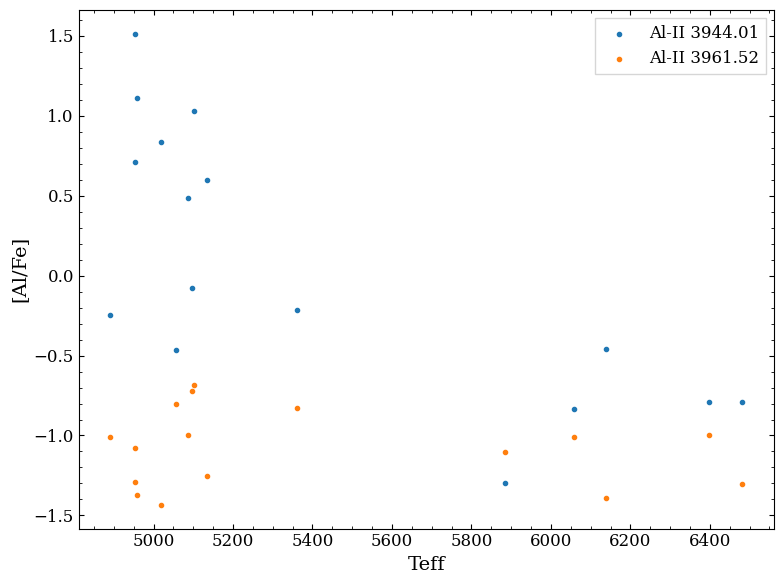

In [73]:
al_abunds.sort_values(by='teff')


plt.figure(figsize=[8,6])
# plt.scatter( al_abunds['teff'], al_abunds['Al_3944.01'] - al_abunds['Al_3961.52'], label='ΔAl-II', marker='.')
plt.scatter(al_abunds['teff'], al_abunds['Al_3944.01'], label='Al-II 3944.01', marker='.')
plt.scatter(al_abunds['teff'], al_abunds['Al_3961.52'], label='Al-II 3961.52', marker='.')
plt.xlabel('Teff')
plt.ylabel('[Al/Fe]')
plt.legend(fancybox=False)
plt.tight_layout()
plt.savefig("/data/misfit/benlowe/results/Al_teff_trends/al_teff.png", dpi=300, transparent=False, facecolor="white")

### In Si-I

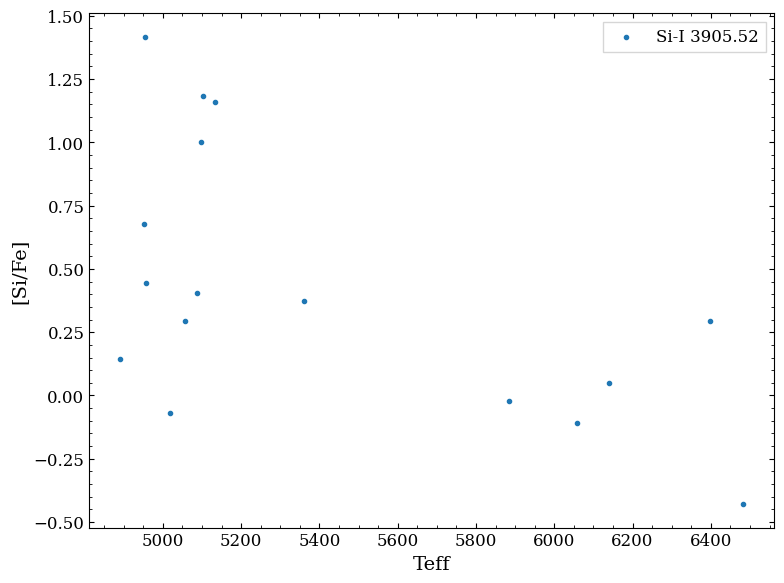

In [84]:
stars = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/stars/stellar_params.csv')
si_abunds = abund_lines(path='/data/misfit/benlowe/xshooter/korg_data/stars/', stars=stars['star_id'].to_numpy(), element='Si_I')
si_abunds = pd.merge(stars[['star_id', 'Fe_it2', 'teff', 'logg']], si_abunds, on='star_id', how='inner')

plt.figure(figsize=[8,6])
plt.scatter(si_abunds['teff'], si_abunds['Si_3905.52'], label='Si-I 3905.52', marker='.')
plt.xlabel('Teff')
plt.ylabel('[Si/Fe]')
plt.legend(fancybox=False)
plt.tight_layout()
plt.savefig("/data/misfit/benlowe/results/abund_teff_trends/si_teff.png", dpi=300, transparent=False, facecolor="white")

### In Cr-I

In [66]:
# Loading in the data
stars = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/stars/stellar_params.csv')
cr_abunds = abund_lines(path='/data/misfit/benlowe/xshooter/korg_data/tests/TEST52/', stars=stars['star_id'].to_numpy(), element='Cr_I')
cr_abunds = pd.merge(stars[['star_id', 'Fe_it2', 'teff', 'logg']], cr_abunds, on='star_id', how='inner')

# Taking averages of Cr abundances for lines 4254.35, 4274.81, 4289.73, and then averages for 5204.50, 5206.02, 5208.41
cr_4250_avg = (cr_abunds['Cr_4254.35'] + cr_abunds['Cr_4274.81'] + cr_abunds['Cr_4289.73']) / 3
cr_5200_avg = (cr_abunds['Cr_5204.5'] + cr_abunds['Cr_5206.02'] + cr_abunds['Cr_5208.41']) / 3
cr_avg = (cr_abunds['Cr_4254.35'] + cr_abunds['Cr_4274.81'] + cr_abunds['Cr_4289.73'] + 
          cr_abunds['Cr_5204.5'] + cr_abunds['Cr_5206.02'] + cr_abunds['Cr_5208.41']) / 6


Making Teff vs [Cr/Fe] plot for all the Cr-I lines

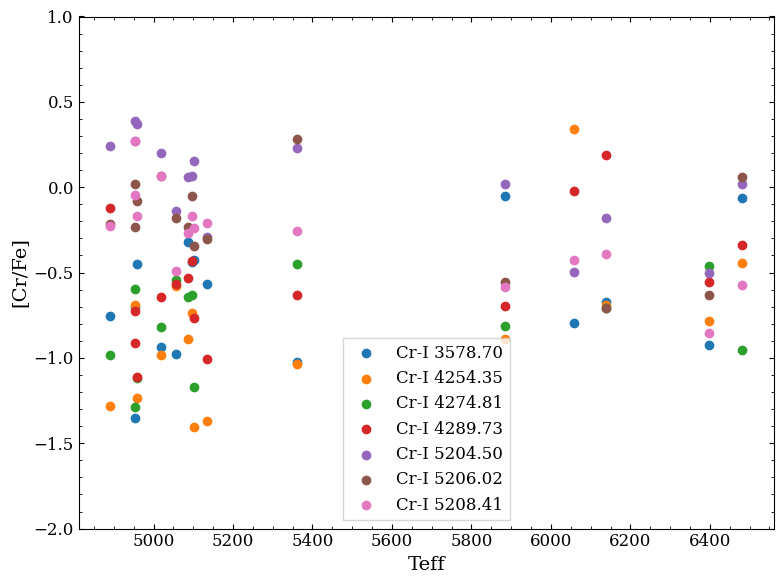

In [63]:
plt.figure(figsize=[8,6])
plt.scatter(cr_abunds['teff'], cr_abunds['Cr_3578.7'], label='Cr-I 3578.70')
plt.scatter(cr_abunds['teff'], cr_abunds['Cr_4254.35'], label='Cr-I 4254.35')
plt.scatter(cr_abunds['teff'], cr_abunds['Cr_4274.81'], label='Cr-I 4274.81')
plt.scatter(cr_abunds['teff'], cr_abunds['Cr_4289.73'], label='Cr-I 4289.73')
plt.scatter(cr_abunds['teff'], cr_abunds['Cr_5204.5'], label='Cr-I 5204.50')
plt.scatter(cr_abunds['teff'], cr_abunds['Cr_5206.02'], label='Cr-I 5206.02')
plt.scatter(cr_abunds['teff'], cr_abunds['Cr_5208.41'], label='Cr-I 5208.41')

plt.xlabel('Teff')
plt.ylabel('[Cr/Fe]')
plt.ylim(-2, 1)
plt.legend(fancybox=False)
plt.tight_layout()
# plt.savefig("/data/misfit/benlowe/results/abund_teff_trends/cr_teff.png", dpi=300, transparent=False, facecolor="white")

Making Teff vs [C/Fe] plot for averages of 4254.35, 4274.81, 4289.73, and then averages for 5204.50, 5206.02, 5208.41

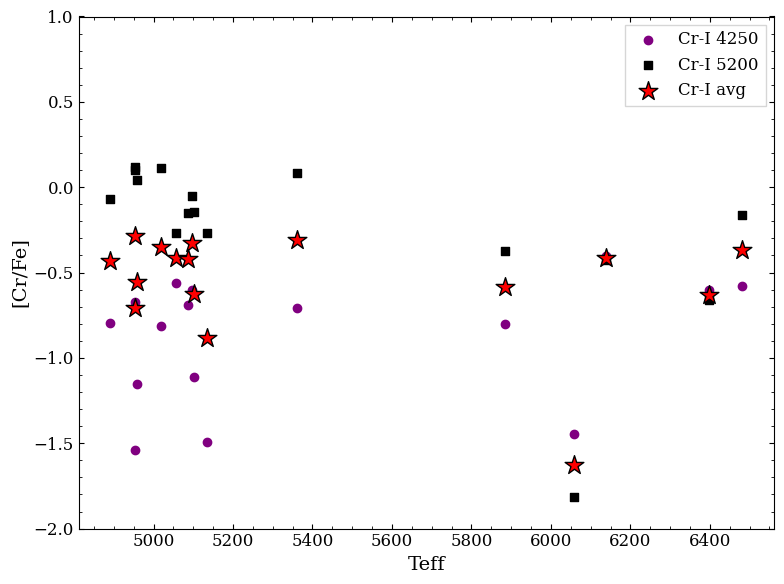

In [65]:
plt.figure(figsize=[8,6])
plt.scatter(cr_abunds['teff'], cr_4250_avg, label='Cr-I 4250', color='purple')
plt.scatter(cr_abunds['teff'], cr_5200_avg, label='Cr-I 5200', marker='s', color='black')
plt.scatter(cr_abunds['teff'], cr_avg, label='Cr-I avg', marker='*', color='red', s=200, edgecolor='black')

plt.xlabel('Teff')
plt.ylabel('[Cr/Fe]')
plt.ylim(-2, 1)
plt.legend(fancybox=False)
plt.tight_layout()
# plt.savefig("/data/misfit/benlowe/results/abund_teff_trends/cr_teff_avg.png", dpi=300, transparent=False, facecolor="white")

Making [Fe/H] vs [Cr/Fe] plot for all Cr-I lines

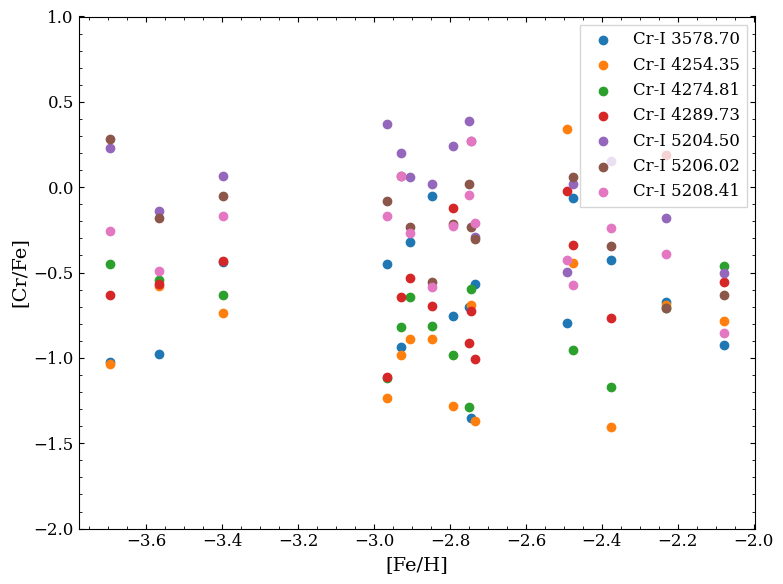

In [67]:
plt.figure(figsize=[8,6])
plt.scatter(cr_abunds['Fe_it2'], cr_abunds['Cr_3578.7'], label='Cr-I 3578.70')
plt.scatter(cr_abunds['Fe_it2'], cr_abunds['Cr_4254.35'], label='Cr-I 4254.35')
plt.scatter(cr_abunds['Fe_it2'], cr_abunds['Cr_4274.81'], label='Cr-I 4274.81')
plt.scatter(cr_abunds['Fe_it2'], cr_abunds['Cr_4289.73'], label='Cr-I 4289.73')
plt.scatter(cr_abunds['Fe_it2'], cr_abunds['Cr_5204.5'], label='Cr-I 5204.50')
plt.scatter(cr_abunds['Fe_it2'], cr_abunds['Cr_5206.02'], label='Cr-I 5206.02')
plt.scatter(cr_abunds['Fe_it2'], cr_abunds['Cr_5208.41'], label='Cr-I 5208.41')

plt.xlabel('[Fe/H]')
plt.ylabel('[Cr/Fe]')
plt.ylim(-2, 1)
plt.legend(fancybox=False)
plt.tight_layout()
# plt.savefig("/data/misfit/benlowe/results/abund_teff_trends/cr_teff.png", dpi=300, transparent=False, facecolor="white")

Making [Fe/H] vs [C/Fe] plot for averages of 4254.35, 4274.81, 4289.73, and then averages for 5204.50, 5206.02, 5208.41

In [ ]:
plt.figure(figsize=[8,6])
plt.scatter(cr_abunds['Fe_it2'], cr_4250_avg, label='Cr-I 4250', color='purple')
plt.scatter(cr_abunds['Fe_it2'], cr_5200_avg, label='Cr-I 5200', marker='s', color='black')
plt.scatter(cr_abunds['Fe_it2'], cr_avg, label='Cr-I avg', marker='*', color='red', s=200, edgecolor='black')

plt.xlabel('[Fe/H]')
plt.ylabel('[Cr/Fe]')
plt.ylim(-2, 1)
plt.legend(fancybox=False)
plt.tight_layout()
# plt.savefig("/data/misfit/benlowe/results/abund_teff_trends/cr_teff_avg.png", dpi=300, transparent=False, facecolor="white")

### In Ti-II

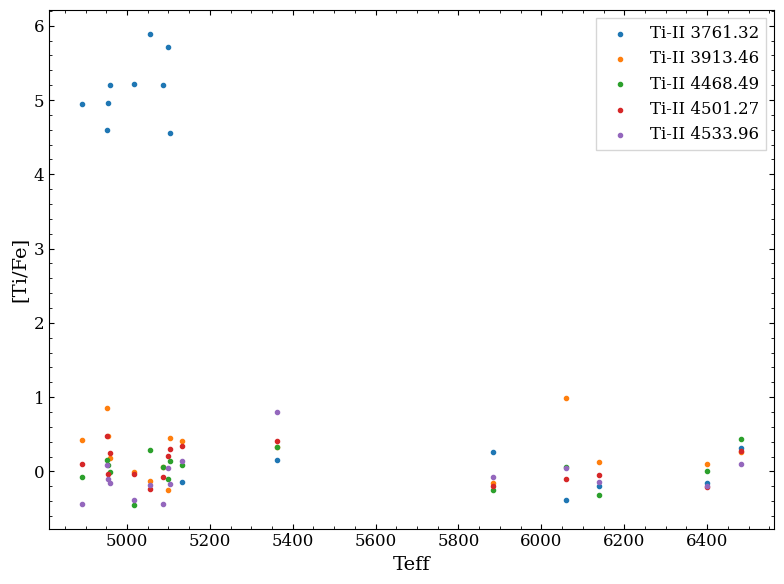

In [8]:
stars = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/stars/stellar_params.csv')
ti_abunds = abund_lines(path='/data/misfit/benlowe/xshooter/korg_data/stars/', stars=stars['star_id'].to_numpy(), element='Ti_II')
ti_abunds = pd.merge(stars[['star_id', 'Fe_it2', 'teff', 'logg']], ti_abunds, on='star_id', how='inner')

plt.figure(figsize=[8,6])
plt.scatter(ti_abunds['teff'], ti_abunds['Ti_3761.32'], label='Ti-II 3761.32', marker='.')
plt.scatter(ti_abunds['teff'], ti_abunds['Ti_3913.46'], label='Ti-II 3913.46', marker='.')
plt.scatter(ti_abunds['teff'], ti_abunds['Ti_4468.49'], label='Ti-II 4468.49', marker='.')
plt.scatter(ti_abunds['teff'], ti_abunds['Ti_4501.27'], label='Ti-II 4501.27', marker='.')
plt.scatter(ti_abunds['teff'], ti_abunds['Ti_4533.96'], label='Ti-II 4533.96', marker='.')

plt.xlabel('Teff')
plt.ylabel('[Ti/Fe]')
# plt.ylim(top=1.2)
plt.legend(fancybox=False)
plt.tight_layout()
plt.savefig("/data/misfit/benlowe/results/abund_teff_trends/ti_teff.png", dpi=300, transparent=False, facecolor="white")

### In Sc-II

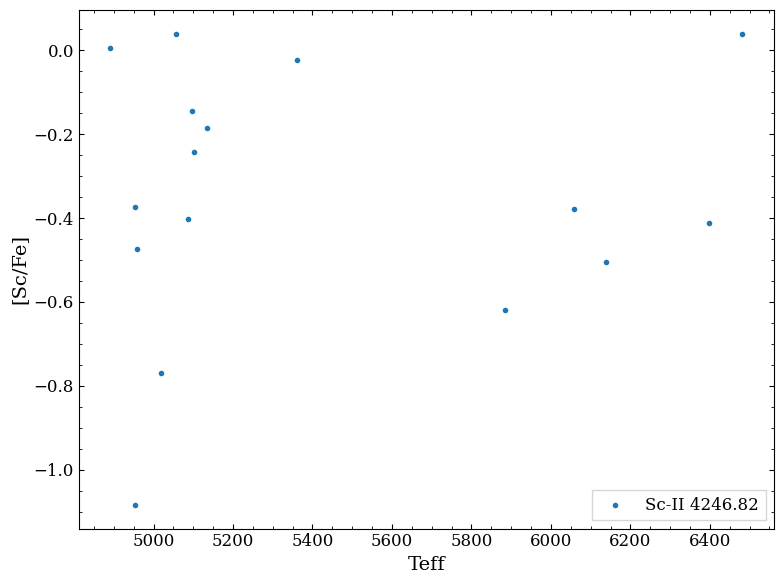

In [ ]:
stars = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/stars/stellar_params.csv')
sc_abunds = abund_lines(path='/data/misfit/benlowe/xshooter/korg_data/stars/', stars=stars['star_id'].to_numpy(), element='Sc_II')
sc_abunds = pd.merge(stars[['star_id', 'Fe_it2', 'teff', 'logg']], sc_abunds, on='star_id', how='inner')

plt.figure(figsize=[8,6])
plt.scatter(sc_abunds['teff'], sc_abunds['Sc_4246.82'], label='Sc-II 4246.82', marker='.')
plt.xlabel('Teff')
plt.ylabel('[Sc/Fe]')
# plt.ylim(top=1.2)
plt.legend(fancybox=False)
plt.tight_layout()
plt.savefig("/data/misfit/benlowe/results/abund_teff_trends/sc_teff.png", dpi=300, transparent=False, facecolor="white")

### In Co-I

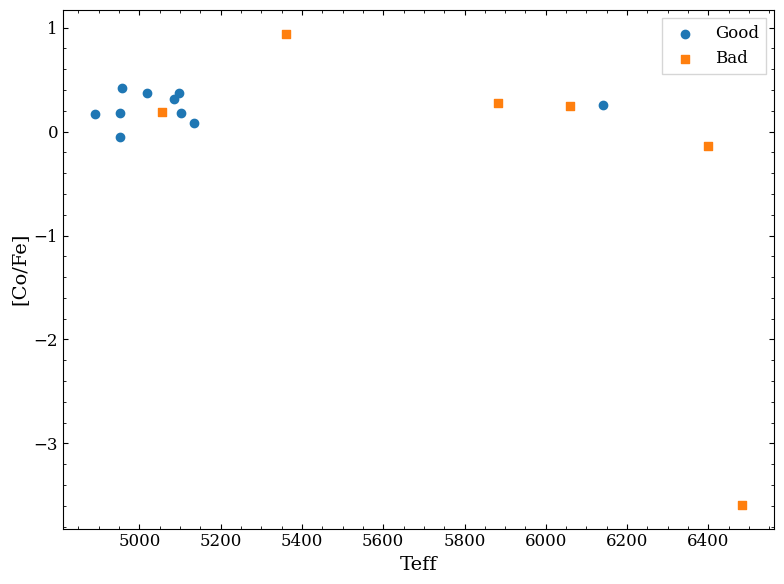

In [4]:
stars = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/stars/stellar_params.csv')
co_abunds = abund_lines(path='/data/misfit/benlowe/xshooter/korg_data/stars/', stars=stars['star_id'].to_numpy(), element='Co_I')
co_abunds = pd.merge(stars[['star_id', 'Fe_it2', 'teff', 'logg']], co_abunds, on='star_id', how='inner')


# Getting list of stars that have dumb Co-I line profiles
bad_co_stars = ['ra_0103-7050_s163', 'ra_0834-5220_s316', 'ra_1604-2712_s292', 'ra_1624-2150_s278',
                'ra_1633-2814_s284', 'ra_1659-2154_s114']

# Separating the bad from the good
bad_co = co_abunds[co_abunds['star_id'].isin(bad_co_stars)]
good_co = co_abunds[~co_abunds['star_id'].isin(bad_co_stars)]

# Plotting
plt.figure(figsize=[8,6])
plt.scatter(good_co['teff'], good_co['Co_4121.32'], label='Good')
plt.scatter(bad_co['teff'], bad_co['Co_4121.32'], label='Bad', marker='s')
plt.xlabel('Teff')
plt.ylabel('[Co/Fe]')
# plt.ylim(top=1.2)
plt.legend(fancybox=False)
plt.tight_layout()
plt.savefig("/data/misfit/benlowe/results/abund_teff_trends/co_teff.png", dpi=300, transparent=False, facecolor="white")

### In Ni-I

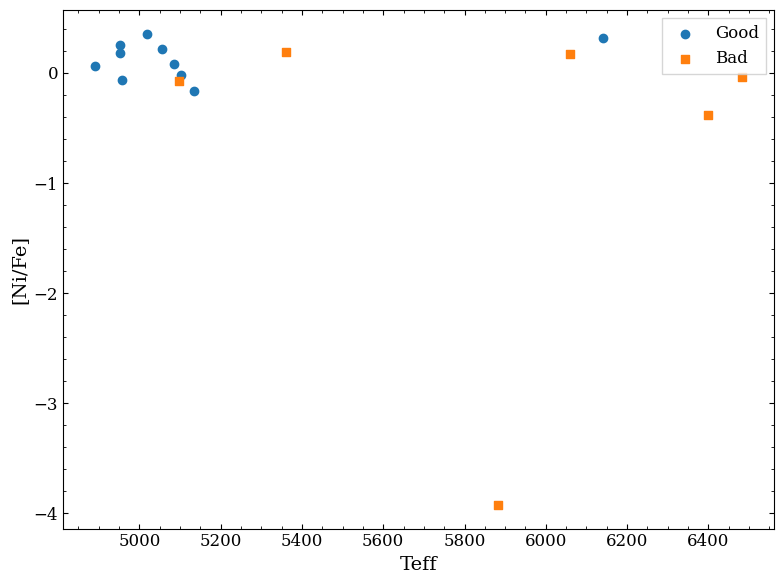

In [11]:
stars = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/stars/stellar_params.csv')
ni_abunds = abund_lines(path='/data/misfit/benlowe/xshooter/korg_data/stars/', stars=stars['star_id'].to_numpy(), element='Ni_I')
ni_abunds = pd.merge(stars[['star_id', 'Fe_it2', 'teff', 'logg']], ni_abunds, on='star_id', how='inner')


# Getting list of stars that have dumb Ni-I line profiles
bad_ni_stars = ['ra_0103-7050_s163', 'ra_0834-5220_s316', 'ra_1604-2712_s292', 'ra_1624-2150_s278',
                'ra_1633-2814_s284', 'ra_1633-2814_s130']

# Separating the bad from the good
bad_ni = ni_abunds[ni_abunds['star_id'].isin(bad_ni_stars)]
good_ni = ni_abunds[~ni_abunds['star_id'].isin(bad_ni_stars)]

# Plotting
plt.figure(figsize=[8,6])
plt.scatter(good_ni['teff'], good_ni['Ni_5476.9'], label='Good')
plt.scatter(bad_ni['teff'], bad_ni['Ni_5476.9'], label='Bad', marker='s')
plt.xlabel('Teff')
plt.ylabel('[Ni/Fe]')
# plt.ylim(top=1.2)
plt.legend(fancybox=False)
plt.tight_layout()
plt.savefig("/data/misfit/benlowe/results/abund_teff_trends/ni_teff.png", dpi=300, transparent=False, facecolor="white")

## Comparing abundances when turning off Korg's continuum adjustment feature

Loading in the data

In [12]:
# Used star ra_1752-4300_s269 for these tests. ALl done in TEST53
Mg_yes_contm = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/tests/TEST53/yes_contm/ra_1752-4300_s269/Mg_I_abund.csv')[['star_id', 'Mg_I_xfe_it1', 'Mg_I_xh_it1']]
Co_yes_contm = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/tests/TEST53/yes_contm/ra_1752-4300_s269/Co_I_abund.csv')[['Co_I_xfe_it1', 'Co_I_xh_it1']]
Mg_no_contm = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/tests/TEST53/no_contm/ra_1752-4300_s269/Mg_I_abund.csv')[['star_id', 'Mg_I_xfe_it1', 'Mg_I_xh_it1']]
Co_no_contm = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/tests/TEST53/no_contm/ra_1752-4300_s269/Co_I_abund.csv')[['Co_I_xfe_it1', 'Co_I_xh_it1']]

abunds_yes_contm = pd.concat([Mg_yes_contm, Co_yes_contm], axis=1)
abunds_no_contm = pd.concat([Mg_no_contm, Co_no_contm], axis=1)

abunds_yes_contm_df = pd.DataFrame(abunds_yes_contm)
abunds_no_contm_df = pd.DataFrame(abunds_no_contm)

mg_abund_diff = abunds_yes_contm_df['Mg_I_xfe_it1'] - abunds_no_contm_df['Mg_I_xfe_it1']
co_abund_diff = abunds_yes_contm_df['Co_I_xfe_it1'] - abunds_no_contm_df['Co_I_xfe_it1']
print('Mg:\nYes_contim = {0}\nNo_contim = {1}\nDiff = {2}'.format(abunds_yes_contm_df['Mg_I_xfe_it1'].to_numpy(), abunds_no_contm_df['Mg_I_xfe_it1'].to_numpy(), mg_abund_diff.to_numpy()))
print()
print('Co:\nYes_contim = {0}\nNo_contim = {1}\nDiff = {2}'.format(abunds_yes_contm_df['Co_I_xfe_it1'].to_numpy(), abunds_no_contm_df['Co_I_xfe_it1'].to_numpy(), co_abund_diff.to_numpy()))

Mg:
Yes_contim = [0.55056725]
No_contim = [0.86559914]
Diff = [-0.31503189]

Co:
Yes_contim = [0.36873725]
No_contim = [1.12236911]
Diff = [-0.75363185]


Comparing abundance differences

## Making plot of abundances

Making line vs chisquare plot to see what the best vmic value would be

In [2]:
def get_data(path, vmic, color):

    # Loading in test star
    data = pd.read_csv(path)
    line = data['line'].to_numpy()
    line = [i.split('_')[1] for i in line] # Doing this to remove 'Fe_' 
    abund = data['abund'].to_numpy()
    chisq = data['chi2'].to_numpy() * 1e7

    # Calculating standard deviation, then perform sigma clipping
    std = np.std(chisq)
    mean = np.mean(chisq)
    
    plt.scatter(line, chisq, label=vmic, color=color)
    plt.axhline(mean, linestyle='--', alpha=0.4, color=color)
    # plt.axhline(mean + 1*std, color='black')
    # plt.axhline(mean - 1*std, color='black')

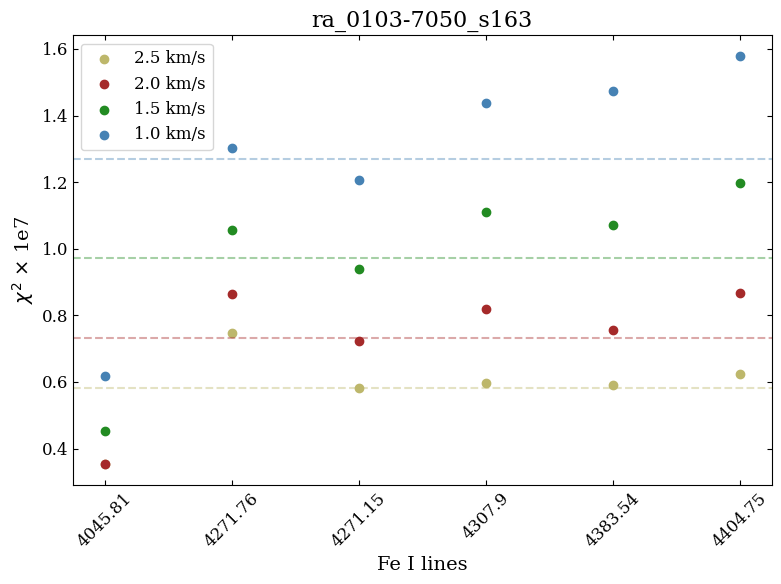

In [3]:
plt.figure(figsize=[8,6])

star = 'ra_0103-7050_s163'

test_25vmic = '/data/misfit/benlowe/xshooter/korg_data/tests/TEST23/' + star + '/Fe/Fe_results.csv'
get_data(test_25vmic, '2.5 km/s', 'darkkhaki')
test_20vmic = '/data/misfit/benlowe/xshooter/korg_data/tests/TEST20/' + star + '/Fe/Fe_results.csv'
get_data(test_20vmic, '2.0 km/s', 'brown')
test_15vmic = '/data/misfit/benlowe/xshooter/korg_data/tests/TEST18/' + star + '/Fe/Fe_results.csv'
get_data(test_15vmic, '1.5 km/s', 'forestgreen')
test_10vmic = '/data/misfit/benlowe/xshooter/korg_data/tests/TEST19/' + star + '/Fe/Fe_results.csv'
get_data(test_10vmic, '1.0 km/s', 'steelblue')
# test_05vmic = '/data/misfit/benlowe/xshooter/korg_data/tests/TEST21/' + star + '/Fe/Fe_results.csv'
# get_data(test_05vmic, '0.5 km/s', 'slateblue')
# test_00vmic = '/data/misfit/benlowe/xshooter/korg_data/tests/TEST22/' + star + '/Fe/Fe_results.csv'
# get_data(test_00vmic, '0.0 km/s', 'magenta')

plt.title(star)
plt.xticks(rotation=45)
plt.minorticks_off()
plt.xlabel('Fe I lines')
plt.ylabel(r'$\chi^2$ $\times$ 1e7')
plt.legend()
plt.tight_layout()

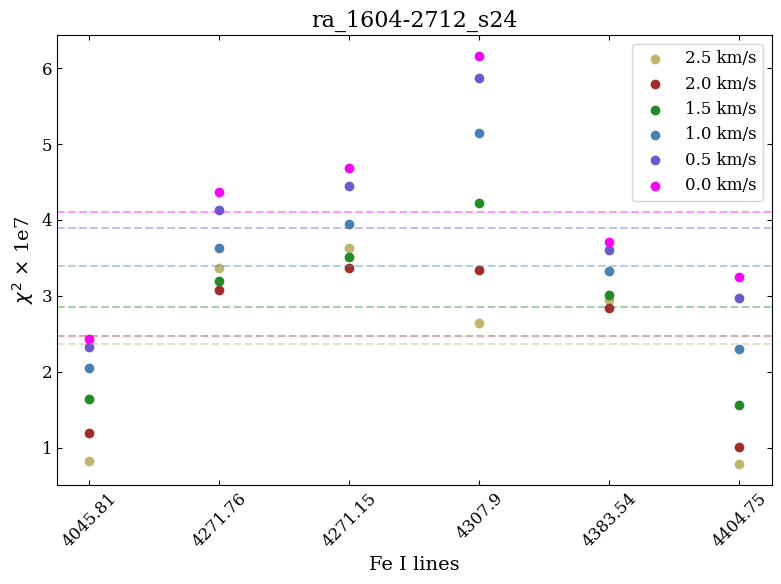

In [5]:
plt.figure(figsize=[8,6])

star = 'ra_1604-2712_s24'

test_25vmic = '/data/misfit/benlowe/xshooter/korg_data/tests/TEST23/' + star + '/Fe/Fe_results.csv'
get_data(test_25vmic, '2.5 km/s', 'darkkhaki')
test_20vmic = '/data/misfit/benlowe/xshooter/korg_data/tests/TEST20/' + star + '/Fe/Fe_results.csv'
get_data(test_20vmic, '2.0 km/s', 'brown')
test_15vmic = '/data/misfit/benlowe/xshooter/korg_data/tests/TEST18/' + star + '/Fe/Fe_results.csv'
get_data(test_15vmic, '1.5 km/s', 'forestgreen')
test_10vmic = '/data/misfit/benlowe/xshooter/korg_data/tests/TEST19/' + star + '/Fe/Fe_results.csv'
get_data(test_10vmic, '1.0 km/s', 'steelblue')
test_05vmic = '/data/misfit/benlowe/xshooter/korg_data/tests/TEST21/' + star + '/Fe/Fe_results.csv'
get_data(test_05vmic, '0.5 km/s', 'slateblue')
test_00vmic = '/data/misfit/benlowe/xshooter/korg_data/tests/TEST22/' + star + '/Fe/Fe_results.csv'
get_data(test_00vmic, '0.0 km/s', 'magenta')


plt.title(star)
plt.xticks(rotation=45)
plt.minorticks_off()
plt.xlabel('Fe I lines')
plt.ylabel(r'$\chi^2$ $\times$ 1e7')
plt.legend()
plt.tight_layout()

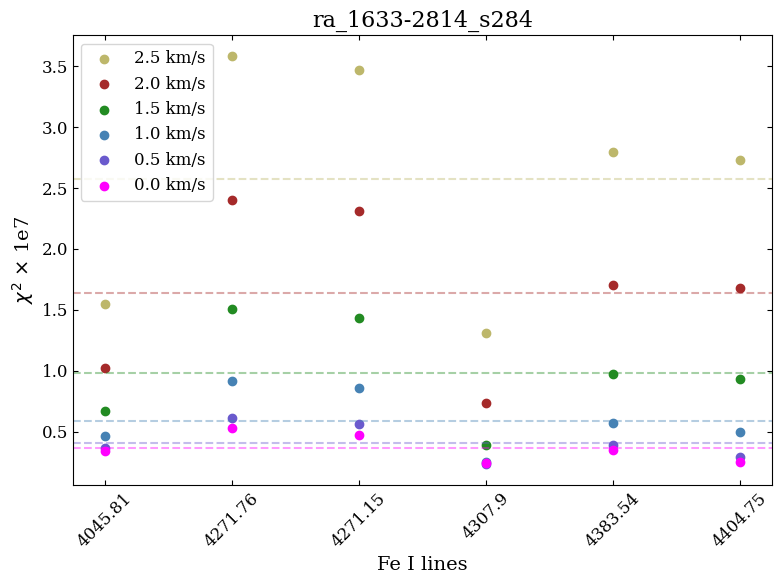

In [6]:
plt.figure(figsize=[8,6])

star = 'ra_1633-2814_s284'

test_25vmic = '/data/misfit/benlowe/xshooter/korg_data/tests/TEST23/' + star + '/Fe/Fe_results.csv'
get_data(test_25vmic, '2.5 km/s', 'darkkhaki')
test_20vmic = '/data/misfit/benlowe/xshooter/korg_data/tests/TEST20/' + star + '/Fe/Fe_results.csv'
get_data(test_20vmic, '2.0 km/s', 'brown')
test_15vmic = '/data/misfit/benlowe/xshooter/korg_data/tests/TEST18/' + star + '/Fe/Fe_results.csv'
get_data(test_15vmic, '1.5 km/s', 'forestgreen')
test_10vmic = '/data/misfit/benlowe/xshooter/korg_data/tests/TEST19/' + star + '/Fe/Fe_results.csv'
get_data(test_10vmic, '1.0 km/s', 'steelblue')
test_05vmic = '/data/misfit/benlowe/xshooter/korg_data/tests/TEST21/' + star + '/Fe/Fe_results.csv'
get_data(test_05vmic, '0.5 km/s', 'slateblue')
test_00vmic = '/data/misfit/benlowe/xshooter/korg_data/tests/TEST22/' + star + '/Fe/Fe_results.csv'
get_data(test_00vmic, '0.0 km/s', 'magenta')

plt.title(star)
plt.xticks(rotation=45)
plt.minorticks_off()
plt.xlabel('Fe I lines')
plt.ylabel(r'$\chi^2$ $\times$ 1e7')
plt.legend()
plt.tight_layout()

-2.9949754486902567 0.00963579927488898


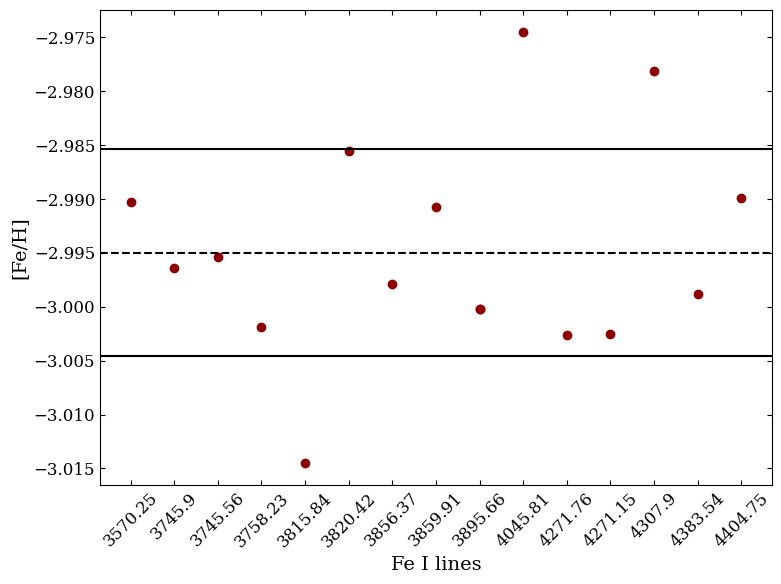

In [6]:
# Loading in test star
data = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/tests/TEST13/ra_1604-2712_s24/Fe/Fe_results.csv')
line = data['line'].to_numpy()
line = [i.split('_')[1] for i in line] # Doing this to remove 'Fe_' 
abund = data['abund'].to_numpy()

# Calculating standard deviation, then perform sigma clipping
std = np.std(abund)
mean = np.mean(abund)

plt.figure(figsize=[8,6])
plt.scatter(line,abund, color='darkred')
plt.axhline(mean, linestyle='--', color='black')
plt.axhline(mean + 1*std, color='black')
plt.axhline(mean - 1*std, color='black')
plt.xticks(rotation=45)
plt.minorticks_off()
plt.xlabel('Fe I lines')
plt.ylabel('[Fe/H]')
plt.tight_layout()

print(mean, std)

## Checking if the two Ba-II riched stars have Eu-II lines visible in their spectra or not

/tmp/ipykernel_3505323/1346339769.py:24: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.05)
/tmp/ipykernel_3505323/1346339769.py:40: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.05)


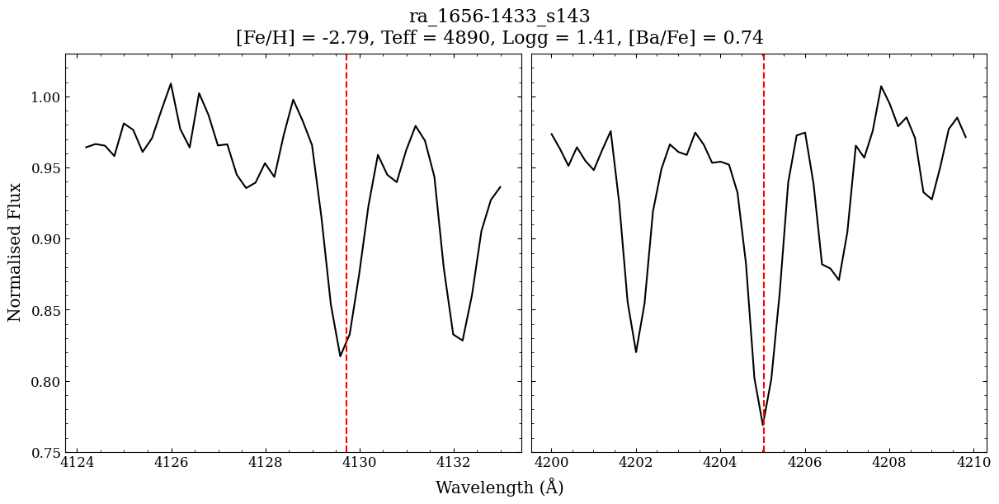

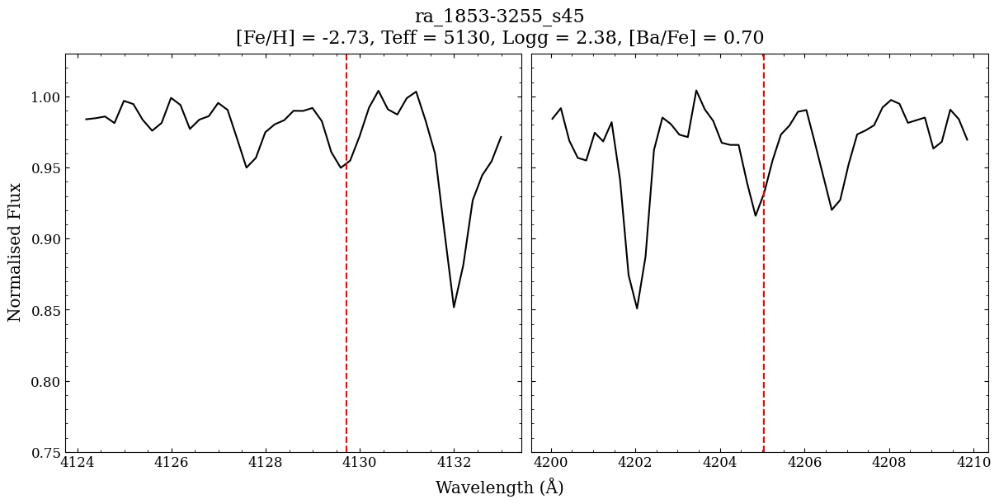

In [52]:
# Loading in the two stars that are Ba-II enriched

# Star ra_1656-1433_s143
# [Fe/H] = -2.791973
# Teff = 4891.462397
# Logg = 1.406800	
# [Ba/Fe] = 0.742932
ra_1656_s143 = (Table.read('/data/misfit/benlowe/xshooter/reduced_data/comb_spec/ra_1656-1433_s143/ra_1656-1433_s143_data.fits', hdu=1)).to_pandas()
ra_1656_s143_eu4129 = (ra_1656_s143[(ra_1656_s143['wave'] > 4124.0) & (ra_1656_s143['wave'] < 4133.0)])
ra_1656_s143_eu4205 = (ra_1656_s143[(ra_1656_s143['wave'] > 4200.0) & (ra_1656_s143['wave'] < 4210.0)])

# Star ra_1853-3255_s45
# [Fe/H] = -2.733448
# Teff = 5133.857005
# Logg = 2.378863
# [Ba/Fe] = 0.697847
ra_1853_s45 = (Table.read('/data/misfit/benlowe/xshooter/reduced_data/comb_spec/ra_1853-3255_s45/ra_1853-3255_s45_data.fits', hdu=1)).to_pandas()
ra_1853_s45_eu4129 = (ra_1853_s45[(ra_1853_s45['wave'] > 4124.0) & (ra_1853_s45['wave'] < 4133.0)])
ra_1853_s45_eu4205 = (ra_1853_s45[(ra_1853_s45['wave'] > 4200.0) & (ra_1853_s45['wave'] < 4210.0)])


# Checking ra_1656-1433_s143
fig, axs = plt.subplots(1, 2, figsize=[12,6], sharey=True, constrained_layout=True)
plt.subplots_adjust(wspace=0.05)
fig.supxlabel('Wavelength (Å)')
fig.supylabel('Normalised Flux')
fig.suptitle('ra_1656-1433_s143\n[Fe/H] = -2.79, Teff = 4890, Logg = 1.41, [Ba/Fe] = 0.74')

axs[0].plot(ra_1656_s143_eu4129['wave'], ra_1656_s143_eu4129['flux'], color='black')
axs[0].axvline(x=4129.72, color='red', linestyle='--')
axs[0].set_ylim(top=1.03, bottom=0.75)

axs[1].plot(ra_1656_s143_eu4205['wave'], ra_1656_s143_eu4205['flux'], color='black')
axs[1].axvline(x=4205.04, color='red', linestyle='--')
axs[1].set_ylim(top=1.03, bottom=0.75)
plt.savefig("/data/misfit/benlowe/results/baII_rich_stars/ra_1656-1433_s143_EuII_lines.png", dpi=300, transparent=False, facecolor="white")


# Checking ra_1853-3255_s45
fig, axs = plt.subplots(1, 2, figsize=[12,6], sharey=True, constrained_layout=True)
plt.subplots_adjust(wspace=0.05)
fig.supxlabel('Wavelength (Å)')
fig.supylabel('Normalised Flux')
fig.suptitle('ra_1853-3255_s45\n[Fe/H] = -2.73, Teff = 5130, Logg = 2.38, [Ba/Fe] = 0.70')

axs[0].plot(ra_1853_s45_eu4129['wave'], ra_1853_s45_eu4129['flux'], color='black')
axs[0].axvline(x=4129.72, color='red', linestyle='--')
axs[0].set_ylim(top=1.03, bottom=0.75)

axs[1].plot(ra_1853_s45_eu4205['wave'], ra_1853_s45_eu4205['flux'], color='black')
axs[1].axvline(x=4205.04, color='red', linestyle='--')
axs[1].set_ylim(top=1.03, bottom=0.75)
plt.savefig("/data/misfit/benlowe/results/baII_rich_stars/ra_1853-3255_s45_EuII_lines.png", dpi=300, transparent=False, facecolor="white")

## Calculating microturbulence

In [9]:
def vmic_galdr4(teff, logg):
    return 1.198 + 3.16e-4 * (teff-5500) - 0.253 * (logg - 4) - 2.86e-4 * (teff - 5500) * (logg - 4) + 0.165 * (logg - 4)**2

def vmic_galdr3(teff):
    return 1.1 + 1.0e-4 * (teff - 5500) + 4e-7 * (teff - 5500)**2


vmic_galdr3(teff=5959.30456670644)


1.2303147306696003

## Making [Fe/H] vs log(W/$\lambda$) plot

Getting the data

In [14]:
def get_ew(star, vmic):
    
    # Pathways to data
    star_abunds = star + '/Fe/Fe_results.csv'
    vmic_path = '/data/misfit/benlowe/xshooter/korg_data/tests/vmics/vmic_' + vmic + '/'
    ew_plot_save = vmic_path + star + '/ew_fits/'
    os.makedirs(ew_plot_save, exist_ok=True)
    
    # Getting data for this star at this vmic
    fit_df = pd.read_csv(vmic_path + star_abunds)

    # Calculating EWs
    voigt_winds = [1, 1.1, 1, 0.8, 1, 1.1, 1.1, 1.1, 1, 1, 1.5, 1.5, 1.5, 1.5, 1.5, 1.5]
    for i, line in fit_df.iterrows():
        # Getting data
        obs_wave = np.array(ast.literal_eval(line['obs_wave'])[0])
        obs_flux = np.array(ast.literal_eval(line['obs_flux'])[0])
        line_cent = obs_wave[np.argmin(obs_flux)]
        wind_size = voigt_winds[i]
        
        fit_wave = np.array(ast.literal_eval(line['fit_wave'])[0])
        fit_flux = np.array(ast.literal_eval(line['fit_flux'])[0])

        # Masking to do Voigt fit
        mask = np.where((obs_wave > line_cent - wind_size) & (obs_wave < line_cent + wind_size))
        mask_wave = obs_wave[mask]
        mask_flux = obs_flux[mask]
        
        # Fitting Voigt function
        y_offset = 1
        mod = VoigtModel()
        pars = mod.guess(y_offset - mask_flux, x=mask_wave)
        fit = mod.fit(y_offset - mask_flux, pars, x=mask_wave)

        # Calculating EWs    
        ew = np.trapz(fit.best_fit, mask_wave) * 1000 # Converting to mA
        fit_df.loc[i, 'ew'] = ew
        fit_df.loc[i, 'log(ew/lambda)'] = np.log10(ew/(line_cent * 1000)) # Converting to mA
            
        plt.figure()
        plt.plot(obs_wave, obs_flux, label='Observed')
        plt.plot(fit_wave, fit_flux, label='Korg Fit')
        plt.plot(mask_wave, y_offset - fit.best_fit, '--', label='Voigt Fit')
        plt.xlim(fit_wave[0], fit_wave[-1])
        plt.legend()
        plt.savefig(ew_plot_save + line['line'] + '_ew_fit.png', dpi=300, transparent=False, facecolor='white')
        plt.close()
        
    return fit_df

Calculating EWs for all lines, then saving to the abundnace dataframe

In [4]:
def poly(x, y):
    coefficients = np.polyfit(x, y, 1)
    slope, intercept = coefficients
    p = np.poly1d(coefficients)
    
    xplot = np.linspace(min(x), max(x), 100)
    yplot = p(xplot)
    
    return xplot, yplot, slope

vmic20_df = get_ew(star='ra_0103-7050_s163', vmic='20')
vmic20_xpoly, vmic20_ypoly, vmic20_slope = poly(vmic20_df['log(ew/lambda)'], vmic20_df['abund'])

vmic15_df = get_ew(star='ra_0103-7050_s163', vmic='15')
vmic15_xpoly, vmic15_ypoly, vmic15_slope = poly(vmic15_df['log(ew/lambda)'], vmic15_df['abund'])

vmic10_df = get_ew(star='ra_0103-7050_s163', vmic='10')
vmic10_xpoly, vmic10_ypoly, vmic10_slope = poly(vmic10_df['log(ew/lambda)'], vmic10_df['abund'])

vmic05_df = get_ew(star='ra_0103-7050_s163', vmic='05')
vmic05_xpoly, vmic05_ypoly, vmic05_slope = poly(vmic05_df['log(ew/lambda)'], vmic05_df['abund'])

Making EW vs [Fe/H] plot

Text(0, 0.5, '[Fe/H]')

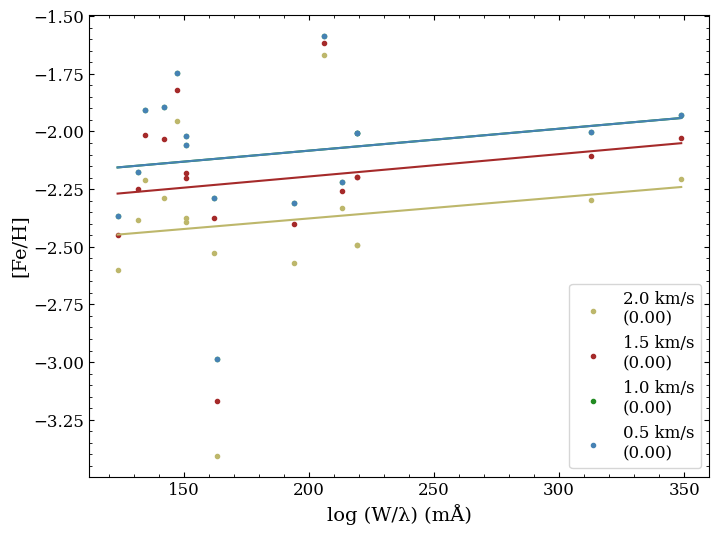

In [8]:
# Calculating EWs and 1deg polynomial fits
vmic20_df = get_ew(star='ra_0103-7050_s163', vmic='20')
vmic20_xpoly, vmic20_ypoly, vmic20_slope = poly(vmic20_df['ew'], vmic20_df['abund'])

vmic15_df = get_ew(star='ra_0103-7050_s163', vmic='15')
vmic15_xpoly, vmic15_ypoly, vmic15_slope = poly(vmic15_df['ew'], vmic15_df['abund'])

vmic10_df = get_ew(star='ra_0103-7050_s163', vmic='10')
vmic10_xpoly, vmic10_ypoly, vmic10_slope = poly(vmic10_df['ew'], vmic10_df['abund'])

vmic05_df = get_ew(star='ra_0103-7050_s163', vmic='05')
vmic05_xpoly, vmic05_ypoly, vmic05_slope = poly(vmic05_df['ew'], vmic05_df['abund'])


# Plotting
plt.figure(figsize=[8,6])
plt.scatter(vmic20_df['ew'], vmic20_df['abund'], label='2.0 km/s\n(%.2f)' % vmic20_slope, marker='.', color='darkkhaki')
plt.plot(vmic20_xpoly, vmic20_ypoly, color='darkkhaki', linewidth=1.5)

plt.scatter(vmic15_df['ew'], vmic15_df['abund'], label='1.5 km/s\n(%.2f)' % vmic15_slope, marker='.', color='brown')
plt.plot(vmic15_xpoly, vmic15_ypoly, color='brown', linewidth=1.5)

plt.scatter(vmic10_df['ew'], vmic10_df['abund'], label='1.0 km/s\n(%.2f)' % vmic10_slope, marker='.', color='forestgreen')
plt.plot(vmic10_xpoly, vmic10_ypoly, color='forestgreen', linewidth=1.5)

plt.scatter(vmic05_df['ew'], vmic05_df['abund'], label='0.5 km/s\n(%.2f)' % vmic05_slope, marker='.', color='steelblue')
plt.plot(vmic05_xpoly, vmic05_ypoly, color='steelblue', linewidth=1.5)

plt.legend()
plt.xlabel(r'W (mÅ)')
plt.ylabel('[Fe/H]')

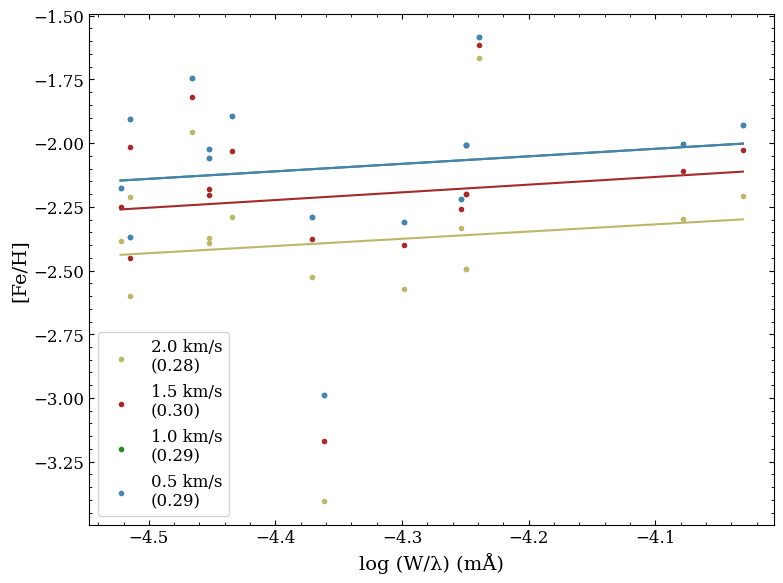

In [15]:
# Calculating EWs and 1deg polynomial fits
vmic20_df = get_ew(star='ra_0103-7050_s163', vmic='20')
vmic20_xpoly, vmic20_ypoly, vmic20_slope = poly(vmic20_df['log(ew/lambda)'], vmic20_df['abund'])

vmic15_df = get_ew(star='ra_0103-7050_s163', vmic='15')
vmic15_xpoly, vmic15_ypoly, vmic15_slope = poly(vmic15_df['log(ew/lambda)'], vmic15_df['abund'])

vmic10_df = get_ew(star='ra_0103-7050_s163', vmic='10')
vmic10_xpoly, vmic10_ypoly, vmic10_slope = poly(vmic10_df['log(ew/lambda)'], vmic10_df['abund'])

vmic05_df = get_ew(star='ra_0103-7050_s163', vmic='05')
vmic05_xpoly, vmic05_ypoly, vmic05_slope = poly(vmic05_df['log(ew/lambda)'], vmic05_df['abund'])


# Plotting
plt.figure(figsize=[8,6])
plt.scatter(vmic20_df['log(ew/lambda)'], vmic20_df['abund'], label='2.0 km/s\n(%.2f)' % vmic20_slope, marker='.', color='darkkhaki')
plt.plot(vmic20_xpoly, vmic20_ypoly, color='darkkhaki', linewidth=1.5)

plt.scatter(vmic15_df['log(ew/lambda)'], vmic15_df['abund'], label='1.5 km/s\n(%.2f)' % vmic15_slope, marker='.', color='brown')
plt.plot(vmic15_xpoly, vmic15_ypoly, color='brown', linewidth=1.5)

plt.scatter(vmic10_df['log(ew/lambda)'], vmic10_df['abund'], label='1.0 km/s\n(%.2f)' % vmic10_slope, marker='.', color='forestgreen')
plt.plot(vmic10_xpoly, vmic10_ypoly, color='forestgreen', linewidth=1.5)

plt.scatter(vmic05_df['log(ew/lambda)'], vmic05_df['abund'], label='0.5 km/s\n(%.2f)' % vmic05_slope, marker='.', color='steelblue')
plt.plot(vmic05_xpoly, vmic05_ypoly, color='steelblue', linewidth=1.5)

plt.legend(fancybox=True)
plt.xlabel(r'log (W/λ) (mÅ)')
plt.ylabel('[Fe/H]')
plt.tight_layout()
# plt.scatter(fit_df['ew'] * 100, fit_df['abund'])

plt.savefig("/data/misfit/benlowe/results/tests/logW_feh.png", dpi=300, transparent=False, facecolor="white")

Text(0, 0.5, '$\\chi^2$')

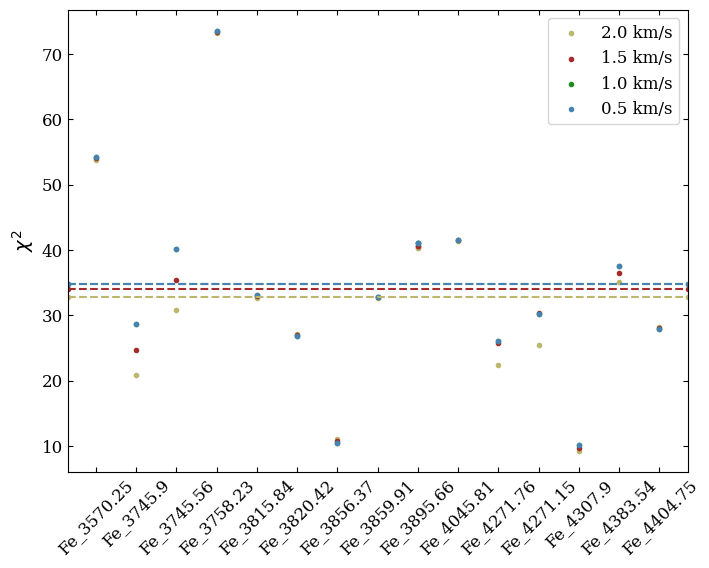

In [149]:
plt.figure(figsize=[8,6])
plt.scatter(vmic20_df['line'], vmic20_df['chi2'], label='2.0 km/s', color='darkkhaki', marker='.')
plt.axhline(np.mean(vmic20_df['chi2']), linestyle='--', color='darkkhaki', marker='.')

plt.scatter(vmic20_df['line'], vmic15_df['chi2'], label='1.5 km/s', color='brown', marker='.')
plt.axhline(np.mean(vmic15_df['chi2']), linestyle='--', color='brown', marker='.')

plt.scatter(vmic20_df['line'], vmic10_df['chi2'], label='1.0 km/s', color='forestgreen', marker='.')
plt.axhline(np.mean(vmic10_df['chi2']), linestyle='--', color='forestgreen', marker='.')

plt.scatter(vmic20_df['line'], vmic05_df['chi2'], label='0.5 km/s', color='steelblue', marker='.')
plt.axhline(np.mean(vmic05_df['chi2']), linestyle='--', color='steelblue', marker='.')

plt.xticks(rotation=45)
plt.legend()
plt.minorticks_off()
# plt.xlabel('Fe I lines')
plt.ylabel(r'$\chi^2$')

## Checking Teff correct by making E_low vs [Fe/H] plot

In [25]:
# Loading in the data
teff0_data = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/tests/vmics/vmic_galahdr4/ra_0103-7050_s163/Fe/Fe_results.csv')
teffp100_data = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/tests/teffs/p100/ra_0103-7050_s163/Fe/Fe_results.csv')
teffm100_data = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/tests/teffs/m100/ra_0103-7050_s163/Fe/Fe_results.csv')

# Excitation potential energies for the Fe I lines
elow = [2.81,
0.09,
0.12,
0.96,
1.49,
0.86,
0.05,
0,
0.11,
0.11,
1.49,
2.45,
1.49,
1.56,
1.49,
1.56
]

# Calculating slopes 
teff0_xpoly, teff0_ypoly, teff0_slope = poly(elow, teff0_data['abund'])
teffp100_xpoly, teffp100_ypoly, teffp100_slope = poly(elow, teffp100_data['abund'])
teffm100_xpoly, teffm100_ypoly, teffm100_slope = poly(elow, teffm100_data['abund'])


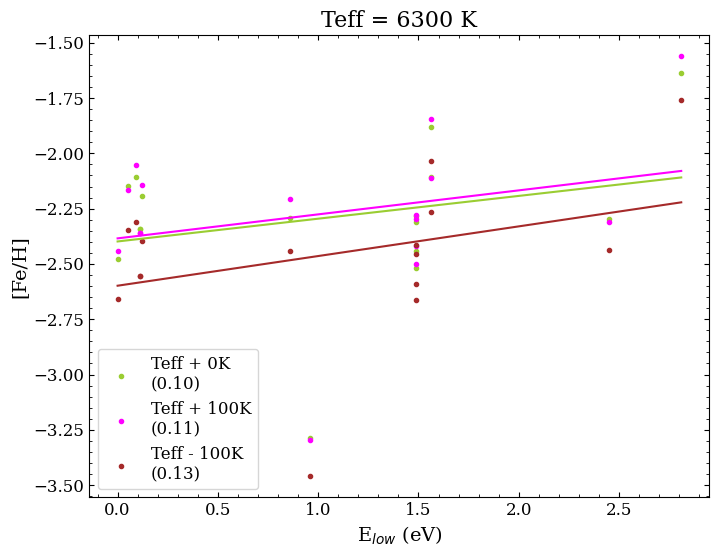

In [28]:
# Making the plot
plt.figure(figsize=[8,6])
plt.scatter(elow, teff0_data['abund'], marker='.', color='yellowgreen', label="Teff + 0K\n(%.2f)" % teff0_slope)
plt.plot(teff0_xpoly, teff0_ypoly, color='yellowgreen', linewidth=1.5)

plt.scatter(elow, teffp100_data['abund'], marker='.', color='magenta', label="Teff + 100K\n(%.2f)" % teffp100_slope)
plt.plot(teffp100_xpoly, teffp100_ypoly, color='magenta', linewidth=1.5)

plt.scatter(elow, teffm100_data['abund'], marker='.', color='brown', label="Teff - 100K\n(%.2f)" % teffm100_slope)
plt.plot(teffm100_xpoly, teffm100_ypoly, color='brown', linewidth=1.5)

plt.xlabel(r'E$_{low}$ (eV)')
plt.ylabel(r'[Fe/H]')
plt.title('Teff = 6300 K')
plt.legend()

plt.savefig("/data/misfit/benlowe/results/tests/elow_feh.png", dpi=300, transparent=False, facecolor="white")

## Checking if logg is correct by comparing abundances of Fe I and Fe II